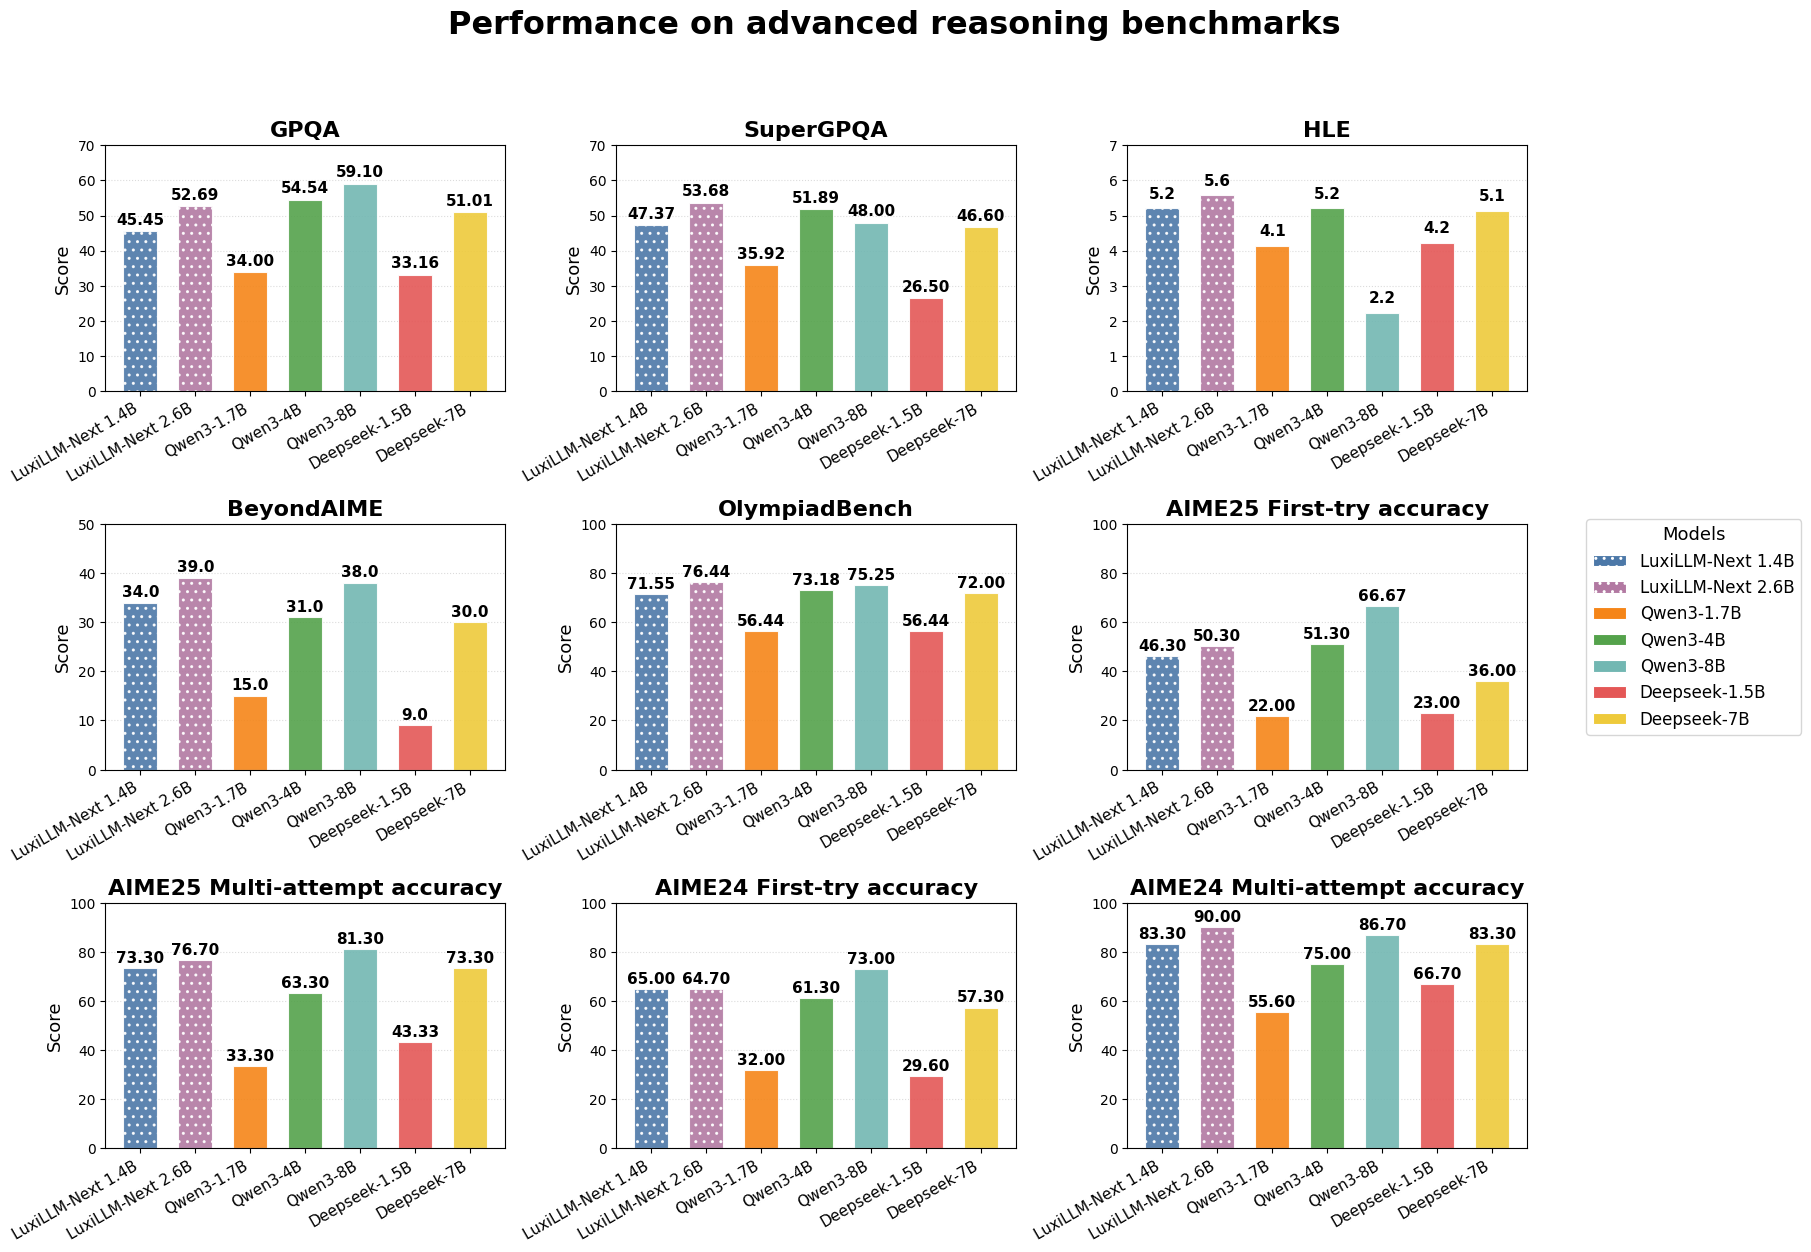

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import math

# =========================
# 1) 数据与模型
# =========================
data = {
    'AIME24_pass1': [65.0, 64.7, 32.0, 61.3, 73.0, 29.6, 57.3],
    'AIME24_pass10': [83.3, 90.0, 55.6, 75.0, 86.7, 66.7, 83.3],
    'AIME25_pass1': [46.3, 50.3, 22.0, 51.3, 66.67, 23.0, 36.0],
    'AIME25_pass10': [73.3, 76.7, 33.3, 63.3, 81.3, 43.33, 73.3],
    'Olympiadbench': [71.55, 76.44, 56.44, 73.18, 75.25, 56.44, 72.0],
    'BeyondAIME': [34.0, 39.0, 15.0, 31.0, 38.0, 9.0, 30.0],
    'HLE': [5.21, 5.58, 4.13, 5.21, 2.22, 4.22, 5.14],
    'SuperGPQA': [47.37, 53.68, 35.92, 51.89, 48.0, 26.5, 46.6],
    'GPQA': [45.45, 52.69, 34.0, 54.54, 59.1, 33.16, 51.01]
}

models = ['LuxiLLM-Next-1.4B', 'LuxiLLM-Next-2.6B', 'Qwen3-1.7B', 'Qwen3-4B',
          'Qwen3-8B', 'Deepseek-1.5B', 'Deepseek-7B']

# 简洁粗体提示 LuxiLLM-Next（避免 LaTeX）
model_labels = ['LuxiLLM-Next 1.4B', 'LuxiLLM-Next 2.6B', 'Qwen3-1.7B', 'Qwen3-4B',
                'Qwen3-8B', 'Deepseek-1.5B', 'Deepseek-7B']

# =========================
# 2) 全新配色（与原完全不同）
# =========================
colors = ['#4C78A8', '#B279A2', '#F58518', '#54A24B', '#72B7B2', '#E45756', '#EECA3B']

# 1) 去掉 LEGEND 面板
ordered_panels = [
    ('GPQA', 'GPQA', (0, 70)),
    ('SuperGPQA', 'SuperGPQA', (0, 70)),
    ('HLE', 'HLE', (0, 7)),
    ('BeyondAIME', 'BeyondAIME', (0, 50)),
    ('Olympiadbench', 'OlympiadBench', (0, 100)),
    ('AIME25_pass1', 'AIME25 First-try accuracy', (0, 100)),
    ('AIME25_pass10', 'AIME25 Multi-attempt accuracy', (0, 100)),
    ('AIME24_pass1', 'AIME24 First-try accuracy', (0, 100)),
    ('AIME24_pass10', 'AIME24 Multi-attempt accuracy', (0, 100)),
]

# 2) 网格行列数按 3 列自适应
cols = 3
rows = math.ceil(len(ordered_panels) / cols)
fig = plt.figure(figsize=(cols * 6, rows * 4.2))
x = np.arange(len(models))

# ……(draw_single_series 保持不变)

# 3) 正常画 9 个面板
for idx, (key, title, ylim) in enumerate(ordered_panels, start=1):
    ax = plt.subplot(rows, cols, idx)
    draw_single_series(ax, key, title, ylim)

# 4) 全局图例（放到右侧，不占底部）
legend_items = []
for i, name in enumerate(model_labels):
    hatch = '..' if i < 2 else None
    legend_items.append(Patch(facecolor=colors[i], edgecolor='white',
                              linewidth=0.8, hatch=hatch, label=name))

# 右侧留白给图例
fig.subplots_adjust(right=0.86)
fig.legend(handles=legend_items, title='Models', title_fontsize=13, fontsize=12,
           loc='center left', bbox_to_anchor=(0.88, 0.5), frameon=True, fancybox=True)

# 5) 主标题（在 tight_layout 之前）
fig.suptitle("Performance on advanced reasoning benchmarks", fontsize=23, fontweight='bold', y=0.99)

plt.tight_layout(rect=[0, 0, 0.86, 0.95])  # 给右侧图例和上方标题留空间
plt.show()

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# =========================
# 1) 数据与模型
# =========================
data = {
    'AIME24_pass1': [65.0, 64.7, 32.0, 61.3, 73.0, 29.6, 57.3],
    'AIME24_pass10': [83.3, 90.0, 55.6, 75.0, 86.7, 66.7, 83.3],
    'AIME25_pass1': [46.3, 50.3, 22.0, 51.3, 66.67, 23.0, 36.0],
    'AIME25_pass10': [73.3, 76.7, 33.3, 63.3, 81.3, 43.33, 73.3],
    'Olympiadbench': [71.55, 76.44, 56.44, 73.18, 75.25, 56.44, 72.0],
    'BeyondAIME': [34.0, 39.0, 15.0, 31.0, 38.0, 9.0, 30.0],
    'HLE': [5.21, 5.58, 4.13, 5.21, 2.22, 4.22, 5.14],
    'SuperGPQA': [47.37, 53.68, 35.92, 51.89, 48.0, 26.5, 46.6],
    'GPQA': [45.45, 52.69, 34.0, 54.54, 59.1, 33.16, 51.01]
}

models = ['LuxiLLM-Next-1.4B', 'LuxiLLM-Next-2.6B', 'Qwen3-1.7B', 'Qwen3-4B',
          'Qwen3-8B', 'Deepseek-1.5B', 'Deepseek-7B']
model_labels = ['LuxiLLM-Next 1.4B', 'LuxiLLM-Next 2.6B', 'Qwen3-1.7B', 'Qwen3-4B',
                'Qwen3-8B', 'Deepseek-1.5B', 'Deepseek-7B']

# =========================
# 2) 配色（与原完全不同）
# =========================
colors = ['#4C78A8', '#B279A2', '#F58518', '#54A24B', '#72B7B2', '#E45756', '#EECA3B']

# =========================
# 3) 输出顺序与 Y 轴范围
# =========================
panels = [
    ('GPQA', 'GPQA', (0, 70)),
    ('SuperGPQA', 'SuperGPQA', (0, 70)),
    ('HLE', 'HLE', (0, 7)),
    ('BeyondAIME', 'BeyondAIME', (0, 50)),
    ('Olympiadbench', 'OlympiadBench', (0, 100)),
    ('AIME25_pass1', 'AIME25 First-try accuracy', (0, 100)),
    ('AIME25_pass10', 'AIME25 Multi-attempt accuracy', (0, 100)),
    ('AIME24_pass1', 'AIME24 First-try accuracy', (0, 100)),
    ('AIME24_pass10', 'AIME24 Multi-attempt accuracy', (0, 100)),
]

# =========================
# 4) 画单张图的函数
# =========================
def draw_single_series(series_key, title, ylim,
                       bar_width=0.62, label_fs=11, title_fs=16, tick_fs=11, ylab_fs=13):
    x = np.arange(len(models))
    fig, ax = plt.subplots(figsize=(8.5, 6))  # 独立图片尺寸

    for i in range(len(models)):
        hatch = '..' if i < 2 else None  # 仅 LuxiLLM-Next 点阵 hatch
        ax.bar(x[i], data[series_key][i],
               width=bar_width,
               color=colors[i],
               alpha=0.9,
               edgecolor='white',
               linewidth=0.8,
               hatch=hatch)

    # 标注：根据量级动态上移
    ymax = ylim[1]
    bump = 1.0 if ymax >= 70 else (0.2 if ymax <= 7 else 0.6)
    for i, v in enumerate(data[series_key]):
        if series_key in ('GPQA', 'SuperGPQA') or series_key == 'Olympiadbench':
            txt = f'{v:.2f}'
        elif series_key == 'HLE':
            txt = f'{v:.2f}'
        else:
            txt = f'{v:.1f}'
        ax.text(i, v + bump, txt, ha='center', va='bottom', fontsize=label_fs, fontweight='bold')

    ax.set_title(title, fontsize=title_fs, fontweight='bold')
    ax.set_ylabel('Score', fontsize=ylab_fs)
    ax.set_xticks(x)
    ax.set_xticklabels(model_labels, rotation=28, ha='right', fontsize=tick_fs)
    ax.set_ylim(ylim)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)

    # 单图自己的模型图例（可选：为了更“像不同图”，这里保留每张各自的图例）
    legend_items = []
    for i, name in enumerate(model_labels):
        hatch = '..' if i < 2 else None
        legend_items.append(Patch(facecolor=colors[i], edgecolor='white', linewidth=0.8,
                                  hatch=hatch, label=name))
    leg = ax.legend(handles=legend_items, loc='lower left', fontsize=10,
                    title='Models', title_fontsize=11, frameon=True, fancybox=True)
    leg._legend_box.align = "left"

    plt.tight_layout()

    # 保存
    safe_key = series_key.replace('•', '_').replace(' ', '_')
    png_name = f'fig_{safe_key}.png'
    pdf_name = f'fig_{safe_key}.pdf'
    plt.savefig(png_name, dpi=300, bbox_inches='tight')
    plt.savefig(pdf_name, bbox_inches='tight')
    print(f'Saved: {png_name} / {pdf_name}')
    plt.close(fig)

# =========================
# 5) 批量生成每个子图的独立图片
# =========================
os.makedirs('figs_split', exist_ok=True)
cwd = os.getcwd()
print(f'Output directory: {cwd}/figs_split')

# 切换到输出目录（生成的文件更干净）
os.chdir('figs_split')

for key, title, ylim in panels:
    draw_single_series(key, title, ylim)

# 可选：再输出一张“仅图例”的独立图片（用于报告拼接）
fig, ax = plt.subplots(figsize=(6, 5))
ax.axis('off')
legend_items = [Patch(facecolor=colors[i], edgecolor='white', linewidth=0.8,
                      hatch=('..' if i < 2 else None), label=model_labels[i])
                for i in range(len(models))]
ax.legend(handles=legend_items, loc='center', fontsize=12, title='Models',
          title_fontsize=13, frameon=True, fancybox=True, ncol=1)
plt.tight_layout()
plt.savefig('fig_LEGEND.png', dpi=300, bbox_inches='tight')
plt.savefig('fig_LEGEND.pdf', bbox_inches='tight')
print('Saved: fig_LEGEND.png / fig_LEGEND.pdf')
plt.close()

Output directory: /Users/apple/PycharmProjects/pythonProject1/figs_split
Saved: fig_GPQA.png / fig_GPQA.pdf
Saved: fig_SuperGPQA.png / fig_SuperGPQA.pdf
Saved: fig_HLE.png / fig_HLE.pdf
Saved: fig_BeyondAIME.png / fig_BeyondAIME.pdf
Saved: fig_Olympiadbench.png / fig_Olympiadbench.pdf
Saved: fig_AIME25_pass1.png / fig_AIME25_pass1.pdf
Saved: fig_AIME25_pass10.png / fig_AIME25_pass10.pdf
Saved: fig_AIME24_pass1.png / fig_AIME24_pass1.pdf
Saved: fig_AIME24_pass10.png / fig_AIME24_pass10.pdf
Saved: fig_LEGEND.png / fig_LEGEND.pdf


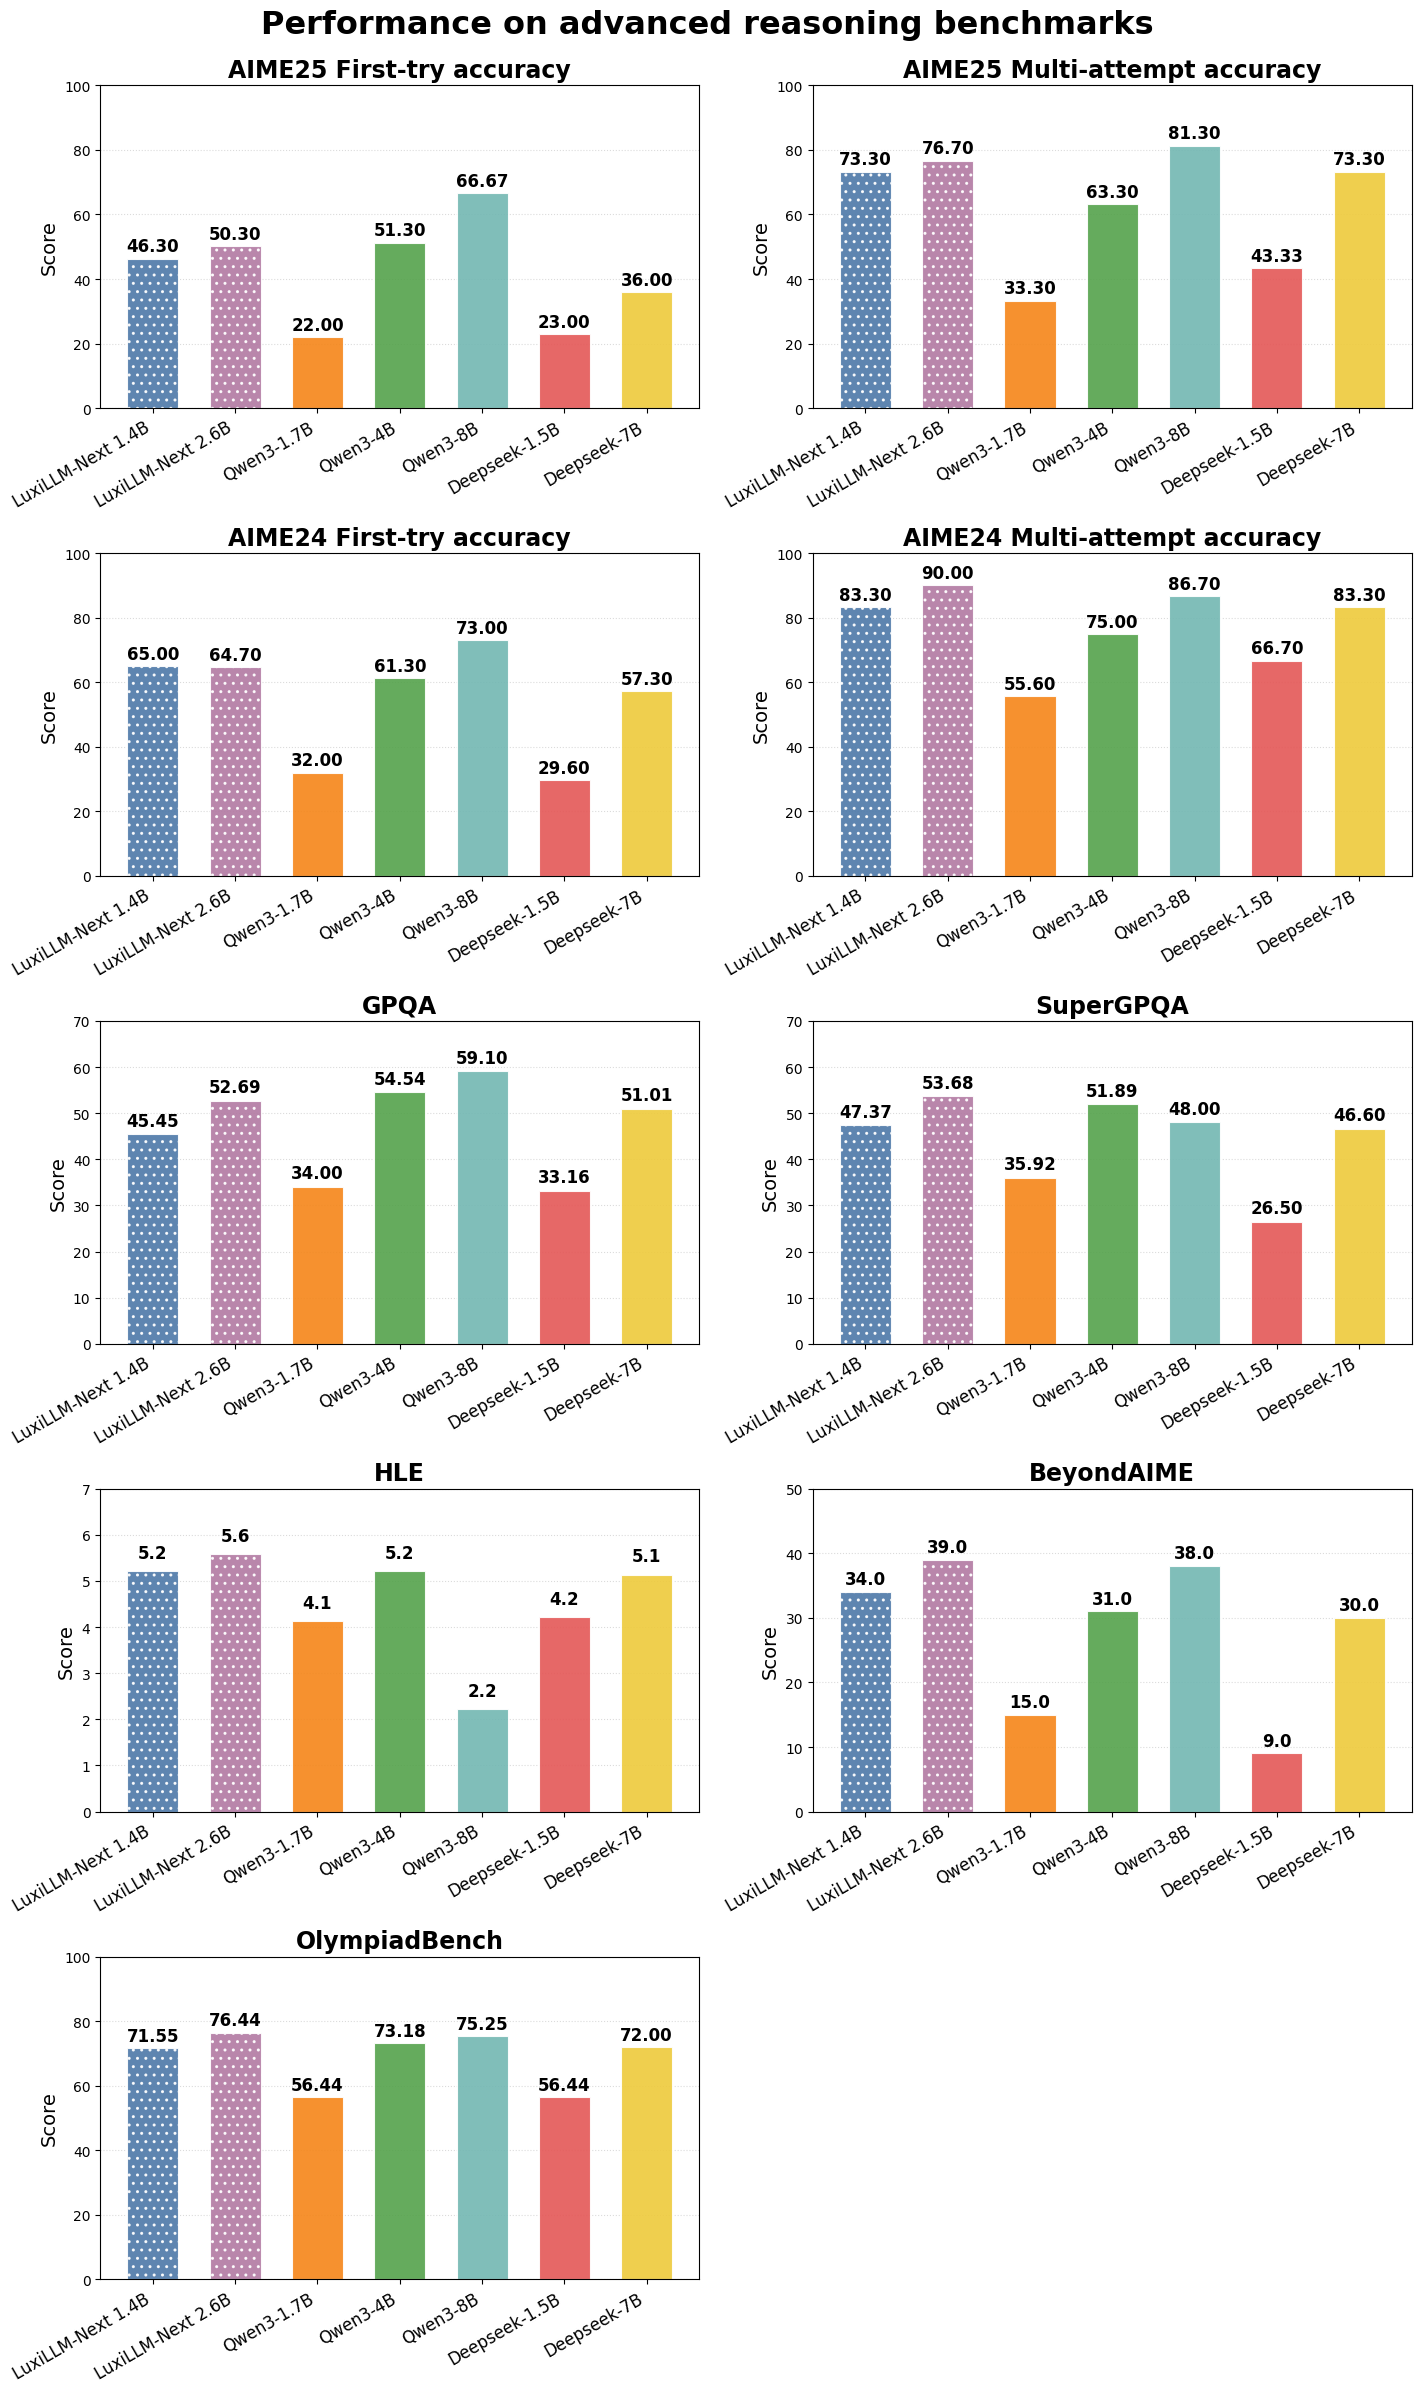

In [53]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import math

data = {
    'AIME24_pass1': [65.0, 64.7, 32.0, 61.3, 73.0, 29.6, 57.3],
    'AIME24_pass10': [83.3, 90.0, 55.6, 75.0, 86.7, 66.7, 83.3],
    'AIME25_pass1': [46.3, 50.3, 22.0, 51.3, 66.67, 23.0, 36.0],
    'AIME25_pass10': [73.3, 76.7, 33.3, 63.3, 81.3, 43.33, 73.3],
    'Olympiadbench': [71.55, 76.44, 56.44, 73.18, 75.25, 56.44, 72.0],
    'BeyondAIME': [34.0, 39.0, 15.0, 31.0, 38.0, 9.0, 30.0],
    'HLE': [5.21, 5.58, 4.13, 5.21, 2.22, 4.22, 5.14],
    'SuperGPQA': [47.37, 53.68, 35.92, 51.89, 48.0, 26.5, 46.6],
    'GPQA': [45.45, 52.69, 34.0, 54.54, 59.1, 33.16, 51.01]
}

model_labels = ['LuxiLLM-Next 1.4B', 'LuxiLLM-Next 2.6B', 'Qwen3-1.7B', 'Qwen3-4B',
                'Qwen3-8B', 'Deepseek-1.5B', 'Deepseek-7B']
colors = ['#4C78A8', '#B279A2', '#F58518', '#54A24B', '#72B7B2', '#E45756', '#EECA3B']

ordered_panels = [
    ('AIME25_pass1', 'AIME25 First-try accuracy', (0, 100)),
    ('AIME25_pass10', 'AIME25 Multi-attempt accuracy', (0, 100)),
    ('AIME24_pass1', 'AIME24 First-try accuracy', (0, 100)),
    ('AIME24_pass10', 'AIME24 Multi-attempt accuracy', (0, 100)),
    ('GPQA', 'GPQA', (0, 70)),
    ('SuperGPQA', 'SuperGPQA', (0, 70)),
    ('HLE', 'HLE', (0, 7)),
    ('BeyondAIME', 'BeyondAIME', (0, 50)),
    ('Olympiadbench', 'OlympiadBench', (0, 100)),
]

# ===== 布局：每行 2 图 =====
cols = 2
rows = math.ceil(len(ordered_panels) / cols)
fig = plt.figure(figsize=(cols * 7.2, rows * 4.8))  # 两列时适当加宽加高
x = np.arange(len(model_labels))
bar_width = 0.62
label_fs = 12
title_fs = 17
tick_fs = 12
ylab_fs = 14

def draw_single_series(ax, series_key, title, ylim):
    for i in range(len(model_labels)):
        hatch = '..' if i < 2 else None  # LuxiLLM-Next 用点阵
        ax.bar(x[i], data[series_key][i],
               width=bar_width, color=colors[i], alpha=0.9,
               edgecolor='white', linewidth=0.8, hatch=hatch)
    bump = 1.0 if ylim[1] >= 70 else (0.2 if ylim[1] <= 7 else 0.6)
    for i, v in enumerate(data[series_key]):
        fmt = f'{v:.2f}' if (ylim[1] >= 70 or series_key == 'Olympiadbench') else f'{v:.1f}'
        ax.text(i, v + bump, fmt, ha='center', va='bottom', fontsize=label_fs, fontweight='bold')

    ax.set_title(title, fontsize=title_fs, fontweight='bold')
    ax.set_ylabel('Score', fontsize=ylab_fs)
    ax.set_xticks(x)
    ax.set_xticklabels(model_labels, rotation=30, ha='right', fontsize=tick_fs)
    ax.set_ylim(ylim)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)

for idx, (key, title, ylim) in enumerate(ordered_panels, start=1):
    ax = plt.subplot(rows, cols, idx)
    draw_single_series(ax, key, title, ylim)

fig.suptitle("Performance on advanced reasoning benchmarks", fontsize=23, fontweight='bold', y=0.995)

plt.tight_layout()
plt.savefig("Performance on advanced reasoning benchmarks.png", dpi=600, bbox_inches='tight')
plt.savefig("Performance on advanced reasoning benchmarks.pdf", dpi=600, bbox_inches='tight')
plt.show()

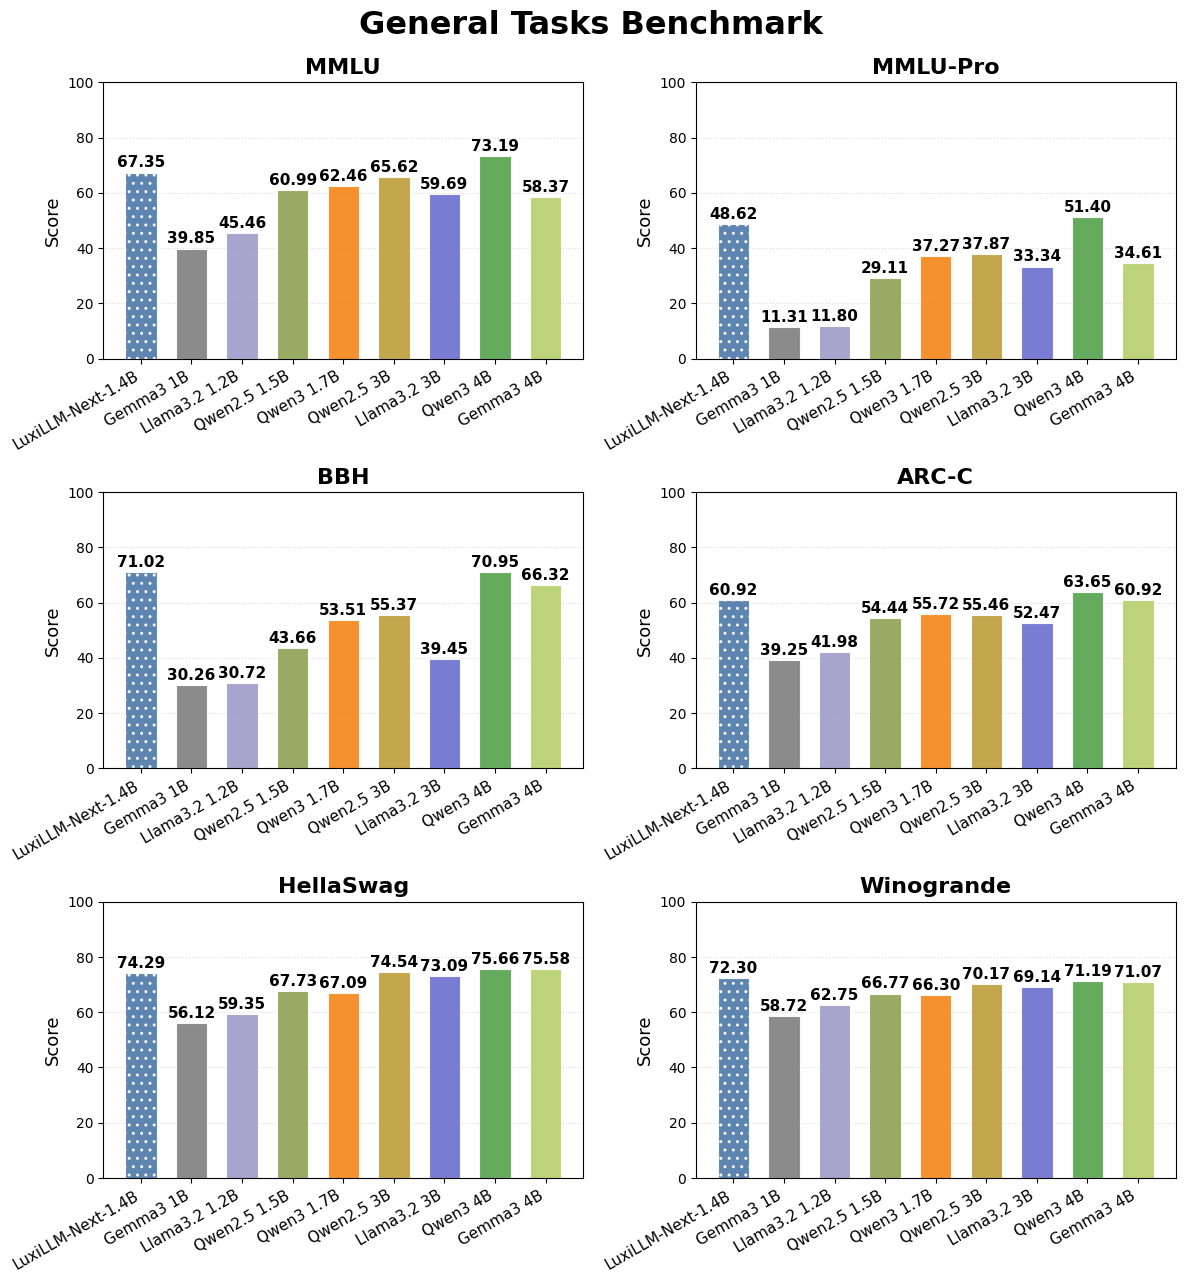

In [48]:
import matplotlib.pyplot as plt
import numpy as np
import math

# 1) 模型顺序（来自表格）
model_labels = [
    'LuxiLLM-Next-1.4B','Gemma3 1B', 'Llama3.2 1.2B', 'Qwen2.5 1.5B', 'Qwen3 1.7B',
    'Qwen2.5 3B', 'Llama3.2 3B', 'Qwen3 4B', 'Gemma3 4B'
]

# 2) 基准数据（来自截图）
bench = {
    'MMLU':        [67.35, 39.85, 45.46, 60.99, 62.46, 65.62, 59.69, 73.19, 58.37],
    'MMLU-Pro':    [48.62, 11.31, 11.80, 29.11, 37.27, 37.87, 33.34, 51.40, 34.61],
    'BBH':         [71.02, 30.26, 30.72, 43.66, 53.51, 55.37, 39.45, 70.95, 66.32],
    'ARC-C':       [60.92, 39.25, 41.98, 54.44, 55.72, 55.46, 52.47, 63.65, 60.92],
    'HellaSwag':   [74.29, 56.12, 59.35, 67.73, 67.09, 74.54, 73.09, 75.66, 75.58],
    'Winogrande':  [72.30, 58.72, 62.75, 66.77, 66.30, 70.17, 69.14, 71.19, 71.07],
}

# 3) 颜色映射 —— 与"上一张图"保持一致的部分
# 之前的调色板（顺序）：[Luxi1.4B, Luxi2.6B, Qwen3-1.7B, Qwen3-4B, Qwen3-8B, Deepseek-1.5B, Deepseek-7B]
PREV = {
    'Luxi-1.4B': '#4C78A8',
    'Luxi-2.6B': '#B279A2',
    'Qwen3-1.7B': '#F58518',
    'Qwen3-4B': '#54A24B',
    'Qwen3-8B': '#72B7B2',
    'Deepseek-1.5B': '#E45756',
    'Deepseek-7B': '#EECA3B',
}
# 需要继承颜色的同名/同族模型
COLOR_MAP = {
    'Qwen3 1.7B': PREV['Qwen3-1.7B'],
    'Qwen3 4B':   PREV['Qwen3-4B'],
    'LuxiLLM-Next-1.4B': PREV['Luxi-1.4B'],   # Ouro = LuxiLLM-Next 1.4B
}
# 其余模型使用新增的中性配色（不与旧图冲突）
EXTRA_COLORS = {
    'Gemma3 1B':     '#7F7F7F',
    'Llama3.2 1.2B': '#9E9AC8',
    'Qwen2.5 1.5B':  '#8CA252',
    'Qwen2.5 3B':    '#BD9E39',
    'Llama3.2 3B':   '#6B6ECF',
    'Gemma3 4B':     '#B5CF6B',
}
# 合并得到完整映射
COLOR_MAP = {**EXTRA_COLORS, **COLOR_MAP}

# hatch：Luxi 家族沿用点阵
HATCH_MAP = {'LuxiLLM-Next-1.4B': '..'}

# 4) 画图（改为2列布局）
tasks = list(bench.keys())
cols, rows = 2, math.ceil(len(tasks)/2)  # 改为2列
fig = plt.figure(figsize=(cols*6, rows*4.3))  # 调整尺寸适应2列

x = np.arange(len(model_labels))
bar_width = 0.62
label_fs, title_fs, tick_fs, ylab_fs = 11, 16, 11, 13

def draw_panel(ax, task_name, ylim=(0, 100)):
    vals = bench[task_name]
    for i, m in enumerate(model_labels):
        v = vals[i]
        ax.bar(
            x[i], v,
            width=bar_width,
            color=COLOR_MAP[m],
            edgecolor='white', linewidth=0.8,
            alpha=0.9,
            hatch=HATCH_MAP.get(m, None)
        )
        ax.text(i, v + 0.8, f'{v:.2f}', ha='center', va='bottom',
                fontsize=label_fs, fontweight='bold')
    ax.set_title(task_name, fontsize=title_fs, fontweight='bold')
    ax.set_ylabel('Score', fontsize=ylab_fs)
    ax.set_xticks(x)
    ax.set_xticklabels(model_labels, rotation=30, ha='right', fontsize=tick_fs)
    ax.set_ylim(ylim)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)

for idx, task in enumerate(tasks, start=1):
    ax = plt.subplot(rows, cols, idx)
    draw_panel(ax, task)

fig.suptitle('General Tasks Benchmark', fontsize=23, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig("General Tasks Benchmark14.png", dpi=600, bbox_inches='tight')
plt.savefig("General Tasks Benchmark14.pdf", dpi=600, bbox_inches='tight')
plt.show()

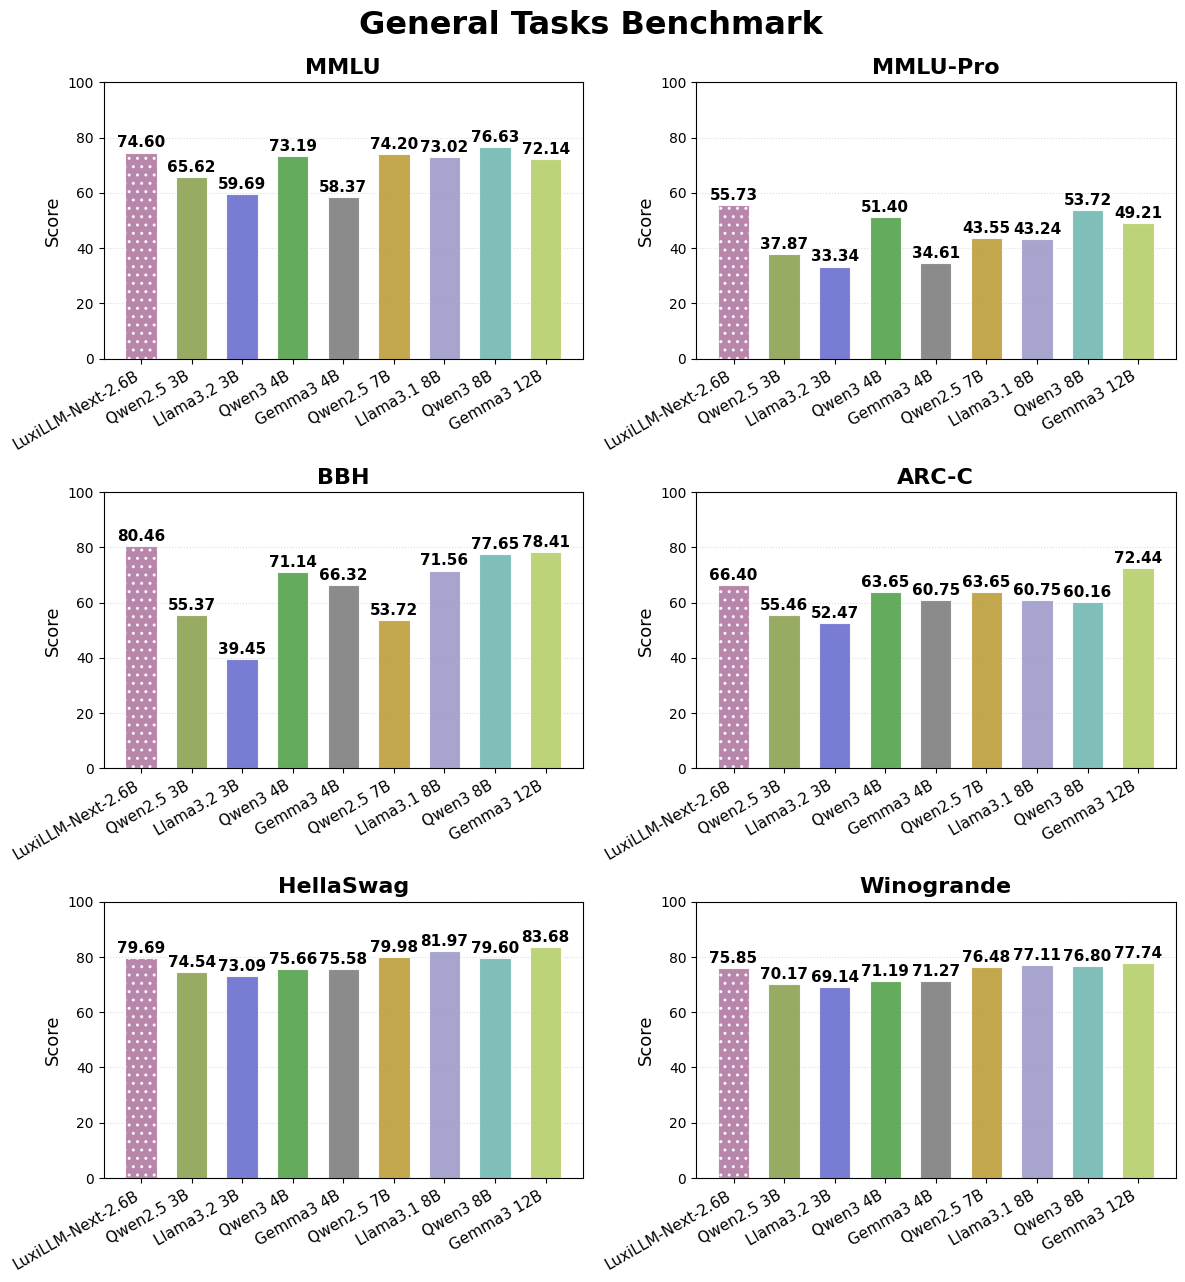

In [49]:
import matplotlib.pyplot as plt
import numpy as np
import math

# 1) 模型顺序（Ouro 最左）
model_labels = [
    'LuxiLLM-Next-2.6B',    # = LuxiLLM-Next 2.6B
    'Qwen2.5 3B',
    'Llama3.2 3B',
    'Qwen3 4B',
    'Gemma3 4B',
    'Qwen2.5 7B',
    'Llama3.1 8B',
    'Qwen3 8B',
    'Gemma3 12B',
]

# 2) General Tasks 数据（已按上面的顺序重排；来自你给的表）
bench = {
    'MMLU':       [74.60, 65.62, 59.69, 73.19, 58.37, 74.20, 73.02, 76.63, 72.14],
    'MMLU-Pro':   [55.73, 37.87, 33.34, 51.40, 34.61, 43.55, 43.24, 53.72, 49.21],
    'BBH':        [80.46, 55.37, 39.45, 71.14, 66.32, 53.72, 71.56, 77.65, 78.41],
    'ARC-C':      [66.40, 55.46, 52.47, 63.65, 60.75, 63.65, 60.75, 60.16, 72.44],
    'HellaSwag':  [79.69, 74.54, 73.09, 75.66, 75.58, 79.98, 81.97, 79.60, 83.68],
    'Winogrande': [75.85, 70.17, 69.14, 71.19, 71.27, 76.48, 77.11, 76.80, 77.74],
}

# 3) 颜色映射（与前图保持一致）
PREV = {
    'Luxi-1.4B':   '#4C78A8',
    'Luxi-2.6B':   '#B279A2',
    'Qwen3-1.7B':  '#F58518',
    'Qwen3-4B':    '#54A24B',
    'Qwen3-8B':    '#72B7B2',
    'Deepseek-1.5B':'#E45756',
    'Deepseek-7B': '#EECA3B',
}
COLOR_MAP = {
    'LuxiLLM-Next-2.6B': PREV['Luxi-2.6B'],   # Ouro = Luxi 2.6B（紫色）
    'Qwen3 4B':     PREV['Qwen3-4B'],
    'Qwen3 8B':     PREV['Qwen3-8B'],
    # 其他给中性新色
    'Qwen2.5 3B':   '#8CA252',
    'Llama3.2 3B':  '#6B6ECF',
    'Gemma3 4B':    '#7F7F7F',
    'Qwen2.5 7B':   '#BD9E39',
    'Llama3.1 8B':  '#9E9AC8',
    'Gemma3 12B':   '#B5CF6B',
}
HATCH_MAP = {'LuxiLLM-Next-2.6B': '..'}  # Luxi 家族保留点阵

# 4) 画图（3×2，无图例）
tasks = list(bench.keys())
cols, rows = 2, math.ceil(len(tasks)/2)  # 改为2列

fig = plt.figure(figsize=(cols*6, rows*4.3))  # 调整尺寸适应2列
x = np.arange(len(model_labels))
bar_width = 0.62
label_fs, title_fs, tick_fs, ylab_fs = 11, 16, 11, 13

def draw_panel(ax, task_name, ylim=(0, 100)):
    vals = bench[task_name]
    for i, m in enumerate(model_labels):
        v = vals[i]
        ax.bar(x[i], v, width=bar_width,
               color=COLOR_MAP[m], edgecolor='white', linewidth=0.8, alpha=0.9,
               hatch=HATCH_MAP.get(m, None))
        ax.text(i, v + 0.8, f'{v:.2f}', ha='center', va='bottom',
                fontsize=label_fs, fontweight='bold')
    ax.set_title(task_name, fontsize=title_fs, fontweight='bold')
    ax.set_ylabel('Score', fontsize=ylab_fs)
    ax.set_xticks(x)
    ax.set_xticklabels(model_labels, rotation=30, ha='right', fontsize=tick_fs)
    ax.set_ylim(ylim)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)

for idx, task in enumerate(tasks, start=1):
    ax = plt.subplot(rows, cols, idx)
    draw_panel(ax, task)

fig.suptitle('General Tasks Benchmark', fontsize=23, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig("General Tasks Benchmark26.png", dpi=600, bbox_inches='tight')
plt.savefig("General Tasks Benchmark26.pdf", dpi=600, bbox_inches='tight')
plt.show()

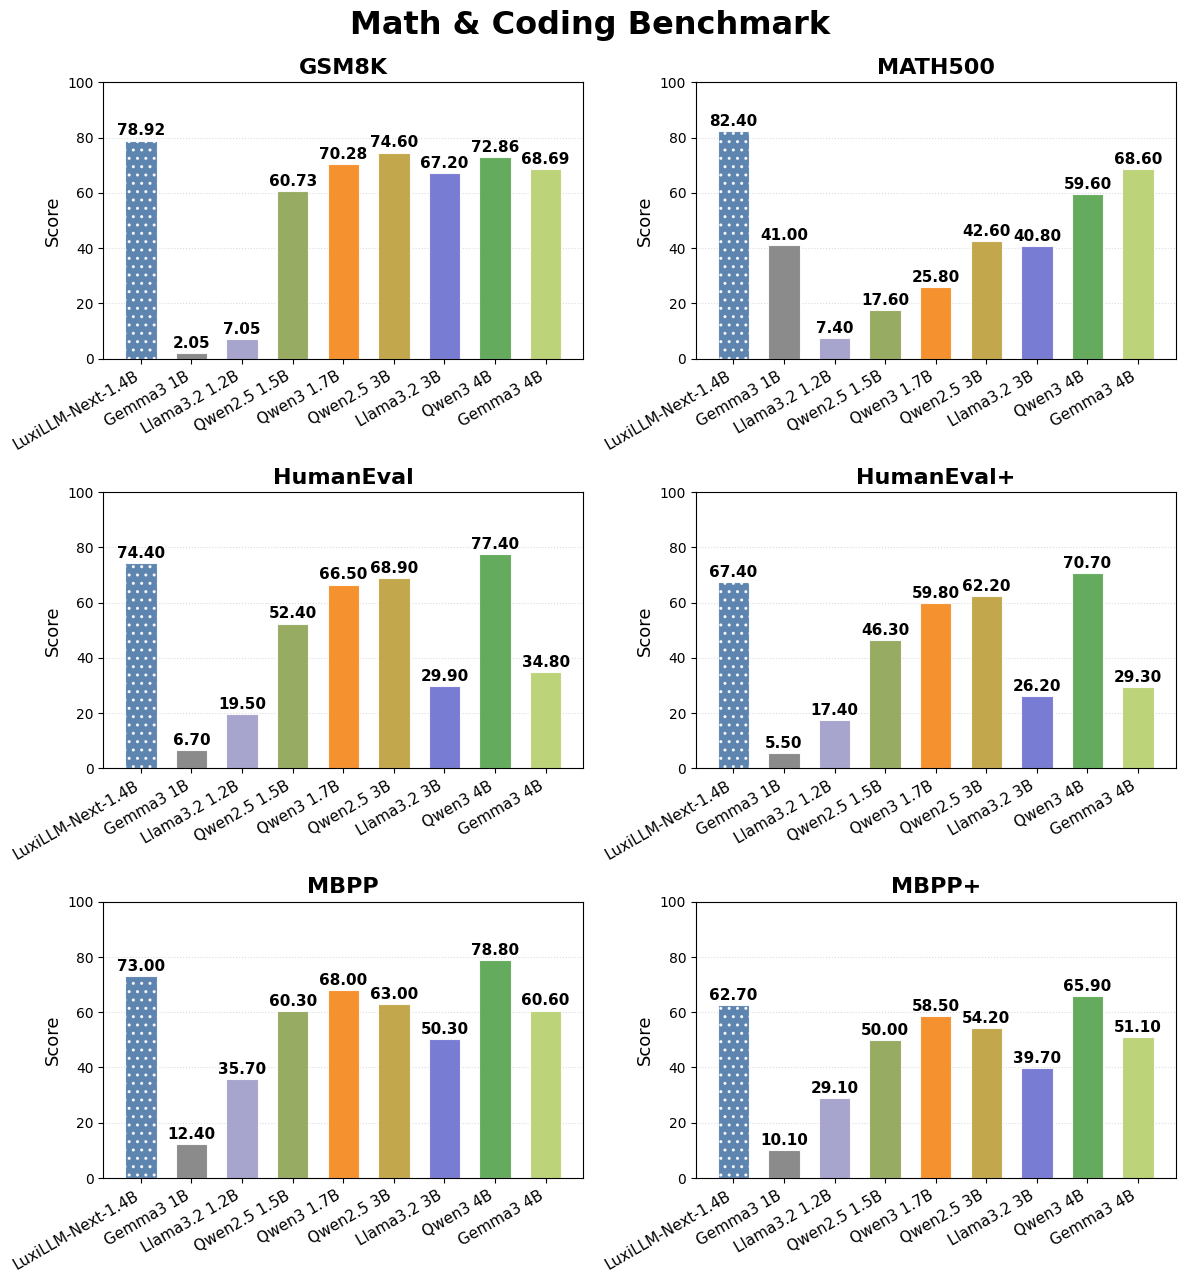

In [46]:
import matplotlib.pyplot as plt
import numpy as np
import math

# ========== 1) 模型顺序（Ouro 放最左） ==========
model_labels = [
    'LuxiLLM-Next-1.4B',     # = LuxiLLM-Next 1.4B
    'Gemma3 1B',
    'Llama3.2 1.2B',
    'Qwen2.5 1.5B',
    'Qwen3 1.7B',
    'Qwen2.5 3B',
    'Llama3.2 3B',
    'Qwen3 4B',
    'Gemma3 4B',
]

# ========== 2) Math & Coding 数据（按上面的顺序已重排） ==========
bench = {
    'GSM8K':       [78.92, 2.05, 7.05, 60.73, 70.28, 74.60, 67.20, 72.86, 68.69],
    'MATH500':     [82.40, 41.00, 7.40, 17.60, 25.80, 42.60, 40.80, 59.60, 68.60],
    'HumanEval':   [74.40, 6.70, 19.50, 52.40, 66.50, 68.90, 29.90, 77.40, 34.80],
    'HumanEval+':  [67.40, 5.50, 17.40, 46.30, 59.80, 62.20, 26.20, 70.70, 29.30],
    'MBPP':        [73.00, 12.40, 35.70, 60.30, 68.00, 63.00, 50.30, 78.80, 60.60],
    'MBPP+':       [62.70, 10.10, 29.10, 50.00, 58.50, 54.20, 39.70, 65.90, 51.10],
}

# ========== 3) 颜色映射（与前一张图保持一致） ==========
PREV = {
    'Luxi-1.4B':   '#4C78A8',
    'Luxi-2.6B':   '#B279A2',
    'Qwen3-1.7B':  '#F58518',
    'Qwen3-4B':    '#54A24B',
    'Qwen3-8B':    '#72B7B2',
    'Deepseek-1.5B':'#E45756',
    'Deepseek-7B': '#EECA3B',
}
COLOR_MAP = {
    'LuxiLLM-Next-1.4B': PREV['Luxi-1.4B'],  # Ouro=Luxi 1.4B
    'Qwen3 1.7B':   PREV['Qwen3-1.7B'],
    'Qwen3 4B':     PREV['Qwen3-4B'],
    # 其余给中性新色，不影响旧映射
    'Gemma3 1B':     '#7F7F7F',
    'Llama3.2 1.2B': '#9E9AC8',
    'Qwen2.5 1.5B':  '#8CA252',
    'Qwen2.5 3B':    '#BD9E39',
    'Llama3.2 3B':   '#6B6ECF',
    'Gemma3 4B':     '#B5CF6B',
}
HATCH_MAP = {'LuxiLLM-Next-1.4B': '..'}  # Luxi 家族保留点阵

# ========== 4) 画图（3×2， 无图例） ==========
tasks = list(bench.keys())
cols, rows = 2, math.ceil(len(tasks)/2)  # 改为2列

fig = plt.figure(figsize=(cols*6, rows*4.3))  # 调整尺寸适应2列
x = np.arange(len(model_labels))
bar_width = 0.62
label_fs, title_fs, tick_fs, ylab_fs = 11, 16, 11, 13

def draw_panel(ax, task_name, ylim=(0, 100)):
    vals = bench[task_name]
    for i, m in enumerate(model_labels):
        v = vals[i]
        ax.bar(
            x[i], v, width=bar_width,
            color=COLOR_MAP[m], edgecolor='white', linewidth=0.8, alpha=0.9,
            hatch=HATCH_MAP.get(m, None)
        )
        ax.text(i, v + 0.8, f'{v:.2f}', ha='center', va='bottom',
                fontsize=label_fs, fontweight='bold')
    ax.set_title(task_name, fontsize=title_fs, fontweight='bold')
    ax.set_ylabel('Score', fontsize=ylab_fs)
    ax.set_xticks(x)
    ax.set_xticklabels(model_labels, rotation=30, ha='right', fontsize=tick_fs)
    ax.set_ylim(ylim)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)

for idx, task in enumerate(tasks, start=1):
    ax = plt.subplot(rows, cols, idx)
    draw_panel(ax, task)

fig.suptitle('Math & Coding Benchmark', fontsize=23, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig("Math & Coding Benchmark14.png", dpi=600, bbox_inches='tight')
plt.savefig("Math & Coding Benchmark14.pdf", dpi=600, bbox_inches='tight')
plt.show()

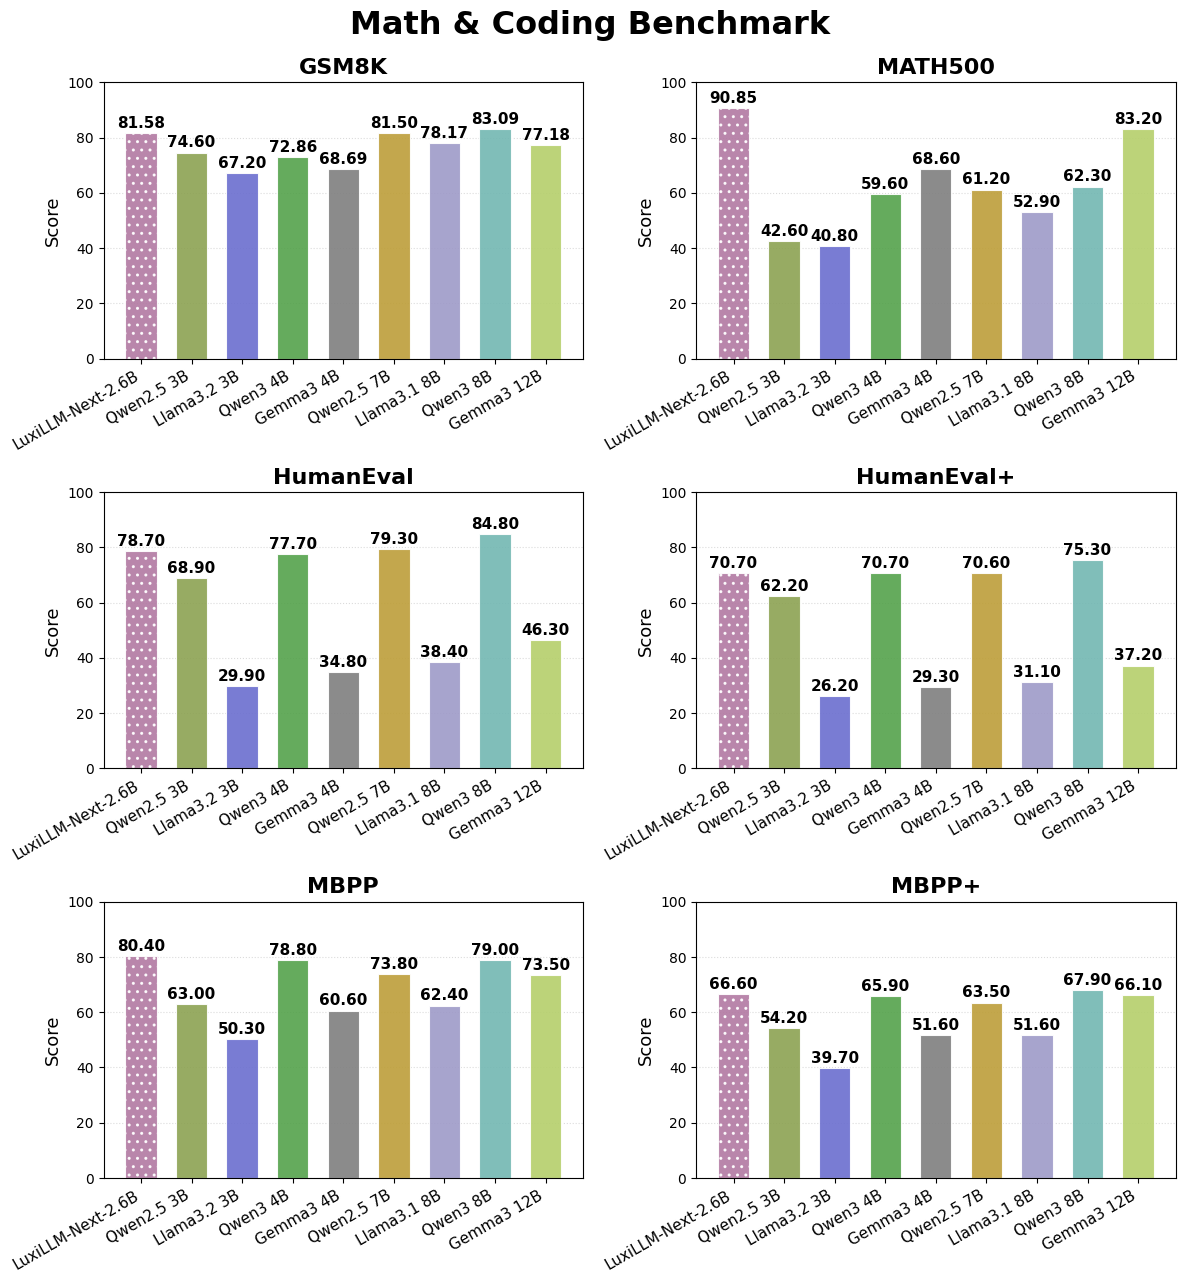

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import math

# ============= 1) 模型顺序：把 Ouro 放到最左 =============
model_labels = [
    'LuxiLLM-Next-2.6B',     # ← moved to left
    'Qwen2.5 3B', 'Llama3.2 3B', 'Qwen3 4B', 'Gemma3 4B',
    'Qwen2.5 7B', 'Llama3.1 8B', 'Qwen3 8B', 'Gemma3 12B',
]

# ============= 2) 数据（已按上面顺序重排） =============
general = {
    'MMLU':       [74.60, 65.62, 59.69, 73.19, 58.37, 74.20, 73.02, 76.63, 72.14],
    'MMLU-Pro':   [55.73, 37.87, 33.34, 51.40, 34.61, 43.55, 43.24, 53.72, 49.21],
    'BBH':        [80.46, 55.37, 39.45, 71.14, 66.32, 53.72, 71.56, 77.65, 78.41],
    'ARC-C':      [66.40, 55.46, 52.47, 63.65, 60.75, 63.65, 60.75, 60.16, 72.44],
    'HellaSwag':  [79.69, 74.54, 73.09, 75.66, 75.58, 79.98, 81.97, 79.60, 83.68],
    'Winogrande': [75.85, 70.17, 69.14, 71.19, 71.27, 76.48, 77.11, 76.80, 77.74],
}

mathcode = {
    'GSM8K':      [81.58, 74.60, 67.20, 72.86, 68.69, 81.50, 78.17, 83.09, 77.18],
    'MATH500':    [90.85, 42.60, 40.80, 59.60, 68.60, 61.20, 52.90, 62.30, 83.20],
    'HumanEval':  [78.70, 68.90, 29.90, 77.70, 34.80, 79.30, 38.40, 84.80, 46.30],
    'HumanEval+': [70.70, 62.20, 26.20, 70.70, 29.30, 70.60, 31.10, 75.30, 37.20],
    'MBPP':       [80.40, 63.00, 50.30, 78.80, 60.60, 73.80, 62.40, 79.00, 73.50],
    'MBPP+':      [66.60, 54.20, 39.70, 65.90, 51.60, 63.50, 51.60, 67.90, 66.10],
}

# ============= 3) 颜色映射（与之前一致） =============
PREV = {
    'Luxi-2.6B': '#B279A2',
    'Qwen3-4B':  '#54A24B',
    'Qwen3-8B':  '#72B7B2',
}
COLOR_MAP = {
    'LuxiLLM-Next-2.6B': PREV['Luxi-2.6B'],   # Ouro = Luxi 2.6B
    'Qwen3 4B':     PREV['Qwen3-4B'],
    'Qwen3 8B':     PREV['Qwen3-8B'],
    # 其他中性新色
    'Qwen2.5 3B':   '#8CA252',
    'Llama3.2 3B':  '#6B6ECF',
    'Gemma3 4B':    '#7F7F7F',
    'Qwen2.5 7B':   '#BD9E39',
    'Llama3.1 8B':  '#9E9AC8',
    'Gemma3 12B':   '#B5CF6B',
}
HATCH_MAP = {'LuxiLLM-Next-2.6B': '..'}   # Luxi 家族保留点阵

# ============= 4) 画图函数（3×2，无图例） =============
def plot_section(bench, title, filename):
    tasks = list(bench.keys())
    cols, rows = 2, math.ceil(len(tasks)/2)  # 改为2列

    fig = plt.figure(figsize=(cols*6, rows*4.3))  # 调整尺寸适应2列
    x = np.arange(len(model_labels))
    bar_w = 0.62

    for i, task in enumerate(tasks, 1):
        ax = plt.subplot(rows, cols, i)
        vals = bench[task]
        for j, m in enumerate(model_labels):
            v = vals[j]
            ax.bar(x[j], v, width=bar_w,
                   color=COLOR_MAP[m], edgecolor='white', linewidth=0.8, alpha=0.9,
                   hatch=HATCH_MAP.get(m, None))
            ax.text(j, v + 0.8, f'{v:.2f}', ha='center', va='bottom',
                    fontsize=11, fontweight='bold')
        ax.set_title(task, fontsize=16, fontweight='bold')
        ax.set_ylabel('Score', fontsize=13)
        ax.set_xticks(x)
        ax.set_xticklabels(model_labels, rotation=30, ha='right', fontsize=11)
        ax.set_ylim(0, 100)
        ax.grid(axis='y', linestyle=':', alpha=0.45)
        ax.set_axisbelow(True)

    fig.suptitle(title, fontsize=23, fontweight='bold', y=0.99)
    plt.tight_layout()
    
    # 先保存再显示
    plt.savefig(f"{filename}.png", dpi=600, bbox_inches='tight')
    plt.savefig(f"{filename}.pdf", dpi=600, bbox_inches='tight')
    plt.show()

# 调用函数
plot_section(mathcode, 'Math & Coding Benchmark', "Math & Coding Benchmark26")

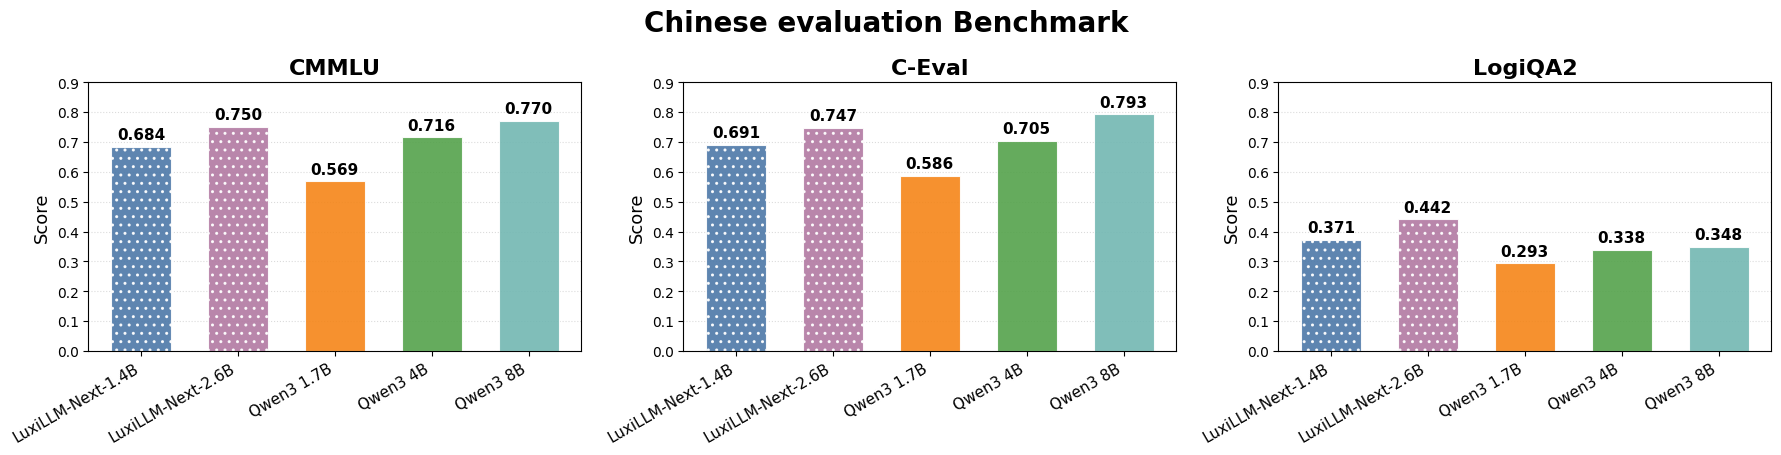

In [51]:
import matplotlib.pyplot as plt
import numpy as np

# ===== 1) 数据（按你截图顺序）=====
models = ['LuxiLLM-Next-1.4B', 'LuxiLLM-Next-2.6B', 'Qwen3 1.7B', 'Qwen3 4B', 'Qwen3 8B']
data = {
    'CMMLU':  [0.6845, 0.7501, 0.5688, 0.7155, 0.7702],
    'C-Eval': [0.6909, 0.7467, 0.5862, 0.7051, 0.7927],
    'LogiQA2':[0.3715, 0.4415, 0.2933, 0.3378, 0.3480],
}

# ===== 2) 颜色与 hatch：与之前完全一致 =====
COLOR = {
    'LuxiLLM-Next-1.4B': '#4C78A8',   # Luxi 1.4B
    'LuxiLLM-Next-2.6B': '#B279A2',   # Luxi 2.6B
    'Qwen3 1.7B': '#F58518',
    'Qwen3 4B':  '#54A24B',
    'Qwen3 8B':  '#72B7B2',
}
HATCH = {'LuxiLLM-Next-1.4B': '..', 'LuxiLLM-Next-2.6B': '..'}  # Luxi 家族点阵

# ===== 3) 画图：一行三个面板、无图例 =====
tasks = list(data.keys())
fig = plt.figure(figsize=(18, 4.6))
x = np.arange(len(models))
bar_w = 0.62

for i, task in enumerate(tasks, 1):
    ax = plt.subplot(1, 3, i)
    vals = data[task]
    for j, m in enumerate(models):
        v = vals[j]
        ax.bar(x[j], v, width=bar_w,
               color=COLOR[m], edgecolor='white', linewidth=0.8, alpha=0.9,
               hatch=HATCH.get(m, None))
        ax.text(j, v + 0.015, f'{v:.3f}', ha='center', va='bottom',
                fontsize=11, fontweight='bold')
    ax.set_title(task, fontsize=16, fontweight='bold')
    ax.set_ylabel('Score', fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=30, ha='right', fontsize=11)
    ax.set_ylim(0, 0.9)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)

fig.suptitle('Chinese evaluation Benchmark', fontsize=20, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig("Chinese evaluation Benchmark.png", dpi=600, bbox_inches='tight')
plt.savefig("Chinese evaluation Benchmark.pdf", dpi=600, bbox_inches='tight')
plt.show()

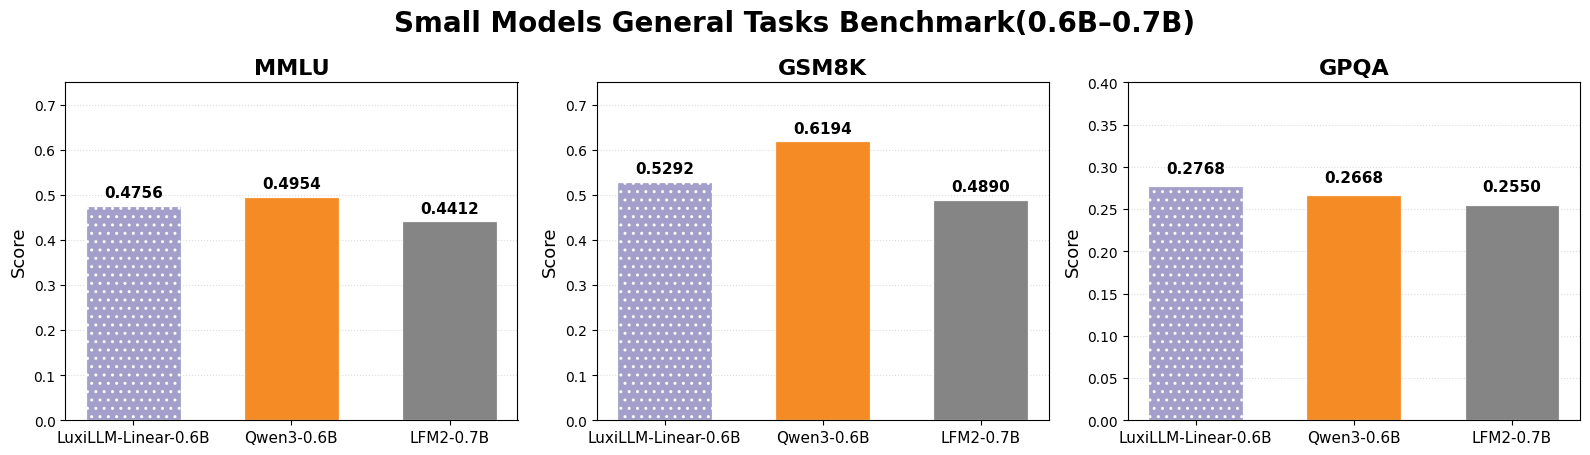

In [66]:
import matplotlib.pyplot as plt
import numpy as np

# 1) 数据（按你截图）
models = ['LuxiLLM-Linear-0.6B','Qwen3-0.6B',  'LFM2-0.7B']
bench = {
    'MMLU':   [ 0.4756,0.4954, 0.4412],
    'GSM8K':  [ 0.5292,0.6194, 0.4890],
    'GPQA':   [0.2768,0.2668,  0.2550],
}

# 2) 颜色与 hatch（保持与之前一致：Qwen3=橙色；LinCal 新色+点阵；LFM2 新色）
COLOR = {
    'Qwen3-0.6B': '#F58518',  # 与前面所有 Qwen3 一致
    'LuxiLLM-Linear-0.6B': '#9E9AC8', # 新色（浅紫）
    'LFM2-0.7B':  '#7F7F7F',  # 新色（中性灰）
}
HATCH = {
    'LuxiLLM-Linear-0.6B': '..'       # 只给 LinCal 打点
}

# 3) 画图：一行三个面板
tasks = list(bench.keys())
fig = plt.figure(figsize=(16, 4.6))
x = np.arange(len(models))
bar_w = 0.6

for i, task in enumerate(tasks, 1):
    ax = plt.subplot(1, 3, i)
    vals = bench[task]
    for j, m in enumerate(models):
        v = vals[j]
        ax.bar(x[j], v,
               width=bar_w,
               color=COLOR[m],
               edgecolor='white', linewidth=0.9, alpha=0.95,
               hatch=HATCH.get(m, None))
        ax.text(j, v + 0.012, f'{v:.4f}', ha='center', va='bottom',
                fontsize=11, fontweight='bold')
    ax.set_title(task, fontsize=16, fontweight='bold')
    ax.set_ylabel('Score', fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=0, fontsize=11)
    ax.set_ylim(0, 0.75 if task != 'GPQA' else 0.4)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)

fig.suptitle('Small Models General Tasks Benchmark(0.6B–0.7B)', fontsize=20, fontweight='bold', y=0.98)
plt.tight_layout()
# 4) 保存 PNG 与 PDF（300 dpi）
plt.savefig("Small Models General Tasks Benchmark.png", dpi=600, bbox_inches='tight')
plt.savefig("Small Models General Tasks Benchmark.pdf", dpi=600, bbox_inches='tight')


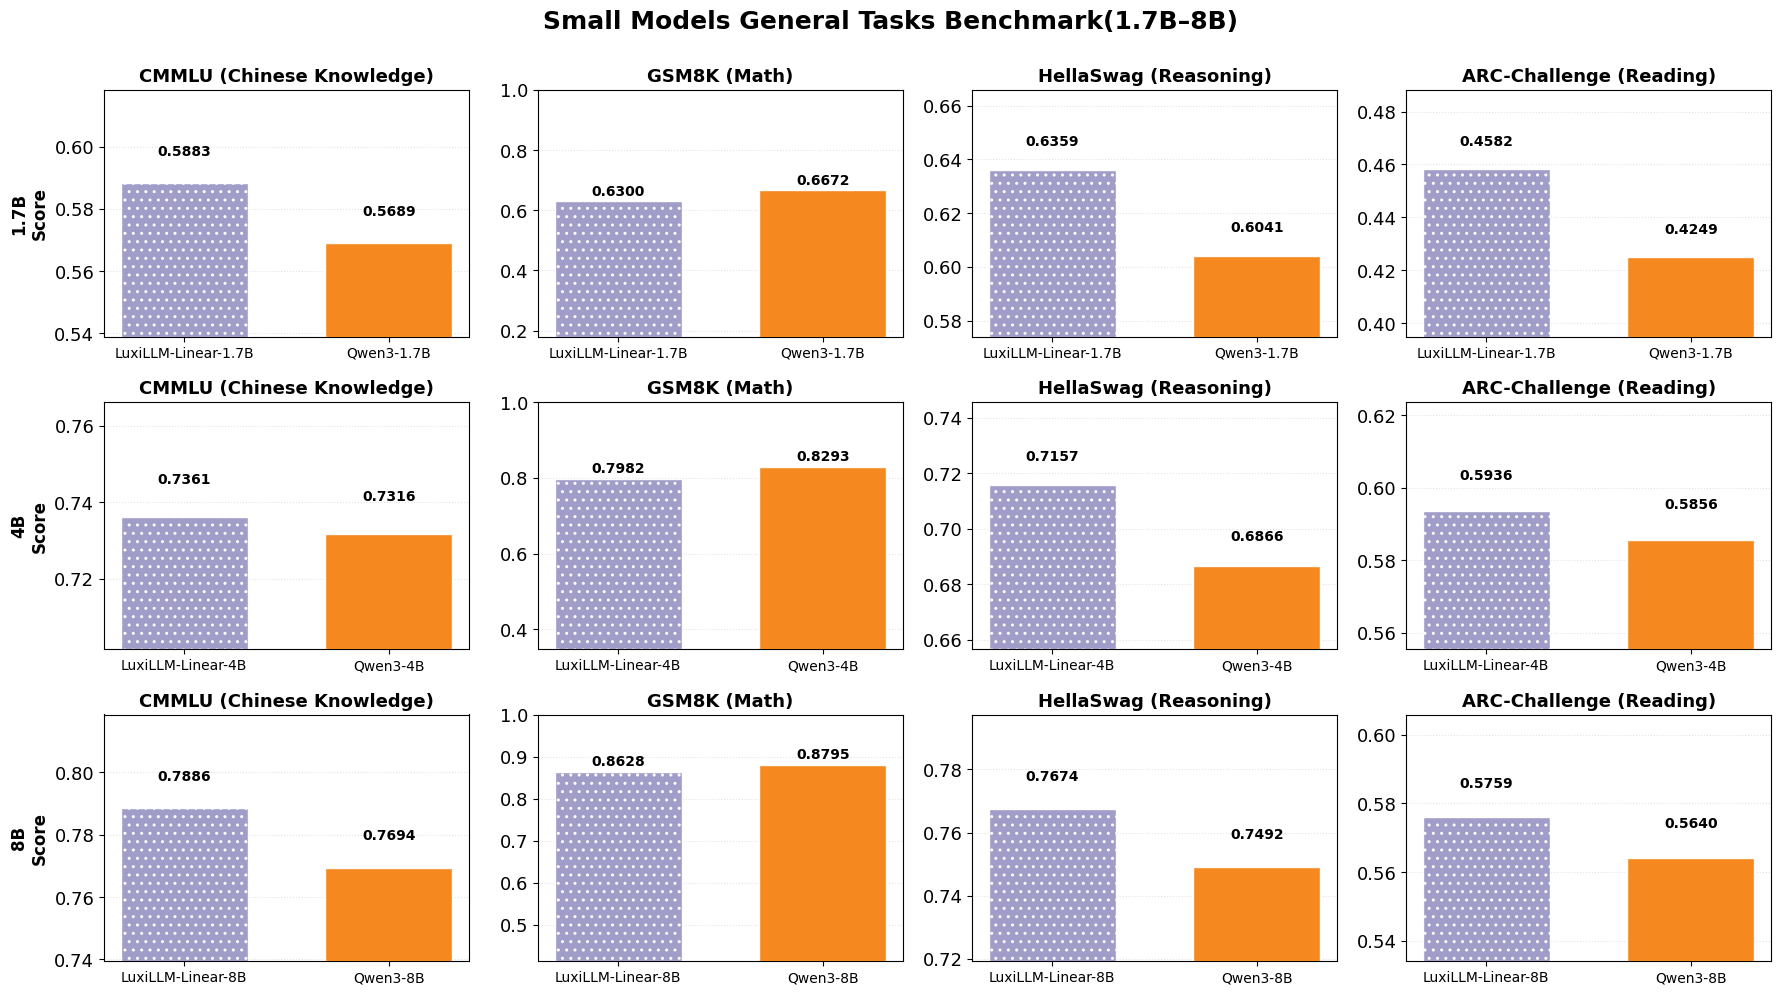

In [17]:
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams.update({
    "font.size": 13,          # 默认字体
    "axes.titlesize": 16,     # 子图标题
    "axes.labelsize": 15,     # 坐标轴标题
    "xtick.labelsize": 13,    # x tick
    "ytick.labelsize": 13,    # y tick
    "legend.fontsize": 13,    # 图例
    "figure.titlesize": 20,   # 总标题
})
# =========================
# Data (from your screenshot)
# =========================
scales = [
    ("1.7B", ["LuxiLLM-Linear-1.7B", "Qwen3-1.7B"], {
        "cmmlu":         [0.5883, 0.5689],
        "gsm8k":         [0.6300, 0.6672],
        "hellaswag":     [0.6359, 0.6041],
        "arc_challenge": [0.4582, 0.4249],
    }),
    ("4B", ["LuxiLLM-Linear-4B", "Qwen3-4B"], {
        "cmmlu":         [0.7361, 0.7316],
        "gsm8k":         [0.7982, 0.8293],
        "hellaswag":     [0.7157, 0.6866],
        "arc_challenge": [0.5936, 0.5856],
    }),
    ("8B", ["LuxiLLM-Linear-8B", "Qwen3-8B"], {
        "cmmlu":         [0.7886, 0.7694],
        "gsm8k":         [0.8628, 0.8795],
        "hellaswag":     [0.7674, 0.7492],
        "arc_challenge": [0.5759, 0.5640],
    }),
]

# =========================
# Style (keep Qwen3 orange; LuxiLLM-Linear new + dotted hatch)
# =========================
COLOR = {"Qwen3": "#F58518", "LuxiLLM-Linear": "#9E9AC8"}
HATCH = {"LuxiLLM-Linear": ".."}

tasks = ["cmmlu", "gsm8k", "hellaswag", "arc_challenge"]
task_titles = {
    "cmmlu": "CMMLU (Chinese Knowledge)",
    "gsm8k": "GSM8K (Math)",
    "hellaswag": "HellaSwag (Reasoning)",
    "arc_challenge": "ARC-Challenge (Reading)",
}

# =========================
# Emphasis controls
# =========================
PAD_DEFAULT = 0.03      # zoom in for most tasks
PAD_GSM8K   = 0.45      # less zoom for GSM8K to avoid over-highlighting small disadvantage
VAL_Y       = 0.008
DELTA_Y     = 0.010

# For GSM8K: if Luxi < Qwen, hide Δ and hide the Qwen baseline (so disadvantage is not spotlighted)
HIDE_NEG_DELTA_ON_GSM8K = True
HIDE_BASELINE_ON_GSM8K  = True

fig, axes = plt.subplots(nrows=len(scales), ncols=len(tasks), figsize=(18, 10))
bar_w = 0.62

for r, (scale_name, models, bench) in enumerate(scales):
    x = np.arange(len(models))  # [0]=Luxi, [1]=Qwen

    for c, task in enumerate(tasks):
        ax = axes[r, c]
        luxi_v, qwen_v = bench[task]   # left, right
        vals = [luxi_v, qwen_v]
        diff = luxi_v - qwen_v

        # Bars + value labels
        for j, m in enumerate(models):
            family = "LuxiLLM-Linear" if m.lower().startswith("luxillm-linear") else "Qwen3"
            ax.bar(
                x[j], vals[j],
                width=bar_w,
                color=COLOR[family],
                edgecolor="white",
                linewidth=1.0,
                alpha=0.97,
                hatch=HATCH.get(family, None),
                zorder=3,
            )
            ax.text(
                x[j], vals[j] + VAL_Y,
                f"{vals[j]:.4f}",
                ha="center", va="bottom",
                fontsize=10, fontweight="bold",
                zorder=6,
            )
        '''
        # Baseline at Qwen score (optional per-task)
        if not (task == "gsm8k" and HIDE_BASELINE_ON_GSM8K):
            ax.axhline(qwen_v, linestyle="--", linewidth=1.2, alpha=0.55, zorder=2)

        # Delta label: show for positive gains; for GSM8K negative, optionally hide
        show_delta = True
        if task == "gsm8k" and HIDE_NEG_DELTA_ON_GSM8K and diff < 0:
            show_delta = False

        if show_delta:
            sign = "+" if diff >= 0 else ""
            ax.text(
                x[0], max(vals) + DELTA_Y,
                f"{sign}{diff:.4f}",
                ha="center", va="bottom",
                fontsize=11, fontweight="bold",
                zorder=7,
            )
        '''
        # Y-limits: tight zoom for most; broader for GSM8K
        pad = PAD_GSM8K if task == "gsm8k" else PAD_DEFAULT
        vmin, vmax = min(vals), max(vals)
        y0 = max(0.0, vmin - pad)
        y1 = min(1.0, vmax + pad)
        ax.set_ylim(y0, y1)

        # Cosmetics
        ax.set_title(task_titles[task], fontsize=13, fontweight="bold")
        ax.set_xticks(x)
        ax.set_xticklabels(models, fontsize=10)
        ax.grid(axis="y", linestyle=":", alpha=0.35, zorder=1)
        ax.set_axisbelow(True)

        if c == 0:
            ax.set_ylabel(f"{scale_name}\nScore", fontsize=12, fontweight="bold")
        else:
            ax.set_ylabel("")

fig.suptitle("Small Models General Tasks Benchmark(1.7B–8B)", fontsize=18, fontweight="bold", y=0.995)
plt.tight_layout()

# Save (optional)
plt.savefig("Small Models General Tasks Benchmark(1.7B–8B).png", dpi=600, bbox_inches="tight")
plt.savefig("Small Models General Tasks Benchmark(1.7B–8B).pdf", dpi=600, bbox_inches="tight")

# plt.show()

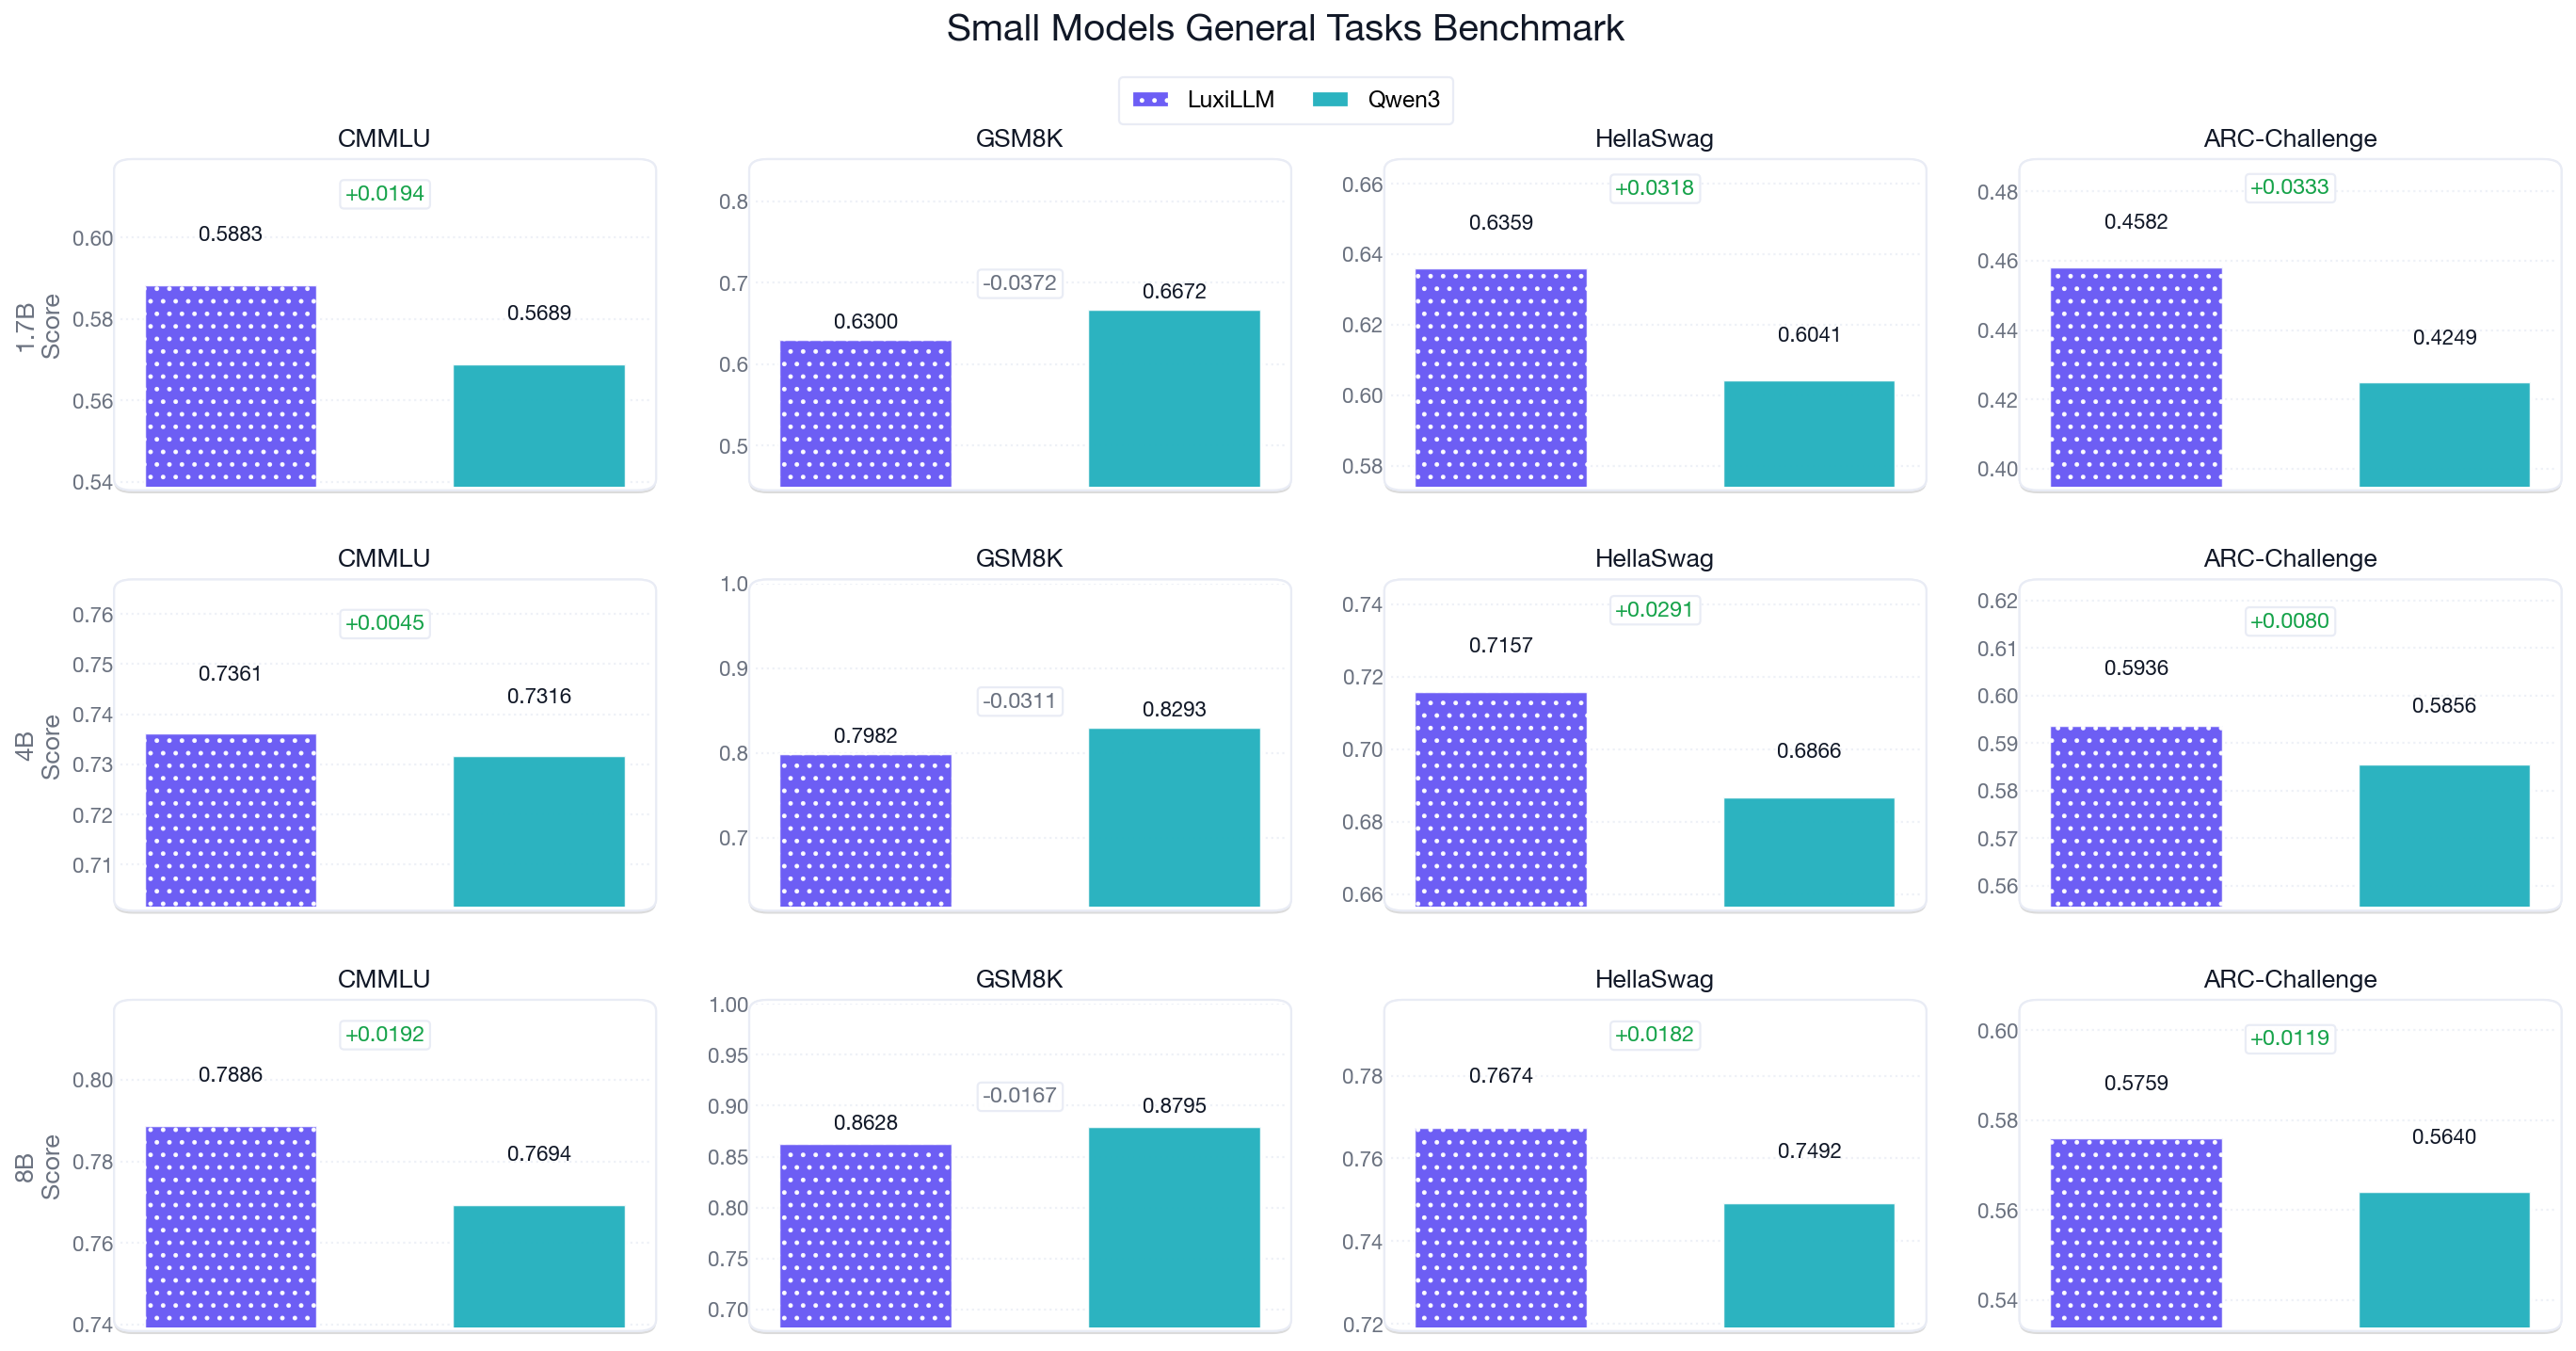

In [35]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe

# =========================
# Global style (web-card look)
# =========================
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,

    "font.family": "sans-serif",
    "font.sans-serif": ["PingFang SC", "SF Pro Display", "Helvetica Neue", "Arial Unicode MS", "DejaVu Sans"],
    "axes.unicode_minus": False,

    "font.size": 12,
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
})

# =========================
# Data (unchanged)
# =========================
scales = [
    ("1.7B", ["LuxiLLM-1.7B", "Qwen3-1.7B"], {
        "cmmlu":         [0.5883, 0.5689],
        "gsm8k":         [0.6300, 0.6672],
        "hellaswag":     [0.6359, 0.6041],
        "arc_challenge": [0.4582, 0.4249],
    }),
    ("4B", ["LuxiLLM-4B", "Qwen3-4B"], {
        "cmmlu":         [0.7361, 0.7316],
        "gsm8k":         [0.7982, 0.8293],
        "hellaswag":     [0.7157, 0.6866],
        "arc_challenge": [0.5936, 0.5856],
    }),
    ("8B", ["LuxiLLM-8B", "Qwen3-8B"], {
        "cmmlu":         [0.7886, 0.7694],
        "gsm8k":         [0.8628, 0.8795],
        "hellaswag":     [0.7674, 0.7492],
        "arc_challenge": [0.5759, 0.5640],
    }),
]

tasks = ["cmmlu", "gsm8k", "hellaswag", "arc_challenge"]
task_titles = {
    "cmmlu": "CMMLU",
    "gsm8k": "GSM8K",
    "hellaswag": "HellaSwag",
    "arc_challenge": "ARC-Challenge",
}

# =========================
# Theme (match your white-card charts)
# =========================
THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
    "good":      "#16A34A",   # green for +delta
    "bad":       "#EF4444",   # red for -delta (可关)
}

# ✅ 推荐配色：紫 + 青蓝（更耐看、更像产品页）
COLOR = {"Luxi": "#6D5EF5", "Qwen": "#2BB3C0"}
HATCH = {"Luxi": ".."}   # 想更干净可改成 {}

# =========================
# Controls
# =========================
PAD_DEFAULT = 0.03
PAD_GSM8K   = 0.18    # 你原来 0.45 太夸张了，这里更“稳”一点（仍然不放大劣势）
VAL_DY = 0.010
DELTA_DY = 0.020

# 如果不想显示 Δ，改成 False
SHOW_DELTA = True

# =========================
# Helpers
# =========================
def add_card(ax):
    """Card per subplot (light border + shadow)."""
    ax.set_facecolor("none")
    card = FancyBboxPatch(
        (0, 0), 1, 1,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.0,
        zorder=-2,
        clip_on=False,
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -1.5), alpha=0.14, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax):
    ax.grid(axis="y", linestyle=":", linewidth=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def short_label(model_name: str) -> str:
    # 更像官网 label，避免挤爆
    if model_name.lower().startswith("luxillm-linear"):
        return "LuxiLLM"
    return "Qwen3"

# =========================
# Plot
# =========================
fig, axes = plt.subplots(nrows=len(scales), ncols=len(tasks), figsize=(17.2, 9.2))
fig.patch.set_facecolor(THEME["bg"])

bar_w = 0.56
x = np.array([0, 1])  # Luxi, Qwen

for r, (scale_name, models, bench) in enumerate(scales):
    for c, task in enumerate(tasks):
        ax = axes[r, c]
        add_card(ax)
        beautify_axes(ax)

        luxi_v, qwen_v = bench[task]
        vals = [luxi_v, qwen_v]
        diff = luxi_v - qwen_v

        # Bars
        bars0 = ax.bar(
            x[0], luxi_v,
            width=bar_w,
            color=COLOR["Luxi"],
            edgecolor="#FFFFFF",
            linewidth=1.1,
            alpha=0.92,
            hatch=HATCH.get("Luxi", None),
            zorder=3,
        )
        bars1 = ax.bar(
            x[1], qwen_v,
            width=bar_w,
            color=COLOR["Qwen"],
            edgecolor="#FFFFFF",
            linewidth=1.1,
            alpha=0.92,
            zorder=3,
        )

        # subtle bar shadow
        for rr in list(bars0) + list(bars1):
            rr.set_path_effects([
                pe.withSimplePatchShadow(offset=(0, -1.1), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
                pe.Normal()
            ])

        # Value labels
        vmax = max(vals)
        ax.text(x[0], luxi_v + VAL_DY, f"{luxi_v:.4f}", ha="center", va="bottom",
                fontsize=10, color=THEME["text"], zorder=6)
        ax.text(x[1], qwen_v + VAL_DY, f"{qwen_v:.4f}", ha="center", va="bottom",
                fontsize=10, color=THEME["text"], zorder=6)

        # Δ label (optional)
        if SHOW_DELTA:
            sign = "+" if diff >= 0 else ""
            delta_color = THEME["good"] if diff >= 0 else THEME["muted"]  # 负的别用红，避免“难看”
            ax.text(
                0.5, vmax + DELTA_DY,
                f"{sign}{diff:.4f}",
                ha="center", va="bottom",
                fontsize=10.5,
                fontweight="bold",
                color=delta_color,
                bbox=dict(
                    boxstyle="round,pad=0.22,rounding_size=0.18",
                    facecolor="white",
                    edgecolor=THEME["card_edge"],
                    linewidth=1.0,
                    alpha=0.98
                ),
                zorder=7
            )

        # Y-limits: tight but not overly dramatic
        pad = PAD_GSM8K if task == "gsm8k" else PAD_DEFAULT
        vmin, vmax = min(vals), max(vals)
        y0 = max(0.0, vmin - pad)
        y1 = min(1.0, vmax + pad)
        ax.set_ylim(y0, y1)

        # Titles
        ax.set_title(task_titles[task], color=THEME["text"], pad=8, fontweight="bold")

        # X labels (short)
        #ax.set_xticks(x)
        #ax.set_xticklabels([short_label(models[0]), short_label(models[1])])
        ax.set_xticks([])
        ax.set_xticklabels([])
        ax.tick_params(axis="x", length=0)

        # Left column y label
        if c == 0:
            ax.set_ylabel(f"{scale_name}\nScore", color=THEME["muted"], fontweight="bold")
        else:
            ax.set_ylabel("")

# Top legend (pill-like)
legend_handles = [
    Patch(facecolor=COLOR["Luxi"], edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get("Luxi", None), label="LuxiLLM"),
    Patch(facecolor=COLOR["Qwen"], edgecolor="#FFFFFF", linewidth=1.0, label="Qwen3"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.97),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

# Title + subtitle (web section style)
fig.text(0.5, 0.988, "Small Models General Tasks Benchmark",
         ha="center", fontsize=18, fontweight="bold", color=THEME["text"])

# Layout (avoid tight_layout because of cards)
fig.subplots_adjust(left=0.05, right=0.99, bottom=0.06, top=0.90, wspace=0.20, hspace=0.30)
#fig.subplots_adjust(left=0.05, right=0.99, bottom=0.08, top=0.90, wspace=0.20, hspace=0.30)
plt.savefig("benchmark_grid_white.png", dpi=600, bbox_inches="tight")
plt.savefig("benchmark_grid_white.pdf", dpi=600, bbox_inches="tight")
# plt.show()

Using font: Hiragino Sans GB


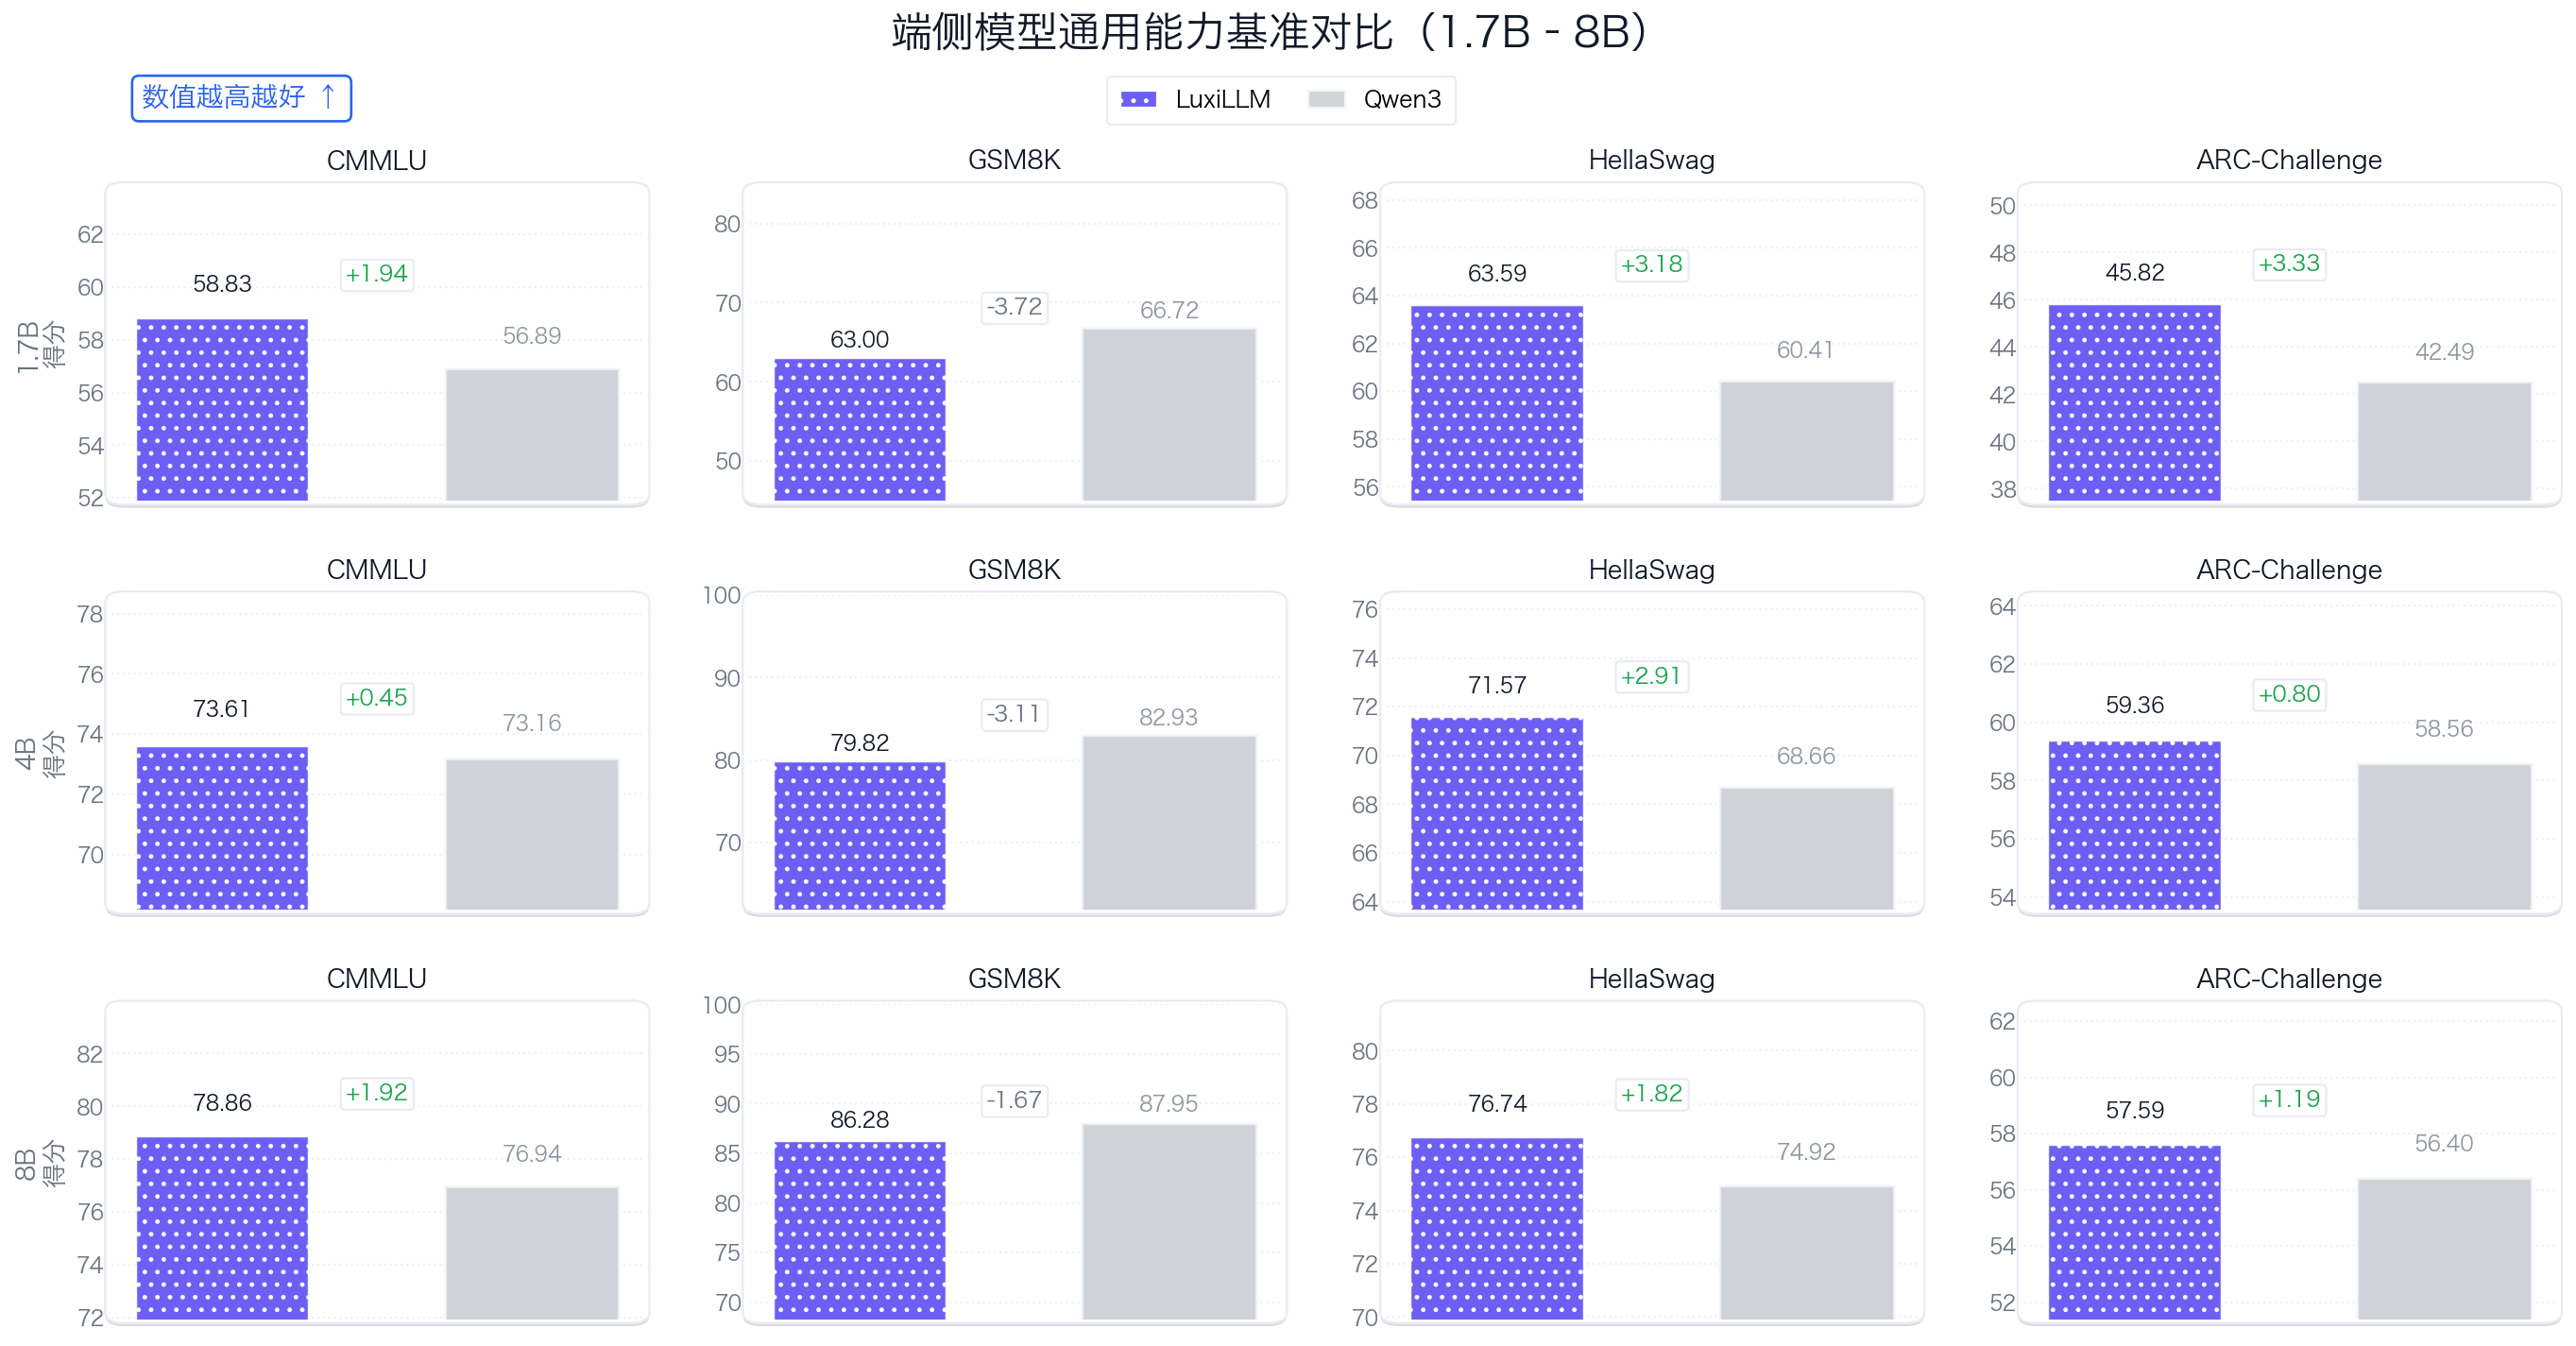

In [49]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm

# =========================
# Robust font setup for macOS
# =========================
def set_macos_chinese_font():
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC", "Noto Sans CJK JP",
        "Arial Unicode MS", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

chosen_font = set_macos_chinese_font()

# =========================
# Global style (web-card look)
# =========================
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "font.size": 12,
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
})

# =========================
# Data
# =========================
scales = [
    ("1.7B", ["LuxiLLM-1.7B", "Qwen3-1.7B"], {
        "cmmlu":         [58.83, 56.89],
        "gsm8k":         [63.00, 66.72],
        "hellaswag":     [63.59, 60.41],
        "arc_challenge": [45.82, 42.49],
    }),
    ("4B", ["LuxiLLM-4B", "Qwen3-4B"], {
        "cmmlu":         [73.61, 73.16],
        "gsm8k":         [79.82, 82.93],
        "hellaswag":     [71.57, 68.66],
        "arc_challenge": [59.36, 58.56],
    }),
    ("8B", ["LuxiLLM-8B", "Qwen3-8B"], {
        "cmmlu":         [78.86, 76.94],
        "gsm8k":         [86.28, 87.95],
        "hellaswag":     [76.74, 74.92],
        "arc_challenge": [57.59, 56.40],
    }),
]

tasks = ["cmmlu", "gsm8k", "hellaswag", "arc_challenge"]
task_titles = {
    "cmmlu": "CMMLU",
    "gsm8k": "GSM8K",
    "hellaswag": "HellaSwag",
    "arc_challenge": "ARC-Challenge",
}

# =========================
# Theme
# =========================
THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
    "good":      "#16A34A",
}

LUXI_COLOR = "#6D5EF5"
QWEN_GRAY  = "#D1D5DB"
QWEN_EDGE  = "#F3F4F6"
HATCH = {"Luxi": ".."}

# =========================
# Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    card = FancyBboxPatch(
        (0, 0), 1, 1,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.0,
        zorder=-2,
        clip_on=False,
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -1.5), alpha=0.14, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax):
    ax.grid(axis="y", linestyle=":", linewidth=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def infer_scale(vals):
    return "pct" if max(vals) > 1.5 else "prob"

# =========================
# Plot
# =========================
fig, axes = plt.subplots(nrows=len(scales), ncols=len(tasks), figsize=(17.2, 9.2))
fig.patch.set_facecolor(THEME["bg"])

bar_w = 0.56
x = np.array([0, 1])  # Luxi, Qwen

for r, (_, __, bench) in enumerate(scales):
    for c, task in enumerate(tasks):
        ax = axes[r, c]
        add_card(ax)
        beautify_axes(ax)

        luxi_v, qwen_v = bench[task]
        vals = [luxi_v, qwen_v]
        diff = luxi_v - qwen_v

        mode = infer_scale(vals)
        if mode == "pct":
            PAD_DEFAULT = 5.0
            PAD_GSM8K   = 18.0
            VAL_DY      = 0.8
            DELTA_DY    = 1.2
            y_cap = 100.0
            fmt = "{:.2f}"
        else:
            PAD_DEFAULT = 0.03
            PAD_GSM8K   = 0.18
            VAL_DY      = 0.010
            DELTA_DY    = 0.020
            y_cap = 1.0
            fmt = "{:.4f}"

        # Bars
        bars0 = ax.bar(
            x[0], luxi_v, width=bar_w,
            color=LUXI_COLOR, edgecolor="#FFFFFF",
            linewidth=1.1, alpha=0.92,
            hatch=HATCH.get("Luxi", None),
            zorder=3,
        )
        bars1 = ax.bar(
            x[1], qwen_v, width=bar_w,
            color=QWEN_GRAY, edgecolor=QWEN_EDGE,
            linewidth=1.0, alpha=0.70,
            zorder=2.6,
        )

        # Effects
        for rr in list(bars0):
            rr.set_path_effects([
                pe.withSimplePatchShadow(offset=(0, -1.1), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
                pe.Normal()
            ])
        for rr in list(bars1):
            rr.set_path_effects([
                pe.Stroke(linewidth=3.0, foreground="white", alpha=0.80),
                pe.Stroke(linewidth=1.1, foreground=QWEN_EDGE, alpha=1.0),
                pe.withSimplePatchShadow(offset=(0, -0.7), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                pe.Normal()
            ])

        # Values
        vmax = max(vals)
        ax.text(x[0], luxi_v + VAL_DY, fmt.format(luxi_v),
                ha="center", va="bottom", fontsize=10, color=THEME["text"], zorder=6)
        ax.text(x[1], qwen_v + VAL_DY, fmt.format(qwen_v),
                ha="center", va="bottom", fontsize=10, color=THEME["muted"], alpha=0.75, zorder=6)

        # Delta
        sign = "+" if diff >= 0 else ""
        delta_color = THEME["good"] if diff >= 0 else THEME["muted"]
        ax.text(
            0.5, vmax + DELTA_DY,
            f"{sign}{diff:.2f}" if mode == "pct" else f"{sign}{diff:.4f}",
            ha="center", va="bottom",
            fontsize=10.5, fontweight="bold",
            color=delta_color,
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=7
        )

        # Y-limits
        pad = PAD_GSM8K if task == "gsm8k" else PAD_DEFAULT
        vmin, vmax2 = min(vals), max(vals)
        ax.set_ylim(max(0.0, vmin - pad), min(y_cap, vmax2 + pad))

        # Titles per cell
        ax.set_title(task_titles[task], color=THEME["text"], pad=8, fontweight="bold")

        # No x labels
        ax.set_xticks([])
        ax.set_xticklabels([])

        if c == 0:
            ax.set_ylabel(f"{scales[r][0]}\n得分", color=THEME["muted"], fontweight="bold")
        else:
            ax.set_ylabel("")

# =========================
# Legend (move up a bit)
# =========================
legend_handles = [
    Patch(facecolor=LUXI_COLOR, edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get("Luxi", None), label="LuxiLLM"),
    Patch(facecolor=QWEN_GRAY, edgecolor=QWEN_EDGE, linewidth=1.0, label="Qwen3"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.962),   # ✅ legend slightly higher
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

# =========================
# Title + callout (move both up, title bigger)
# =========================
fig.text(
    0.5, 0.975, "端侧模型通用能力基准对比（1.7B–8B）",
    ha="center", fontsize=20, fontweight="bold", color=THEME["text"]  # ✅ bigger
)

fig.text(
    0.1, 0.938, "数值越高越好 ↑",
    ha="center", va="center",
    fontsize=13.0, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(
        boxstyle="round,pad=0.35,rounding_size=0.25",
        facecolor="white",
        edgecolor=THEME["accent"],
        linewidth=1.2,
        alpha=0.98
    )
)

# ✅ leave more space at top to avoid overlap
fig.subplots_adjust(left=0.05, right=0.99, bottom=0.06, top=0.875, wspace=0.20, hspace=0.30)

print("Using font:", chosen_font)

plt.savefig("benchmark_grid_cn_gray_qwen.png", dpi=600, bbox_inches="tight")
plt.savefig("benchmark_grid_cn_gray_qwen.pdf", dpi=600, bbox_inches="tight")
# plt.show()

Using font: Hiragino Sans GB


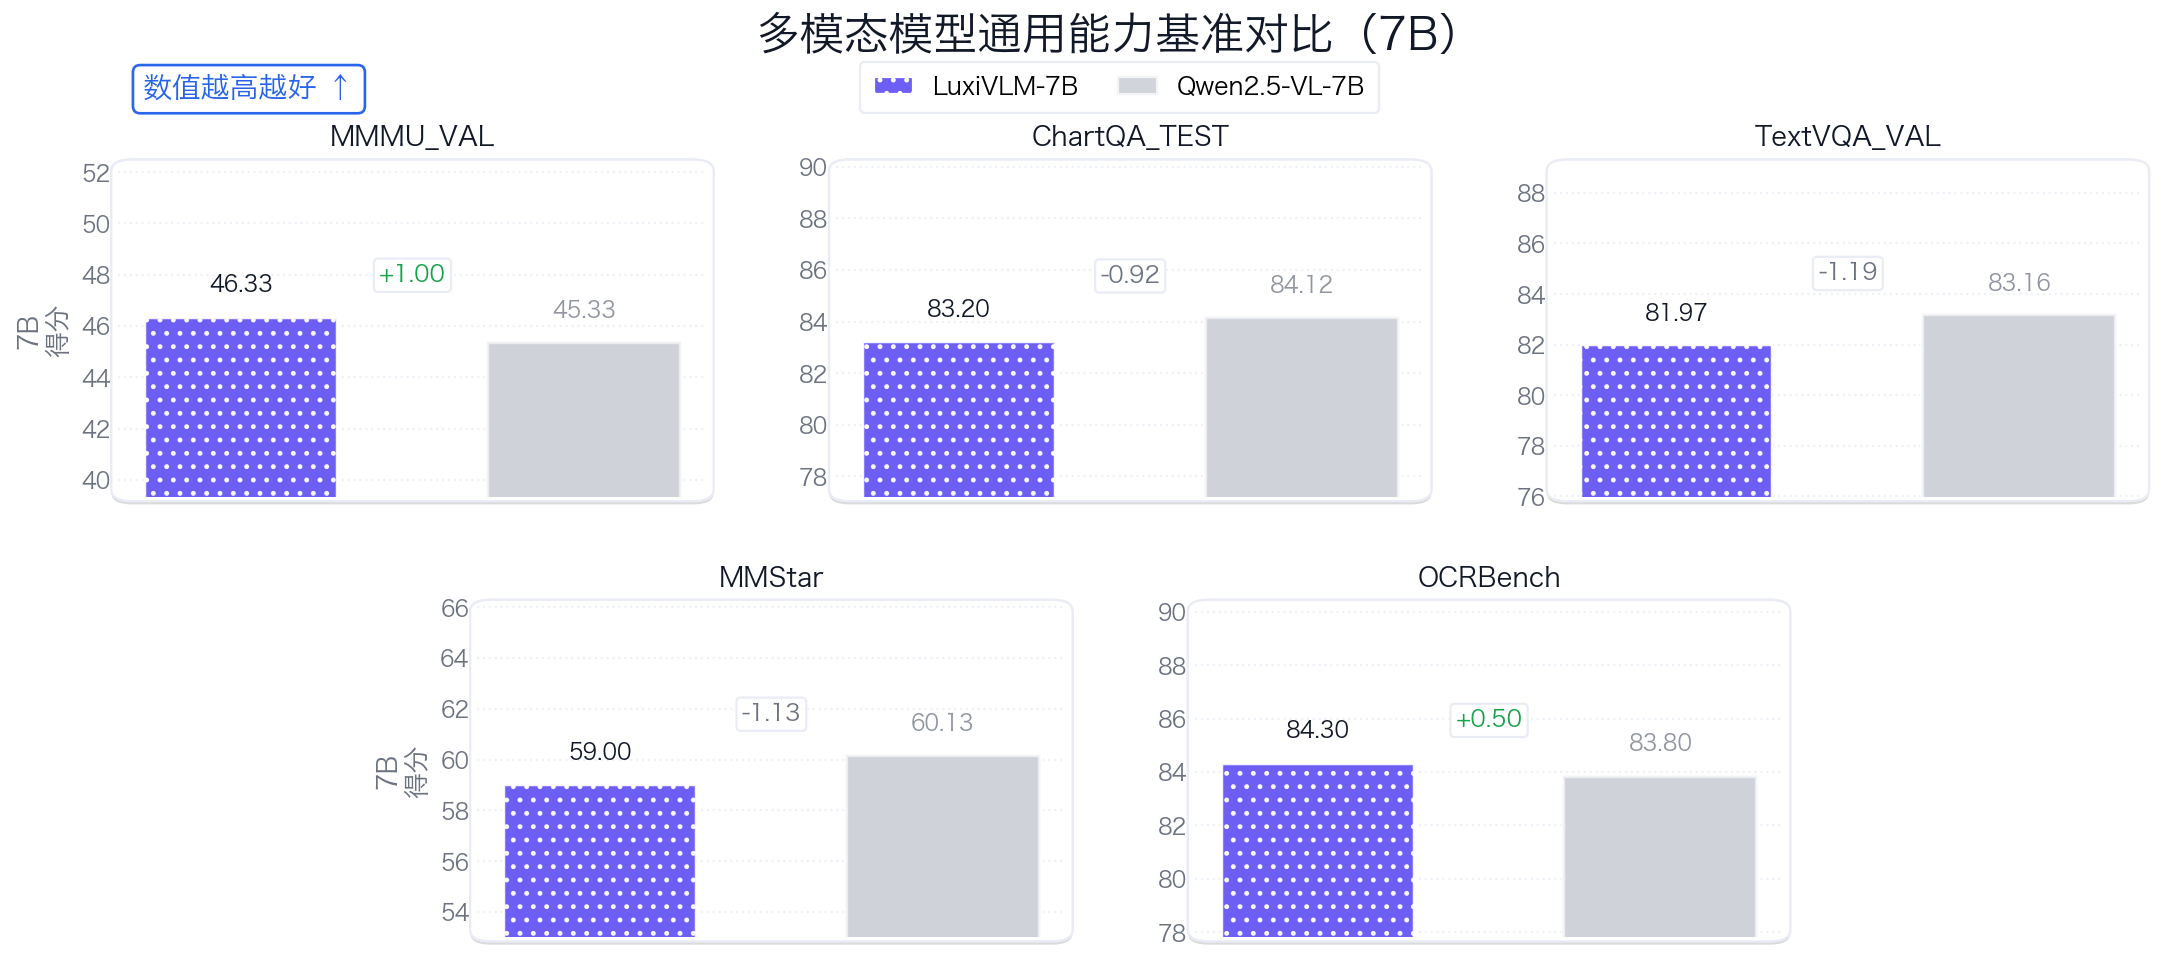

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm

# =========================
# Robust font setup for macOS
# =========================
def set_macos_chinese_font():
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC",
        "Arial Unicode MS", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

chosen_font = set_macos_chinese_font()

# =========================
# Global style (web-card look)
# =========================
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "font.size": 12,
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
})

# =========================
# Data (from your screenshot)
# - Only keep 5 benchmarks, ignore other columns
# =========================
SCALE_TITLE = "7B"
PRIMARY_MODEL  = "LuxiVLM-7B"
BASELINE_MODEL = "Qwen2.5-VL-7B"

bench = {
    "mmmu_dev_val": [46.33, 45.33],
    "chartqa_test": [83.20, 84.12],
    "textvqa_val":  [81.97, 83.16],
    "mmstar":      [59.00, 60.13],
    "ocrbench":    [84.30, 83.80],
}

tasks = ["mmmu_dev_val", "chartqa_test", "textvqa_val", "mmstar", "ocrbench"]
task_titles = {
    "mmmu_dev_val": "MMMU_VAL",
    "chartqa_test": "ChartQA_TEST",
    "textvqa_val":  "TextVQA_VAL",
    "mmstar":       "MMStar",
    "ocrbench":     "OCRBench",
}

# =========================
# Theme
# =========================
THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
    "good":      "#16A34A",
}

PRIMARY_COLOR = "#6D5EF5"   # highlight (your model)
BASELINE_GRAY = "#D1D5DB"   # baseline (qwen)
BASELINE_EDGE = "#F3F4F6"
HATCH = {"Primary": ".."}

# =========================
# Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    card = FancyBboxPatch(
        (0, 0), 1, 1,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.0,
        zorder=-2,
        clip_on=False,
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -1.5), alpha=0.14, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax):
    ax.grid(axis="y", linestyle=":", linewidth=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def infer_scale(vals):
    # your metrics are percentages (0-100)
    return "pct" if max(vals) > 1.5 else "prob"

# =========================
# Plot (5 benchmarks -> 2 rows)
# layout: 2x3, last cell hidden
# =========================
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(13.6, 6.2))
fig.patch.set_facecolor(THEME["bg"])

bar_w = 0.56
x = np.array([0, 1])  # Primary, Baseline

for i, task in enumerate(tasks):
    r, c = divmod(i, 3)
    ax = axes[r, c]
    add_card(ax)
    beautify_axes(ax)

    primary_v, baseline_v = bench[task]
    vals = [primary_v, baseline_v]
    diff = primary_v - baseline_v

    mode = infer_scale(vals)
    if mode == "pct":
        PAD = 6.0
        VAL_DY = 0.8
        DELTA_DY = 1.2
        y_cap = 100.0
        fmt = "{:.2f}"
    else:
        PAD = 0.03
        VAL_DY = 0.010
        DELTA_DY = 0.020
        y_cap = 1.0
        fmt = "{:.4f}"

    # Bars
    b0 = ax.bar(
        x[0], primary_v, width=bar_w,
        color=PRIMARY_COLOR, edgecolor="#FFFFFF",
        linewidth=1.1, alpha=0.92,
        hatch=HATCH.get("Primary", None),
        zorder=3,
    )
    b1 = ax.bar(
        x[1], baseline_v, width=bar_w,
        color=BASELINE_GRAY, edgecolor=BASELINE_EDGE,
        linewidth=1.0, alpha=0.70,
        zorder=2.6,
    )

    # Effects
    for rr in list(b0):
        rr.set_path_effects([
            pe.withSimplePatchShadow(offset=(0, -1.1), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
            pe.Normal()
        ])
    for rr in list(b1):
        rr.set_path_effects([
            pe.Stroke(linewidth=3.0, foreground="white", alpha=0.80),
            pe.Stroke(linewidth=1.1, foreground=BASELINE_EDGE, alpha=1.0),
            pe.withSimplePatchShadow(offset=(0, -0.7), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
            pe.Normal()
        ])

    # Values
    vmax = max(vals)
    ax.text(x[0], primary_v + VAL_DY, fmt.format(primary_v),
            ha="center", va="bottom", fontsize=10, color=THEME["text"], zorder=6)
    ax.text(x[1], baseline_v + VAL_DY, fmt.format(baseline_v),
            ha="center", va="bottom", fontsize=10, color=THEME["muted"], alpha=0.75, zorder=6)

    # Delta
    sign = "+" if diff >= 0 else ""
    delta_color = THEME["good"] if diff >= 0 else THEME["muted"]
    ax.text(
        0.5, vmax + DELTA_DY,
        f"{sign}{diff:.2f}" if mode == "pct" else f"{sign}{diff:.4f}",
        ha="center", va="bottom",
        fontsize=10.5, fontweight="bold",
        color=delta_color,
        bbox=dict(
            boxstyle="round,pad=0.22,rounding_size=0.18",
            facecolor="white",
            edgecolor=THEME["card_edge"],
            linewidth=1.0,
            alpha=0.98
        ),
        zorder=7
    )

    # Y-limits
    vmin, vmax2 = min(vals), max(vals)
    ax.set_ylim(max(0.0, vmin - PAD), min(y_cap, vmax2 + PAD))

    # Titles
    ax.set_title(task_titles[task], color=THEME["text"], pad=8, fontweight="bold")

    # No x labels
    ax.set_xticks([])
    ax.set_xticklabels([])

    # Y label only on left column
    if c == 0:
        ax.set_ylabel(f"{SCALE_TITLE}\n得分", color=THEME["muted"], fontweight="bold")
    else:
        ax.set_ylabel("")

# Hide the 6th empty cell (2x3 -> last one)
axes[1, 2].axis("off")

# =========================
# Legend
# =========================
legend_handles = [
    Patch(facecolor=PRIMARY_COLOR, edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get("Primary", None), label=PRIMARY_MODEL),
    Patch(facecolor=BASELINE_GRAY, edgecolor=BASELINE_EDGE, linewidth=1.0, label=BASELINE_MODEL),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.52, 0.975),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

# =========================
# Title + callout
# =========================
fig.text(
    0.52, 0.975, f"多模态模型通用能力基准对比（{SCALE_TITLE}）",
    ha="center", fontsize=20, fontweight="bold", color=THEME["text"]
)
fig.text(
    0.12, 0.935, "数值越高越好 ↑",
    ha="center", va="center",
    fontsize=13.0, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(
        boxstyle="round,pad=0.35,rounding_size=0.25",
        facecolor="white",
        edgecolor=THEME["accent"],
        linewidth=1.2,
        alpha=0.98
    )
)

# Layout
fig.subplots_adjust(left=0.06, right=0.99, bottom=0.08, top=0.86, wspace=0.22, hspace=0.32)

# =========================
# Center the 2nd row visually (保持第二行居中的数学平移逻辑)
# =========================
pos0 = axes[1, 0].get_position()
pos1 = axes[1, 1].get_position()
# 计算两个相邻子图之间的中心偏移量
shift = (pos1.x0 - pos0.x0) / 2

# 向右平移第二行的两个图表
axes[1, 0].set_position([pos0.x0 + shift, pos0.y0, pos0.width, pos0.height])
axes[1, 1].set_position([pos1.x0 + shift, pos1.y0, pos1.width, pos1.height])

print("Using font:", chosen_font)

plt.savefig("benchmark_7b_5tasks_grid.png", dpi=600, bbox_inches="tight")
plt.savefig("benchmark_7b_5tasks_grid.pdf", dpi=600, bbox_inches="tight")
plt.show()

Using font: Hiragino Sans GB


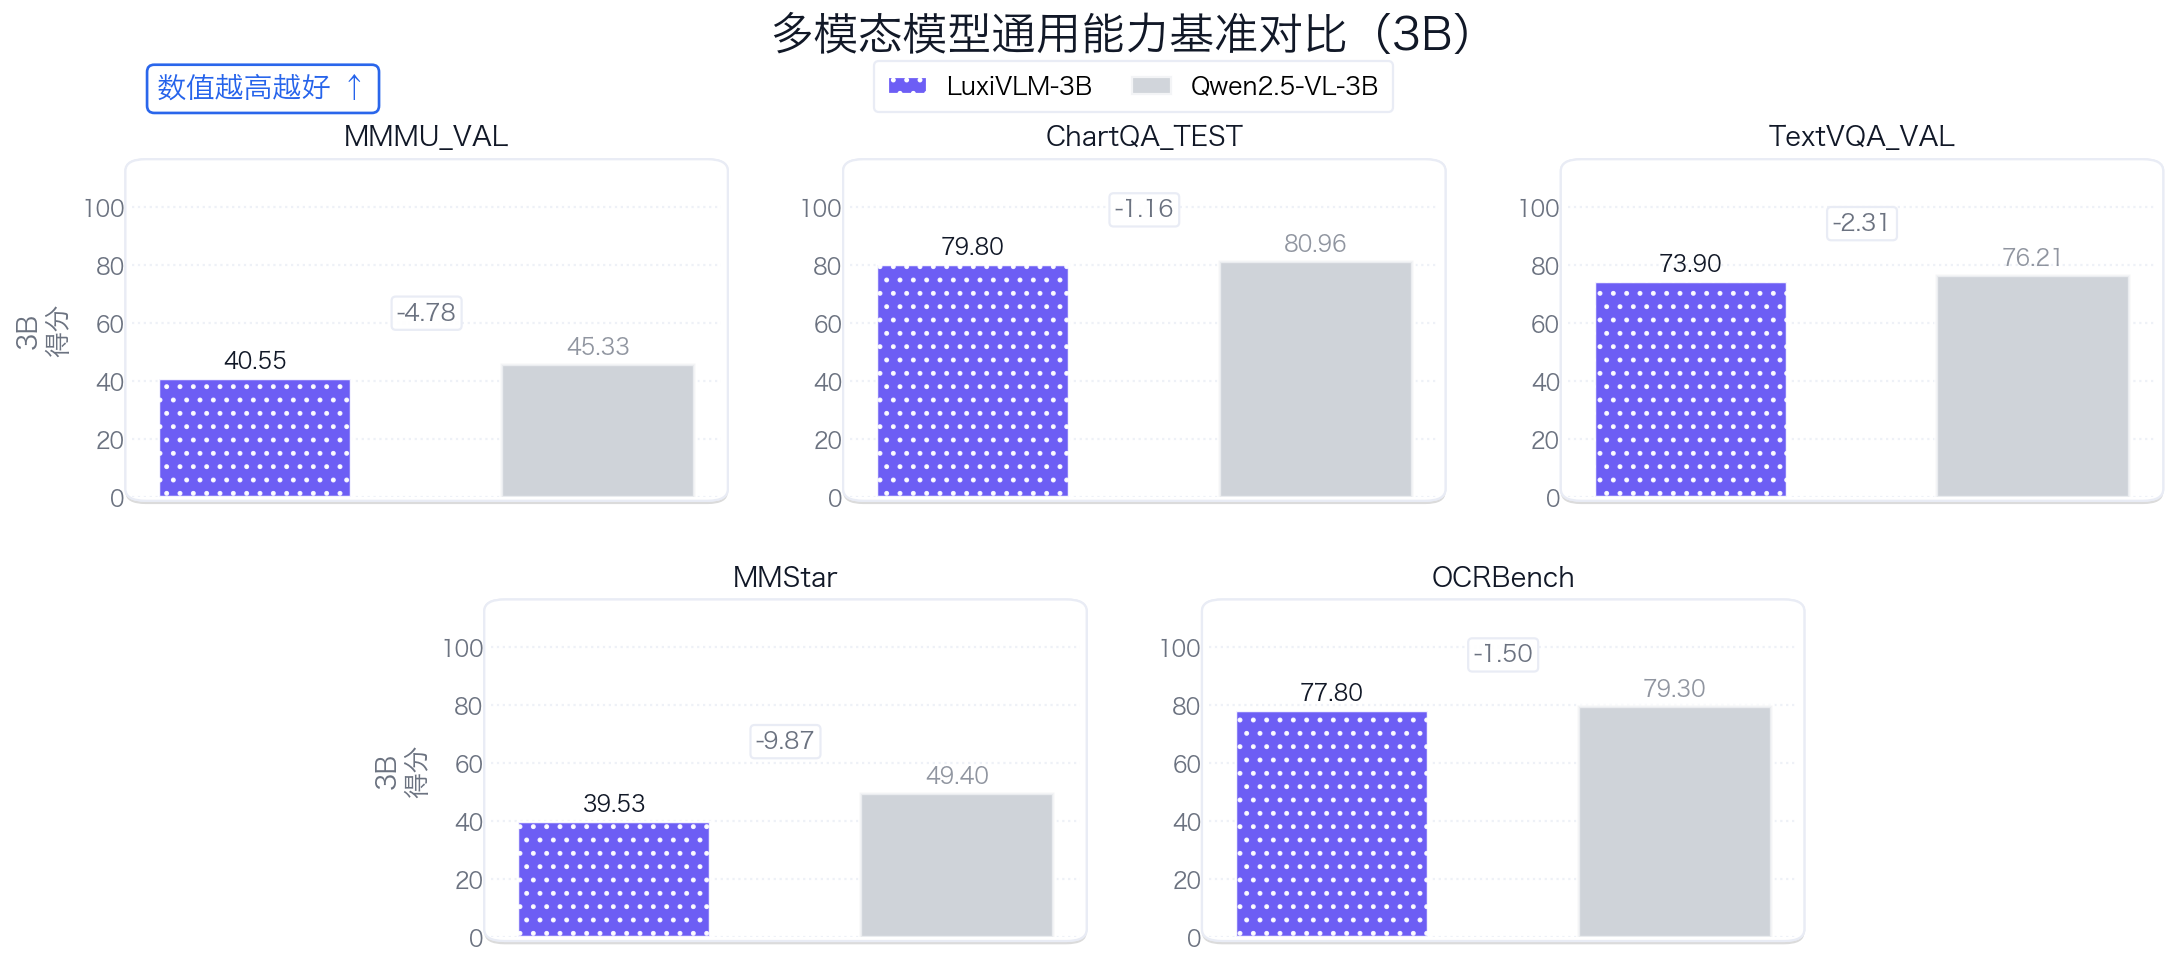

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm

# =========================
# Robust font setup for macOS
# =========================
def set_macos_chinese_font():
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC",
        "Arial Unicode MS", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

chosen_font = set_macos_chinese_font()

# =========================
# Global style (web-card look)
# =========================
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "font.size": 12,
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
})

# =========================
# Data (from your screenshot)
# - Only keep 5 benchmarks, ignore other columns
# =========================
SCALE_TITLE = "3B"
PRIMARY_MODEL  = "LuxiVLM-3B"
BASELINE_MODEL = "Qwen2.5-VL-3B"

bench = {
    "mmmu_dev_val": [40.55, 45.33],
    "chartqa_test": [79.8, 80.96],
    "textvqa_val":  [73.904, 76.212],
    "mmstar":       [39.53, 49.4],
    "ocrbench":     [77.8, 79.3],
}

tasks = ["mmmu_dev_val", "chartqa_test", "textvqa_val", "mmstar", "ocrbench"]
task_titles = {
    "mmmu_dev_val": "MMMU_VAL",
    "chartqa_test": "ChartQA_TEST",
    "textvqa_val":  "TextVQA_VAL",
    "mmstar":       "MMStar",
    "ocrbench":     "OCRBench",
}

# =========================
# Theme
# =========================
THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
    "good":      "#16A34A",
}

PRIMARY_COLOR = "#6D5EF5"   # highlight (your model)
BASELINE_GRAY = "#D1D5DB"   # baseline (qwen)
BASELINE_EDGE = "#F3F4F6"
HATCH = {"Primary": ".."}

# =========================
# Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    card = FancyBboxPatch(
        (0, 0), 1, 1,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.0,
        zorder=-2,
        clip_on=False,
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -1.5), alpha=0.14, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax):
    ax.grid(axis="y", linestyle=":", linewidth=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def infer_scale(vals):
    # your metrics are percentages (0-100)
    return "pct" if max(vals) > 1.5 else "prob"

# =========================
# Plot (5 benchmarks -> 2 rows)
# layout: 2x3, last cell hidden
# =========================
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(13.6, 6.2))
fig.patch.set_facecolor(THEME["bg"])

bar_w = 0.56
x = np.array([0, 1])  # Primary, Baseline

for i, task in enumerate(tasks):
    r, c = divmod(i, 3)
    ax = axes[r, c]
    add_card(ax)
    beautify_axes(ax)

    primary_v, baseline_v = bench[task]
    vals = [primary_v, baseline_v]
    diff = primary_v - baseline_v

    mode = infer_scale(vals)
    # =========================
    # 核心改动 1：调整文本悬浮高度以适应更大的 Y 轴量程
    # =========================
    if mode == "pct":
        VAL_DY = 2.0
        DELTA_DY = 14.0
        fmt = "{:.2f}"
    else:
        VAL_DY = 0.02
        DELTA_DY = 0.14
        fmt = "{:.4f}"

    # Bars
    b0 = ax.bar(
        x[0], primary_v, width=bar_w,
        color=PRIMARY_COLOR, edgecolor="#FFFFFF",
        linewidth=1.1, alpha=0.92,
        hatch=HATCH.get("Primary", None),
        zorder=3,
    )
    b1 = ax.bar(
        x[1], baseline_v, width=bar_w,
        color=BASELINE_GRAY, edgecolor=BASELINE_EDGE,
        linewidth=1.0, alpha=0.70,
        zorder=2.6,
    )

    # Effects
    for rr in list(b0):
        rr.set_path_effects([
            pe.withSimplePatchShadow(offset=(0, -1.1), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
            pe.Normal()
        ])
    for rr in list(b1):
        rr.set_path_effects([
            pe.Stroke(linewidth=3.0, foreground="white", alpha=0.80),
            pe.Stroke(linewidth=1.1, foreground=BASELINE_EDGE, alpha=1.0),
            pe.withSimplePatchShadow(offset=(0, -0.7), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
            pe.Normal()
        ])

    # Values
    vmax = max(vals)
    ax.text(x[0], primary_v + VAL_DY, fmt.format(primary_v),
            ha="center", va="bottom", fontsize=10, color=THEME["text"], zorder=6)
    ax.text(x[1], baseline_v + VAL_DY, fmt.format(baseline_v),
            ha="center", va="bottom", fontsize=10, color=THEME["muted"], alpha=0.75, zorder=6)

    # Delta
    sign = "+" if diff >= 0 else ""
    delta_color = THEME["good"] if diff >= 0 else THEME["muted"]
    ax.text(
        0.5, vmax + DELTA_DY,
        f"{sign}{diff:.2f}" if mode == "pct" else f"{sign}{diff:.4f}",
        ha="center", va="bottom",
        fontsize=10.5, fontweight="bold",
        color=delta_color,
        bbox=dict(
            boxstyle="round,pad=0.22,rounding_size=0.18",
            facecolor="white",
            edgecolor=THEME["card_edge"],
            linewidth=1.0,
            alpha=0.98
        ),
        zorder=7
    )

    # =========================
    # 核心改动 2：强制 Y 轴从 0 开始，拉高上限压缩视觉差距
    # =========================
    if mode == "pct":
        ax.set_ylim(0, 115) 
    else:
        ax.set_ylim(0, 1.15)

    # Titles
    ax.set_title(task_titles[task], color=THEME["text"], pad=8, fontweight="bold")

    # No x labels
    ax.set_xticks([])
    ax.set_xticklabels([])

    # Y label only on left column
    if c == 0:
        ax.set_ylabel(f"{SCALE_TITLE}\n得分", color=THEME["muted"], fontweight="bold")
    else:
        ax.set_ylabel("")

# Hide the 6th empty cell (2x3 -> last one)
axes[1, 2].axis("off")

# =========================
# Legend
# =========================
legend_handles = [
    Patch(facecolor=PRIMARY_COLOR, edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get("Primary", None), label=PRIMARY_MODEL),
    Patch(facecolor=BASELINE_GRAY, edgecolor=BASELINE_EDGE, linewidth=1.0, label=BASELINE_MODEL),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.52, 0.975),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

# =========================
# Title + callout
# =========================
fig.text(
    0.52, 0.975, f"多模态模型通用能力基准对比（{SCALE_TITLE}）",
    ha="center", fontsize=20, fontweight="bold", color=THEME["text"]
)
fig.text(
    0.12, 0.935, "数值越高越好 ↑",
    ha="center", va="center",
    fontsize=13.0, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(
        boxstyle="round,pad=0.35,rounding_size=0.25",
        facecolor="white",
        edgecolor=THEME["accent"],
        linewidth=1.2,
        alpha=0.98
    )
)

# Layout
fig.subplots_adjust(left=0.06, right=0.99, bottom=0.08, top=0.86, wspace=0.22, hspace=0.32)

# =========================
# 保持第二行居中的数学平移逻辑
# =========================
pos0 = axes[1, 0].get_position()
pos1 = axes[1, 1].get_position()
shift = (pos1.x0 - pos0.x0) / 2

axes[1, 0].set_position([pos0.x0 + shift, pos0.y0, pos0.width, pos0.height])
axes[1, 1].set_position([pos1.x0 + shift, pos1.y0, pos1.width, pos1.height])

print("Using font:", chosen_font)

plt.savefig("benchmark_3b_5tasks_grid.png", dpi=600, bbox_inches="tight")
plt.savefig("benchmark_3b_5tasks_grid.pdf", dpi=600, bbox_inches="tight")
plt.show()

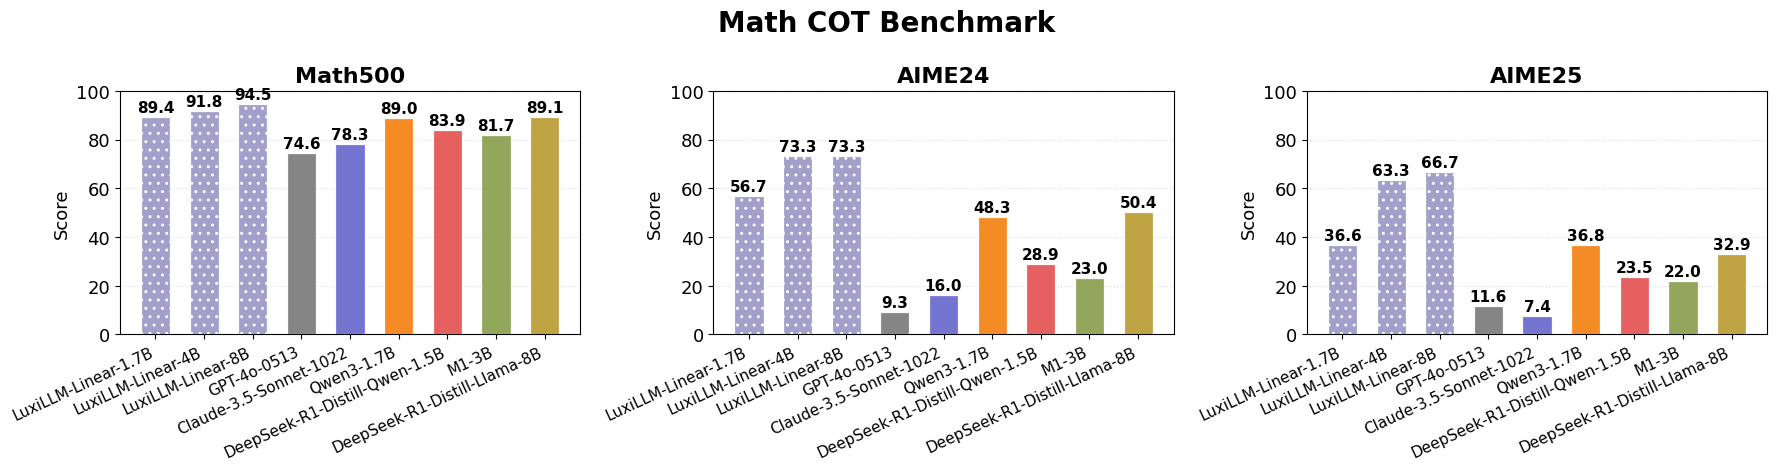

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# 1) 模型顺序（与表一致）——加入 LuxiLLM-8B
models = [
    'LuxiLLM-Linear-1.7B',
    'LuxiLLM-Linear-4B',
    'LuxiLLM-Linear-8B',          # NEW
    'GPT-4o-0513',
    'Claude-3.5-Sonnet-1022',
    'Qwen3-1.7B',
    'DeepSeek-R1-Distill-Qwen-1.5B',
    'M1-3B',
    'DeepSeek-R1-Distill-Llama-8B',
]

# 2) 指标数据（按上面顺序）——加入 LuxiLLM-Linear-8B 的三项数据
bench = {
    'Math500':  [89.4, 91.8, 94.5, 74.6, 78.3, 89.0, 83.9, 81.7, 89.1],
    'AIME24':   [56.7, 73.3, 73.3,  9.3, 16.0, 48.3, 28.9, 23.0, 50.4],
    'AIME25':   [36.6, 63.3, 66.7, 11.6,  7.4, 36.8, 23.5, 22.0, 32.9],
}

# 3) 颜色映射（保持前图对应；LuxiLLM-Linear 系列同色）
COLOR = {
    'Qwen3-1.7B': '#F58518',
    'LuxiLLM-Linear-1.7B': '#9E9AC8',
    'LuxiLLM-Linear-4B':   '#9E9AC8',
    'LuxiLLM-Linear-8B':   '#9E9AC8',   # NEW: 同色
    'GPT-4o-0513':                  '#7F7F7F',
    'Claude-3.5-Sonnet-1022':       '#6B6ECF',
    'DeepSeek-R1-Distill-Qwen-1.5B':'#E45756',
    'M1-3B':                         '#8CA252',
    'DeepSeek-R1-Distill-Llama-8B':  '#BD9E39',
}

# 统一 hatch 风格：LuxiLLM-Linear 全部打点
HATCH = {
    'LuxiLLM-Linear-1.7B': '..',
    'LuxiLLM-Linear-4B':   '..',
    'LuxiLLM-Linear-8B':   '..',   # NEW
}

# 4) 画图：一行三个面板，无图例
tasks = ['Math500', 'AIME24', 'AIME25']
fig = plt.figure(figsize=(18, 4.8))
x = np.arange(len(models))
bar_w = 0.6

for i, task in enumerate(tasks, 1):
    ax = plt.subplot(1, 3, i)
    vals = bench[task]
    for j, m in enumerate(models):
        v = vals[j]
        if np.isnan(v):  # “–” 不画柱
            continue
        ax.bar(
            x[j], v, width=bar_w,
            color=COLOR[m],
            edgecolor='white', linewidth=0.9, alpha=0.95,
            hatch=HATCH.get(m, None)
        )
        ax.text(j, v + 0.8, f'{v:.1f}', ha='center', va='bottom',
                fontsize=11, fontweight='bold')

    ax.set_title(task, fontsize=16, fontweight='bold')
    ax.set_ylabel('Score', fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=25, ha='right', fontsize=11)
    ax.set_ylim(0, 100)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)

fig.suptitle('Math COT Benchmark', fontsize=20, fontweight='bold', y=0.98)
plt.tight_layout()

plt.savefig('Math COT Benchmark.png', dpi=600, bbox_inches='tight')
plt.savefig('Math COT Benchmark.pdf', dpi=600, bbox_inches='tight')
plt.show()

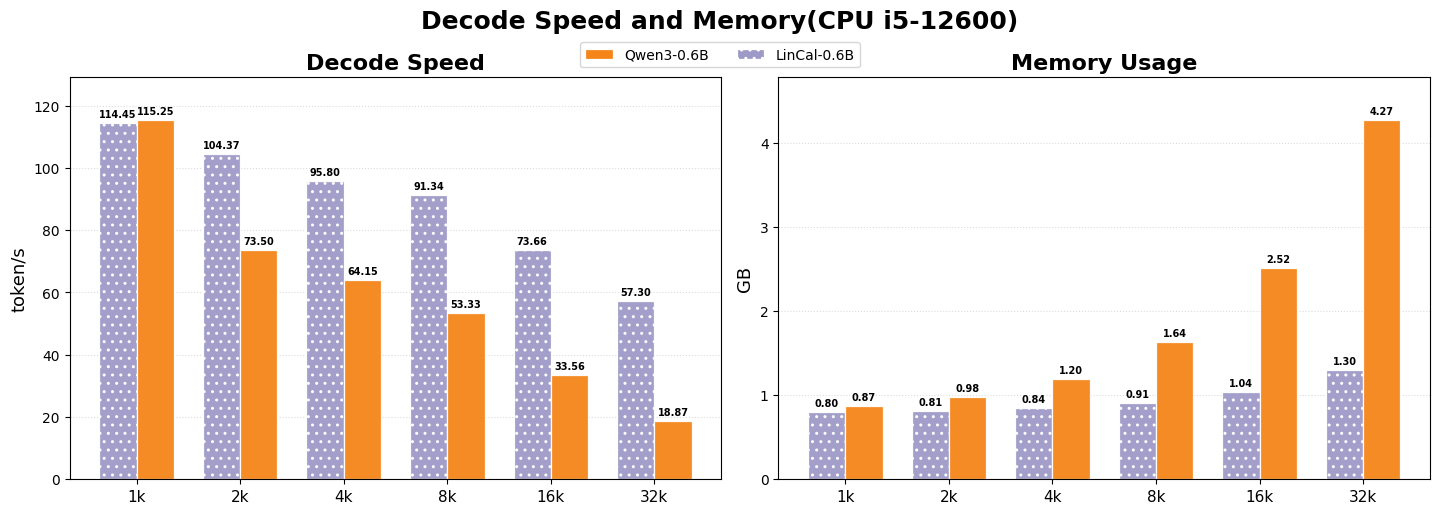

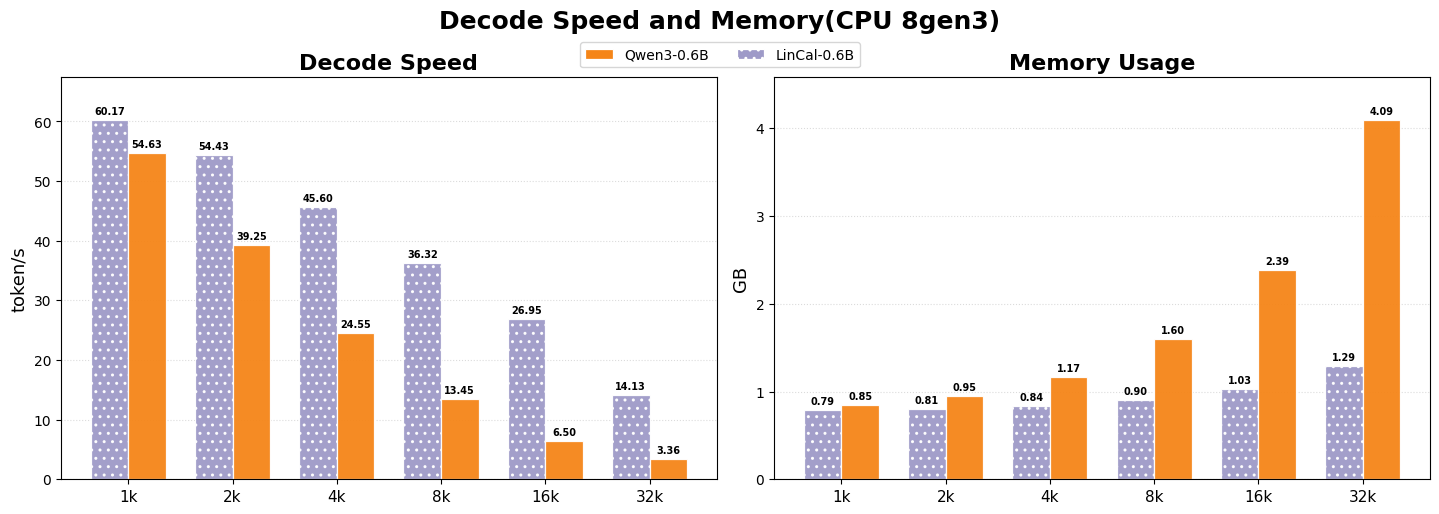

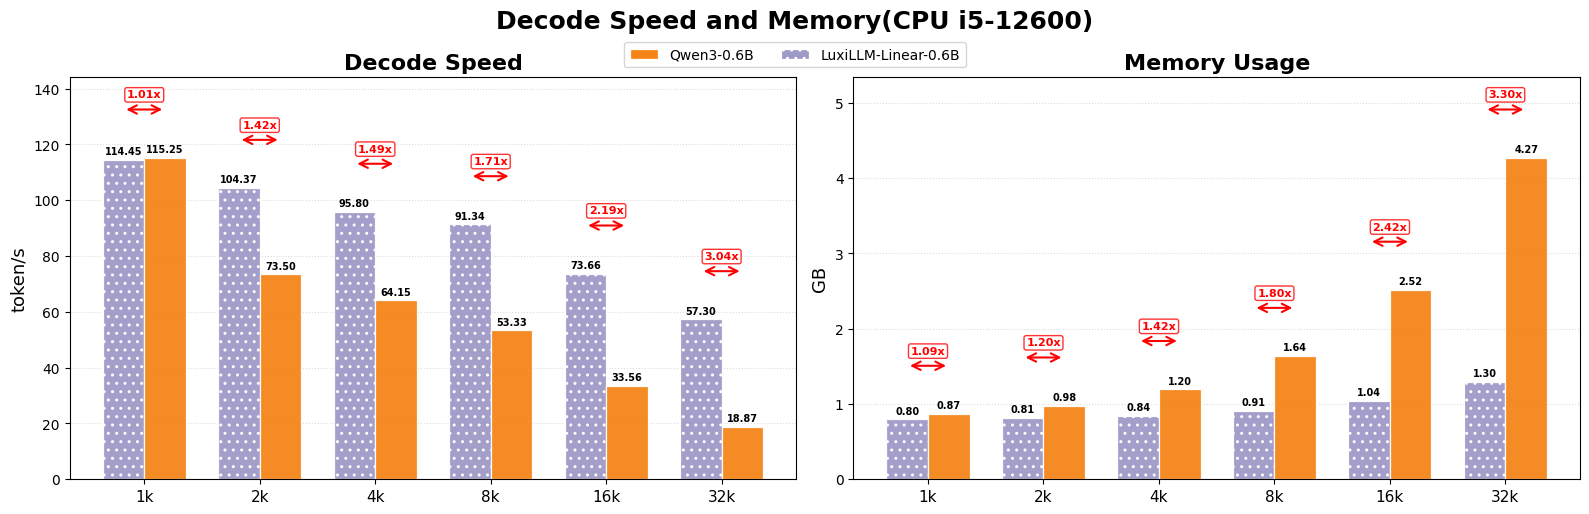

In [95]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, FancyArrowPatch

# ===== 1) 模型、颜色、hatch（与前面保持一致） =====
models = ['LuxiLLM-Linear-0.6B','Qwen3-0.6B']
COLOR = {
    'Qwen3-0.6B': '#F58518',
    'LuxiLLM-Linear-0.6B': '#9E9AC8',
}
HATCH = {'LuxiLLM-Linear-0.6B': '..'}  # LinCal 打点

# ===== 2) 数据（按"速度/内存占用(GB)"录入）=====
contexts = ['1k','2k','4k','8k','16k','32k']
pairs = {
    'LuxiLLM-Linear-0.6B': [
        (114.45, 0.798),
        (104.37, 0.813),
        (95.80,  0.845),
        (91.34,  0.910),
        (73.66,  1.039),
        (57.30,  1.296),
    ],
    'Qwen3-0.6B': [
        (115.25, 0.867),
        (73.50,  0.977),
        (64.15,  1.196),
        (53.33,  1.636),
        (33.56,  2.515),
        (18.87,  4.271),
    ],
}

# 把 pairs 拆成速度矩阵与内存矩阵
speed = np.array([[p[0] for p in pairs[m]] for m in models])
mem   = np.array([[p[1] for p in pairs[m]] for m in models])

# ===== 3) 画图：两列并排（左：速度；右：内存）=====
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))  # 增加宽度给箭头留空间
width = 0.36
x = np.arange(len(contexts))

def draw_grouped(ax, values, ylabel, is_speed=True):
    # 绘制柱状图
    bars_list = []
    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        bars = ax.bar(x + off, values[i], width=width,
                      color=COLOR[m], edgecolor='white', linewidth=0.9, alpha=0.95,
                      hatch=HATCH.get(m, None))
        bars_list.append(bars)
        
        # 数值标注
        for rect, v in zip(bars, values[i]):
            text_offset = values.max() * 0.01
            ax.text(rect.get_x() + rect.get_width()/2, 
                   rect.get_height() + text_offset,
                   f'{v:.2f}', 
                   ha='center', 
                   va='bottom', 
                   fontsize=7, 
                   fontweight='bold')
    
    # 添加红色箭头和倍数比较
    for j in range(len(contexts)):
        # 计算两个柱状图的值
        val1 = values[0][j]  # LinCal
        val2 = values[1][j]  # Qwen3
        
        # 计算倍数（总是用较大的值除以较小的值）
        if val1 > val2:
            ratio = val1 / val2
            higher_idx, lower_idx = 0, 1
        else:
            ratio = val2 / val1
            higher_idx, lower_idx = 1, 0
        
        # 箭头位置
        x_center = x[j]
        higher_val = max(val1, val2)
        lower_val = min(val1, val2)
        
        # 箭头起始和结束位置
        arrow_start = x_center + (higher_idx - 0.5) * width
        arrow_end = x_center + (lower_idx - 0.5) * width
        
        # 箭头高度（在最高柱状图上方）
        arrow_y = higher_val + values.max() * 0.15
        
        # 绘制箭头
        arrow = FancyArrowPatch(
            (arrow_start, arrow_y), 
            (arrow_end, arrow_y),
            arrowstyle='<->', 
            color='red', 
            linewidth=1.5,
            mutation_scale=15
        )
        ax.add_patch(arrow)
        
        # 添加倍数文本
        ratio_text = f'{ratio:.2f}x'
        ax.text(x_center, arrow_y + values.max() * 0.03, 
               ratio_text, 
               ha='center', 
               va='bottom', 
               fontsize=8, 
               fontweight='bold',
               color='red',
               bbox=dict(boxstyle="round,pad=0.2", facecolor='white', edgecolor='red', alpha=0.8))
    
    ax.set_ylabel(ylabel, fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(contexts, rotation=0, fontsize=11)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)
    ymax = values.max() * (1 + 0.25)  # 增加上限给箭头留空间
    ax.set_ylim(0, ymax)

# 左：decode 速度
axes[0].set_title('Decode Speed', fontsize=16, fontweight='bold')
draw_grouped(axes[0], speed, 'token/s', is_speed=True)

# 右：内存占用
axes[1].set_title('Memory Usage', fontsize=16, fontweight='bold')
draw_grouped(axes[1], mem, 'GB', is_speed=False)

# ===== 顶部统一图例 =====
legend_handles = [
    Patch(facecolor=COLOR['Qwen3-0.6B'], edgecolor='white', linewidth=0.9, label='Qwen3-0.6B'),
    Patch(facecolor=COLOR['LuxiLLM-Linear-0.6B'], edgecolor='white', linewidth=0.9, hatch='..', label='LuxiLLM-Linear-0.6B'),
]
fig.legend(handles=legend_handles, loc='upper center', ncol=2, frameon=True, fancybox=True, bbox_to_anchor=(0.5, 0.93))

# 总标题 & 布局与导出
fig.suptitle('Decode Speed and Memory(CPU i5-12600)', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()

plt.savefig('decode_speed_and_memoryCPU.png', dpi=600, bbox_inches='tight')
plt.savefig('decode_speed_and_memoryCPU.pdf', dpi=600, bbox_inches='tight')
plt.show()

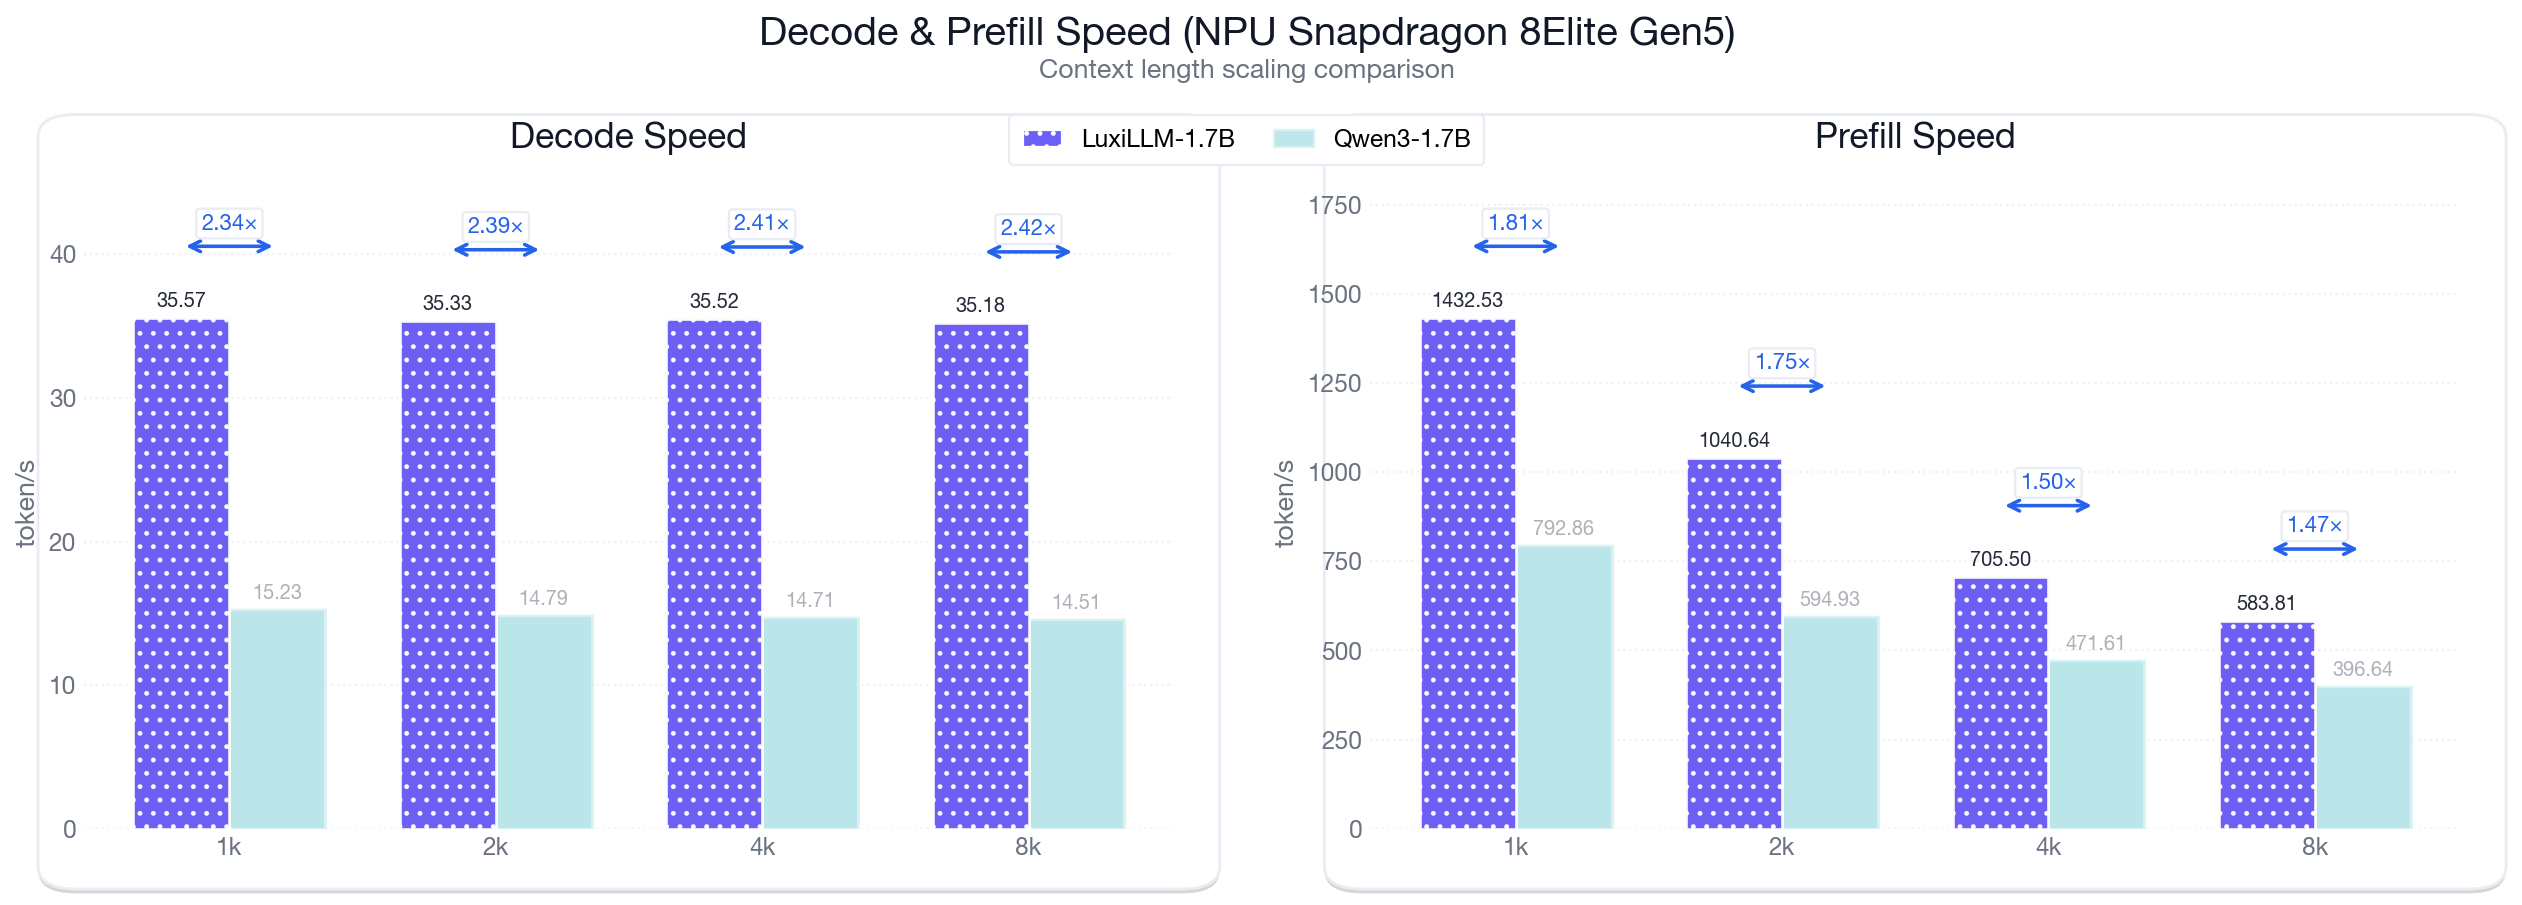

In [50]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "font.family": "sans-serif",
    "font.sans-serif": ["PingFang SC", "SF Pro Display", "Helvetica Neue", "Arial Unicode MS", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# =========================
# Helpers: "fade/blur-like" color treatment
# =========================
def hex_to_rgb01(h):
    h = h.lstrip("#")
    return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)]) / 255.0

def mix_with_white(hex_color, mix=0.68):
    """
    mix: 0~1, higher -> closer to white (more "hazy")
    """
    rgb = hex_to_rgb01(hex_color)
    out = (1 - mix) * rgb + mix * np.ones(3)
    return out

# =========================
# 1) Models + style
# =========================
models = ["LuxiLLM-1.7B", "Qwen3-1.7B"]
contexts = ['1k','2k','4k','8k','16k','32k']  # 这里会显示 6 个 tick；如需 4 个可改成 ['1k','2k','4k','8k']

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
}

# Recommended palette: Indigo + Teal
COLOR = {
    "LuxiLLM-1.7B": "#6D5EF5",
    "Qwen3-1.7B":   "#2BB3C0",
}
HATCH = {"LuxiLLM-1.7B": ".."}  # set {} if you want it cleaner

# =========================
# 2) Data
# =========================
decode_pairs = {
    'LuxiLLM-1.7B': [35.57,35.33,35.52,35.18],
    'Qwen3-1.7B':   [15.23,14.79,14.71,14.51],
}
speed = np.array([decode_pairs[m] for m in models])

prefill_speed_data = {
    "Qwen3-1.7B":   [792.86,594.93,471.61,396.64],
    "LuxiLLM-1.7B": [1432.53,1040.64,705.50,583.81],
}
prefill_pairs = {
    "LuxiLLM-1.7B": prefill_speed_data["LuxiLLM-1.7B"],
    "Qwen3-1.7B":   prefill_speed_data["Qwen3-1.7B"],
}
prefill = np.array([prefill_pairs[m] for m in models])

# ✅ 让 contexts 的长度与数据一致（避免 6 个 tick 但只有 4 个柱）
contexts_eff = contexts[:speed.shape[1]]
speed = speed[:, :len(contexts_eff)]
prefill = prefill[:, :len(contexts_eff)]

# =========================
# 3) Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def draw_grouped(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.36
    x = np.arange(len(contexts_eff))
    vmax = values.max()

    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen3-1.7B")

        # ✅ Hazy Qwen look: tint toward white + soft edge (instead of low alpha)
        if is_qwen:
            face = mix_with_white(COLOR[m], mix=0.68)   # 0.62~0.75
            edge = mix_with_white(COLOR[m], mix=0.82)
            hatch = None
            alpha = 0.95
            z = 2.8
        else:
            face = COLOR[m]
            edge = "#FFFFFF"
            hatch = HATCH.get(m, None)
            alpha = 0.92
            z = 3.0

        bars = ax.bar(
            x + off, values[i],
            width=width,
            color=face,
            edgecolor=edge,
            linewidth=1.2 if not is_qwen else 1.0,
            alpha=alpha,
            hatch=hatch,
            zorder=z
        )

        # Path effects
        for rct in bars:
            if not is_qwen:
                rct.set_path_effects([
                    pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])
            else:
                rct.set_path_effects([
                    pe.Stroke(linewidth=3.2, foreground="white", alpha=0.65),
                    pe.Stroke(linewidth=1.2, foreground=edge, alpha=0.95),
                    pe.withSimplePatchShadow(offset=(0, -0.8), alpha=0.08, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])

        # Value labels (Qwen hazy too)
        txt_color = THEME["text"] if not is_qwen else THEME["muted"]
        txt_alpha = 0.92 if not is_qwen else 0.55

        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width()/2,
                rect.get_height() + vmax * 0.014,
                f"{v:.2f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # ratio arrows
    for j in range(len(contexts_eff)):
        v0, v1 = values[0][j], values[1][j]
        if v0 >= v1:
            ratio = v0 / v1
            higher_off, lower_off = -width/2, +width/2
        else:
            ratio = v1 / v0
            higher_off, lower_off = +width/2, -width/2

        y = max(v0, v1) + vmax * 0.14
        ax.annotate(
            "", xy=(x[j] + lower_off, y), xytext=(x[j] + higher_off, y),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )
        ax.text(
            x[j], y + vmax * 0.025,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts_eff)
    ax.set_ylim(0, vmax * 1.28)

# =========================
# 4) Plot
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.6), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

axes[0].set_title("Decode Speed", color=THEME["text"], pad=12)
draw_grouped(axes[0], speed, "token/s")

axes[1].set_title("Prefill Speed", color=THEME["text"], pad=12)
draw_grouped(axes[1], prefill, "token/s")

# Legend: Qwen hazy too
legend_handles = [
    Patch(facecolor=COLOR['LuxiLLM-1.7B'], edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get('LuxiLLM-1.7B', None), label="LuxiLLM-1.7B"),
    Patch(facecolor=mix_with_white(COLOR['Qwen3-1.7B'], mix=0.68),
          edgecolor=mix_with_white(COLOR['Qwen3-1.7B'], mix=0.82),
          linewidth=1.0, label="Qwen3-1.7B"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.92),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

fig.text(0.5, 0.985, "Decode & Prefill Speed (NPU Snapdragon 8Elite Gen5)", ha="center",
         fontsize=18, fontweight="bold", color=THEME["text"])
fig.text(0.5, 0.948, "Context length scaling comparison", ha="center",
         fontsize=12, color=THEME["muted"])

fig.subplots_adjust(left=0.04, right=0.98, bottom=0.11, top=0.84, wspace=0.18)

plt.savefig("decode_and_prefill_speed_npu.png", dpi=600, bbox_inches="tight")
plt.savefig("decode_and_prefill_speed_npu.pdf", bbox_inches="tight")
plt.show()

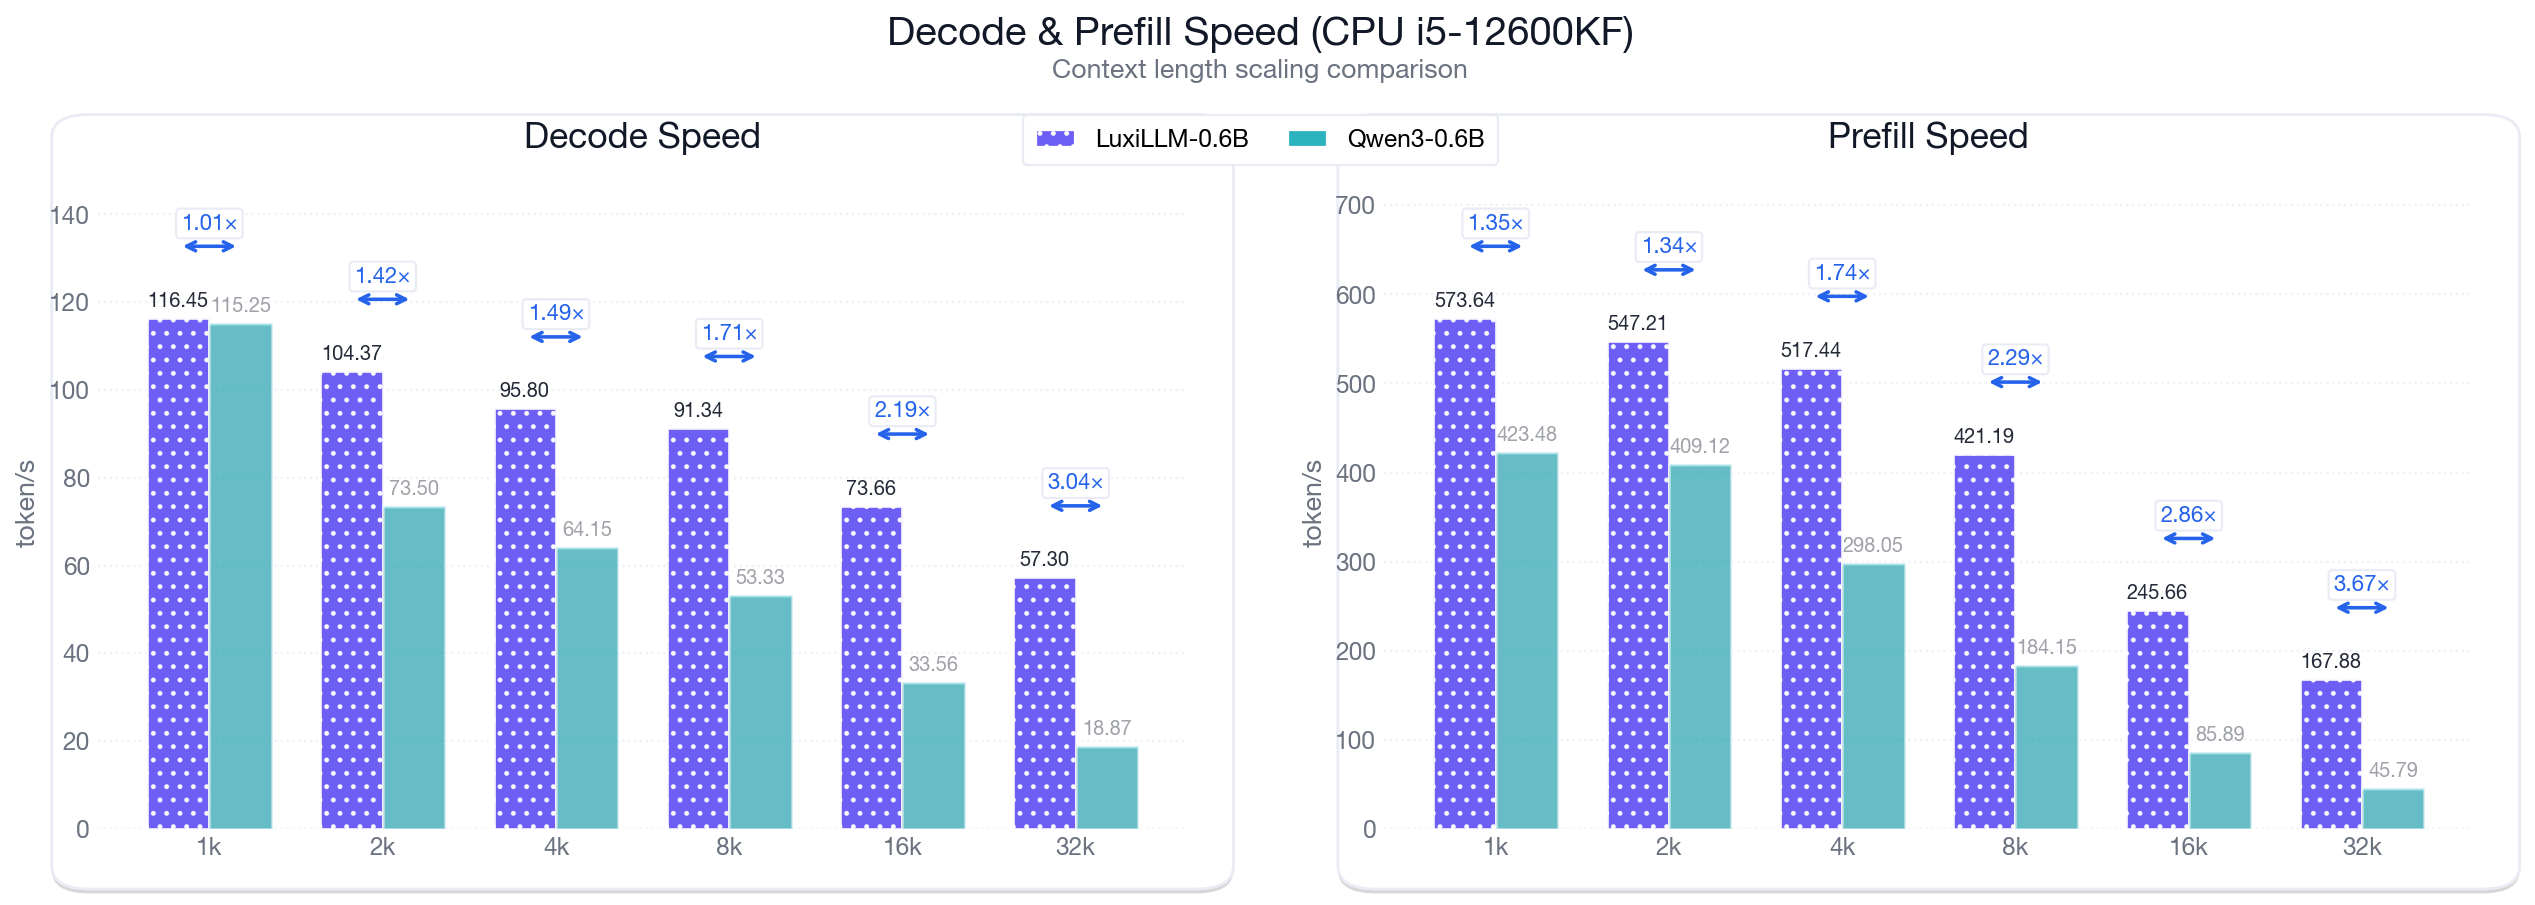

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "font.family": "sans-serif",
    "font.sans-serif": ["PingFang SC", "SF Pro Display", "Helvetica Neue", "Arial Unicode MS", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# =========================
# 1) Models + style
# =========================
models = ["LuxiLLM-0.6B", "Qwen3-0.6B"]
contexts = ['1k','2k','4k','8k','16k','32k']

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
}

# 推荐配色：紫 + 青蓝
COLOR = {
    "LuxiLLM-0.6B": "#6D5EF5",
    "Qwen3-0.6B":   "#2BB3C0",
}
HATCH = {"LuxiLLM-0.6B": ".."}  # 想更干净可改成 {}

# =========================
# 2) Data
# =========================
# decode speed (tokens/s)
decode_pairs = {
    'LuxiLLM-0.6B': [116.45, 104.37, 95.80, 91.34, 73.66, 57.30],
    'Qwen3-0.6B':          [115.25, 73.50,  64.15, 53.33, 33.56, 18.87],
}
speed = np.array([decode_pairs[m] for m in models])

# prefill speed (tokens/s) —— 你提供的数据
prefill_speed_data = {
    "Qwen3-0.6B":    [423.48, 409.12, 298.05, 184.15, 85.89, 45.79],
    "LuxiLLM-0.6B":  [573.64, 547.21, 517.44, 421.19, 245.66, 167.88],
}
# ✅ key 映射：用 LuxiLLM-0.6B 的数据填到 LuxiLLM-0.6B 这条上
prefill_pairs = {
    "LuxiLLM-0.6B": prefill_speed_data["LuxiLLM-0.6B"],
    "Qwen3-0.6B":          prefill_speed_data["Qwen3-0.6B"],
}
prefill = np.array([prefill_pairs[m] for m in models])

# =========================
# 3) Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def draw_grouped(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.36
    x = np.arange(len(contexts))
    vmax = values.max()

    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = m == "Qwen3-0.6B"
        bars = ax.bar(
            x + off, values[i],
            width=width,
            color=COLOR[m],
            edgecolor="#FFFFFF",
            linewidth=1.2,
            alpha=0.92 if not is_qwen else 0.4,  # Qwen3透明度降低
            #alpha=0.92,
            hatch=HATCH.get(m, None),
            zorder=3
        )
        for r in bars:
            r.set_path_effects([
                pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                pe.Normal()
            ])
        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width()/2,
                rect.get_height() + vmax * 0.014,
                f"{v:.2f}",
                ha="center", va="bottom",
                alpha=0.92 if not is_qwen else 0.4,
                fontsize=9,
                color=THEME["text"],
                zorder=6
            )

    # ratio arrows (calm blue)
    for j in range(len(contexts)):
        v0, v1 = values[0][j], values[1][j]
        if v0 >= v1:
            ratio = v0 / v1
            higher_off, lower_off = -width/2, +width/2
        else:
            ratio = v1 / v0
            higher_off, lower_off = +width/2, -width/2

        y = max(v0, v1) + vmax * 0.14
        ax.annotate(
            "", xy=(x[j] + lower_off, y), xytext=(x[j] + higher_off, y),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )
        ax.text(
            x[j], y + vmax * 0.025,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, vmax * 1.28)

# =========================
# 4) Plot
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.6), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

axes[0].set_title("Decode Speed", color=THEME["text"], pad=12)
draw_grouped(axes[0], speed, "token/s")

axes[1].set_title("Prefill Speed", color=THEME["text"], pad=12)
draw_grouped(axes[1], prefill, "token/s")

legend_handles = [
    Patch(facecolor=COLOR['LuxiLLM-0.6B'], edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get('LuxiLLM-0.6B', None), label="LuxiLLM-0.6B"),
    Patch(facecolor=COLOR['Qwen3-0.6B'], edgecolor="#FFFFFF", linewidth=1.0, label="Qwen3-0.6B"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.92),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

fig.text(0.5, 0.985, "Decode & Prefill Speed (CPU i5-12600KF)", ha="center",
         fontsize=18, fontweight="bold", color=THEME["text"])
fig.text(0.5, 0.948, "Context length scaling comparison", ha="center",
         fontsize=12, color=THEME["muted"])

fig.subplots_adjust(left=0.04, right=0.98, bottom=0.11, top=0.84, wspace=0.18)

plt.savefig("decode_and_prefill_speed_white.png",dpi=600, bbox_inches="tight")
plt.savefig("decode_and_prefill_speed_white.pdf", bbox_inches="tight")
plt.show()

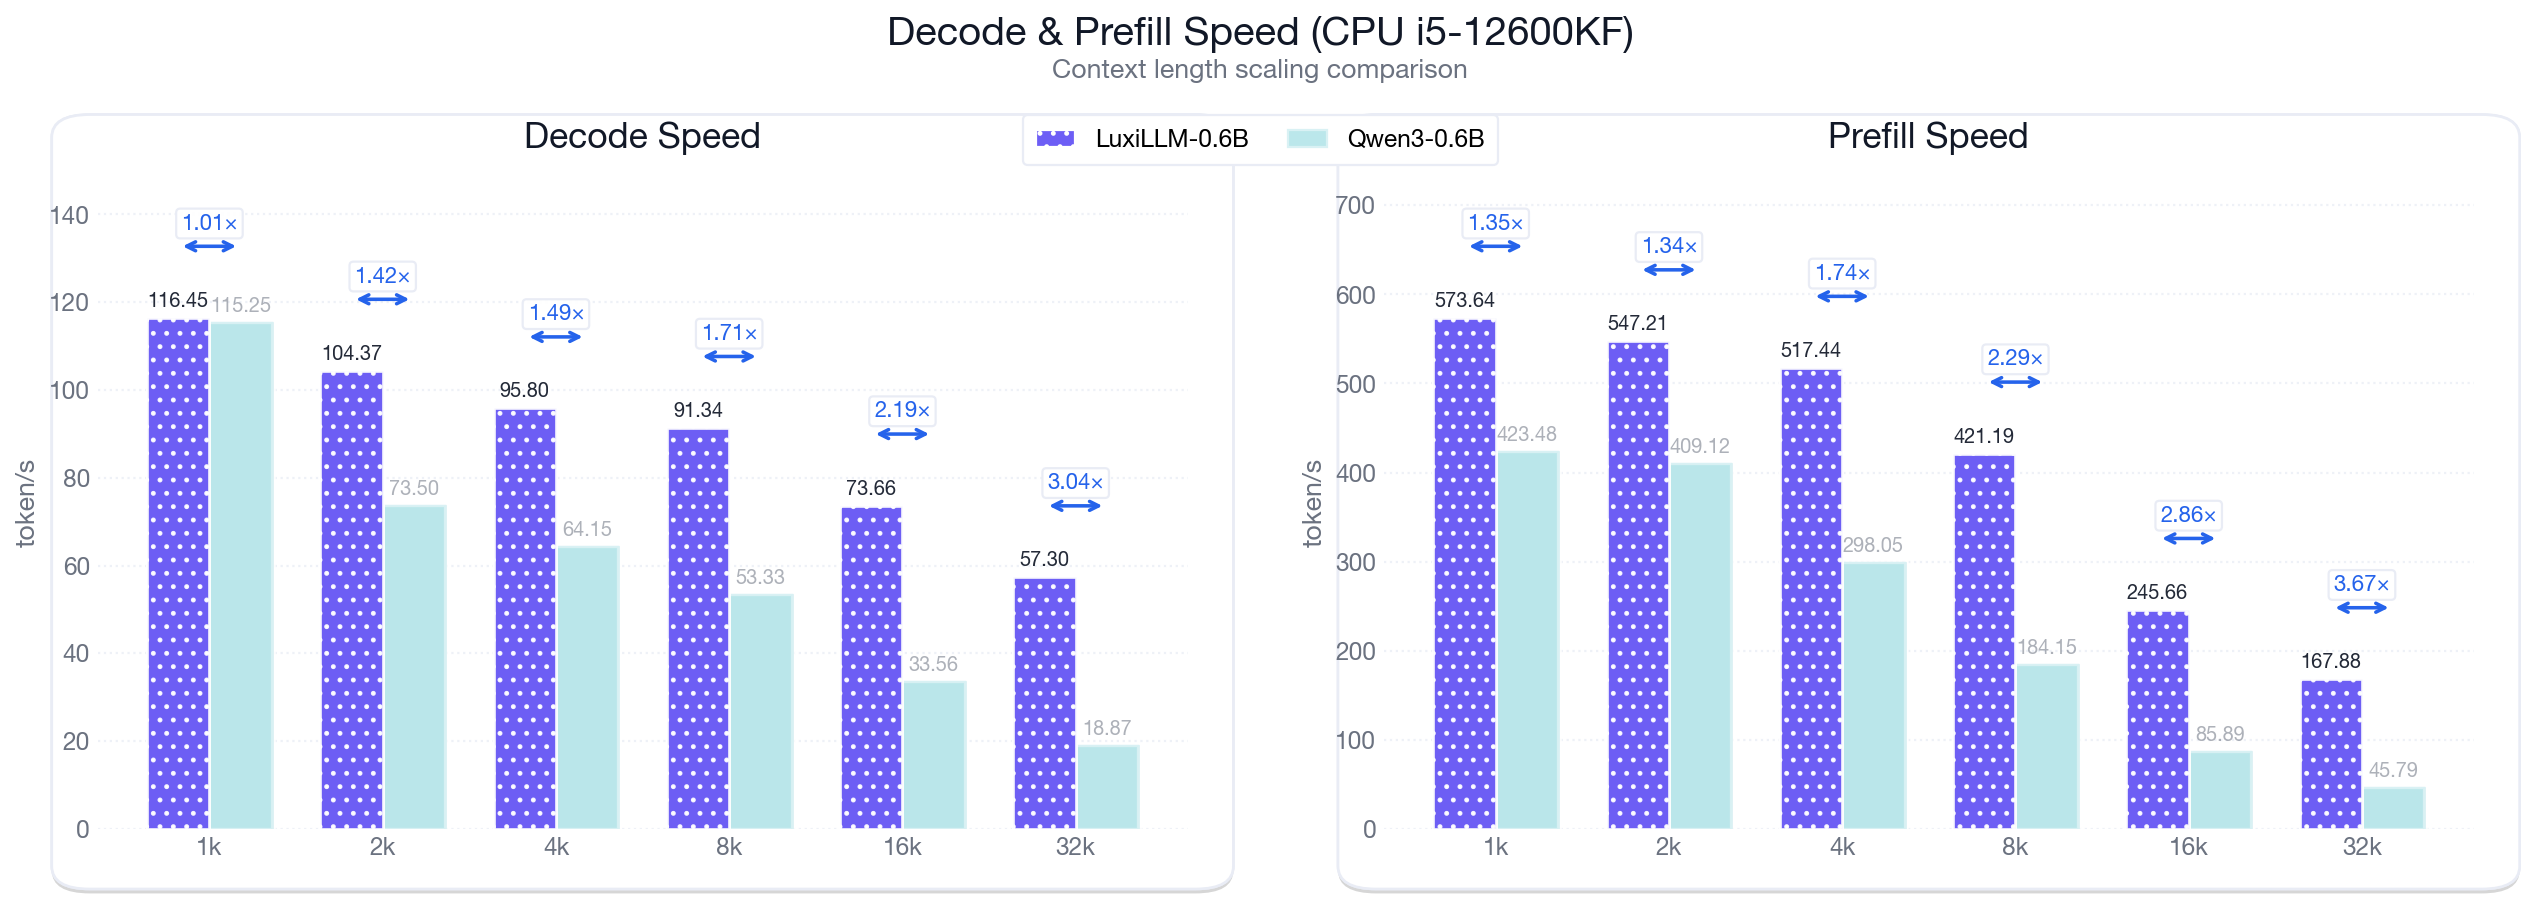

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "font.family": "sans-serif",
    "font.sans-serif": ["PingFang SC", "SF Pro Display", "Helvetica Neue", "Arial Unicode MS", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# =========================
# Helpers: "fade/blur-like" color treatment
# =========================
def hex_to_rgb01(h):
    h = h.lstrip("#")
    return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)]) / 255.0

def mix_with_white(hex_color, mix=0.68):
    """
    mix: 0~1, higher -> closer to white (more "hazy")
    """
    rgb = hex_to_rgb01(hex_color)
    out = (1 - mix) * rgb + mix * np.ones(3)
    return out

# =========================
# 1) Models + style
# =========================
models = ["LuxiLLM-0.6B", "Qwen3-0.6B"]
contexts = ['1k','2k','4k','8k','16k','32k']

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
}

# Recommended palette: Indigo + Teal
COLOR = {
    "LuxiLLM-0.6B": "#6D5EF5",
    "Qwen3-0.6B":   "#2BB3C0",
}
HATCH = {"LuxiLLM-0.6B": ".."}  # set {} if you want it cleaner

# =========================
# 2) Data
# =========================
# decode speed (tokens/s)
decode_pairs = {
    'LuxiLLM-0.6B': [116.45, 104.37, 95.80, 91.34, 73.66, 57.30],
    'Qwen3-0.6B':   [115.25, 73.50,  64.15, 53.33, 33.56, 18.87],
}
speed = np.array([decode_pairs[m] for m in models])

# prefill speed (tokens/s)
prefill_speed_data = {
    "Qwen3-0.6B":    [423.48, 409.12, 298.05, 184.15, 85.89, 45.79],
    "LuxiLLM-0.6B":  [573.64, 547.21, 517.44, 421.19, 245.66, 167.88],
}
prefill_pairs = {
    "LuxiLLM-0.6B": prefill_speed_data["LuxiLLM-0.6B"],
    "Qwen3-0.6B":   prefill_speed_data["Qwen3-0.6B"],
}
prefill = np.array([prefill_pairs[m] for m in models])

# =========================
# 3) Plot helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def draw_grouped(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.36
    x = np.arange(len(contexts))
    vmax = values.max()

    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen3-0.6B")

        # ✅ Hazy Qwen look: tint toward white + soft edge
        if is_qwen:
            face = mix_with_white(COLOR[m], mix=0.68)   # 0.62~0.75
            edge = mix_with_white(COLOR[m], mix=0.82)
            hatch = None
            alpha = 0.95
            z = 2.8
        else:
            face = COLOR[m]
            edge = "#FFFFFF"
            hatch = HATCH.get(m, None)
            alpha = 0.92
            z = 3.0

        bars = ax.bar(
            x + off, values[i],
            width=width,
            color=face,
            edgecolor=edge,
            linewidth=1.2 if not is_qwen else 1.0,
            alpha=alpha,
            hatch=hatch,
            zorder=z
        )

        # Path effects: normal shadow for Luxi, "foggy outline" for Qwen
        for rct in bars:
            if not is_qwen:
                rct.set_path_effects([
                    pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])
            else:
                rct.set_path_effects([
                    pe.Stroke(linewidth=3.2, foreground="white", alpha=0.65),  # soft white glow
                    pe.Stroke(linewidth=1.2, foreground=edge, alpha=0.95),     # tinted outline
                    pe.withSimplePatchShadow(offset=(0, -0.8), alpha=0.08, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])

        # Value labels (Qwen also hazy)
        txt_color = THEME["text"] if not is_qwen else THEME["muted"]
        txt_alpha = 0.92 if not is_qwen else 0.55

        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width()/2,
                rect.get_height() + vmax * 0.014,
                f"{v:.2f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # ratio arrows (calm blue)
    for j in range(len(contexts)):
        v0, v1 = values[0][j], values[1][j]
        if v0 >= v1:
            ratio = v0 / v1
            higher_off, lower_off = -width/2, +width/2
        else:
            ratio = v1 / v0
            higher_off, lower_off = +width/2, -width/2

        y = max(v0, v1) + vmax * 0.14
        ax.annotate(
            "", xy=(x[j] + lower_off, y), xytext=(x[j] + higher_off, y),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )
        ax.text(
            x[j], y + vmax * 0.025,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, vmax * 1.28)

# =========================
# 4) Plot
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.6), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

axes[0].set_title("Decode Speed", color=THEME["text"], pad=12)
draw_grouped(axes[0], speed, "token/s")

axes[1].set_title("Prefill Speed", color=THEME["text"], pad=12)
draw_grouped(axes[1], prefill, "token/s")

# Legend: also make Qwen look hazy
legend_handles = [
    Patch(facecolor=COLOR['LuxiLLM-0.6B'], edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get('LuxiLLM-0.6B', None), label="LuxiLLM-0.6B"),
    Patch(facecolor=mix_with_white(COLOR['Qwen3-0.6B'], mix=0.68),
          edgecolor=mix_with_white(COLOR['Qwen3-0.6B'], mix=0.82),
          linewidth=1.0, label="Qwen3-0.6B"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.92),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

fig.text(0.5, 0.985, "Decode & Prefill Speed (CPU i5-12600KF)", ha="center",
         fontsize=18, fontweight="bold", color=THEME["text"])
fig.text(0.5, 0.948, "Context length scaling comparison", ha="center",
         fontsize=12, color=THEME["muted"])

fig.subplots_adjust(left=0.04, right=0.98, bottom=0.11, top=0.84, wspace=0.18)

plt.savefig("decode_and_prefill_speed_white.png", dpi=600, bbox_inches="tight")
plt.savefig("decode_and_prefill_speed_white.pdf", bbox_inches="tight")
plt.show()

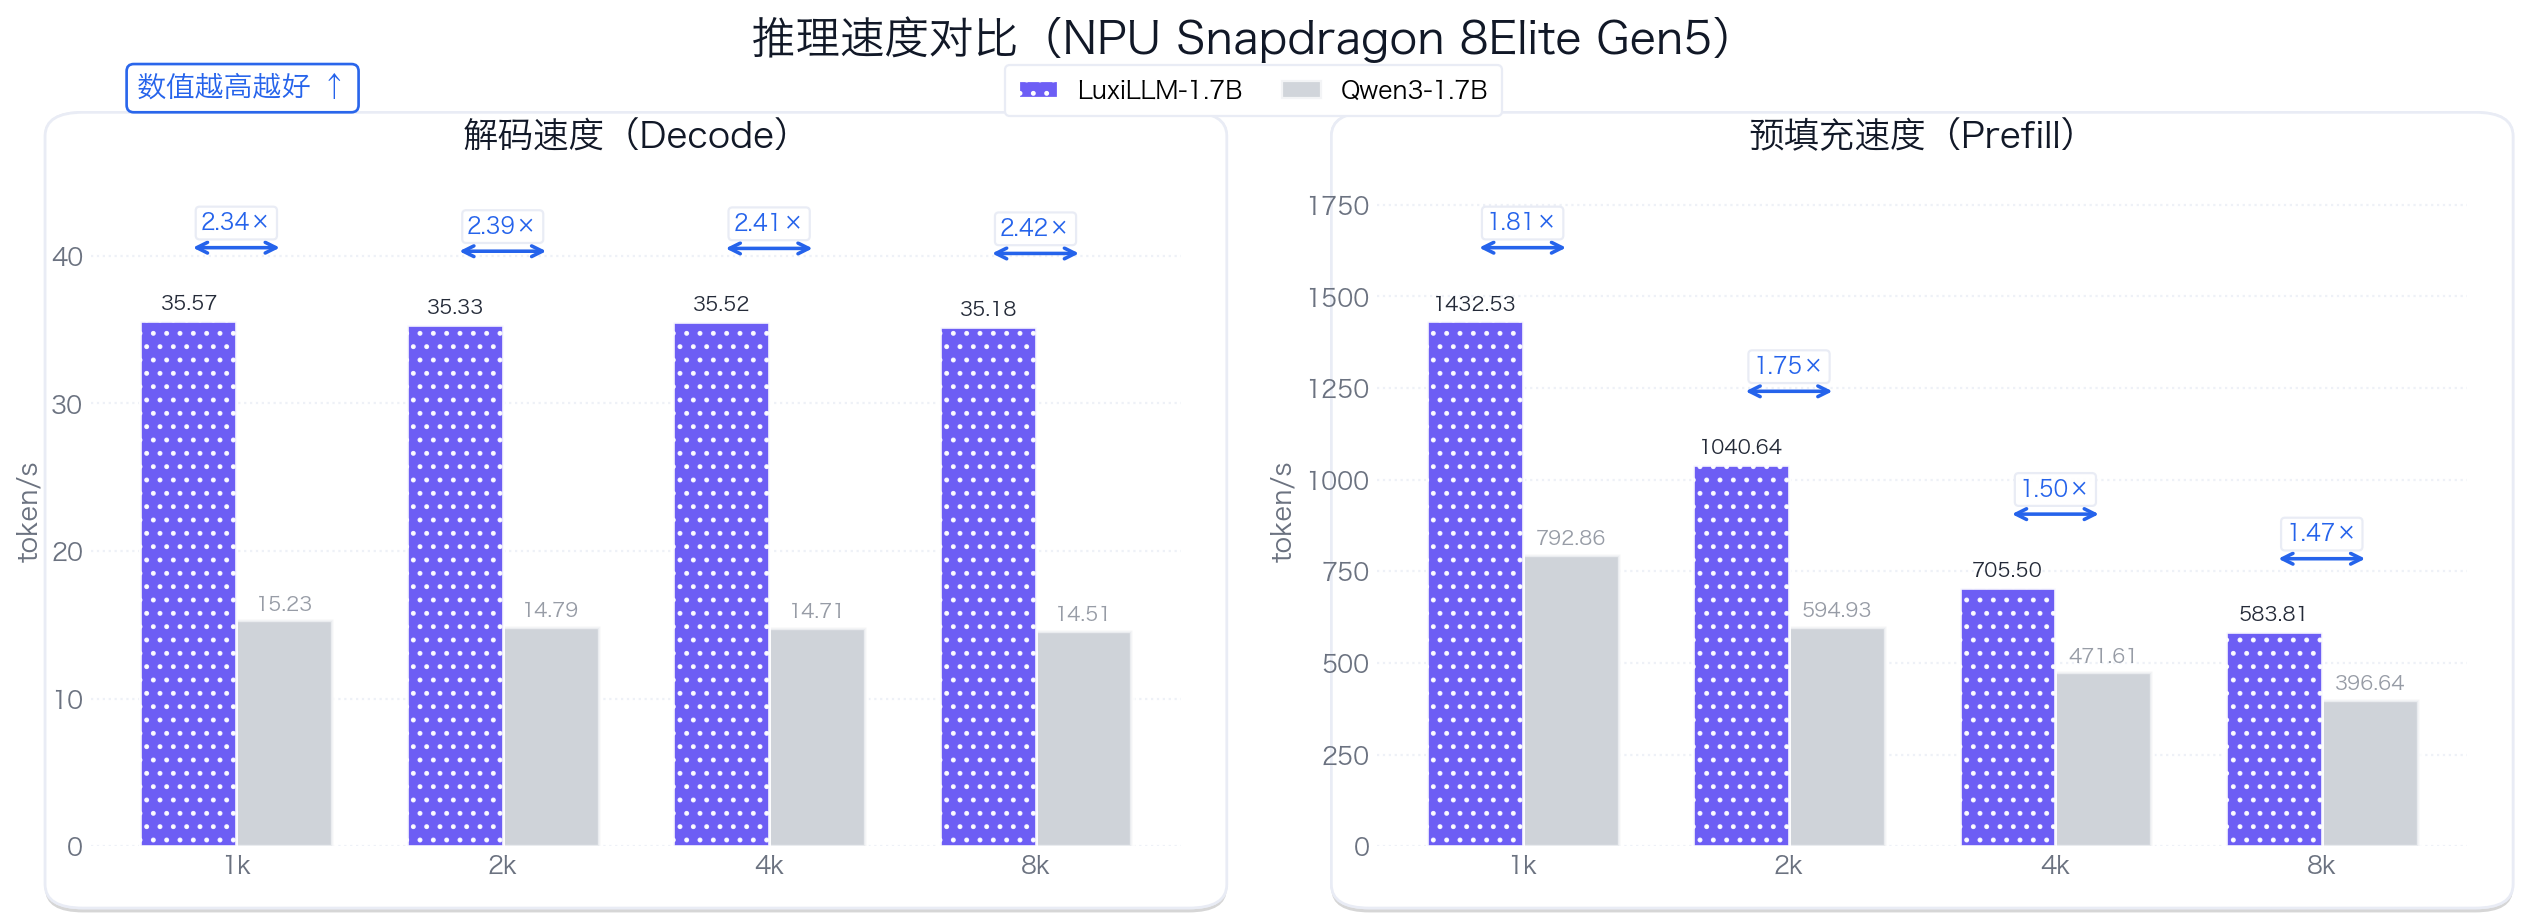

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm

# =========================
# Robust font setup for macOS (avoid "font not found" errors)
# =========================
def set_macos_chinese_font():
    font_files = [
        "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
        "/usr/share/fonts/truetype/wqy/wqy-microhei.ttc",
        "/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc",
        "/usr/share/fonts/truetype/droid/DroidSansFallbackFull.ttf",
    ]
    for font_file in font_files:
        if os.path.exists(font_file):
            try:
                fm.fontManager.addfont(font_file)
            except Exception:
                pass
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC",
        "Arial Unicode MS", "WenQuanYi Micro Hei", "WenQuanYi Zen Hei",
        "Droid Sans Fallback", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

_ = set_macos_chinese_font()

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# =========================
# Helpers: gray treatment
# =========================
def hex_to_rgb01(h):
    h = h.lstrip("#")
    return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)]) / 255.0

def mix_with_white(hex_color, mix=0.68):
    rgb = hex_to_rgb01(hex_color)
    return (1 - mix) * rgb + mix * np.ones(3)

# =========================
# 1) Models + style
# =========================
models = ["LuxiLLM-1.7B", "Qwen3-1.7B"]
contexts = ['1k','2k','4k','8k','16k','32k']

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
}

# Luxi purple + Qwen gray (less visible)
COLOR = {
    "LuxiLLM-1.7B": "#6D5EF5",
    "Qwen3-1.7B":   "#D1D5DB",  # ✅ gray
}
QWEN_EDGE = "#F3F4F6"
HATCH = {"LuxiLLM-1.7B": ".."}

# =========================
# 2) Data
# =========================
decode_pairs = {
    'LuxiLLM-1.7B': [35.57,35.33,35.52,35.18],
    'Qwen3-1.7B':   [15.23,14.79,14.71,14.51],
}
speed = np.array([decode_pairs[m] for m in models])

prefill_speed_data = {
    "Qwen3-1.7B":   [792.86,594.93,471.61,396.64],
    "LuxiLLM-1.7B": [1432.53,1040.64,705.50,583.81],
}
prefill_pairs = {
    "LuxiLLM-1.7B": prefill_speed_data["LuxiLLM-1.7B"],
    "Qwen3-1.7B":   prefill_speed_data["Qwen3-1.7B"],
}
prefill = np.array([prefill_pairs[m] for m in models])

# ✅ keep contexts length consistent with data (4 points here)
contexts_eff = contexts[:speed.shape[1]]
speed = speed[:, :len(contexts_eff)]
prefill = prefill[:, :len(contexts_eff)]

# =========================
# 3) Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def draw_grouped(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.36
    x = np.arange(len(contexts_eff))
    vmax = values.max()

    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen3-1.7B")

        if is_qwen:
            face = COLOR[m]     # gray
            edge = QWEN_EDGE
            hatch = None
            alpha = 0.70
            z = 2.75
        else:
            face = COLOR[m]
            edge = "#FFFFFF"
            hatch = HATCH.get(m, None)
            alpha = 0.92
            z = 3.0

        bars = ax.bar(
            x + off, values[i],
            width=width,
            color=face,
            edgecolor=edge,
            linewidth=1.2 if not is_qwen else 1.0,
            alpha=alpha,
            hatch=hatch,
            zorder=z
        )

        # Path effects
        for rct in bars:
            if not is_qwen:
                rct.set_path_effects([
                    pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])
            else:
                rct.set_path_effects([
                    pe.Stroke(linewidth=3.2, foreground="white", alpha=0.80),
                    pe.Stroke(linewidth=1.1, foreground=QWEN_EDGE, alpha=1.0),
                    pe.withSimplePatchShadow(offset=(0, -0.8), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])

        # Value labels (Qwen muted)
        txt_color = THEME["text"] if not is_qwen else THEME["muted"]
        txt_alpha = 0.92 if not is_qwen else 0.70

        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width()/2,
                rect.get_height() + vmax * 0.014,
                f"{v:.2f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # ratio arrows
    for j in range(len(contexts_eff)):
        v0, v1 = values[0][j], values[1][j]
        if v0 >= v1:
            ratio = v0 / v1
            higher_off, lower_off = -width/2, +width/2
        else:
            ratio = v1 / v0
            higher_off, lower_off = +width/2, -width/2

        y = max(v0, v1) + vmax * 0.14
        ax.annotate(
            "", xy=(x[j] + lower_off, y), xytext=(x[j] + higher_off, y),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )
        ax.text(
            x[j], y + vmax * 0.025,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts_eff)
    ax.set_ylim(0, vmax * 1.28)

# =========================
# 4) Plot
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.6), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

# ✅ Chinese subtitles (with English in parentheses)
axes[0].set_title("解码速度（Decode）", color=THEME["text"], pad=12)
draw_grouped(axes[0], speed, "token/s")

axes[1].set_title("预填充速度（Prefill）", color=THEME["text"], pad=12)
draw_grouped(axes[1], prefill, "token/s")

# Legend (Qwen gray)
legend_handles = [
    Patch(facecolor=COLOR['LuxiLLM-1.7B'], edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get('LuxiLLM-1.7B', None), label="LuxiLLM-1.7B"),
    Patch(facecolor=COLOR['Qwen3-1.7B'], edgecolor=QWEN_EDGE, linewidth=1.0, label="Qwen3-1.7B"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.995),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

# ✅ Main title (Chinese) + callout (higher is better)
fig.text(0.5, 0.995, "推理速度对比（NPU Snapdragon 8Elite Gen5）",
         ha="center", fontsize=20, fontweight="bold", color=THEME["text"])
fig.text(
    0.1, 0.956, "数值越高越好 ↑",
    ha="center", va="center",
    fontsize=13.0, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(
        boxstyle="round,pad=0.35,rounding_size=0.25",
        facecolor="white",
        edgecolor=THEME["accent"],
        linewidth=1.2,
        alpha=0.98
    )
)

# Layout (leave room for title + callout + legend)
fig.subplots_adjust(left=0.04, right=0.98, bottom=0.11, top=0.86, wspace=0.18)

plt.savefig("速度对比_NPU_8Elite_Gen5.png", dpi=600, bbox_inches="tight")
plt.savefig("速度对比_NPU_8Elite_Gen5.pdf", dpi=600, bbox_inches="tight")
plt.show()

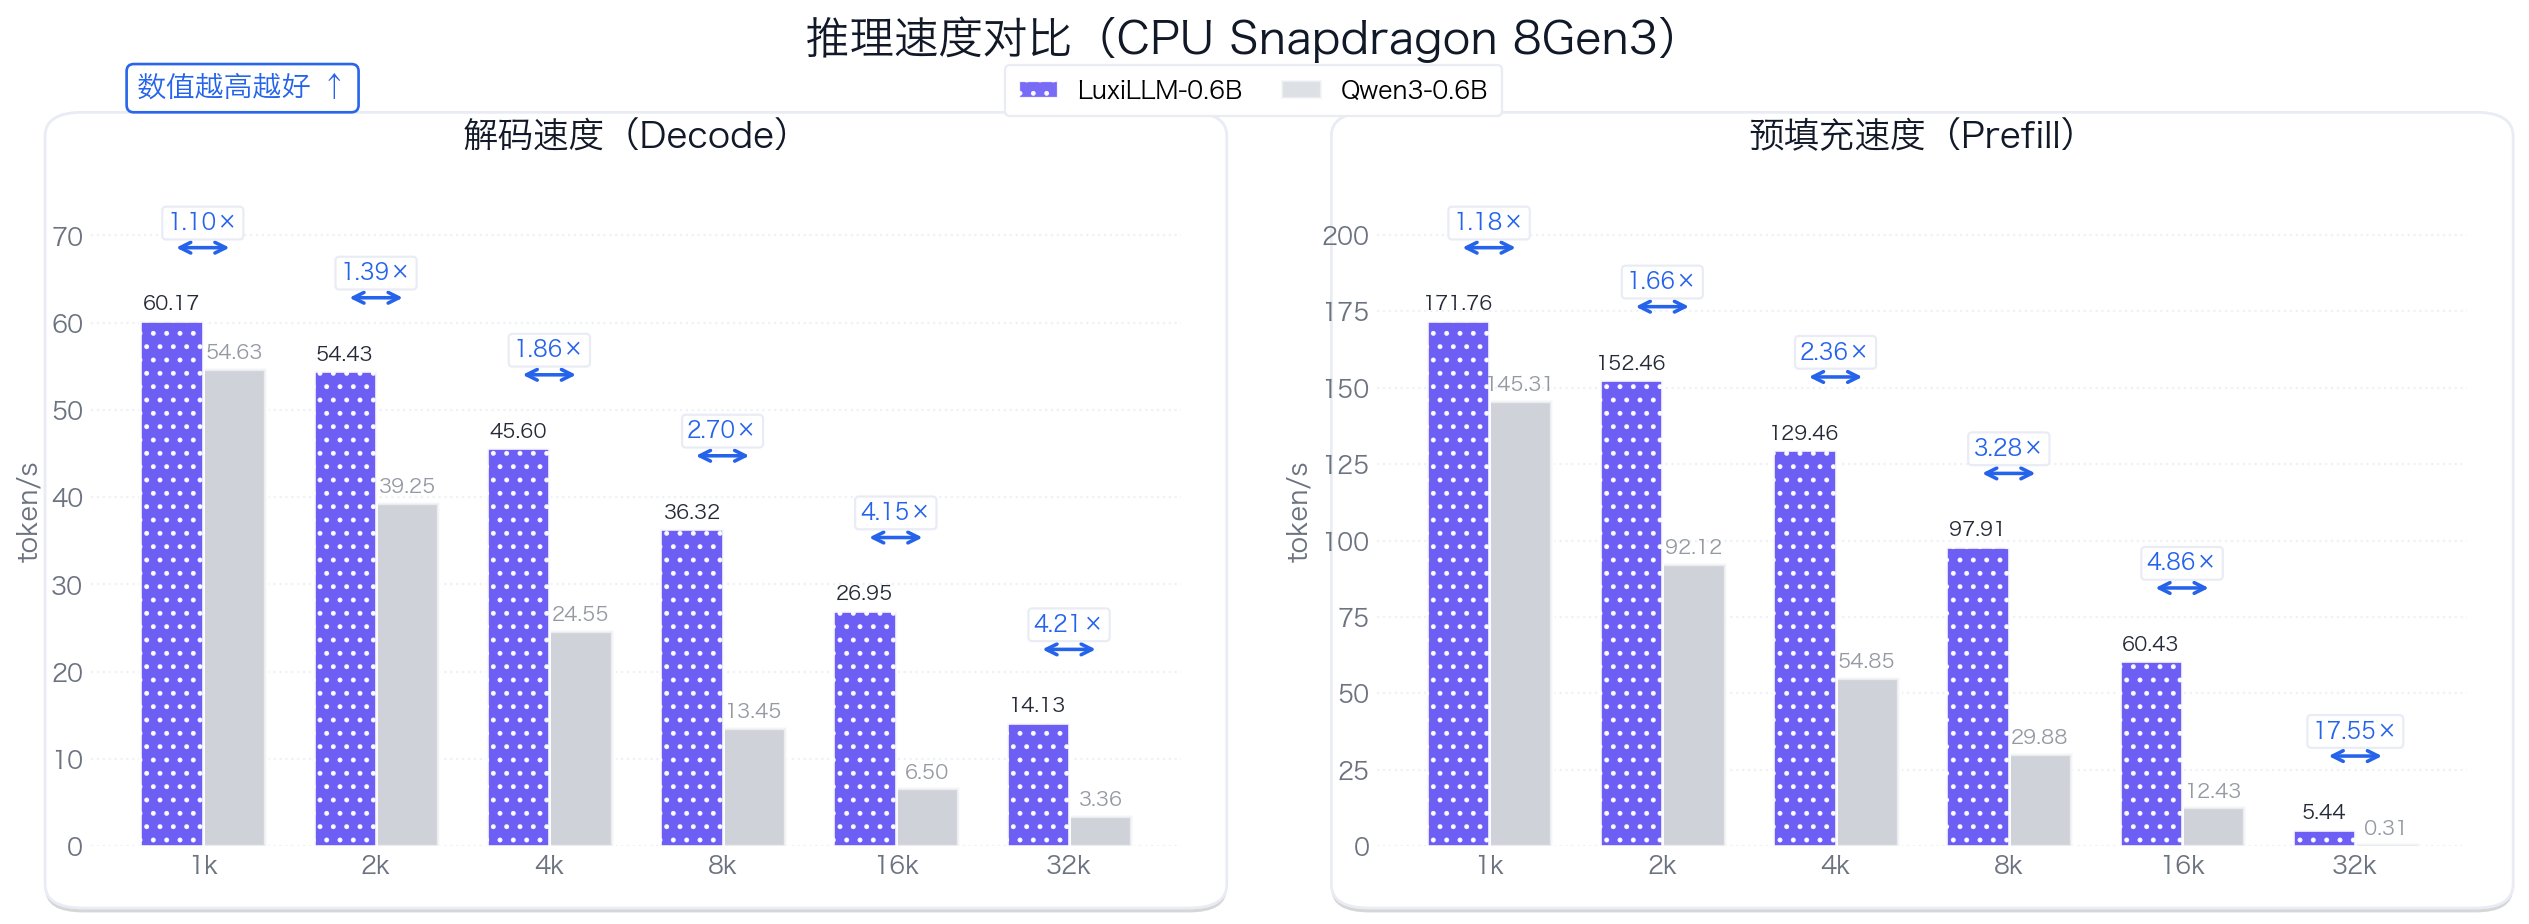

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm

# =========================
# Robust font setup for macOS (avoid "font not found" errors)
# =========================
def set_macos_chinese_font():
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC",
        "Arial Unicode MS", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

_ = set_macos_chinese_font()

# =========================
# Global style
# =========================
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# =========================
# 1) Models + style
# =========================
models = ["LuxiLLM-0.6B", "Qwen3-0.6B"]
contexts = ['1k','2k','4k','8k','16k','32k']

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
}

COLOR = {
    "LuxiLLM-0.6B": "#6D5EF5",
    "Qwen3-0.6B":   "#D1D5DB",  # ✅ 更浅灰
}
QWEN_EDGE = "#F3F4F6"
HATCH = {"LuxiLLM-0.6B": ".."}  # set {} if you want it cleaner

# =========================
# 2) Data
# =========================
decode_pairs = {
    'LuxiLLM-0.6B': [60.17, 54.43, 45.60, 36.32, 26.95, 14.13],
    'Qwen3-0.6B':   [54.63, 39.25, 24.55, 13.45, 6.50, 3.36],
}
speed = np.array([decode_pairs[m] for m in models])

prefill_speed_data = {
    "Qwen3-0.6B":   [145.31, 92.12, 54.85, 29.88, 12.43, 0.31],
    "LuxiLLM-0.6B": [171.76, 152.46, 129.46, 97.91, 60.43, 5.44],
}
prefill_pairs = {
    "LuxiLLM-0.6B": prefill_speed_data["LuxiLLM-0.6B"],
    "Qwen3-0.6B":   prefill_speed_data["Qwen3-0.6B"],
}
prefill = np.array([prefill_pairs[m] for m in models])

# =========================
# 3) Helpers (card + axes)
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def draw_grouped(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.36
    x = np.arange(len(contexts))
    vmax = values.max()

    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen3-0.6B")

        if is_qwen:
            face = COLOR[m]     # gray
            edge = QWEN_EDGE
            hatch = None
            alpha = 0.72
            z = 2.75
        else:
            face = COLOR[m]
            edge = "#FFFFFF"
            hatch = HATCH.get(m, None)
            alpha = 0.92
            z = 3.0

        bars = ax.bar(
            x + off, values[i],
            width=width,
            color=face,
            edgecolor=edge,
            linewidth=1.2 if not is_qwen else 1.0,
            alpha=alpha,
            hatch=hatch,
            zorder=z
        )

        for r in bars:
            if not is_qwen:
                r.set_path_effects([
                    pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])
            else:
                r.set_path_effects([
                    pe.Stroke(linewidth=3.2, foreground="white", alpha=0.80),
                    pe.Stroke(linewidth=1.1, foreground=QWEN_EDGE, alpha=1.0),
                    pe.withSimplePatchShadow(offset=(0, -0.9), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])

        txt_color = THEME["text"] if not is_qwen else THEME["muted"]
        txt_alpha = 0.92 if not is_qwen else 0.72

        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width()/2,
                rect.get_height() + vmax * 0.014,
                f"{v:.2f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # ratio arrows (accent)
    for j in range(len(contexts)):
        v0, v1 = values[0][j], values[1][j]
        if v0 >= v1:
            ratio = v0 / v1
            higher_off, lower_off = -width/2, +width/2
        else:
            ratio = v1 / v0
            higher_off, lower_off = +width/2, -width/2

        y = max(v0, v1) + vmax * 0.14
        ax.annotate(
            "", xy=(x[j] + lower_off, y), xytext=(x[j] + higher_off, y),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )
        ax.text(
            x[j], y + vmax * 0.025,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, vmax * 1.28)

# =========================
# 4) Plot
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.6), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

axes[0].set_title("解码速度（Decode）", color=THEME["text"], pad=12)
draw_grouped(axes[0], speed, "token/s")

axes[1].set_title("预填充速度（Prefill）", color=THEME["text"], pad=12)
draw_grouped(axes[1], prefill, "token/s")

legend_handles = [
    Patch(
        facecolor=COLOR['LuxiLLM-0.6B'],
        edgecolor="#FFFFFF",
        linewidth=1.0,
        hatch=HATCH.get('LuxiLLM-0.6B', None),
        alpha=0.92,
        label="LuxiLLM-0.6B"
    ),
    Patch(
        facecolor=COLOR['Qwen3-0.6B'],
        edgecolor=QWEN_EDGE,
        linewidth=1.0,
        alpha=0.72,
        label="Qwen3-0.6B"
    ),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.995),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

# ✅ Title in Chinese + "higher is better" callout
fig.text(0.5, 0.995, "推理速度对比（CPU Snapdragon 8Gen3）",
         ha="center", fontsize=20, fontweight="bold", color=THEME["text"])
fig.text(
    0.1, 0.956, "数值越高越好 ↑",
    ha="center", va="center",
    fontsize=13.0, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(
        boxstyle="round,pad=0.35,rounding_size=0.25",
        facecolor="white",
        edgecolor=THEME["accent"],
        linewidth=1.2,
        alpha=0.98
    )
)

fig.subplots_adjust(left=0.04, right=0.98, bottom=0.11, top=0.86, wspace=0.18)

plt.savefig("速度对比_CPU_8Gen3.png", dpi=600, bbox_inches="tight")
plt.savefig("速度对比_CPU_8Gen3.pdf", dpi=600, bbox_inches="tight")
plt.show()

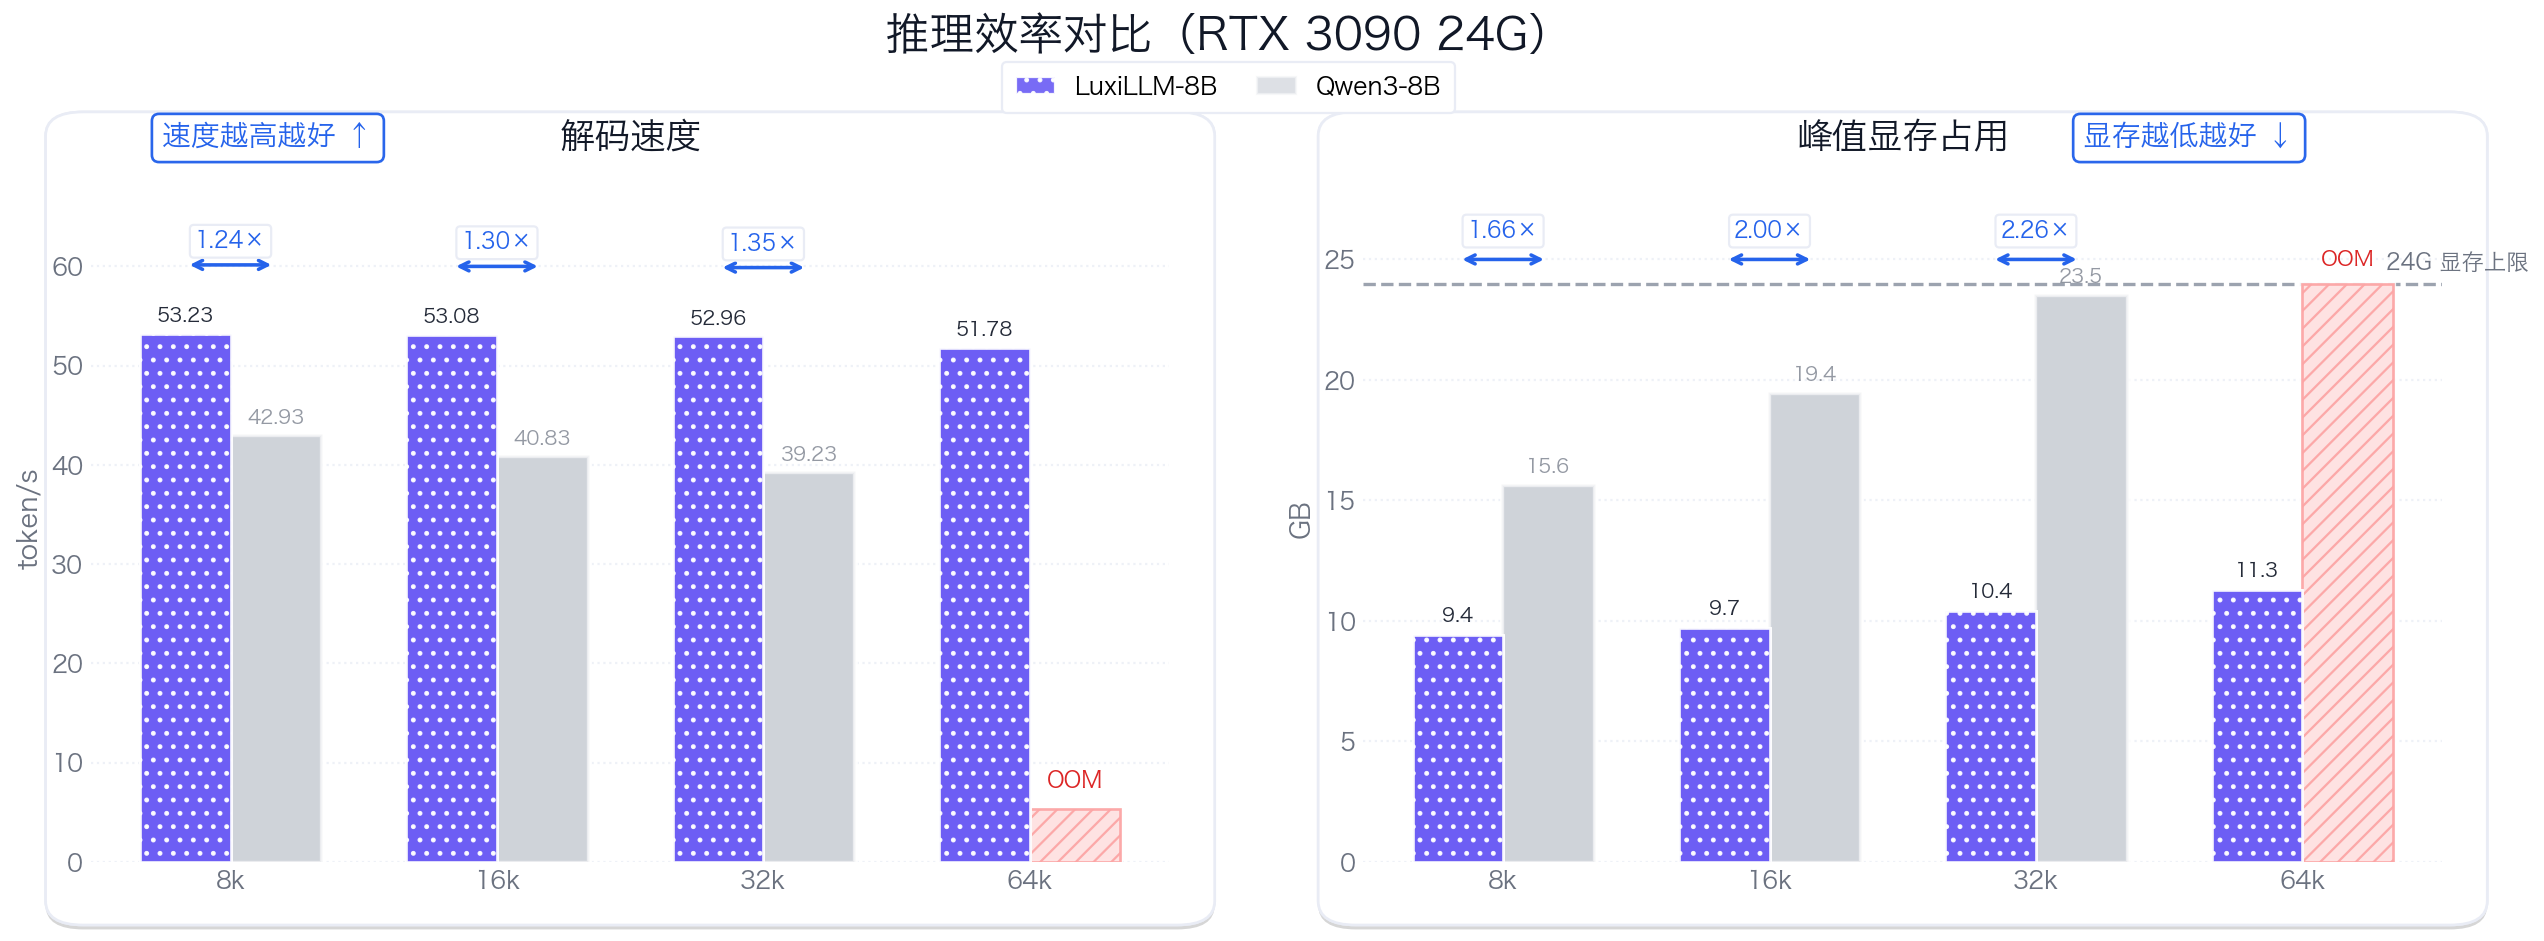

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm

# =========================
# Robust font setup for macOS
# =========================
def set_macos_chinese_font():
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC",
        "Arial Unicode MS", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

_ = set_macos_chinese_font()

# =========================
# Global style
# =========================
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# =========================
# Models / contexts / theme
# =========================
models = ["LuxiLLM-8B", "Qwen3-8B"]
contexts = ["8k", "16k", "32k", "64k"]

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
    "danger":    "#DC2626",
}

COLOR = {
    "LuxiLLM-8B": "#6D5EF5",
    "Qwen3-8B":   "#D1D5DB",
}
QWEN_EDGE = "#F3F4F6"
HATCH = {"LuxiLLM-8B": ".."}

# =========================
# Data
# =========================
# Decode speed (token/s)
# Qwen3-8B: user-provided
# LuxiLLM-8B: ~20%–40% faster, 64k still runnable due to SWA (window size = 256)
decode_speed = {
    "Qwen3-8B":   [42.93, 40.83, 39.23, np.nan],   # 64k OOM
    "LuxiLLM-8B": [53.23, 53.08, 52.96, 51.78],    # +24%, +30%, +35%, +32%
}

# Peak VRAM (GB)
# Designed to reflect: Luxi is roughly 60% -> 35% of Qwen as context grows
# Qwen3-8B at 64k exceeds 24G and becomes OOM
vram_actual = {
    "Qwen3-8B":   [15.6, 19.4, 23.5, 29],
    "LuxiLLM-8B": [9.4,  9.7,  10.4,  11.3],
}

# For plotting only: cap OOM bar at 24G so it can be displayed inside chart
vram_plot = {
    "Qwen3-8B":   [15.6, 19.4, 23.5, 24.0],
    "LuxiLLM-8B": [9.4,  9.7,  10.4,  11.3],
}

speed = np.array([decode_speed[m] for m in models], dtype=float)
vram = np.array([vram_plot[m] for m in models], dtype=float)

# OOM flags
oom_speed = {
    "LuxiLLM-8B": [False, False, False, False],
    "Qwen3-8B":   [False, False, False, True],
}
oom_vram = {
    "LuxiLLM-8B": [False, False, False, False],
    "Qwen3-8B":   [False, False, False, True],
}

# =========================
# Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def draw_grouped_speed(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.34
    x = np.arange(len(contexts))
    vmax = np.nanmax(values)

    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen3-8B")

        face = COLOR[m]
        edge = QWEN_EDGE if is_qwen else "#FFFFFF"
        hatch = None if is_qwen else HATCH.get(m, None)
        alpha = 0.72 if is_qwen else 0.92
        z = 2.75 if is_qwen else 3.0

        for j, v in enumerate(values[i]):
            xpos = x[j] + off

            if np.isnan(v):
                # OOM placeholder
                bar_h = vmax * 0.10
                bar = ax.bar(
                    xpos, bar_h, width=width,
                    color="#FEE2E2",
                    edgecolor="#FCA5A5",
                    linewidth=1.2,
                    hatch="///",
                    alpha=0.95,
                    zorder=2.6
                )
                for r in bar:
                    r.set_path_effects([
                        pe.Stroke(linewidth=2.8, foreground="white", alpha=0.85),
                        pe.Normal()
                    ])
                ax.text(
                    xpos, bar_h + vmax * 0.03, "OOM",
                    ha="center", va="bottom",
                    fontsize=10, color=THEME["danger"], fontweight="bold", zorder=8
                )
                continue

            bars = ax.bar(
                xpos, v,
                width=width,
                color=face,
                edgecolor=edge,
                linewidth=1.2 if not is_qwen else 1.0,
                alpha=alpha,
                hatch=hatch,
                zorder=z
            )

            for r in bars:
                if not is_qwen:
                    r.set_path_effects([
                        pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                        pe.Normal()
                    ])
                else:
                    r.set_path_effects([
                        pe.Stroke(linewidth=3.2, foreground="white", alpha=0.80),
                        pe.Stroke(linewidth=1.1, foreground=QWEN_EDGE, alpha=1.0),
                        pe.withSimplePatchShadow(offset=(0, -0.9), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                        pe.Normal()
                    ])

            txt_color = THEME["text"] if not is_qwen else THEME["muted"]
            txt_alpha = 0.92 if not is_qwen else 0.72

            ax.text(
                xpos,
                v + vmax * 0.015,
                f"{v:.2f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # ratio arrows: only when both bars exist
    for j in range(len(contexts)):
        v_luxi = values[0][j]
        v_qwen = values[1][j]

        if np.isnan(v_luxi) or np.isnan(v_qwen):
            continue

        ratio = v_luxi / v_qwen
        y = max(v_luxi, v_qwen) + vmax * 0.13

        ax.annotate(
            "", xy=(x[j] + width/2, y), xytext=(x[j] - width/2, y),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )
        ax.text(
            x[j], y + vmax * 0.023,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, vmax * 1.30)
def draw_grouped_vram(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.34
    x = np.arange(len(contexts))
    vmax = np.nanmax(values)
    limit_line = 24.0

    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen3-8B")

        face = COLOR[m]
        edge = QWEN_EDGE if is_qwen else "#FFFFFF"
        hatch = None if is_qwen else HATCH.get(m, None)
        alpha = 0.72 if is_qwen else 0.92
        z = 2.75 if is_qwen else 3.0

        for j, v in enumerate(values[i]):
            xpos = x[j] + off
            oom_flag = oom_vram[m][j]
            actual = vram_actual[m][j]

            if oom_flag:
                bar = ax.bar(
                    xpos, v, width=width,
                    color="#FEE2E2",
                    edgecolor="#FCA5A5",
                    linewidth=1.2,
                    hatch="///",
                    alpha=0.95,
                    zorder=2.7
                )
                for r in bar:
                    r.set_path_effects([
                        pe.Stroke(linewidth=2.8, foreground="white", alpha=0.85),
                        pe.Normal()
                    ])
                ax.text(
                    xpos, v + 0.55,
                    f"OOM",
                    ha="center", va="bottom",
                    fontsize=9.5,
                    color=THEME["danger"],
                    fontweight="bold",
                    zorder=8
                )
                continue

            bars = ax.bar(
                xpos, v, width=width,
                color=face,
                edgecolor=edge,
                linewidth=1.2 if not is_qwen else 1.0,
                alpha=alpha,
                hatch=hatch,
                zorder=z
            )

            for r in bars:
                if not is_qwen:
                    r.set_path_effects([
                        pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                        pe.Normal()
                    ])
                else:
                    r.set_path_effects([
                        pe.Stroke(linewidth=3.2, foreground="white", alpha=0.80),
                        pe.Stroke(linewidth=1.1, foreground=QWEN_EDGE, alpha=1.0),
                        pe.withSimplePatchShadow(offset=(0, -0.9), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                        pe.Normal()
                    ])

            txt_color = THEME["text"] if not is_qwen else THEME["muted"]
            txt_alpha = 0.92 if not is_qwen else 0.72

            ax.text(
                xpos,
                v + 0.38,
                f"{actual:.1f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # memory reduction label for Luxi vs Qwen - 放在最上面水平线，64k不显示
    for j in range(len(contexts)):
        q = vram_actual["Qwen3-8B"][j]
        l = vram_actual["LuxiLLM-8B"][j]

        # 64k不显示倍数（因为有OOM）
        if j == 3:  # 64k位置
            continue
            
        if not np.isnan(q) and not np.isnan(l):
            # 计算倍数关系（Qwen是Luxi的多少倍）
            ratio = q / l
            
            # 固定在最上面的水平线位置（和左边速度图一样）
            y = 26  # 固定高度
            
            # 绘制连接箭头
            x_luxi = x[j] - width/2
            x_qwen = x[j] + width/2
            
            ax.annotate(
                "", xy=(x_qwen, y - 1.0), xytext=(x_luxi, y - 1.0),
                arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
                zorder=7
            )
            
            # 添加倍数文本
            ax.text(
                x[j], y - 0.3, 
                f"{ratio:.2f}×",
                ha="center", va="bottom",
                fontsize=10,
                color=THEME["accent"],
                fontweight="bold",
                bbox=dict(
                    boxstyle="round,pad=0.22,rounding_size=0.18",
                    facecolor="white",
                    edgecolor=THEME["card_edge"],
                    linewidth=1.0,
                    alpha=0.98
                ),
                zorder=8
            )

    # 24G capacity line
    ax.axhline(limit_line, linestyle="--", linewidth=1.5, color="#9CA3AF", zorder=1)
    ax.text(
        len(contexts)-0.15, limit_line + 0.35,
        "24G 显存上限",
        ha="right", va="bottom",
        fontsize=10,
        color="#6B7280"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, 28.5)
def draw_grouped_vram11(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.34
    x = np.arange(len(contexts))
    vmax = np.nanmax(values)
    limit_line = 24.0

    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen3-8B")

        face = COLOR[m]
        edge = QWEN_EDGE if is_qwen else "#FFFFFF"
        hatch = None if is_qwen else HATCH.get(m, None)
        alpha = 0.72 if is_qwen else 0.92
        z = 2.75 if is_qwen else 3.0

        for j, v in enumerate(values[i]):
            xpos = x[j] + off
            oom_flag = oom_vram[m][j]
            actual = vram_actual[m][j]

            if oom_flag:
                bar = ax.bar(
                    xpos, v, width=width,
                    color="#FEE2E2",
                    edgecolor="#FCA5A5",
                    linewidth=1.2,
                    hatch="///",
                    alpha=0.95,
                    zorder=2.7
                )
                for r in bar:
                    r.set_path_effects([
                        pe.Stroke(linewidth=2.8, foreground="white", alpha=0.85),
                        pe.Normal()
                    ])
                ax.text(
                    xpos, v + 0.55,
                    f"{actual:.1f} GB\nOOM",
                    ha="center", va="bottom",
                    fontsize=9.5,
                    color=THEME["danger"],
                    fontweight="bold",
                    zorder=8
                )
                continue

            bars = ax.bar(
                xpos, v, width=width,
                color=face,
                edgecolor=edge,
                linewidth=1.2 if not is_qwen else 1.0,
                alpha=alpha,
                hatch=hatch,
                zorder=z
            )

            for r in bars:
                if not is_qwen:
                    r.set_path_effects([
                        pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                        pe.Normal()
                    ])
                else:
                    r.set_path_effects([
                        pe.Stroke(linewidth=3.2, foreground="white", alpha=0.80),
                        pe.Stroke(linewidth=1.1, foreground=QWEN_EDGE, alpha=1.0),
                        pe.withSimplePatchShadow(offset=(0, -0.9), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                        pe.Normal()
                    ])

            txt_color = THEME["text"] if not is_qwen else THEME["muted"]
            txt_alpha = 0.92 if not is_qwen else 0.72

            ax.text(
                xpos,
                v + 0.38,
                f"{actual:.1f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # memory reduction label for Luxi vs Qwen
    for j in range(len(contexts)):
        q = vram_actual["Qwen3-8B"][j]
        l = vram_actual["LuxiLLM-8B"][j]

        if q <= 24:
            ratio = l / q
            txt = f"{ratio:.0%}"
            y = max(q, l) + 1.25
        else:
            ratio = l / q
            txt = f"{ratio:.0%}"
            y = limit_line + 1.15

        ax.text(
            x[j], y, txt,
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    # 24G capacity line
    ax.axhline(limit_line, linestyle="--", linewidth=1.5, color="#9CA3AF", zorder=1)
    ax.text(
        len(contexts)-0.15, limit_line + 0.35,
        "24G 显存上限",
        ha="right", va="bottom",
        fontsize=10,
        color="#6B7280"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, 28.5)

# =========================
# Plot
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.8), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

axes[0].set_title("解码速度", color=THEME["text"], pad=12)
draw_grouped_speed(axes[0], speed, "token/s")

axes[1].set_title("峰值显存占用", color=THEME["text"], pad=12)
draw_grouped_vram(axes[1], vram, "GB")

legend_handles = [
    Patch(
        facecolor=COLOR["LuxiLLM-8B"],
        edgecolor="#FFFFFF",
        linewidth=1.0,
        hatch=HATCH.get("LuxiLLM-8B", None),
        alpha=0.92,
        label="LuxiLLM-8B"
    ),
    Patch(
        facecolor=COLOR["Qwen3-8B"],
        edgecolor=QWEN_EDGE,
        linewidth=1.0,
        alpha=0.72,
        label="Qwen3-8B"
    ),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.995),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

fig.text(
    0.5, 0.995,
    "推理效率对比（RTX 3090 24G）",
    ha="center", fontsize=20, fontweight="bold", color=THEME["text"]
)

fig.text(
    0.12, 0.90, "速度越高越好 ↑",
    ha="center", va="center",
    fontsize=13.0, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(
        boxstyle="round,pad=0.35,rounding_size=0.25",
        facecolor="white",
        edgecolor=THEME["accent"],
        linewidth=1.2,
        alpha=0.98
    )
)

fig.text(
    0.88, 0.90, "显存越低越好 ↓",
    ha="center", va="center",
    fontsize=13.0, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(
        boxstyle="round,pad=0.35,rounding_size=0.25",
        facecolor="white",
        edgecolor=THEME["accent"],
        linewidth=1.2,
        alpha=0.98
    )
)

# small note

fig.subplots_adjust(left=0.05, right=0.98, bottom=0.12, top=0.86, wspace=0.18)

plt.savefig("推理效率对比_RTX3090_24G.png", dpi=600, bbox_inches="tight")
plt.savefig("推理效率对比_RTX3090_24G.pdf", dpi=600, bbox_inches="tight")
plt.show()

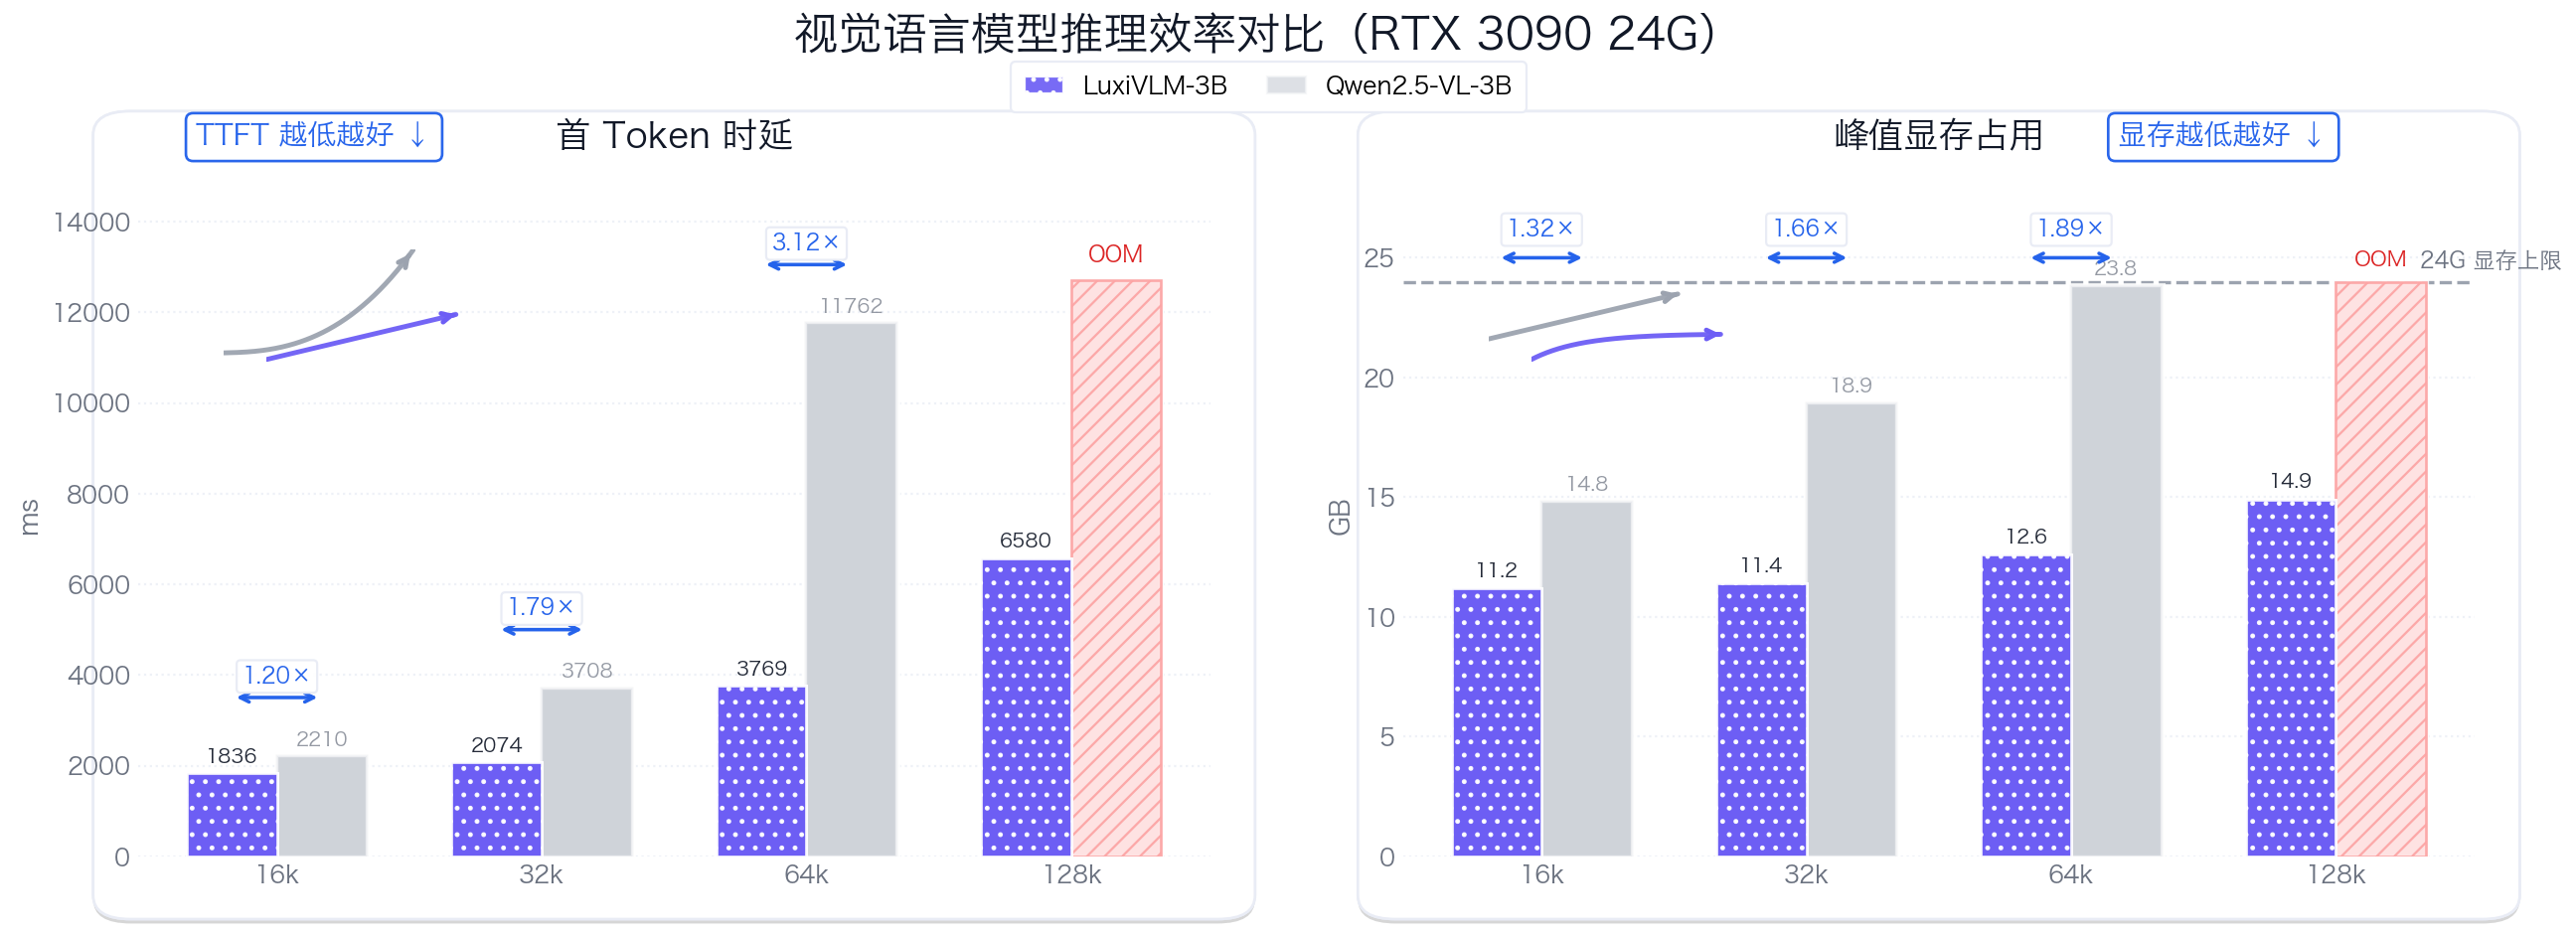

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm

# =========================
# Robust font setup for macOS
# =========================
def set_macos_chinese_font():
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC",
        "Arial Unicode MS", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

_ = set_macos_chinese_font()

# =========================
# Global style
# =========================
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# =========================
# Models / contexts / theme
# =========================
models = ["LuxiVLM-3B", "Qwen2.5-VL-3B"]
contexts = ["16k", "32k", "64k", "128k"]

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
    "danger":    "#DC2626",
}

COLOR = {
    "LuxiVLM-3B":    "#6D5EF5",
    "Qwen2.5-VL-3B":   "#D1D5DB",
}
QWEN_EDGE = "#F3F4F6"
HATCH = {"LuxiVLM-3B": ".."}

# =========================
# Data
# =========================
# TTFT (ms), user-provided measured values
ttft = {
    "Qwen2.5-VL-3B": [2210.36, 3708.07, 11761.57, np.nan],   # 128k OOM
    "LuxiVLM-3B":  [1836.21, 2073.77, 3768.69, 6580.24],
}

# Peak VRAM (GB) - estimated for vLLM on RTX 3090 24G
# NOTE:
# 1) These are estimated, not measured.
# 2) Since only the LLM attention is replaced by SWA, the gain should enlarge with longer context.
# 3) Qwen2.5-VL-3B at 128k is assumed OOM on 24G.
vram_actual = {
    "Qwen2.5-VL-3B": [14.8, 18.9, 23.8, 30.5],
    "LuxiVLM-3B":  [11.2, 11.4, 12.6, 14.9],
}

# For plotting only: cap OOM bar at 24G so it can be displayed inside chart
vram_plot = {
    "Qwen2.5-VL-3B": [14.8, 18.9, 23.8, 24.0],
    "LuxiVLM-3B":  [11.2, 11.4, 12.6, 14.9],
}

latency = np.array([ttft[m] for m in models], dtype=float)
vram = np.array([vram_plot[m] for m in models], dtype=float)

oom_latency = {
    "LuxiVLM-3B":  [False, False, False, False],
    "Qwen2.5-VL-3B": [False, False, False, True],
}
oom_vram = {
    "LuxiVLM-3B":  [False, False, False, False],
    "Qwen2.5-VL-3B": [False, False, False, True],
}

# =========================
# Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)
def add_corner_trend_icon(ax, kind="quadratic", color="#2563EB", anchor=(0.08, 0.76, 0.16, 0.16)):
    iax = ax.inset_axes(anchor)
    iax.set_facecolor("none")

    x = np.linspace(0, 1, 200)

    if kind == "quadratic":
        # 更陡、更明显上翘
        y = 0.05 + 0.04 * x + 0.92 * (x ** 2.6)

    elif kind == "linear":
        # 更平缓一些
        y = 0.18 + 0.42 * x

    elif kind == "flat":
        # 更早趋于平缓
        y = 0.18 + 0.24 * (1 - np.exp(-3.8 * x))

    else:
        y = 0.2 + 0.5 * x

    iax.plot(
        x, y,
        color=color,
        linewidth=2.2,
        solid_capstyle="round",
        alpha=0.95
    )

    iax.annotate(
        "",
        xy=(x[-1], y[-1]),
        xytext=(x[-8], y[-8]),
        arrowprops=dict(arrowstyle="->", lw=2.2, color=color)
    )

    iax.set_xticks([])
    iax.set_yticks([])
    for s in iax.spines.values():
        s.set_visible(False)

    iax.set_xlim(0, 1.02)
    iax.set_ylim(0, 1.02)
# =========================
# Left panel: TTFT
# =========================
def draw_grouped_ttft(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.34
    x = np.arange(len(contexts))
    vmax = np.nanmax(values)

    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen2.5-VL-3B")

        face = COLOR[m]
        edge = QWEN_EDGE if is_qwen else "#FFFFFF"
        hatch = None if is_qwen else HATCH.get(m, None)
        alpha = 0.72 if is_qwen else 0.92
        z = 2.75 if is_qwen else 3.0

        for j, v in enumerate(values[i]):
            xpos = x[j] + off

            if np.isnan(v):
                bar_h = vmax * 1.08
                bar = ax.bar(
                    xpos, bar_h, width=width,
                    color="#FEE2E2",
                    edgecolor="#FCA5A5",
                    linewidth=1.2,
                    hatch="///",
                    alpha=0.95,
                    zorder=2.6
                )
                for r in bar:
                    r.set_path_effects([
                        pe.Stroke(linewidth=2.8, foreground="white", alpha=0.85),
                        pe.Normal()
                    ])
                ax.text(
                    xpos, bar_h + vmax * 0.025, "OOM",
                    ha="center", va="bottom",
                    fontsize=10, color=THEME["danger"], fontweight="bold", zorder=8
                )
                continue

            bars = ax.bar(
                xpos, v,
                width=width,
                color=face,
                edgecolor=edge,
                linewidth=1.2 if not is_qwen else 1.0,
                alpha=alpha,
                hatch=hatch,
                zorder=z
            )

            for r in bars:
                if not is_qwen:
                    r.set_path_effects([
                        pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                        pe.Normal()
                    ])
                else:
                    r.set_path_effects([
                        pe.Stroke(linewidth=3.2, foreground="white", alpha=0.80),
                        pe.Stroke(linewidth=1.1, foreground=QWEN_EDGE, alpha=1.0),
                        pe.withSimplePatchShadow(offset=(0, -0.9), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                        pe.Normal()
                    ])

            txt_color = THEME["text"] if not is_qwen else THEME["muted"]
            txt_alpha = 0.92 if not is_qwen else 0.72

            ax.text(
                xpos,
                v + vmax * 0.012,
                f"{v:.0f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # improvement ratio: Qwen / LuxiLLM, because lower TTFT is better
    for j in range(len(contexts)):
        v_lincal = values[0][j]
        v_qwen = values[1][j]

        if np.isnan(v_lincal) or np.isnan(v_qwen):
            continue

        ratio = v_qwen / v_lincal
        y = max(v_lincal, v_qwen) + vmax * 0.11

        ax.annotate(
            "", xy=(x[j] + width/2, y), xytext=(x[j] - width/2, y),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )
        ax.text(
            x[j], y + vmax * 0.018,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )
    # 左上角趋势示意，不接触柱状图
    add_corner_trend_icon(
        ax,
        kind="quadratic",
        color="#9CA3AF",
        anchor=(0.08, 0.73, 0.18, 0.16)
    )
    add_corner_trend_icon(
        ax,
        kind="linear",
        color=COLOR["LuxiVLM-3B"],
        anchor=(0.12, 0.70, 0.18, 0.16)
    )
    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, vmax * 1.28)

# =========================
# Right panel: VRAM
# =========================
def draw_grouped_vram(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.34
    x = np.arange(len(contexts))
    limit_line = 24.0

    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen2.5-VL-3B")

        face = COLOR[m]
        edge = QWEN_EDGE if is_qwen else "#FFFFFF"
        hatch = None if is_qwen else HATCH.get(m, None)
        alpha = 0.72 if is_qwen else 0.92
        z = 2.75 if is_qwen else 3.0

        for j, v in enumerate(values[i]):
            xpos = x[j] + off
            oom_flag = oom_vram[m][j]
            actual = vram_actual[m][j]

            if oom_flag:
                bar = ax.bar(
                    xpos, v, width=width,
                    color="#FEE2E2",
                    edgecolor="#FCA5A5",
                    linewidth=1.2,
                    hatch="///",
                    alpha=0.95,
                    zorder=2.7
                )
                for r in bar:
                    r.set_path_effects([
                        pe.Stroke(linewidth=2.8, foreground="white", alpha=0.85),
                        pe.Normal()
                    ])
                ax.text(
                    xpos, v + 0.50,
                    "OOM",
                    ha="center", va="bottom",
                    fontsize=9.5,
                    color=THEME["danger"],
                    fontweight="bold",
                    zorder=8
                )
                continue

            bars = ax.bar(
                xpos, v, width=width,
                color=face,
                edgecolor=edge,
                linewidth=1.2 if not is_qwen else 1.0,
                alpha=alpha,
                hatch=hatch,
                zorder=z
            )

            for r in bars:
                if not is_qwen:
                    r.set_path_effects([
                        pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                        pe.Normal()
                    ])
                else:
                    r.set_path_effects([
                        pe.Stroke(linewidth=3.2, foreground="white", alpha=0.80),
                        pe.Stroke(linewidth=1.1, foreground=QWEN_EDGE, alpha=1.0),
                        pe.withSimplePatchShadow(offset=(0, -0.9), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                        pe.Normal()
                    ])

            txt_color = THEME["text"] if not is_qwen else THEME["muted"]
            txt_alpha = 0.92 if not is_qwen else 0.72

            ax.text(
                xpos,
                v + 0.32,
                f"{actual:.1f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # ratio = Qwen / Lincal, because lower VRAM is better
    for j in range(len(contexts)):
        q = vram_actual["Qwen2.5-VL-3B"][j]
        l = vram_actual["LuxiVLM-3B"][j]

        if j == 3:  # 128k Qwen OOM, no ratio label
            continue

        ratio = q / l
        y = 26.0

        x_lincal = x[j] - width/2
        x_qwen = x[j] + width/2

        ax.annotate(
            "", xy=(x_qwen, y - 1.0), xytext=(x_lincal, y - 1.0),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )

        ax.text(
            x[j], y - 0.3,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    ax.axhline(limit_line, linestyle="--", linewidth=1.5, color="#9CA3AF", zorder=1)
    ax.text(
        len(contexts)-0.15, limit_line + 0.35,
        "24G 显存上限",
        ha="right", va="bottom",
        fontsize=10,
        color="#6B7280"
    )
    # 左上角趋势示意，不接触柱状图
    add_corner_trend_icon(
        ax,
        kind="linear",
        color="#9CA3AF",
        anchor=(0.08, 0.73, 0.18, 0.16)
    )
    add_corner_trend_icon(
        ax,
        kind="flat",
        color=COLOR["LuxiVLM-3B"],
        anchor=(0.12, 0.70, 0.18, 0.16)
    )
    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, 28.5)

# =========================
# Plot
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.8), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

axes[0].set_title("首 Token 时延", color=THEME["text"], pad=12)
draw_grouped_ttft(axes[0], latency, "ms")

axes[1].set_title("峰值显存占用", color=THEME["text"], pad=12)
draw_grouped_vram(axes[1], vram, "GB")

legend_handles = [
    Patch(
        facecolor=COLOR["LuxiVLM-3B"],
        edgecolor="#FFFFFF",
        linewidth=1.0,
        hatch=HATCH.get("LuxiVLM-3B", None),
        alpha=0.92,
        label="LuxiVLM-3B"
    ),
    Patch(
        facecolor=COLOR["Qwen2.5-VL-3B"],
        edgecolor=QWEN_EDGE,
        linewidth=1.0,
        alpha=0.72,
        label="Qwen2.5-VL-3B"
    ),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.995),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

fig.text(
    0.5, 0.995,
    "视觉语言模型推理效率对比（RTX 3090 24G）",
    ha="center", fontsize=20, fontweight="bold", color=THEME["text"]
)

fig.text(
    0.12, 0.90, "TTFT 越低越好 ↓",
    ha="center", va="center",
    fontsize=13.0, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(
        boxstyle="round,pad=0.35,rounding_size=0.25",
        facecolor="white",
        edgecolor=THEME["accent"],
        linewidth=1.2,
        alpha=0.98
    )
)

fig.text(
    0.88, 0.90, "显存越低越好 ↓",
    ha="center", va="center",
    fontsize=13.0, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(
        boxstyle="round,pad=0.35,rounding_size=0.25",
        facecolor="white",
        edgecolor=THEME["accent"],
        linewidth=1.2,
        alpha=0.98
    )
)

fig.subplots_adjust(left=0.05, right=0.98, bottom=0.12, top=0.86, wspace=0.18)

plt.savefig("VL推理效率对比_RTX3090_24G_vllm.png", dpi=600, bbox_inches="tight")
plt.savefig("VL推理效率对比_RTX3090_24G_vllm.pdf", dpi=600, bbox_inches="tight")
plt.show()

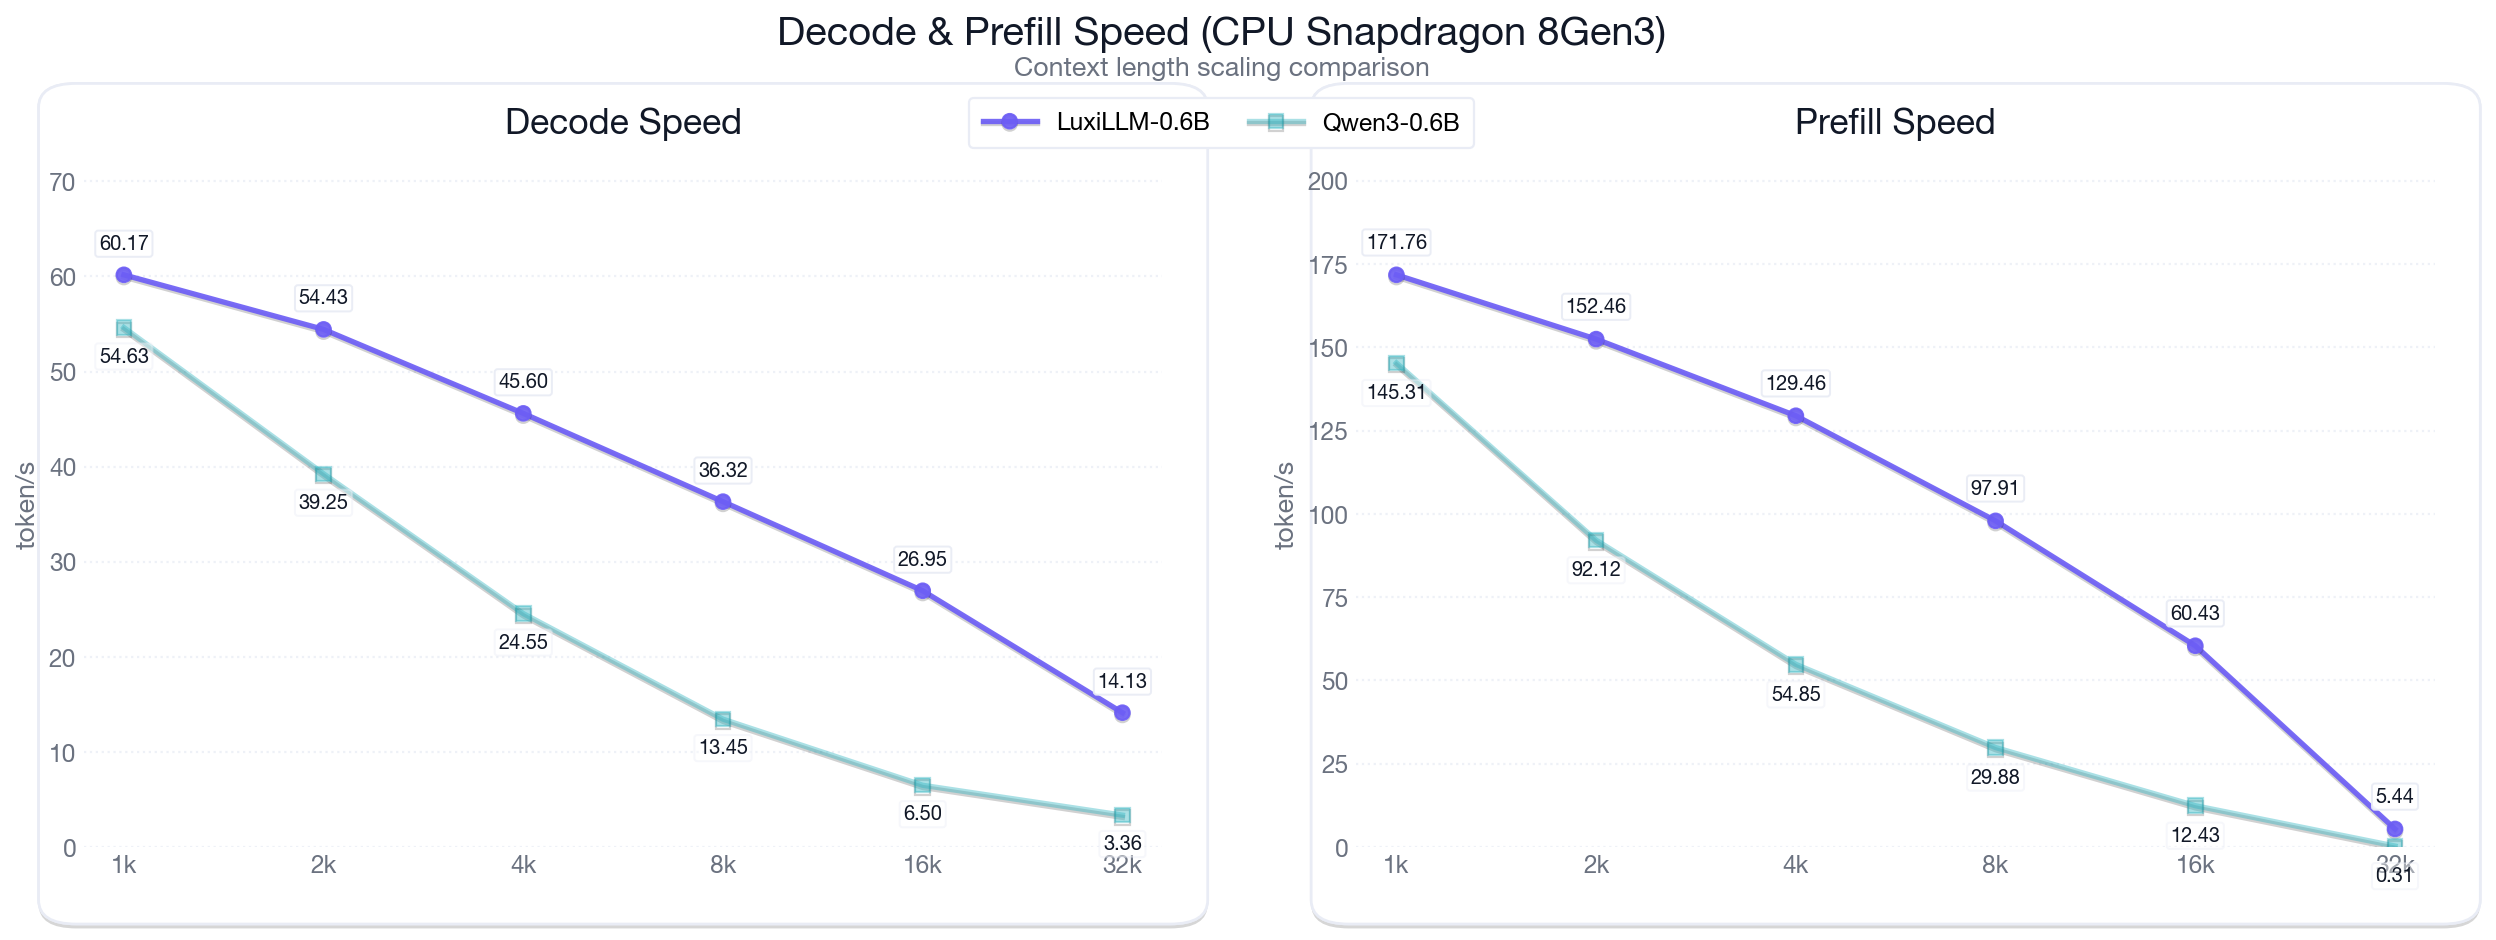

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import matplotlib.patheffects as pe

ALPHA = {
    "LuxiLLM-0.6B": 0.92,
    "Qwen3-0.6B": 0.4,        # 降透明度
}

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "font.family": "sans-serif",
    "font.sans-serif": ["PingFang SC", "SF Pro Display", "Helvetica Neue", "Arial Unicode MS", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
})

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
}

COLOR = {
    "LuxiLLM-0.6B": "#6D5EF5",
    "Qwen3-0.6B":          "#2BB3C0",
}
markers = {"LuxiLLM-0.6B": "o", "Qwen3-0.6B": "s"}

models = ["LuxiLLM-0.6B", "Qwen3-0.6B"]
contexts = ["1k", "2k", "4k", "8k", "16k", "32k"]
x = np.arange(len(contexts))
decode_pairs = {
    'LuxiLLM-0.6B': [60.17, 54.43, 45.60, 36.32, 26.95, 14.13],
    'Qwen3-0.6B':          [54.63, 39.25,  24.55, 13.45, 6.5, 3.36],
}

prefill_speed_data = {
    "Qwen3-0.6B":    [145.31, 92.12, 54.85, 29.88, 12.43, 0.31],
    "LuxiLLM-0.6B":  [171.76, 152.46, 129.46, 97.91, 60.43, 5.44],
}
prefill_pairs = {
    "LuxiLLM-0.6B": prefill_speed_data["LuxiLLM-0.6B"],
    "Qwen3-0.6B":          prefill_speed_data["Qwen3-0.6B"],
}

def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.10
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def plot_lines(ax, series_dict, title):
    add_card(ax)
    beautify_axes(ax, "token/s")
    ax.set_title(title, color=THEME["text"], pad=12)

    # 如果你之前在 ax 上画过 legend，这里强制清掉，避免“两个图例”
    lg = ax.get_legend()
    if lg is not None:
        lg.remove()

    # 用数据范围做一个自适应的标注偏移
    all_y = np.concatenate([np.array(series_dict[m], dtype=float) for m in models])
    y_span = max(1e-6, all_y.max() - all_y.min())
    dy = y_span * 0.04  # 标注竖直偏移比例

    for idx, m in enumerate(models):
        y = np.array(series_dict[m], dtype=float)
        
        (ln,) = ax.plot(
            x, y,
            linewidth=2.4,
            marker=markers[m],
            markersize=6.5,
            color=COLOR[m],
            #alpha=0.95,
            zorder=4,
            #edgecolor=EDGE.get(m, "#FFFFFF"),
            alpha=ALPHA.get(m, 0.92),
            #hatch=HATCH.get(m, None),
            label=m
        )
        ln.set_path_effects([pe.SimpleLineShadow(offset=(0, -1), alpha=0.18), pe.Normal()])

        # ✅ 每个点都标注数值：两条线错位（一个上一个下）减少重叠
        for k, (xx, yy) in enumerate(zip(x, y)):
            # Luxi 上移，Qwen 下移
            y_off = dy if idx == 0 else -dy * 0.9

            ax.text(
                xx, yy + y_off,
                f"{yy:.2f}",
                ha="center",
                va="bottom" if idx == 0 else "top",
                fontsize=9,
                color=THEME["text"],

                bbox=dict(
                    boxstyle="round,pad=0.18,rounding_size=0.15",
                    facecolor="white",
                    edgecolor=THEME["card_edge"],
                    linewidth=0.9,
                    alpha=ALPHA.get(m, 0.92),
                ),
                zorder=6
            )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_xlim(-0.2, len(contexts)-0.8)

    ymax = max(max(series_dict[m]) for m in models)
    ax.set_ylim(0, ymax * 1.20)

# =========================
# Figure
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.8), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

plot_lines(axes[0], decode_pairs, "Decode Speed")
plot_lines(axes[1], prefill_pairs, "Prefill Speed")

# ✅ 只做一个全局图例：从左图拿 handles，并去重
handles, labels = axes[0].get_legend_handles_labels()
uniq = {}
for h, l in zip(handles, labels):
    uniq[l] = h
handles_u = list(uniq.values())
labels_u = list(uniq.keys())

leg = fig.legend(
    handles_u, labels_u,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.94),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=2.2,
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

fig.text(0.5, 0.985, "Decode & Prefill Speed (CPU Snapdragon 8Gen3)", ha="center",
         fontsize=18, fontweight="bold", color=THEME["text"])
fig.text(0.5, 0.952, "Context length scaling comparison", ha="center",
         fontsize=12, color=THEME["muted"])

fig.subplots_adjust(left=0.05, right=0.98, bottom=0.12, top=0.86, wspace=0.18)

plt.savefig("decode_and_prefill_speed_line_white_8gen3.png", bbox_inches="tight")
plt.savefig("decode_and_prefill_speed_line_white_8gen3.pdf", bbox_inches="tight")
plt.show()

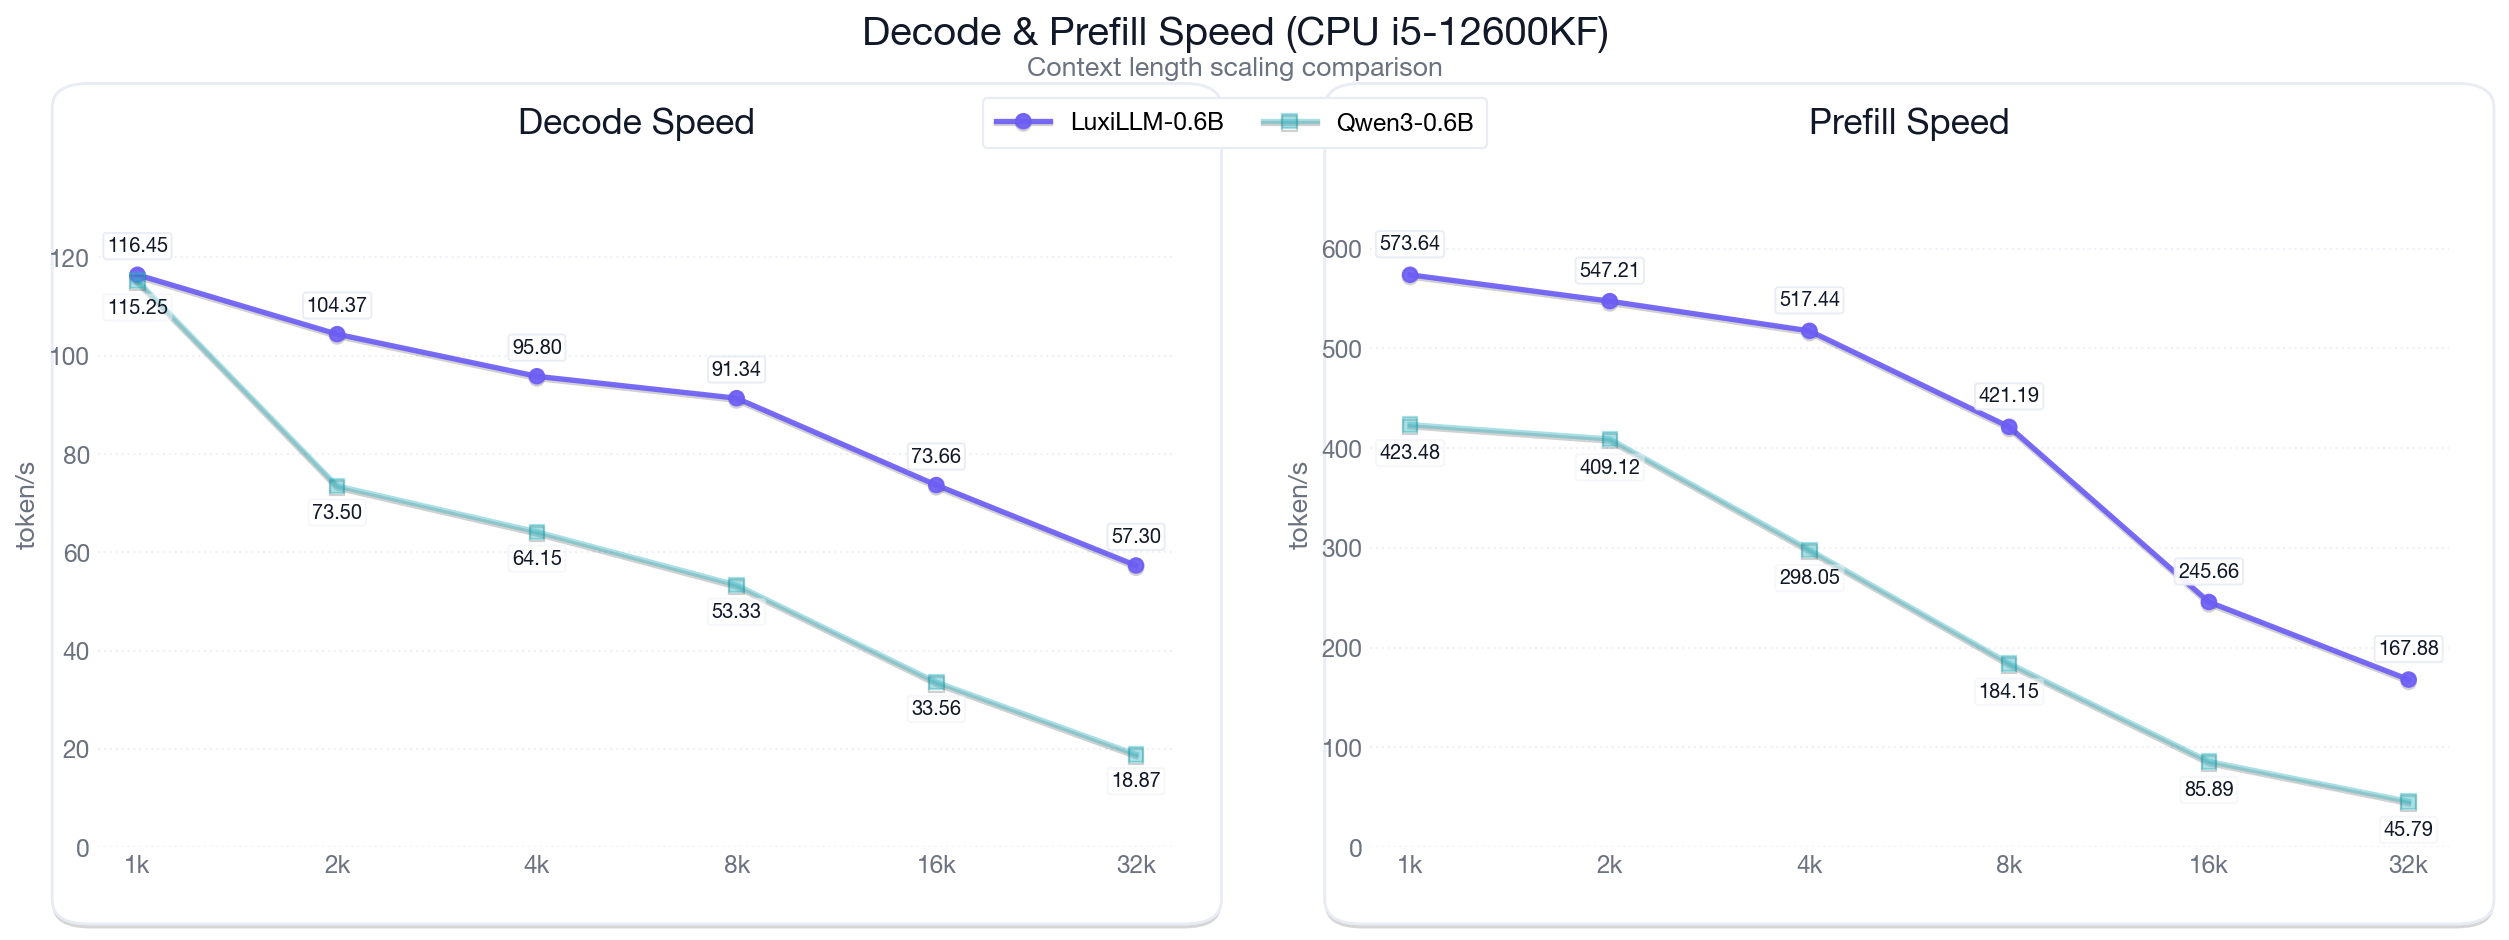

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import matplotlib.patheffects as pe
ALPHA = {
    "LuxiLLM-0.6B": 0.92,
    "Qwen3-0.6B": 0.4,        # 降透明度
}
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "font.family": "sans-serif",
    "font.sans-serif": ["PingFang SC", "SF Pro Display", "Helvetica Neue", "Arial Unicode MS", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
})

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
}

COLOR = {
    "LuxiLLM-0.6B": "#6D5EF5",
    "Qwen3-0.6B":          "#2BB3C0",
}
markers = {"LuxiLLM-0.6B": "o", "Qwen3-0.6B": "s"}

models = ["LuxiLLM-0.6B", "Qwen3-0.6B"]
contexts = ["1k", "2k", "4k", "8k", "16k", "32k"]
x = np.arange(len(contexts))

decode_pairs = {
    "LuxiLLM-0.6B": [116.45, 104.37, 95.80, 91.34, 73.66, 57.30],
    "Qwen3-0.6B":          [115.25, 73.50,  64.15, 53.33, 33.56, 18.87],
}

prefill_speed_data = {
    "Qwen3-0.6B":   [423.48, 409.12, 298.05, 184.15, 85.89, 45.79],
    "LuxiLLM-0.6B": [573.64, 547.21, 517.44, 421.19, 245.66, 167.88],
}
prefill_pairs = {
    "LuxiLLM-0.6B": prefill_speed_data["LuxiLLM-0.6B"],
    "Qwen3-0.6B":          prefill_speed_data["Qwen3-0.6B"],
}

def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.10
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def plot_lines(ax, series_dict, title):
    add_card(ax)
    beautify_axes(ax, "token/s")
    ax.set_title(title, color=THEME["text"], pad=12)

    # 如果你之前在 ax 上画过 legend，这里强制清掉，避免“两个图例”
    lg = ax.get_legend()
    if lg is not None:
        lg.remove()

    # 用数据范围做一个自适应的标注偏移
    all_y = np.concatenate([np.array(series_dict[m], dtype=float) for m in models])
    y_span = max(1e-6, all_y.max() - all_y.min())
    dy = y_span * 0.04  # 标注竖直偏移比例

    for idx, m in enumerate(models):
        y = np.array(series_dict[m], dtype=float)

        (ln,) = ax.plot(
            x, y,
            linewidth=2.4,
            marker=markers[m],
            markersize=6.5,
            color=COLOR[m],
            #alpha=0.95,
            alpha=ALPHA.get(m, 0.92),
            zorder=4,
            label=m
        )
        ln.set_path_effects([pe.SimpleLineShadow(offset=(0, -1), alpha=0.18), pe.Normal()])

        # ✅ 每个点都标注数值：两条线错位（一个上一个下）减少重叠
        for k, (xx, yy) in enumerate(zip(x, y)):
            # Luxi 上移，Qwen 下移
            y_off = dy if idx == 0 else -dy * 0.9

            ax.text(
                xx, yy + y_off,
                f"{yy:.2f}",
                ha="center",
                va="bottom" if idx == 0 else "top",
                fontsize=9,
                color=THEME["text"],
                bbox=dict(
                    boxstyle="round,pad=0.18,rounding_size=0.15",
                    facecolor="white",
                    edgecolor=THEME["card_edge"],
                    linewidth=0.9,
                    #alpha=0.95
                    alpha=ALPHA.get(m, 0.92),
                ),
                zorder=6
            )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_xlim(-0.2, len(contexts)-0.8)

    ymax = max(max(series_dict[m]) for m in models)
    ax.set_ylim(0, ymax * 1.20)

# =========================
# Figure
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.8), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

plot_lines(axes[0], decode_pairs, "Decode Speed")
plot_lines(axes[1], prefill_pairs, "Prefill Speed")

# ✅ 只做一个全局图例：从左图拿 handles，并去重
handles, labels = axes[0].get_legend_handles_labels()
uniq = {}
for h, l in zip(handles, labels):
    uniq[l] = h
handles_u = list(uniq.values())
labels_u = list(uniq.keys())

leg = fig.legend(
    handles_u, labels_u,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.94),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=2.2,
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

fig.text(0.5, 0.985, "Decode & Prefill Speed (CPU i5-12600KF)", ha="center",
         fontsize=18, fontweight="bold", color=THEME["text"])
fig.text(0.5, 0.952, "Context length scaling comparison", ha="center",
         fontsize=12, color=THEME["muted"])

fig.subplots_adjust(left=0.05, right=0.98, bottom=0.12, top=0.86, wspace=0.18)

plt.savefig("decode_and_prefill_speed_line_white.png", bbox_inches="tight")
plt.savefig("decode_and_prefill_speed_line_white.pdf", bbox_inches="tight")
plt.show()

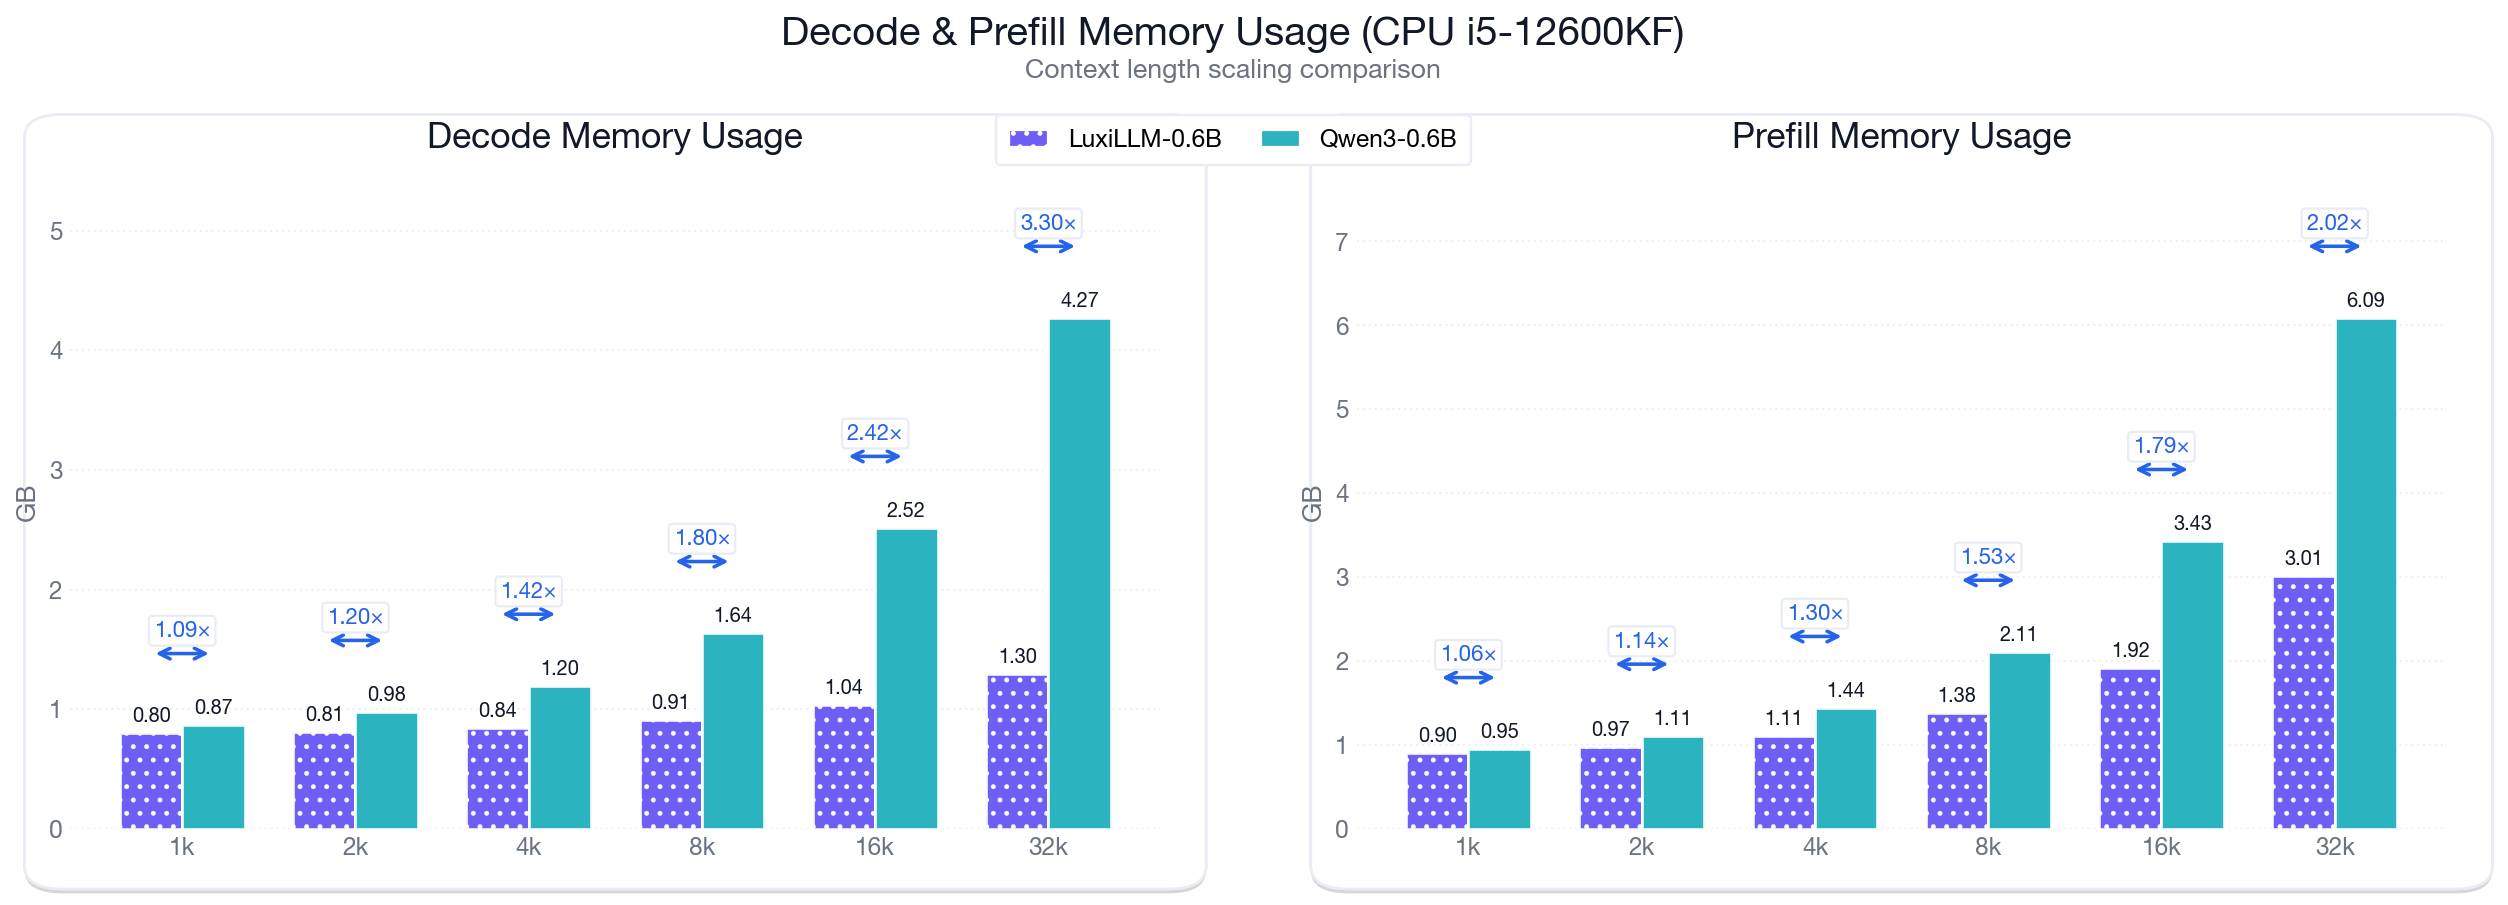

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "font.family": "sans-serif",
    "font.sans-serif": ["PingFang SC", "SF Pro Display", "Helvetica Neue", "Arial Unicode MS", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# =========================
# 1) Models + style
# =========================
models = ["LuxiLLM-0.6B", "Qwen3-0.6B"]
contexts = ['1k','2k','4k','8k','16k','32k']

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
}

# 紫 + 青蓝（更耐看）
COLOR = {
    "LuxiLLM-0.6B": "#6D5EF5",
    "Qwen3-0.6B":          "#2BB3C0",
}
HATCH = {"LuxiLLM-0.6B": ".."}  # 想更干净可改成 {}

# =========================
# 2) Data
# =========================
# decode 内存占用（来自你最初 pairs 的 mem）
decode_memory_pairs = {
    "LuxiLLM-0.6B": [0.798, 0.813, 0.845, 0.910, 1.039, 1.296],
    "Qwen3-0.6B":          [0.867, 0.977, 1.196, 1.636, 2.515, 4.271],
}
decode_mem = np.array([decode_memory_pairs[m] for m in models])

# prefill 内存占用（你提供的数据）
prefill_memory_data = {
    "Qwen3-0.6B":   [0.95, 1.11, 1.44, 2.11, 3.43, 6.09],
    "LuxiLLM-0.6B": [0.90, 0.97, 1.11, 1.38, 1.92, 3.01],
}
# ✅ key 映射：用 LuxiLLM-0.6B 的数据填到 LuxiLLM-0.6B
prefill_memory_pairs = {
    "LuxiLLM-0.6B": prefill_memory_data["LuxiLLM-0.6B"],
    "Qwen3-0.6B":          prefill_memory_data["Qwen3-0.6B"],
}
prefill_mem = np.array([prefill_memory_pairs[m] for m in models])

# =========================
# 3) Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def draw_grouped(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.36
    x = np.arange(len(contexts))
    vmax = values.max()

    # bars
    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        bars = ax.bar(
            x + off, values[i],
            width=width,
            color=COLOR[m],
            edgecolor="#FFFFFF",
            linewidth=1.2,
            alpha=0.92,
            hatch=HATCH.get(m, None),
            zorder=3
        )
        for r in bars:
            r.set_path_effects([
                pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                pe.Normal()
            ])
        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width()/2,
                rect.get_height() + vmax * 0.014,
                f"{v:.2f}",
                ha="center", va="bottom",
                fontsize=9,
                color=THEME["text"],
                zorder=6
            )

    # ratio arrows (still show max/min as ×)
    for j in range(len(contexts)):
        v0, v1 = values[0][j], values[1][j]
        if v0 >= v1:
            ratio = v0 / v1
            higher_off, lower_off = -width/2, +width/2
        else:
            ratio = v1 / v0
            higher_off, lower_off = +width/2, -width/2

        y = max(v0, v1) + vmax * 0.14
        ax.annotate(
            "", xy=(x[j] + lower_off, y), xytext=(x[j] + higher_off, y),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )
        ax.text(
            x[j], y + vmax * 0.025,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, vmax * 1.28)

# =========================
# 4) Plot
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.6), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

axes[0].set_title("Decode Memory Usage", color=THEME["text"], pad=12)
draw_grouped(axes[0], decode_mem, "GB")

axes[1].set_title("Prefill Memory Usage", color=THEME["text"], pad=12)
draw_grouped(axes[1], prefill_mem, "GB")

legend_handles = [
    Patch(facecolor=COLOR['LuxiLLM-0.6B'], edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get('LuxiLLM-0.6B', None), label="LuxiLLM-0.6B"),
    Patch(facecolor=COLOR['Qwen3-0.6B'], edgecolor="#FFFFFF", linewidth=1.0, label="Qwen3-0.6B"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.92),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

fig.text(0.5, 0.985, "Decode & Prefill Memory Usage (CPU i5-12600KF)", ha="center",
         fontsize=18, fontweight="bold", color=THEME["text"])
fig.text(0.5, 0.948, "Context length scaling comparison", ha="center",
         fontsize=12, color=THEME["muted"])

fig.subplots_adjust(left=0.04, right=0.98, bottom=0.11, top=0.84, wspace=0.18)

plt.savefig("decode_and_prefill_memory_white.png",dpi=600, bbox_inches="tight")
plt.savefig("decode_and_prefill_memory_white.pdf", bbox_inches="tight")
plt.show()

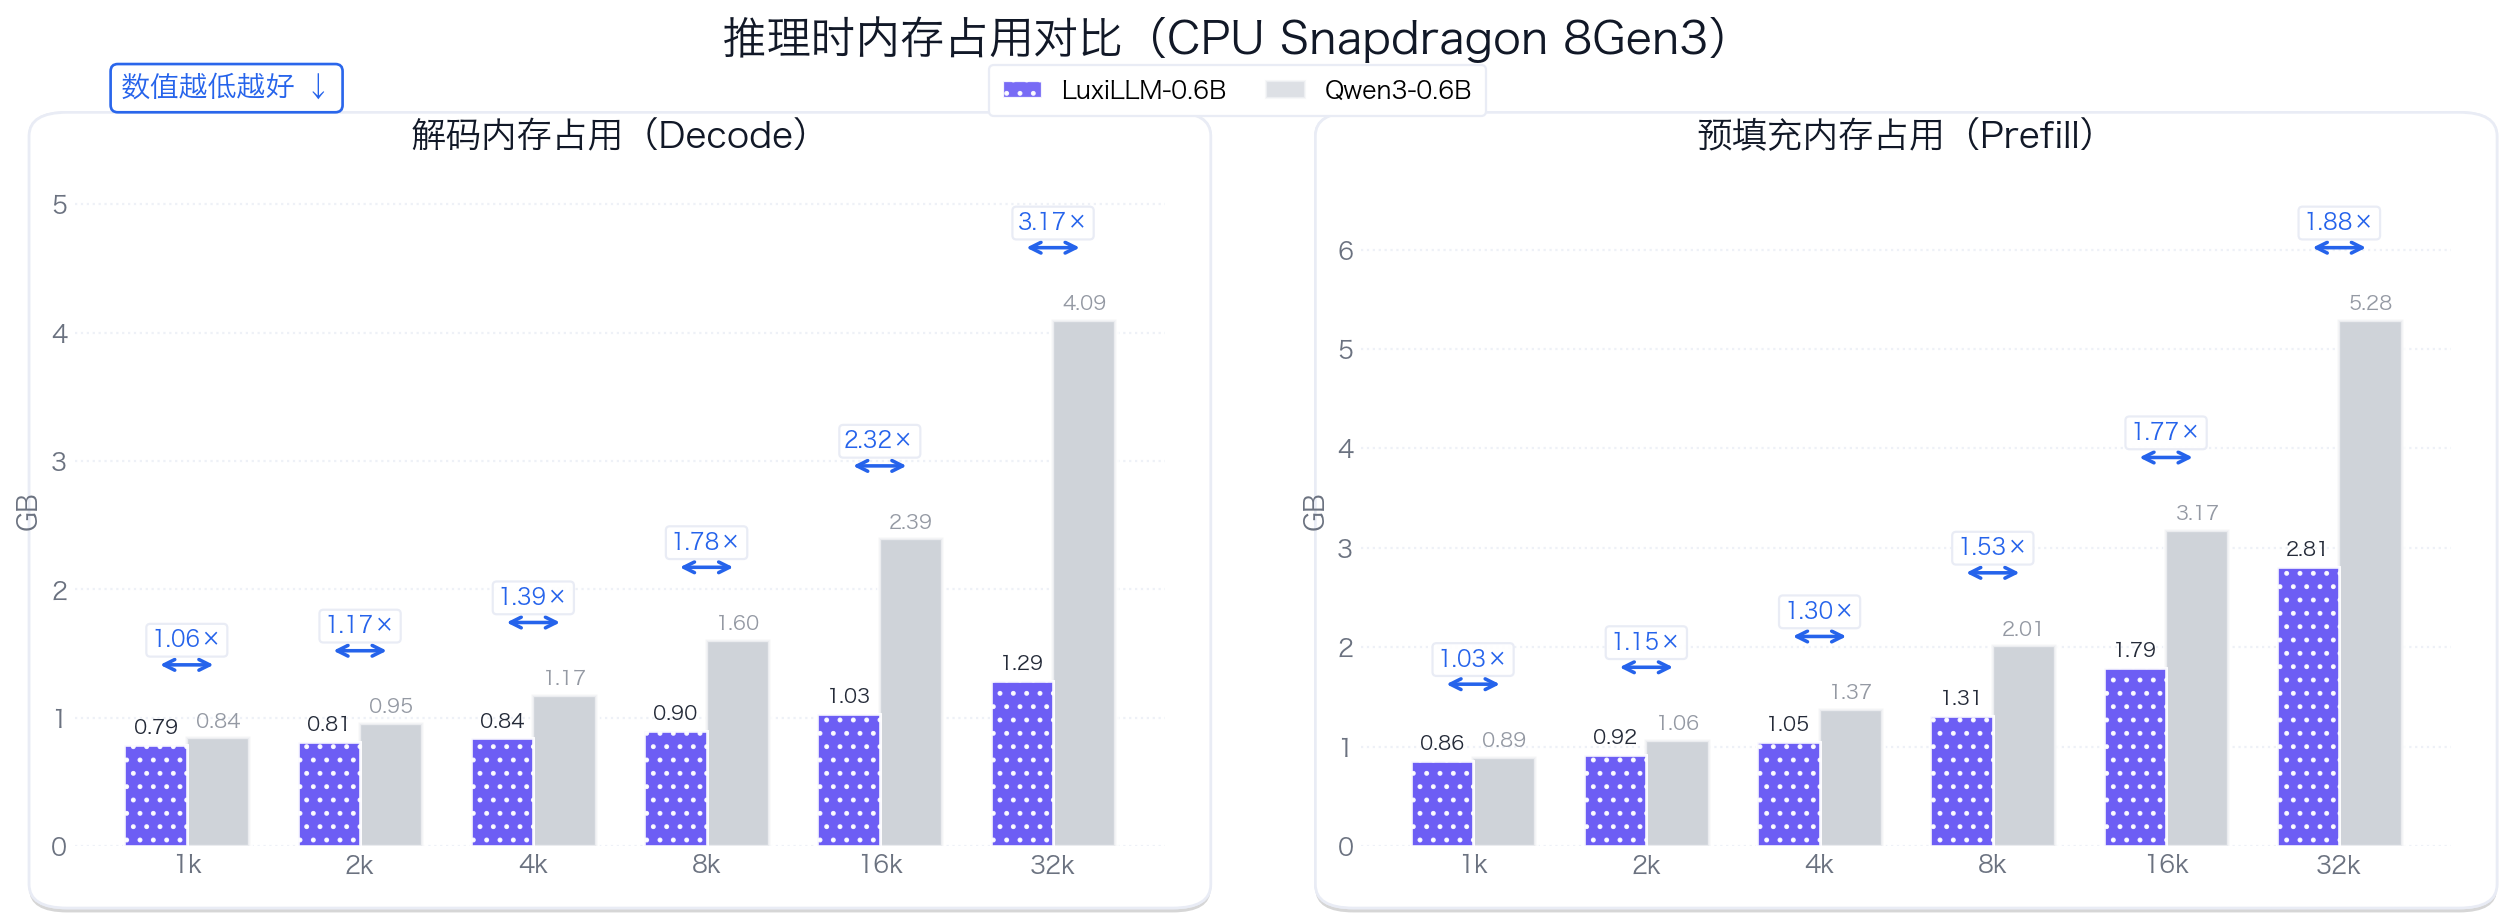

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm

# =========================
# Robust font setup for macOS (avoid "font not found" errors)
# =========================
def set_macos_chinese_font():
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC",
        "Arial Unicode MS", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

_ = set_macos_chinese_font()

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# =========================
# 1) Models + style
# =========================
models = ["LuxiLLM-0.6B", "Qwen3-0.6B"]
contexts = ['1k','2k','4k','8k','16k','32k']

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
}

COLOR = {
    "LuxiLLM-0.6B": "#6D5EF5",
    "Qwen3-0.6B":   "#D1D5DB",  # ✅ 浅灰
}
QWEN_EDGE = "#F3F4F6"
HATCH = {"LuxiLLM-0.6B": ".."}  # 想更干净可改成 {}

# =========================
# 2) Data
# =========================
decode_memory_pairs = {
    "LuxiLLM-0.6B": [0.79, 0.81, 0.84, 0.90, 1.03, 1.29],
    "Qwen3-0.6B":   [0.84, 0.95, 1.17, 1.60, 2.39, 4.09],
}
decode_mem = np.array([decode_memory_pairs[m] for m in models])

prefill_memory_data = {
    "Qwen3-0.6B":   [0.89, 1.06, 1.37, 2.01, 3.17, 5.28],
    "LuxiLLM-0.6B": [0.86, 0.92, 1.05, 1.31, 1.79, 2.81],
}
prefill_memory_pairs = {
    "LuxiLLM-0.6B": prefill_memory_data["LuxiLLM-0.6B"],
    "Qwen3-0.6B":   prefill_memory_data["Qwen3-0.6B"],
}
prefill_mem = np.array([prefill_memory_pairs[m] for m in models])

# =========================
# 3) Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def draw_grouped(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.36
    x = np.arange(len(contexts))
    vmax = values.max()

    # bars
    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen3-0.6B")

        if is_qwen:
            face = COLOR[m]
            edge = QWEN_EDGE
            hatch = None
            alpha = 0.72
            z = 2.75
        else:
            face = COLOR[m]
            edge = "#FFFFFF"
            hatch = HATCH.get(m, None)
            alpha = 0.92
            z = 3.0

        bars = ax.bar(
            x + off, values[i],
            width=width,
            color=face,
            edgecolor=edge,
            linewidth=1.2 if not is_qwen else 1.0,
            alpha=alpha,
            hatch=hatch,
            zorder=z
        )

        for r in bars:
            if not is_qwen:
                r.set_path_effects([
                    pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])
            else:
                r.set_path_effects([
                    pe.Stroke(linewidth=3.2, foreground="white", alpha=0.80),
                    pe.Stroke(linewidth=1.1, foreground=QWEN_EDGE, alpha=1.0),
                    pe.withSimplePatchShadow(offset=(0, -0.9), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])

        txt_color = THEME["text"] if not is_qwen else THEME["muted"]
        txt_alpha = 0.92 if not is_qwen else 0.72

        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width()/2,
                rect.get_height() + vmax * 0.014,
                f"{v:.2f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # ratio arrows
    for j in range(len(contexts)):
        v0, v1 = values[0][j], values[1][j]
        if v0 >= v1:
            ratio = v0 / v1
            higher_off, lower_off = -width/2, +width/2
        else:
            ratio = v1 / v0
            higher_off, lower_off = +width/2, -width/2

        y = max(v0, v1) + vmax * 0.14
        ax.annotate(
            "", xy=(x[j] + lower_off, y), xytext=(x[j] + higher_off, y),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )
        ax.text(
            x[j], y + vmax * 0.025,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, vmax * 1.28)

# =========================
# 4) Plot
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.6), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

axes[0].set_title("解码内存占用（Decode）", color=THEME["text"], pad=12)
draw_grouped(axes[0], decode_mem, "GB")

axes[1].set_title("预填充内存占用（Prefill）", color=THEME["text"], pad=12)
draw_grouped(axes[1], prefill_mem, "GB")

legend_handles = [
    Patch(facecolor=COLOR['LuxiLLM-0.6B'], edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get('LuxiLLM-0.6B', None), alpha=0.92, label="LuxiLLM-0.6B"),
    Patch(facecolor=COLOR['Qwen3-0.6B'], edgecolor=QWEN_EDGE, linewidth=1.0,
          alpha=0.72, label="Qwen3-0.6B"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.995),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

# ✅ Chinese title + callout: "lower is better"
fig.text(0.5, 0.995, "推理时KV Cache内存占用对比（NPU Snapdragon 8Elite Gen5）",
         ha="center", fontsize=20, fontweight="bold", color=THEME["text"])
fig.text(
    0.1, 0.956, "数值越低越好 ↓",
    ha="center", va="center",
    fontsize=13.0, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(
        boxstyle="round,pad=0.35,rounding_size=0.25",
        facecolor="white",
        edgecolor=THEME["accent"],
        linewidth=1.2,
        alpha=0.98
    )
)

fig.subplots_adjust(left=0.04, right=0.98, bottom=0.11, top=0.86, wspace=0.18)

plt.savefig("内存占用对比_NPU.png", dpi=600, bbox_inches="tight")
plt.savefig("内存占用对比_NPU.pdf", dpi=600, bbox_inches="tight")
plt.show()

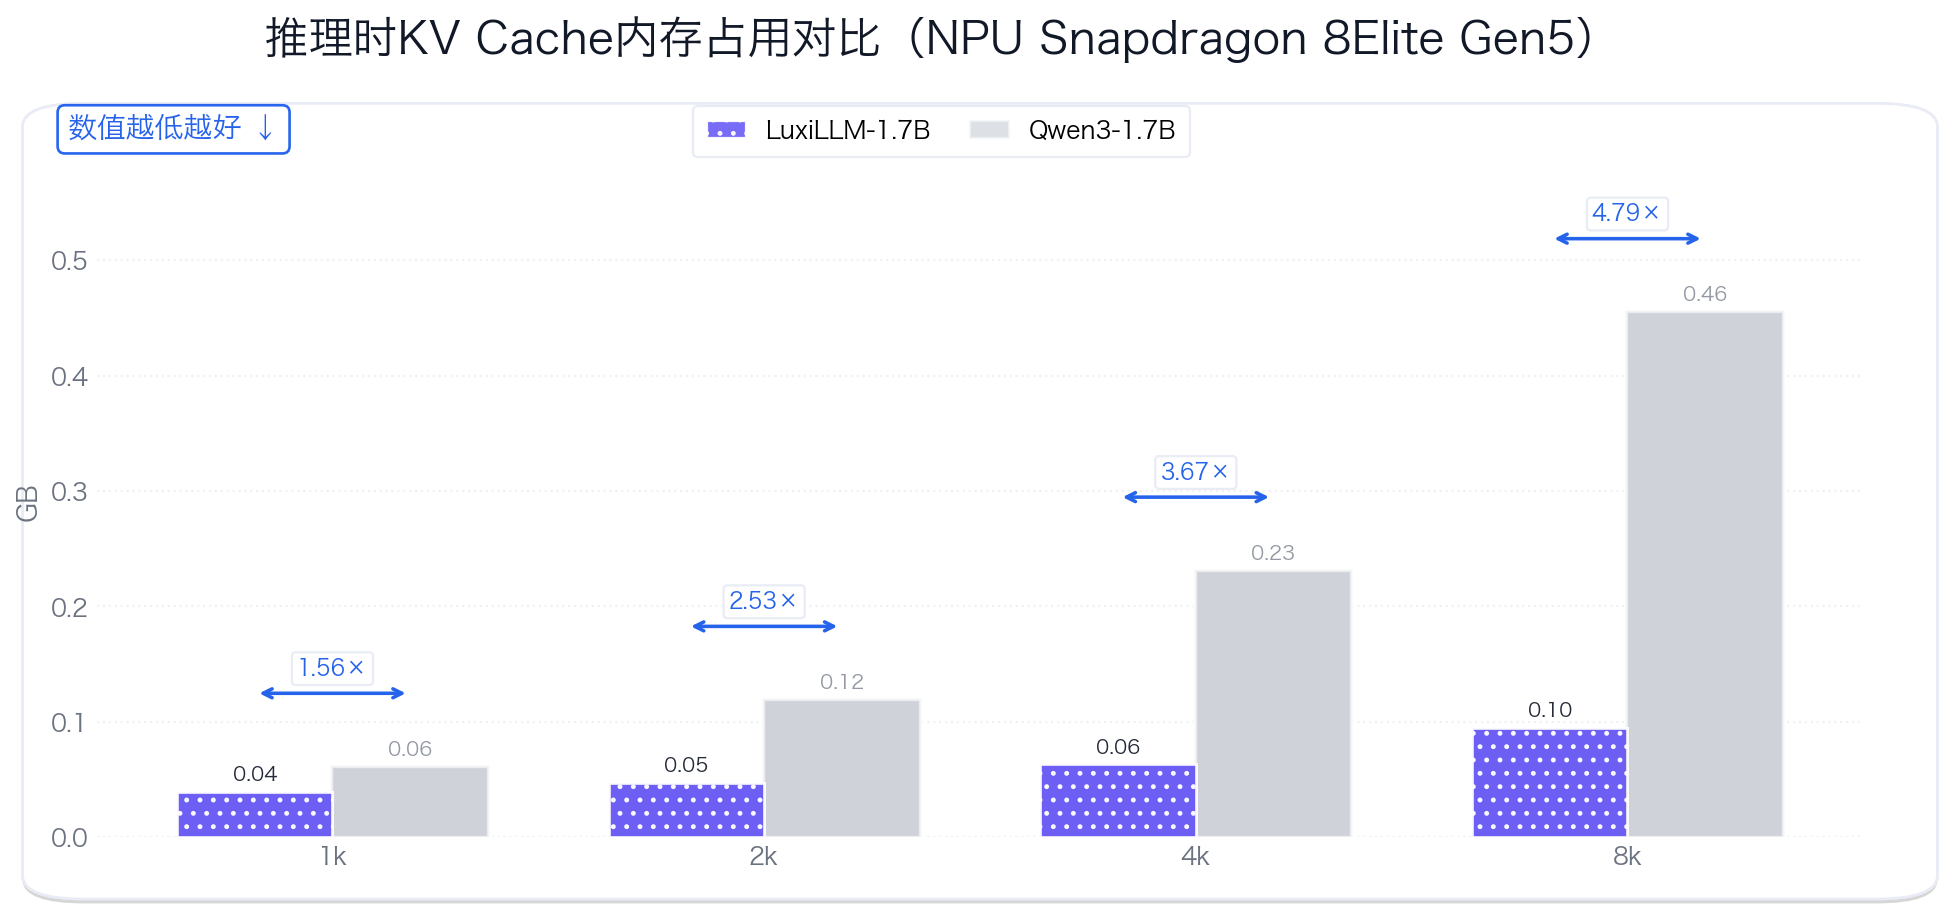

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm

# =========================
# Robust font setup for macOS (avoid "font not found" errors)
# =========================
def set_macos_chinese_font():
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC",
        "Arial Unicode MS", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

_ = set_macos_chinese_font()

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# =========================
# 1) Models + style
# =========================
models = ["LuxiLLM-1.7B", "Qwen3-1.7B"]
contexts = ['1k','2k','4k','8k']

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
}

COLOR = {
    "LuxiLLM-1.7B": "#6D5EF5",
    "Qwen3-1.7B":   "#D1D5DB",  # ✅ 浅灰
}
QWEN_EDGE = "#F3F4F6"
HATCH = {"LuxiLLM-1.7B": ".."}  # 想更干净可改成 {}

# =========================
# 2) Data (只保留 Decode)
# =========================
decode_memory_pairs = {
    "LuxiLLM-1.7B": [0.039, 0.047, 0.063, 0.095],
    "Qwen3-1.7B":   [0.061, 0.119, 0.231, 0.455],
}
decode_mem = np.array([decode_memory_pairs[m] for m in models])

# =========================
# 3) Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def draw_grouped(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.36
    x = np.arange(len(contexts))
    vmax = values.max()

    # bars
    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen3-1.7B")

        if is_qwen:
            face = COLOR[m]
            edge = QWEN_EDGE
            hatch = None
            alpha = 0.72
            z = 2.75
        else:
            face = COLOR[m]
            edge = "#FFFFFF"
            hatch = HATCH.get(m, None)
            alpha = 0.92
            z = 3.0

        bars = ax.bar(
            x + off, values[i],
            width=width,
            color=face,
            edgecolor=edge,
            linewidth=1.2 if not is_qwen else 1.0,
            alpha=alpha,
            hatch=hatch,
            zorder=z
        )

        for r in bars:
            if not is_qwen:
                r.set_path_effects([
                    pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])
            else:
                r.set_path_effects([
                    pe.Stroke(linewidth=3.2, foreground="white", alpha=0.80),
                    pe.Stroke(linewidth=1.1, foreground=QWEN_EDGE, alpha=1.0),
                    pe.withSimplePatchShadow(offset=(0, -0.9), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])

        txt_color = THEME["text"] if not is_qwen else THEME["muted"]
        txt_alpha = 0.92 if not is_qwen else 0.72

        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width()/2,
                rect.get_height() + vmax * 0.014,
                f"{v:.2f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # ratio arrows
    for j in range(len(contexts)):
        v0, v1 = values[0][j], values[1][j]
        if v0 >= v1:
            ratio = v0 / v1
            higher_off, lower_off = -width/2, +width/2
        else:
            ratio = v1 / v0
            higher_off, lower_off = +width/2, -width/2

        y = max(v0, v1) + vmax * 0.14
        ax.annotate(
            "", xy=(x[j] + lower_off, y), xytext=(x[j] + higher_off, y),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )
        ax.text(
            x[j], y + vmax * 0.025,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, vmax * 1.28)

# =========================
# 4) Plot - 单图版本
# =========================
fig, ax = plt.subplots(1, 1, figsize=(12, 5.6))  # 调整宽度更适合单图
fig.patch.set_facecolor(THEME["bg"])

draw_grouped(ax, decode_mem, "GB")

legend_handles = [
    Patch(facecolor=COLOR['LuxiLLM-1.7B'], edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get('LuxiLLM-1.7B', None), alpha=0.92, label="LuxiLLM-1.7B"),
    Patch(facecolor=COLOR['Qwen3-1.7B'], edgecolor=QWEN_EDGE, linewidth=1.0,
          alpha=0.72, label="Qwen3-1.7B"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.94),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

# ✅ Chinese title + callout: "lower is better"
fig.text(0.5, 0.985, "推理时KV Cache内存占用对比（NPU Snapdragon 8Elite Gen5）",
         ha="center", fontsize=20, fontweight="bold", color=THEME["text"])
fig.text(
    0.1, 0.900, "数值越低越好 ↓",
    ha="center", va="center",
    fontsize=13.0, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(
        boxstyle="round,pad=0.35,rounding_size=0.25",
        facecolor="white",
        edgecolor=THEME["accent"],
        linewidth=1.2,
        alpha=0.98
    )
)

# 调整边距以适配单图布局
fig.subplots_adjust(left=0.06, right=0.98, bottom=0.11, top=0.86)

plt.savefig("KV内存占用对比_NPU.png", dpi=600, bbox_inches="tight")
plt.savefig("KV内存占用对比_NPU.pdf", dpi=600, bbox_inches="tight")
plt.show()

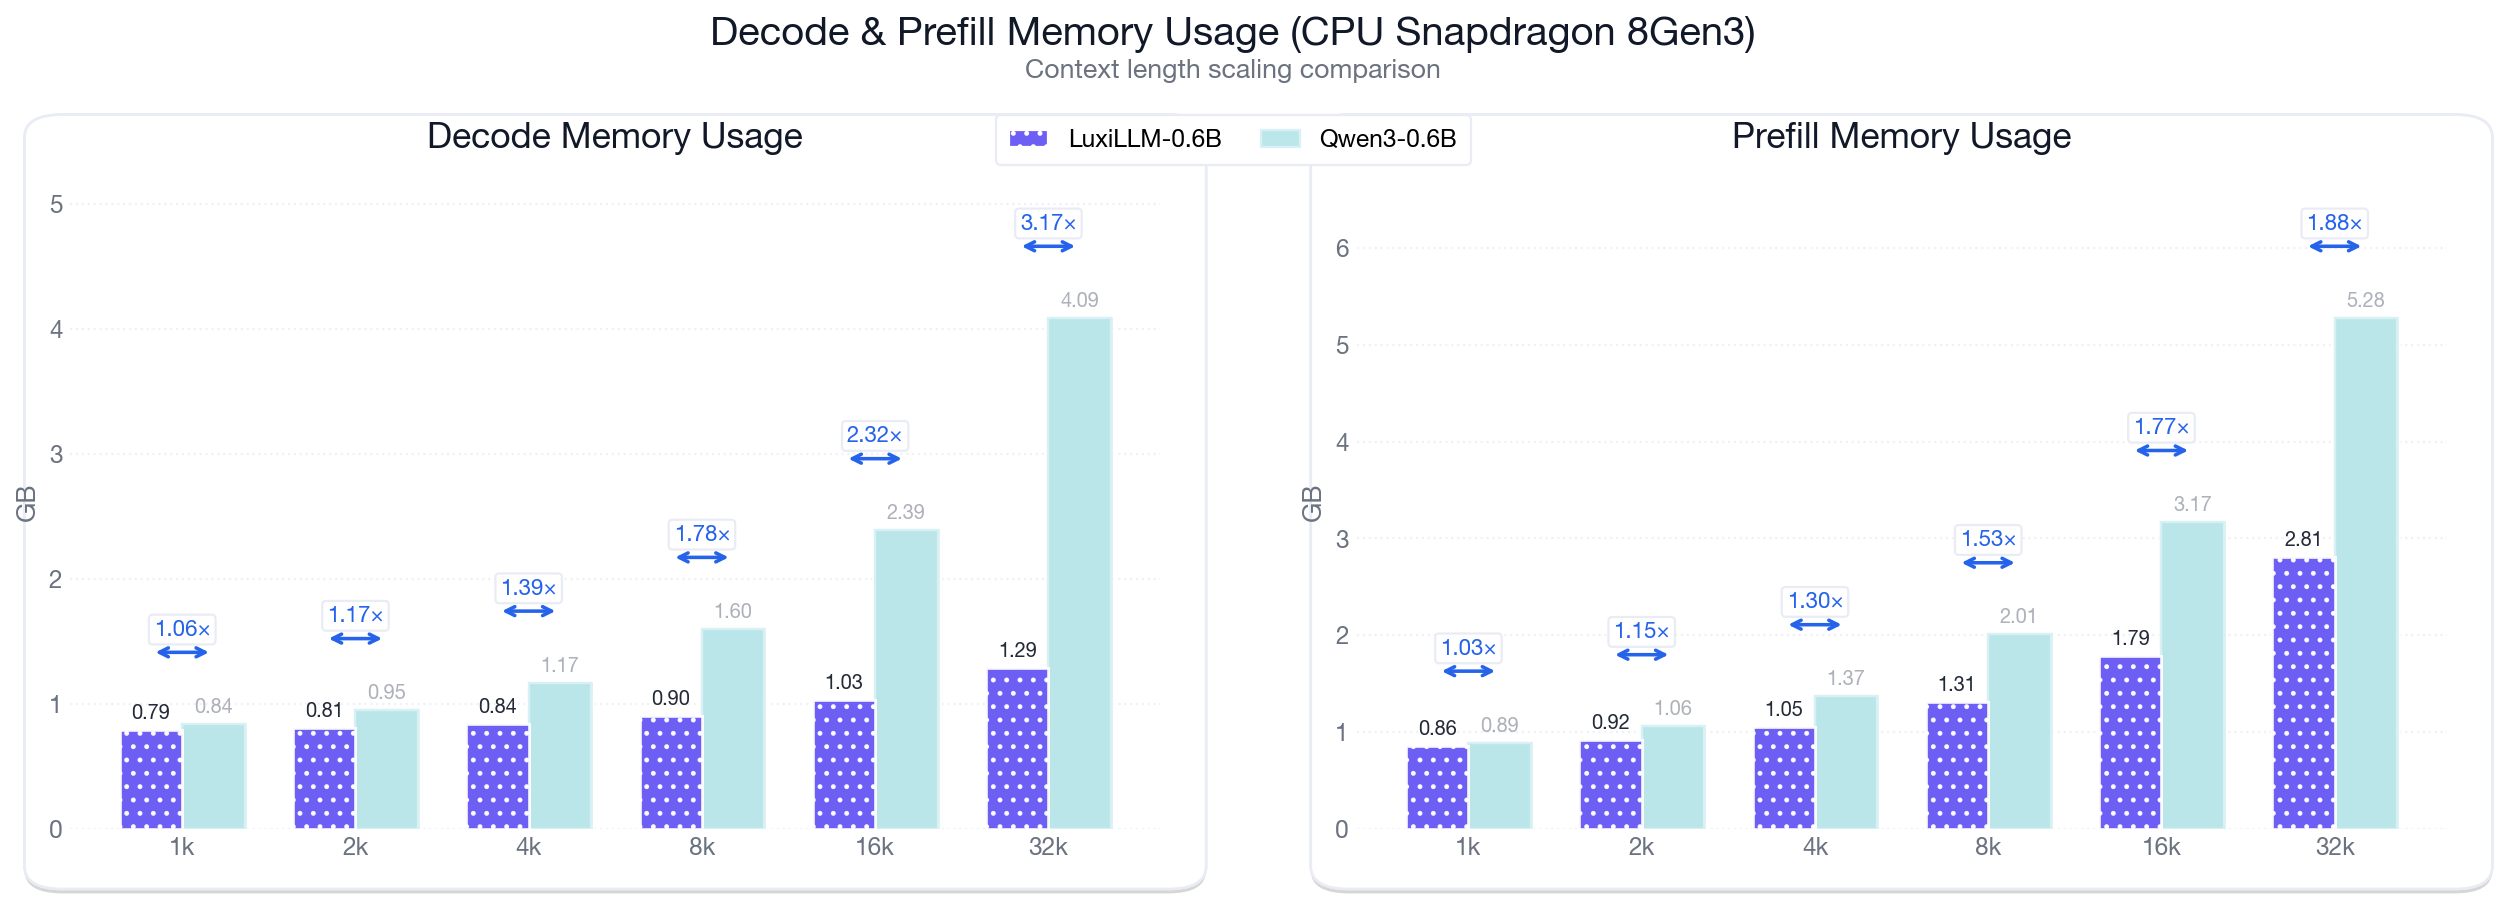

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "font.family": "sans-serif",
    "font.sans-serif": ["PingFang SC", "SF Pro Display", "Helvetica Neue", "Arial Unicode MS", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# =========================
# Helpers: "fade/blur-like" color treatment
# =========================
def hex_to_rgb01(h):
    h = h.lstrip("#")
    return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)]) / 255.0

def mix_with_white(hex_color, mix=0.68):
    """
    mix: 0~1, higher -> closer to white (more "hazy")
    """
    rgb = hex_to_rgb01(hex_color)
    out = (1 - mix) * rgb + mix * np.ones(3)
    return out

# =========================
# 1) Models + style
# =========================
models = ["LuxiLLM-0.6B", "Qwen3-0.6B"]
contexts = ['1k','2k','4k','8k','16k','32k']

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
}

# Indigo + Teal
COLOR = {
    "LuxiLLM-0.6B": "#6D5EF5",
    "Qwen3-0.6B":   "#2BB3C0",
}
HATCH = {"LuxiLLM-0.6B": ".."}  # set {} if you want it cleaner

# =========================
# 2) Data
# =========================
decode_memory_pairs = {
    "LuxiLLM-0.6B": [0.79, 0.81, 0.84, 0.90, 1.03, 1.29],
    "Qwen3-0.6B":   [0.84, 0.95, 1.17, 1.60, 2.39, 4.09],
}
decode_mem = np.array([decode_memory_pairs[m] for m in models])

prefill_memory_data = {
    "Qwen3-0.6B":   [0.89, 1.06, 1.37, 2.01, 3.17, 5.28],
    "LuxiLLM-0.6B": [0.86, 0.92, 1.05, 1.31, 1.79, 2.81],
}
prefill_memory_pairs = {
    "LuxiLLM-0.6B": prefill_memory_data["LuxiLLM-0.6B"],
    "Qwen3-0.6B":   prefill_memory_data["Qwen3-0.6B"],
}
prefill_mem = np.array([prefill_memory_pairs[m] for m in models])

# =========================
# 3) Plot helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2*pad_x, 1 + 2*pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def draw_grouped(ax, values, ylabel):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.36
    x = np.arange(len(contexts))
    vmax = values.max()

    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        is_qwen = (m == "Qwen3-0.6B")

        # ✅ Hazy Qwen look: tint toward white + soft edge
        if is_qwen:
            face = mix_with_white(COLOR[m], mix=0.68)   # 0.62~0.75
            edge = mix_with_white(COLOR[m], mix=0.82)
            hatch = None
            alpha = 0.95
            z = 2.8
        else:
            face = COLOR[m]
            edge = "#FFFFFF"
            hatch = HATCH.get(m, None)
            alpha = 0.92
            z = 3.0

        bars = ax.bar(
            x + off, values[i],
            width=width,
            color=face,
            edgecolor=edge,
            linewidth=1.2 if not is_qwen else 1.0,
            alpha=alpha,
            hatch=hatch,
            zorder=z
        )

        # Path effects
        for rct in bars:
            if not is_qwen:
                rct.set_path_effects([
                    pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])
            else:
                rct.set_path_effects([
                    pe.Stroke(linewidth=3.2, foreground="white", alpha=0.65),
                    pe.Stroke(linewidth=1.2, foreground=edge, alpha=0.95),
                    pe.withSimplePatchShadow(offset=(0, -0.8), alpha=0.08, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal()
                ])

        # Value labels (Qwen also hazy)
        txt_color = THEME["text"] if not is_qwen else THEME["muted"]
        txt_alpha = 0.92 if not is_qwen else 0.55

        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width()/2,
                rect.get_height() + vmax * 0.014,
                f"{v:.2f}",
                ha="center", va="bottom",
                fontsize=9,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6
            )

    # ratio arrows (max/min as ×)
    for j in range(len(contexts)):
        v0, v1 = values[0][j], values[1][j]
        if v0 >= v1:
            ratio = v0 / v1
            higher_off, lower_off = -width/2, +width/2
        else:
            ratio = v1 / v0
            higher_off, lower_off = +width/2, -width/2

        y = max(v0, v1) + vmax * 0.14
        ax.annotate(
            "", xy=(x[j] + lower_off, y), xytext=(x[j] + higher_off, y),
            arrowprops=dict(arrowstyle="<->", color=THEME["accent"], lw=1.6),
            zorder=7
        )
        ax.text(
            x[j], y + vmax * 0.025,
            f"{ratio:.2f}×",
            ha="center", va="bottom",
            fontsize=10,
            color=THEME["accent"],
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22,rounding_size=0.18",
                facecolor="white",
                edgecolor=THEME["card_edge"],
                linewidth=1.0,
                alpha=0.98
            ),
            zorder=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, vmax * 1.28)

# =========================
# 4) Plot
# =========================
fig, axes = plt.subplots(1, 2, figsize=(15.8, 5.6), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

axes[0].set_title("Decode Memory Usage", color=THEME["text"], pad=12)
draw_grouped(axes[0], decode_mem, "GB")

axes[1].set_title("Prefill Memory Usage", color=THEME["text"], pad=12)
draw_grouped(axes[1], prefill_mem, "GB")

# Legend: make Qwen look hazy too
legend_handles = [
    Patch(facecolor=COLOR['LuxiLLM-0.6B'], edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get('LuxiLLM-0.6B', None), label="LuxiLLM-0.6B"),
    Patch(facecolor=mix_with_white(COLOR['Qwen3-0.6B'], mix=0.68),
          edgecolor=mix_with_white(COLOR['Qwen3-0.6B'], mix=0.82),
          linewidth=1.0, label="Qwen3-0.6B"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.92),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

fig.text(0.5, 0.985, "Decode & Prefill Memory Usage (CPU Snapdragon 8Gen3)", ha="center",
         fontsize=18, fontweight="bold", color=THEME["text"])
fig.text(0.5, 0.948, "Context length scaling comparison", ha="center",
         fontsize=12, color=THEME["muted"])

fig.subplots_adjust(left=0.04, right=0.98, bottom=0.11, top=0.84, wspace=0.18)

plt.savefig("decode_and_prefill_memory_white_8Gen3.png", dpi=600, bbox_inches="tight")
plt.savefig("decode_and_prefill_memory_white_8Gen3.pdf", bbox_inches="tight")
plt.show()

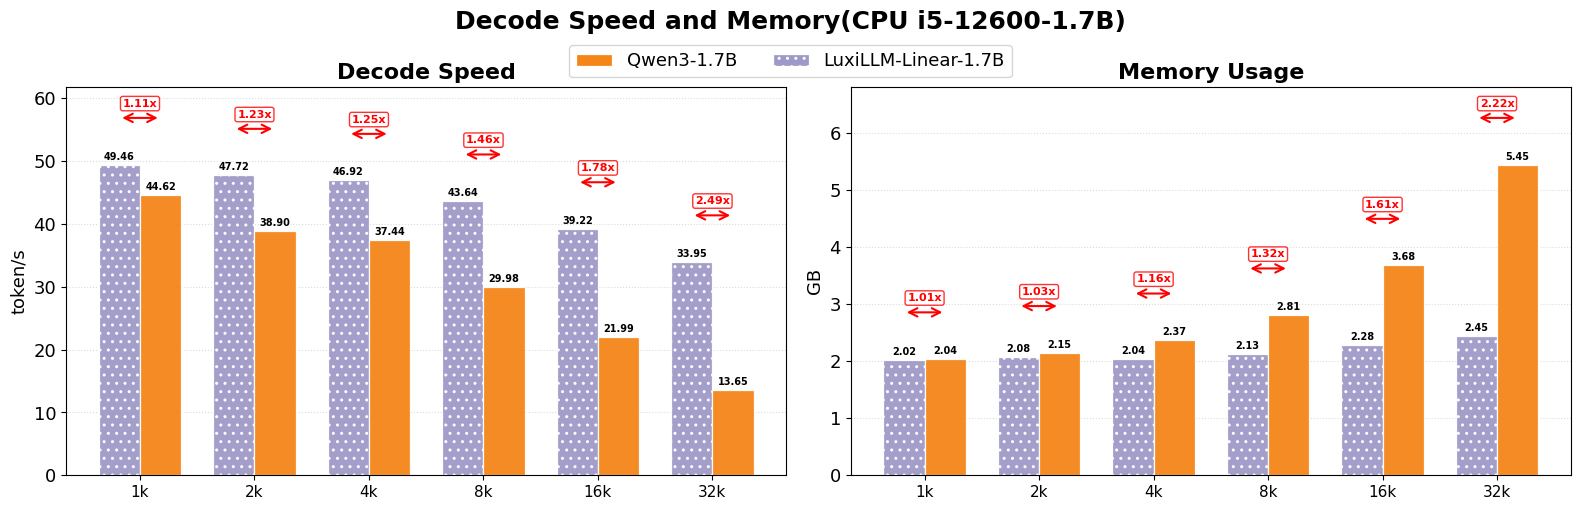

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, FancyArrowPatch

# ===== 1) 模型、颜色、hatch（与前面保持一致） =====
models = ['LuxiLLM-Linear-1.7B','Qwen3-1.7B']
COLOR = {
    'Qwen3-1.7B': '#F58518',
    'LuxiLLM-Linear-1.7B': '#9E9AC8',
}
HATCH = {'LuxiLLM-Linear-1.7B': '..'}  # LinCal 打点

# ===== 2) 数据（按"速度/内存占用(GB)"录入）=====
contexts = ['1k','2k','4k','8k','16k','32k']
pairs = {
    'LuxiLLM-Linear-1.7B': [
        (49.46, 2.02),
        (47.72, 2.08),
        (46.92,  2.04),
        (43.64,  2.13),
        (39.22,  2.28),
        (33.95,  2.45),
    ],
    'Qwen3-1.7B': [
        (44.62, 2.04),
        (38.90,  2.15),
        (37.44,  2.37),
        (29.98,  2.81),
        (21.99,  3.68),
        (13.65,  5.45),
    ],
}

# 把 pairs 拆成速度矩阵与内存矩阵
speed = np.array([[p[0] for p in pairs[m]] for m in models])
mem   = np.array([[p[1] for p in pairs[m]] for m in models])

# ===== 3) 画图：两列并排（左：速度；右：内存）=====
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))  # 增加宽度给箭头留空间
width = 0.36
x = np.arange(len(contexts))

def draw_grouped(ax, values, ylabel, is_speed=True):
    # 绘制柱状图
    bars_list = []
    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        bars = ax.bar(x + off, values[i], width=width,
                      color=COLOR[m], edgecolor='white', linewidth=0.9, alpha=0.95,
                      hatch=HATCH.get(m, None))
        bars_list.append(bars)
        
        # 数值标注
        for rect, v in zip(bars, values[i]):
            text_offset = values.max() * 0.01
            ax.text(rect.get_x() + rect.get_width()/2, 
                   rect.get_height() + text_offset,
                   f'{v:.2f}', 
                   ha='center', 
                   va='bottom', 
                   fontsize=7, 
                   fontweight='bold')
    
    # 添加红色箭头和倍数比较
    for j in range(len(contexts)):
        # 计算两个柱状图的值
        val1 = values[0][j]  # LinCal
        val2 = values[1][j]  # Qwen3
        
        # 计算倍数（总是用较大的值除以较小的值）
        if val1 > val2:
            ratio = val1 / val2
            higher_idx, lower_idx = 0, 1
        else:
            ratio = val2 / val1
            higher_idx, lower_idx = 1, 0
        
        # 箭头位置
        x_center = x[j]
        higher_val = max(val1, val2)
        lower_val = min(val1, val2)
        
        # 箭头起始和结束位置
        arrow_start = x_center + (higher_idx - 0.5) * width
        arrow_end = x_center + (lower_idx - 0.5) * width
        
        # 箭头高度（在最高柱状图上方）
        arrow_y = higher_val + values.max() * 0.15
        
        # 绘制箭头
        arrow = FancyArrowPatch(
            (arrow_start, arrow_y), 
            (arrow_end, arrow_y),
            arrowstyle='<->', 
            color='red', 
            linewidth=1.5,
            mutation_scale=15
        )
        ax.add_patch(arrow)
        
        # 添加倍数文本
        ratio_text = f'{ratio:.2f}x'
        ax.text(x_center, arrow_y + values.max() * 0.03, 
               ratio_text, 
               ha='center', 
               va='bottom', 
               fontsize=8, 
               fontweight='bold',
               color='red',
               bbox=dict(boxstyle="round,pad=0.2", facecolor='white', edgecolor='red', alpha=0.8))
    
    ax.set_ylabel(ylabel, fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(contexts, rotation=0, fontsize=11)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)
    ymax = values.max() * (1 + 0.25)  # 增加上限给箭头留空间
    ax.set_ylim(0, ymax)

# 左：decode 速度
axes[0].set_title('Decode Speed', fontsize=16, fontweight='bold')
draw_grouped(axes[0], speed, 'token/s', is_speed=True)

# 右：内存占用
axes[1].set_title('Memory Usage', fontsize=16, fontweight='bold')
draw_grouped(axes[1], mem, 'GB', is_speed=False)

# ===== 顶部统一图例 =====
legend_handles = [
    Patch(facecolor=COLOR['Qwen3-1.7B'], edgecolor='white', linewidth=0.9, label='Qwen3-1.7B'),
    Patch(facecolor=COLOR['LuxiLLM-Linear-1.7B'], edgecolor='white', linewidth=0.9, hatch='..', label='LuxiLLM-Linear-1.7B'),
]
fig.legend(handles=legend_handles, loc='upper center', ncol=2, frameon=True, fancybox=True, bbox_to_anchor=(0.5, 0.93))

# 总标题 & 布局与导出
fig.suptitle('Decode Speed and Memory(CPU i5-12600-1.7B)', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()

plt.savefig('decode_speed_and_memoryCPU-1_7B.png', dpi=600, bbox_inches='tight')
plt.savefig('decode_speed_and_memoryCPU-1_7B.pdf', dpi=600, bbox_inches='tight')
plt.show()

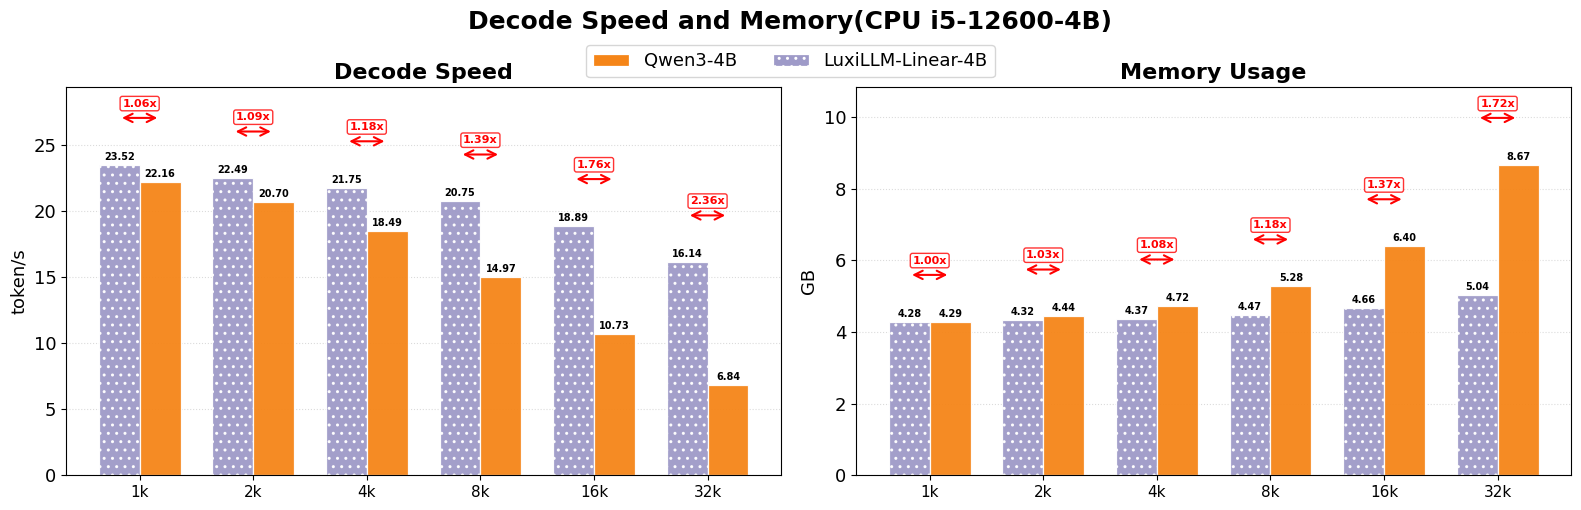

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, FancyArrowPatch

# ===== 1) 模型、颜色、hatch（与前面保持一致） =====
models = ['LuxiLLM-Linear-4B','Qwen3-4B']
COLOR = {
    'Qwen3-4B': '#F58518',
    'LuxiLLM-Linear-4B': '#9E9AC8',
}
HATCH = {'LuxiLLM-Linear-4B': '..'}  # LinCal 打点

# ===== 2) 数据（按"速度/内存占用(GB)"录入）=====
contexts = ['1k','2k','4k','8k','16k','32k']
pairs = {
    'LuxiLLM-Linear-4B': [
        (23.52, 4.28),
        (22.49, 4.32),
        (21.75,  4.37),
        (20.75,  4.47),
        (18.89,  4.66),
        (16.14,  5.04),
    ],
    'Qwen3-4B': [
        (22.16, 4.29),
        (20.7,  4.44),
        (18.49,  4.72),
        (14.97,  5.28),
        (10.73,  6.40),
        (6.84,  8.67),
    ],
}

# 把 pairs 拆成速度矩阵与内存矩阵
speed = np.array([[p[0] for p in pairs[m]] for m in models])
mem   = np.array([[p[1] for p in pairs[m]] for m in models])

# ===== 3) 画图：两列并排（左：速度；右：内存）=====
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))  # 增加宽度给箭头留空间
width = 0.36
x = np.arange(len(contexts))

def draw_grouped(ax, values, ylabel, is_speed=True):
    # 绘制柱状图
    bars_list = []
    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        bars = ax.bar(x + off, values[i], width=width,
                      color=COLOR[m], edgecolor='white', linewidth=0.9, alpha=0.95,
                      hatch=HATCH.get(m, None))
        bars_list.append(bars)
        
        # 数值标注
        for rect, v in zip(bars, values[i]):
            text_offset = values.max() * 0.01
            ax.text(rect.get_x() + rect.get_width()/2, 
                   rect.get_height() + text_offset,
                   f'{v:.2f}', 
                   ha='center', 
                   va='bottom', 
                   fontsize=7, 
                   fontweight='bold')
    
    # 添加红色箭头和倍数比较
    for j in range(len(contexts)):
        # 计算两个柱状图的值
        val1 = values[0][j]  # LinCal
        val2 = values[1][j]  # Qwen3
        
        # 计算倍数（总是用较大的值除以较小的值）
        if val1 > val2:
            ratio = val1 / val2
            higher_idx, lower_idx = 0, 1
        else:
            ratio = val2 / val1
            higher_idx, lower_idx = 1, 0
        
        # 箭头位置
        x_center = x[j]
        higher_val = max(val1, val2)
        lower_val = min(val1, val2)
        
        # 箭头起始和结束位置
        arrow_start = x_center + (higher_idx - 0.5) * width
        arrow_end = x_center + (lower_idx - 0.5) * width
        
        # 箭头高度（在最高柱状图上方）
        arrow_y = higher_val + values.max() * 0.15
        
        # 绘制箭头
        arrow = FancyArrowPatch(
            (arrow_start, arrow_y), 
            (arrow_end, arrow_y),
            arrowstyle='<->', 
            color='red', 
            linewidth=1.5,
            mutation_scale=15
        )
        ax.add_patch(arrow)
        
        # 添加倍数文本
        ratio_text = f'{ratio:.2f}x'
        ax.text(x_center, arrow_y + values.max() * 0.03, 
               ratio_text, 
               ha='center', 
               va='bottom', 
               fontsize=8, 
               fontweight='bold',
               color='red',
               bbox=dict(boxstyle="round,pad=0.2", facecolor='white', edgecolor='red', alpha=0.8))
    
    ax.set_ylabel(ylabel, fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(contexts, rotation=0, fontsize=11)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)
    ymax = values.max() * (1 + 0.25)  # 增加上限给箭头留空间
    ax.set_ylim(0, ymax)

# 左：decode 速度
axes[0].set_title('Decode Speed', fontsize=16, fontweight='bold')
draw_grouped(axes[0], speed, 'token/s', is_speed=True)

# 右：内存占用
axes[1].set_title('Memory Usage', fontsize=16, fontweight='bold')
draw_grouped(axes[1], mem, 'GB', is_speed=False)

# ===== 顶部统一图例 =====
legend_handles = [
    Patch(facecolor=COLOR['Qwen3-4B'], edgecolor='white', linewidth=0.9, label='Qwen3-4B'),
    Patch(facecolor=COLOR['LuxiLLM-Linear-4B'], edgecolor='white', linewidth=0.9, hatch='..', label='LuxiLLM-Linear-4B'),
]
fig.legend(handles=legend_handles, loc='upper center', ncol=2, frameon=True, fancybox=True, bbox_to_anchor=(0.5, 0.93))

# 总标题 & 布局与导出
fig.suptitle('Decode Speed and Memory(CPU i5-12600-4B)', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()

plt.savefig('decode_speed_and_memoryCPU-4B.png', dpi=600, bbox_inches='tight')
plt.savefig('decode_speed_and_memoryCPU-4B.pdf', dpi=600, bbox_inches='tight')
plt.show()

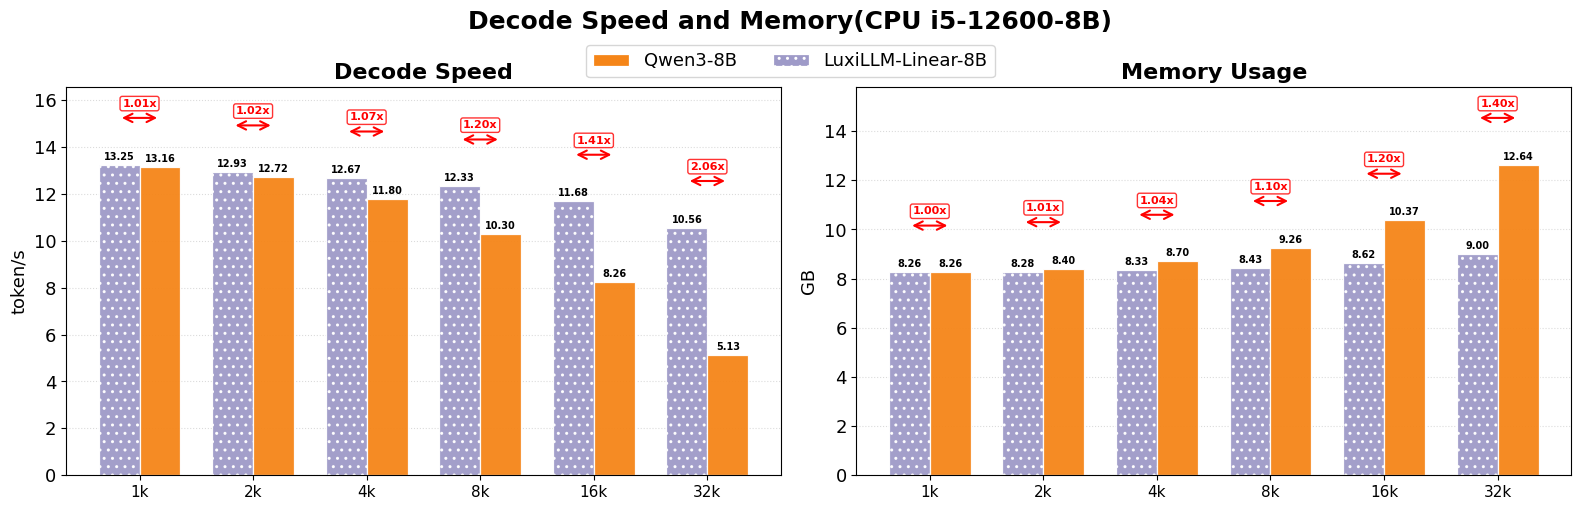

In [19]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, FancyArrowPatch

# ===== 1) 模型、颜色、hatch（与前面保持一致） =====
models = ['LuxiLLM-Linear-8B','Qwen3-8B']
COLOR = {
    'Qwen3-8B': '#F58518',
    'LuxiLLM-Linear-8B': '#9E9AC8',
}
HATCH = {'LuxiLLM-Linear-8B': '..'}  # LinCal 打点

# ===== 2) 数据（按"速度/内存占用(GB)"录入）=====
contexts = ['1k','2k','4k','8k','16k','32k']
pairs = {
    'LuxiLLM-Linear-8B': [
        (13.25, 8.26),
        (12.93, 8.28),
        (12.67, 8.33),
        (12.33, 8.43),
        (11.68, 8.62),
        (10.56, 9.00),
    ],
    'Qwen3-8B': [ 	 	 	 	 	 
        (13.16, 8.26),
        (12.72, 8.40),
        (11.80, 8.70),
        (10.30, 9.26),
        (8.26, 10.37),
        (5.13, 12.64),
    ],
}

# 把 pairs 拆成速度矩阵与内存矩阵
speed = np.array([[p[0] for p in pairs[m]] for m in models])
mem   = np.array([[p[1] for p in pairs[m]] for m in models])

# ===== 3) 画图：两列并排（左：速度；右：内存）=====
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))  # 增加宽度给箭头留空间
width = 0.36
x = np.arange(len(contexts))

def draw_grouped(ax, values, ylabel, is_speed=True):
    # 绘制柱状图
    bars_list = []
    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        bars = ax.bar(x + off, values[i], width=width,
                      color=COLOR[m], edgecolor='white', linewidth=0.9, alpha=0.95,
                      hatch=HATCH.get(m, None))
        bars_list.append(bars)
        
        # 数值标注
        for rect, v in zip(bars, values[i]):
            text_offset = values.max() * 0.01
            ax.text(rect.get_x() + rect.get_width()/2, 
                   rect.get_height() + text_offset,
                   f'{v:.2f}', 
                   ha='center', 
                   va='bottom', 
                   fontsize=7, 
                   fontweight='bold')
    
    # 添加红色箭头和倍数比较
    for j in range(len(contexts)):
        # 计算两个柱状图的值
        val1 = values[0][j]  # LinCal
        val2 = values[1][j]  # Qwen3
        
        # 计算倍数（总是用较大的值除以较小的值）
        if val1 > val2:
            ratio = val1 / val2
            higher_idx, lower_idx = 0, 1
        else:
            ratio = val2 / val1
            higher_idx, lower_idx = 1, 0
        
        # 箭头位置
        x_center = x[j]
        higher_val = max(val1, val2)
        lower_val = min(val1, val2)
        
        # 箭头起始和结束位置
        arrow_start = x_center + (higher_idx - 0.5) * width
        arrow_end = x_center + (lower_idx - 0.5) * width
        
        # 箭头高度（在最高柱状图上方）
        arrow_y = higher_val + values.max() * 0.15
        
        # 绘制箭头
        arrow = FancyArrowPatch(
            (arrow_start, arrow_y), 
            (arrow_end, arrow_y),
            arrowstyle='<->', 
            color='red', 
            linewidth=1.5,
            mutation_scale=15
        )
        ax.add_patch(arrow)
        
        # 添加倍数文本
        ratio_text = f'{ratio:.2f}x'
        ax.text(x_center, arrow_y + values.max() * 0.03, 
               ratio_text, 
               ha='center', 
               va='bottom', 
               fontsize=8, 
               fontweight='bold',
               color='red',
               bbox=dict(boxstyle="round,pad=0.2", facecolor='white', edgecolor='red', alpha=0.8))
    
    ax.set_ylabel(ylabel, fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(contexts, rotation=0, fontsize=11)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)
    ymax = values.max() * (1 + 0.25)  # 增加上限给箭头留空间
    ax.set_ylim(0, ymax)

# 左：decode 速度
axes[0].set_title('Decode Speed', fontsize=16, fontweight='bold')
draw_grouped(axes[0], speed, 'token/s', is_speed=True)

# 右：内存占用
axes[1].set_title('Memory Usage', fontsize=16, fontweight='bold')
draw_grouped(axes[1], mem, 'GB', is_speed=False)

# ===== 顶部统一图例 =====
legend_handles = [
    Patch(facecolor=COLOR['Qwen3-8B'], edgecolor='white', linewidth=0.9, label='Qwen3-8B'),
    Patch(facecolor=COLOR['LuxiLLM-Linear-8B'], edgecolor='white', linewidth=0.9, hatch='..', label='LuxiLLM-Linear-8B'),
]
fig.legend(handles=legend_handles, loc='upper center', ncol=2, frameon=True, fancybox=True, bbox_to_anchor=(0.5, 0.93))

# 总标题 & 布局与导出
fig.suptitle('Decode Speed and Memory(CPU i5-12600-8B)', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()

plt.savefig('decode_speed_and_memoryCPU-8B.png', dpi=600, bbox_inches='tight')
plt.savefig('decode_speed_and_memoryCPU-8B.pdf', dpi=600, bbox_inches='tight')
plt.show()

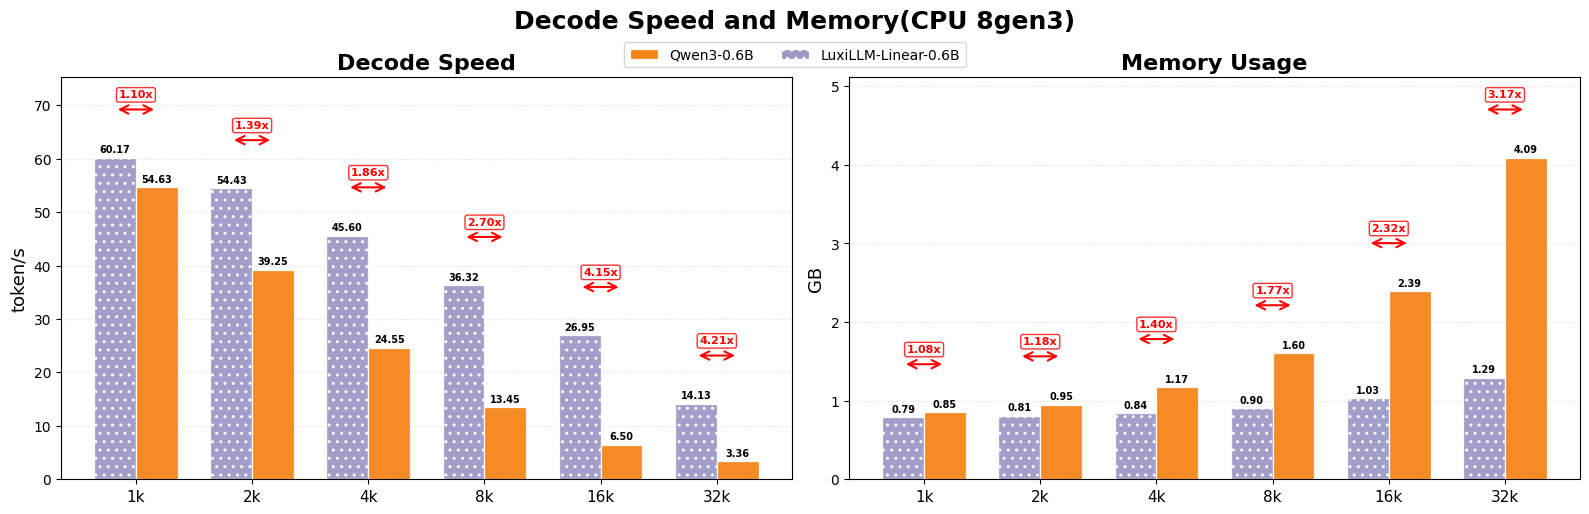

In [98]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch, FancyArrowPatch

# ===== 1) 模型、颜色、hatch（与前面保持一致） =====
models = ['LuxiLLM-Linear-0.6B','Qwen3-0.6B']
COLOR = {
    'Qwen3-0.6B': '#F58518',
    'LuxiLLM-Linear-0.6B': '#9E9AC8',
}
HATCH = {'LuxiLLM-Linear-0.6B': '..'}  # LinCal 打点

# ===== 2) 数据（按"速度/内存占用(GB)"录入）=====
contexts = ['1k','2k','4k','8k','16k','32k']
pairs = {
    'LuxiLLM-Linear-0.6B': [
        (60.17, 0.790),
        (54.43, 0.806),
        (45.60, 0.838),
        (36.32, 0.903),
        (26.95, 1.032),
        (14.13, 1.290),
    ],
    'Qwen3-0.6B': [
        (54.63, 0.85),
        (39.25, 0.95),
        (24.55, 1.17),
        (13.45, 1.60),
        (6.5, 2.39),
        (3.36, 4.09),
    ],
}

# 把 pairs 拆成速度矩阵与内存矩阵
speed = np.array([[p[0] for p in pairs[m]] for m in models])
mem   = np.array([[p[1] for p in pairs[m]] for m in models])

# ===== 3) 画图：两列并排（左：速度；右：内存）=====
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))  # 增加宽度给箭头留空间
width = 0.36
x = np.arange(len(contexts))

def draw_grouped(ax, values, ylabel, is_speed=True):
    # 绘制柱状图
    bars_list = []
    for i, m in enumerate(models):
        off = (i - (len(models)-1)/2) * width
        bars = ax.bar(x + off, values[i], width=width,
                      color=COLOR[m], edgecolor='white', linewidth=0.9, alpha=0.95,
                      hatch=HATCH.get(m, None))
        bars_list.append(bars)
        
        # 数值标注
        for rect, v in zip(bars, values[i]):
            text_offset = values.max() * 0.01
            ax.text(rect.get_x() + rect.get_width()/2, 
                   rect.get_height() + text_offset,
                   f'{v:.2f}', 
                   ha='center', 
                   va='bottom', 
                   fontsize=7, 
                   fontweight='bold')
    
    # 添加红色箭头和倍数比较
    for j in range(len(contexts)):
        # 计算两个柱状图的值
        val1 = values[0][j]  # LinCal
        val2 = values[1][j]  # Qwen3
        
        # 计算倍数（总是用较大的值除以较小的值）
        if val1 > val2:
            ratio = val1 / val2
            higher_idx, lower_idx = 0, 1
        else:
            ratio = val2 / val1
            higher_idx, lower_idx = 1, 0
        
        # 箭头位置
        x_center = x[j]
        higher_val = max(val1, val2)
        lower_val = min(val1, val2)
        
        # 箭头起始和结束位置
        arrow_start = x_center + (higher_idx - 0.5) * width
        arrow_end = x_center + (lower_idx - 0.5) * width
        
        # 箭头高度（在最高柱状图上方）
        arrow_y = higher_val + values.max() * 0.15
        
        # 绘制箭头
        arrow = FancyArrowPatch(
            (arrow_start, arrow_y), 
            (arrow_end, arrow_y),
            arrowstyle='<->', 
            color='red', 
            linewidth=1.5,
            mutation_scale=15
        )
        ax.add_patch(arrow)
        
        # 添加倍数文本
        ratio_text = f'{ratio:.2f}x'
        ax.text(x_center, arrow_y + values.max() * 0.03, 
               ratio_text, 
               ha='center', 
               va='bottom', 
               fontsize=8, 
               fontweight='bold',
               color='red',
               bbox=dict(boxstyle="round,pad=0.2", facecolor='white', edgecolor='red', alpha=0.8))
    
    ax.set_ylabel(ylabel, fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(contexts, rotation=0, fontsize=11)
    ax.grid(axis='y', linestyle=':', alpha=0.45)
    ax.set_axisbelow(True)
    ymax = values.max() * (1 + 0.25)  # 增加上限给箭头留空间
    ax.set_ylim(0, ymax)

# 左：decode 速度
axes[0].set_title('Decode Speed', fontsize=16, fontweight='bold')
draw_grouped(axes[0], speed, 'token/s', is_speed=True)

# 右：内存占用
axes[1].set_title('Memory Usage', fontsize=16, fontweight='bold')
draw_grouped(axes[1], mem, 'GB', is_speed=False)

# ===== 顶部统一图例 =====
legend_handles = [
    Patch(facecolor=COLOR['Qwen3-0.6B'], edgecolor='white', linewidth=0.9, label='Qwen3-0.6B'),
    Patch(facecolor=COLOR['LuxiLLM-Linear-0.6B'], edgecolor='white', linewidth=0.9, hatch='..', label='LuxiLLM-Linear-0.6B'),
]
fig.legend(handles=legend_handles, loc='upper center', ncol=2, frameon=True, fancybox=True, bbox_to_anchor=(0.5, 0.93))

# 总标题 & 布局与导出
fig.suptitle('Decode Speed and Memory(CPU 8gen3)', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()

plt.savefig('decode_speed_and_memoryPHONE.png', dpi=600, bbox_inches='tight')
plt.savefig('decode_speed_and_memoryPHONE.pdf', dpi=600, bbox_inches='tight')
plt.show()

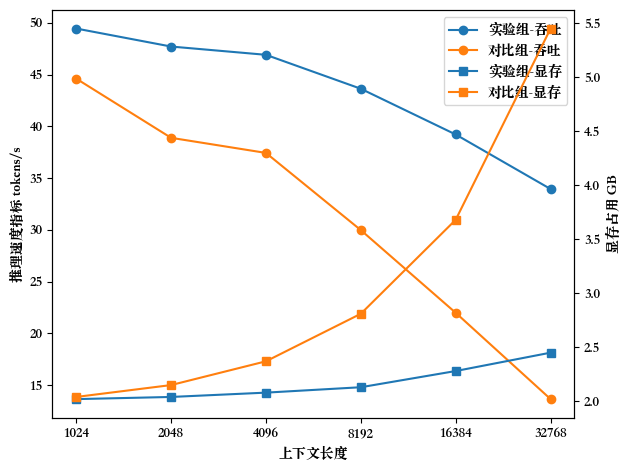

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.font_manager as fm

# ========= 1) 数据（按你图里的数值）=========
ctx = np.array([1024, 2048, 4096, 8192, 16384, 32768])

# 推理速度指标（图中口径）
speed_exp  = np.array([49.46, 47.72, 46.92, 43.64, 39.22, 33.95])  # 实验组（lincal）
speed_ctrl = np.array([44.62, 38.90, 37.44, 29.98, 21.99, 13.65])  # 对比组（Transformer）

# 显存占用（图中口径）
mem_exp  = np.array([2.02, 2.04, 2.08, 2.13, 2.28, 2.45])          # 实验组
mem_ctrl = np.array([2.04, 2.15, 2.37, 2.81, 3.68, 5.45])          # 对比组

# ========= 2) mac 上中文字体：优先苹方 PingFang / 黑体 Heiti / 再退回 Arial Unicode =========
plt.rcParams["axes.unicode_minus"] = False

def pick_cjk_font():
    candidates = [
        "PingFang SC",          # macOS 常见
        "Heiti SC",             # macOS 常见
        "Songti SC",            # macOS 常见
        "Hiragino Sans GB",     # macOS 常见（含中文）
        "Arial Unicode MS",     # 可能存在
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in candidates:
        if name in available:
            return name
    return None

font_name = pick_cjk_font()
if font_name:
    plt.rcParams["font.family"] = font_name

# ========= 3) 合并图：双 y 轴（同一张图）=========
fig, ax1 = plt.subplots()

# 左轴：推理速度
l1, = ax1.plot(ctx, speed_exp,  marker="o", label="实验组-吞吐")
l2, = ax1.plot(ctx, speed_ctrl, marker="o", label="对比组-吞吐")
ax1.set_xscale("log", base=2)
ax1.set_xticks(ctx)
ax1.set_xticklabels([str(x) for x in ctx])
ax1.set_xlabel("上下文长度")
ax1.set_ylabel("推理速度指标 tokens/s")

# 右轴：显存占用
ax2 = ax1.twinx()
l3, = ax2.plot(ctx, mem_exp,  marker="s", label="实验组-显存")
l4, = ax2.plot(ctx, mem_ctrl, marker="s", label="对比组-显存")
ax2.set_ylabel("显存占用 GB")

# 标题 + 图例（合并两条轴上的图例）
#ax1.set_title("实验组 vs 对比组：推理速度与显存随上下文长度变化")
lines = [l1, l2, l3, l4]
labels = [ln.get_label() for ln in lines]
ax1.legend(lines, labels, loc="best")

plt.tight_layout()

# ========= 4) 保存 ========
plt.savefig("实验组_vs_对比组_速度_显存_合并图.png", dpi=600)
plt.show()

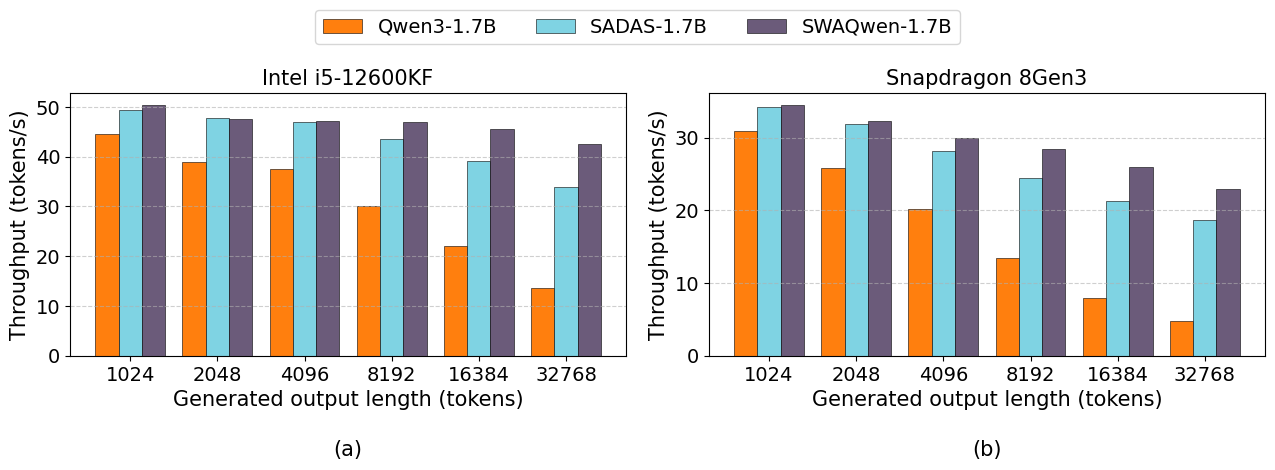

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# ========= Adjustable font size =========
FONT_SIZE = 15
plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE - 1,
    "xtick.labelsize": FONT_SIZE - 1,
    "ytick.labelsize": FONT_SIZE - 1,
})

# ========= Data =========
ctx = np.array([1024, 2048, 4096, 8192, 16384, 32768])

pc_cpu = {
    "Qwen3-1.7B": [44.62, 38.90, 37.44, 29.98, 21.99, 13.65],
    "SADAS-1.7B":  [49.46, 47.72, 46.92, 43.64, 39.22, 33.95],
    "SWAQwen-1.7B":    [50.31, 47.66, 47.07, 46.87, 45.62, 42.45],
}

mobile_cpu = {
    "Qwen3-1.7B": [30.90, 25.88, 20.21, 13.46,  7.94,  4.80],
    "SADAS-1.7B":  [34.23, 31.92, 28.12, 24.44, 21.25, 18.66],
    "SWAQwen-1.7B":    [34.44, 32.25, 29.98, 28.43, 25.96, 22.89],  # TODO: fill 1024 if available
}

# ========= Colors (match the provided AIME plot style) =========
COLOR = {
    "Qwen3-1.7B": "#ff7f0e",  # orange (Qwen3)
    "SADAS-1.7B":  "#7fd3e3",  # light cyan (SADAS-like)
    "SWAQwen-1.7B":    "#6b5b7a",  # muted purple (SWAQwen-like)
}

# ========= Plot helpers =========
def grouped_bar(ax, data, title):
    names = list(data.keys())
    Y = np.array([data[n] for n in names], dtype=float)  # (n_models, n_ctx)

    x = np.arange(len(ctx))
    n = len(names)
    width = 0.8 / n

    for i, name in enumerate(names):
        xi = x - 0.4 + width/2 + i * width
        yi = Y[i]
        mask = ~np.isnan(yi)

        ax.bar(
            xi[mask],
            yi[mask],
            width=width,
            label=name,
            color=COLOR.get(name, None),
            edgecolor="black",
            linewidth=0.4,
        )

    ax.set_title(title)
    ax.set_xlabel("Generated output length (tokens)")
    ax.set_ylabel("Throughput (tokens/s)")  # keep y-axis label on BOTH subplots
    ax.set_xticks(x)
    ax.set_xticklabels([str(int(v)) for v in ctx])
    ax.grid(True, axis="y", linestyle="--", linewidth=0.8, alpha=0.6)

# ========= Figure =========
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

grouped_bar(axes[0], pc_cpu, "Intel i5-12600KF")
grouped_bar(axes[1], mobile_cpu, "Snapdragon 8Gen3")

# ---- Global legend outside, so it won't cover bars ----
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center",
    ncol=3,
    frameon=True,
    bbox_to_anchor=(0.5, 1.02),
)

# Leave space for legend at top and (a)(b) at bottom
fig.tight_layout(rect=[0, 0.08, 1, 0.92])

# (a) and (b) under each subplot
for i, ax in enumerate(axes):
    bbox = ax.get_position()
    x_center = (bbox.x0 + bbox.x1) / 2
    fig.text(x_center, 0.02, f"({chr(ord('a') + i)})",
             ha="center", va="bottom", fontsize=FONT_SIZE)

# Save
fig.savefig("throughput_bar_pc_vs_mobile.pdf", bbox_inches="tight")
fig.savefig("throughput_bar_pc_vs_mobile.png", dpi=600, bbox_inches="tight")

plt.show()

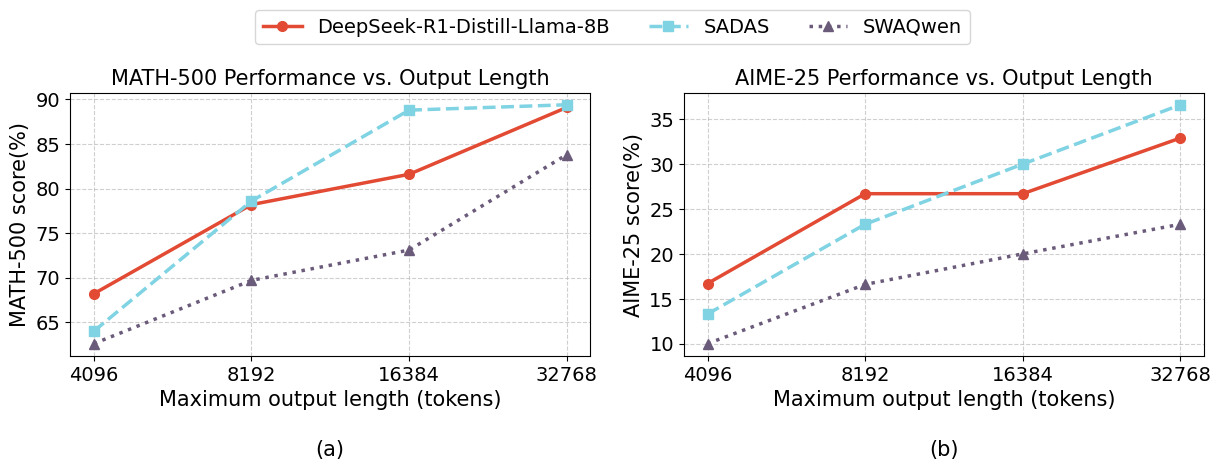

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# ========= Adjustable font size =========
FONT_SIZE = 15
plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE - 1,
    "xtick.labelsize": FONT_SIZE - 1,
    "ytick.labelsize": FONT_SIZE - 1,
})

# ========= Data (from your table) =========
ctx = np.array([4096, 8192, 16384, 32768])

data_math500 = {
    "DeepSeek-R1-Distill-Llama-8B": [68.2, 78.2, 81.6, 89.1],
    "SADAS":                   [64.0, 78.6, 88.8, 89.4],
    "SWAQwen":                     [62.6, 69.7, 73.1, 83.8],
}

data_aime25 = {
    "DeepSeek-R1-Distill-Llama-8B": [16.7, 26.7, 26.7, 32.9],
    "SADAS":                    [13.3, 23.3, 30.0, 36.6],
    "SWAQwen":                      [10.0, 16.6, 20.0, 23.3],
}

# ========= Colors (match your provided AIME plot style) =========
# DS-Llama-8B = red, SADAS(SADAS-like) = cyan, SWAQwen(SWAQwen-like) = purple
COLOR = {
    "DeepSeek-R1-Distill-Llama-8B": "#e24a33",
    "SADAS":                   "#7fd3e3",
    "SWAQwen":                     "#6b5b7a",
}

# ========= Line styles / markers (close to your example) =========
STYLE = {
    "DeepSeek-R1-Distill-Llama-8B": dict(linestyle="-",  marker="o"),
    "SADAS":                    dict(linestyle="--", marker="s"),
    "SWAQwen":                      dict(linestyle=":",  marker="^"),
}

def plot_panel(ax, ydata, title, ylabel):
    for name, ys in ydata.items():
        ax.plot(
            ctx, ys,
            color=COLOR.get(name, None),
            linewidth=2.5,
            markersize=7,
            label=name,
            **STYLE.get(name, {})
        )
    ax.set_title(title)
    ax.set_xlabel("Maximum output length (tokens)")
    ax.set_ylabel(ylabel)  # keep y-axis on BOTH subplots
    ax.set_xscale("log", base=2)
    ax.set_xticks(ctx)
    ax.get_xaxis().set_major_formatter(lambda x, pos: f"{int(x)}")
    ax.grid(True, linestyle="--", linewidth=0.8, alpha=0.6)

# ========= Figure =========
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharex=True)

plot_panel(axes[0], data_math500, "MATH-500 Performance vs. Output Length", "MATH-500 score(%)")
plot_panel(axes[1], data_aime25,  "AIME-25 Performance vs. Output Length", "AIME-25 score(%)")

# ---- Global legend outside (won't cover curves) ----
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center",
    ncol=3,
    frameon=True,
    bbox_to_anchor=(0.5, 1.02),
)

# Space for legend and (a)(b)
fig.tight_layout(rect=[0, 0.08, 1, 0.92])

# (a) (b) under subplots
for i, ax in enumerate(axes):
    bbox = ax.get_position()
    x_center = (bbox.x0 + bbox.x1) / 2
    fig.text(x_center, 0.02, f"({chr(ord('a') + i)})",
             ha="center", va="bottom", fontsize=FONT_SIZE)

# Save
fig.savefig("ctx_vs_score_math500_aime25.pdf", bbox_inches="tight")
fig.savefig("ctx_vs_score_math500_aime25.png", dpi=600, bbox_inches="tight")

plt.show()

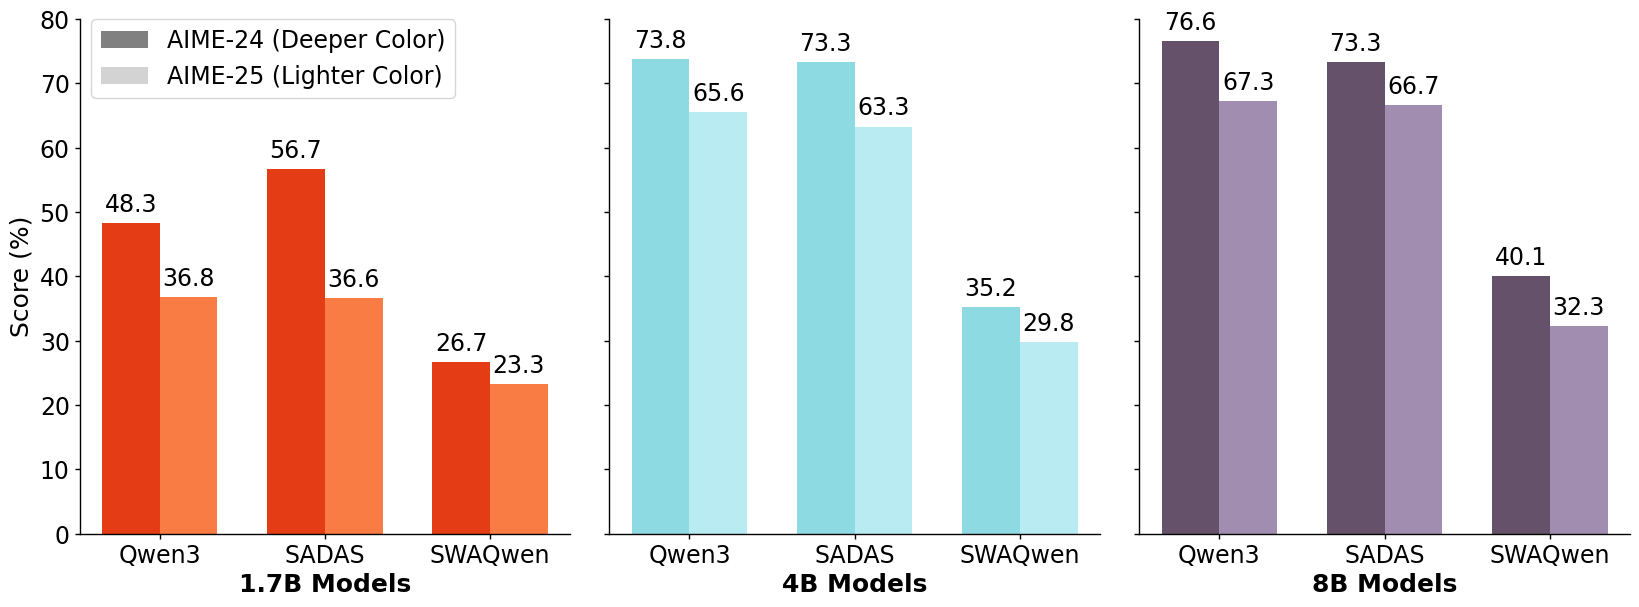

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# ========= Match the other figure's font + sizes =========
FONT_SIZE = 18
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE - 1,
    "xtick.labelsize": FONT_SIZE - 1,
    "ytick.labelsize": FONT_SIZE - 1,
    "axes.linewidth": 1.0,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
})

# ========= Data =========
labels = ["Qwen3", "SADAS", "SWAQwen"]

aime24_17 = [48.3, 56.7, 26.7]
aime25_17 = [36.8, 36.6, 23.3]

aime24_4b = [73.8, 73.3, 35.2]
aime25_4b = [65.6, 63.3, 29.8]

aime24_8b = [76.6, 73.3, 40.1]
aime25_8b = [67.3, 66.7, 32.3]

colors = {
    "17_deep": "#e43c15",
    "17_light": "#fa7c45",
    "4b_deep": "#8edae2",
    "4b_light": "#b8ebf2",
    "8b_deep": "#65516a",
    "8b_light": "#a08db0",
}

# ========= Figure =========
fig, axes = plt.subplots(1, 3, figsize=(16.76, 7.68), dpi=100)

x = np.arange(len(labels))
w = 0.35
yticks = np.arange(0, 81, 10)

def draw_panel(ax, v24, v25, c_deep, c_light, xlabel):
    ax.bar(x - w/2, v24, width=w, color=c_deep)
    ax.bar(x + w/2, v25, width=w, color=c_light)

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 80)
    ax.set_yticks(yticks)
    ax.set_xlabel(xlabel, fontweight="bold")

    for xi, val in zip(x - w/2, v24):
        ax.text(xi, val + 1.0, f"{val:.1f}", ha="center", va="bottom", fontsize=FONT_SIZE-1)
    for xi, val in zip(x + w/2, v25):
        ax.text(xi, val + 1.0, f"{val:.1f}", ha="center", va="bottom", fontsize=FONT_SIZE-1)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

draw_panel(axes[0], aime24_17, aime25_17, colors["17_deep"], colors["17_light"], "1.7B Models")
axes[0].set_ylabel("Score (%)")

draw_panel(axes[1], aime24_4b, aime25_4b, colors["4b_deep"], colors["4b_light"], "4B Models")
axes[1].tick_params(axis="y", labelleft=False)

draw_panel(axes[2], aime24_8b, aime25_8b, colors["8b_deep"], colors["8b_light"], "8B Models")
axes[2].tick_params(axis="y", labelleft=False)

# ========= Legend moved to the FAR LEFT (figure-level legend) =========
legend_handles = [
    Patch(facecolor="#808080", edgecolor="none", label="AIME-24 (Deeper Color)"),
    Patch(facecolor="#d3d3d3", edgecolor="none", label="AIME-25 (Lighter Color)"),
]
fig.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.06, 0.915),   # align to the left margin of the whole figure
    frameon=True,
)

# Layout
fig.subplots_adjust(left=0.06, right=0.985, top=0.90, bottom=0.23, wspace=0.08)


fig.savefig("figure2.png", dpi=100)
fig.savefig("figure2.pdf", bbox_inches="tight")

plt.show()

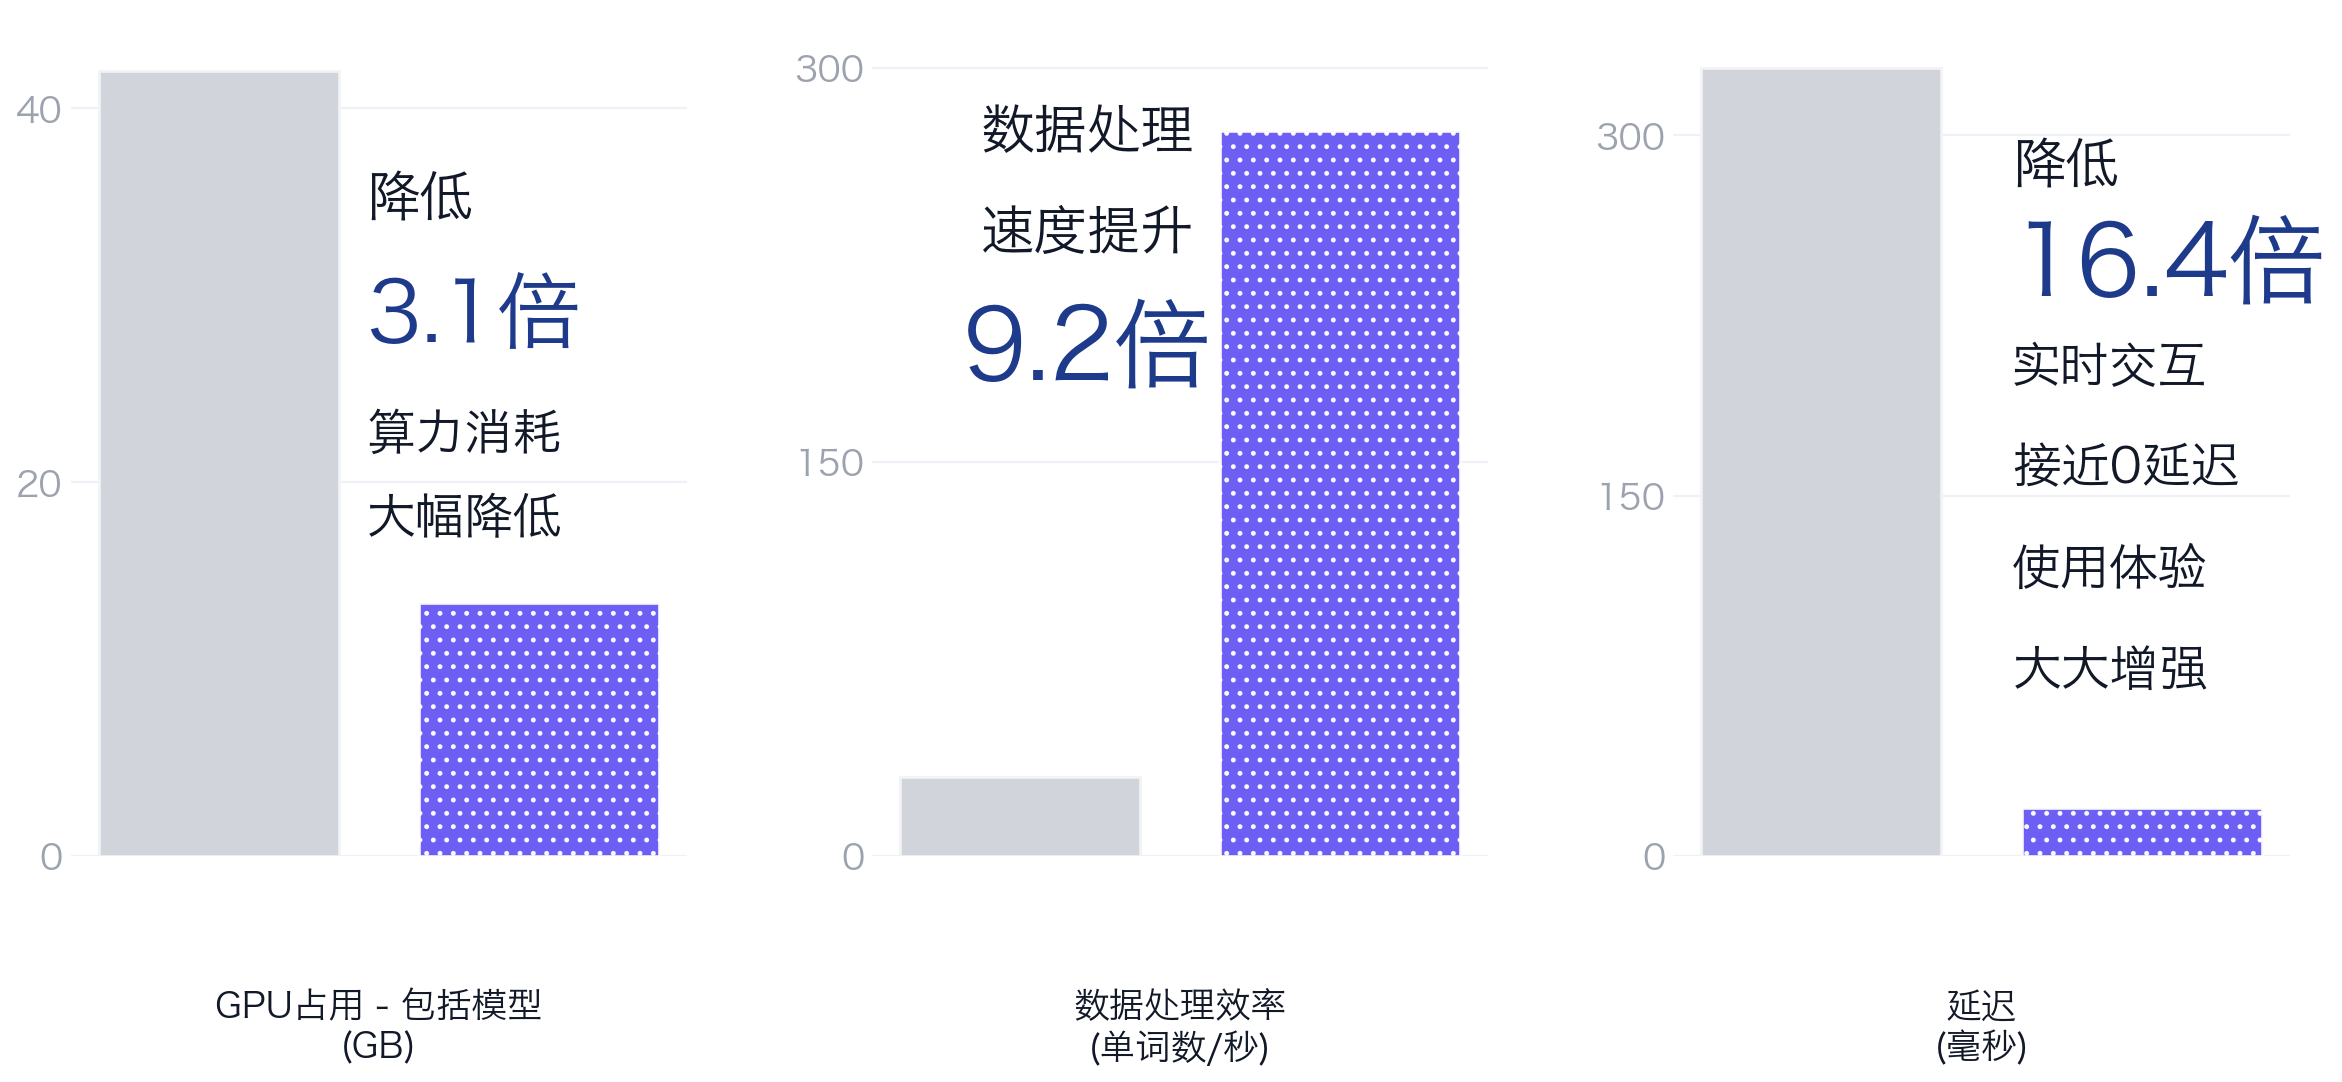

In [71]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import matplotlib.patheffects as pe

# =========================
# macOS 中文字体兜底（避免字体报错）
# =========================
def set_macos_chinese_font():
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC",
        "Arial Unicode MS", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

_ = set_macos_chinese_font()

# =========================
# 全局风格（和你之前一致）
# =========================
THEME = {
    "bg":        "#FFFFFF",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
}

# ✅ 统一配色：Luxi 紫 + baseline 灰（Qwen/对照更不明显）
COLOR = {"luxi": "#6D5EF5", "base": "#D1D5DB"}
EDGE  = {"luxi": "#FFFFFF", "base": "#F3F4F6"}
HATCH = {"luxi": ".."}  # ✅ 我们的模型打点

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
})

# =========================
# 数据（按原图倍数关系近似）
# =========================
gpu_base, gpu_new = 42.0, 42.0 / 3.1          # ≈ 13.55
spd_base, spd_new = 30.0, 30.0 * 9.2          # = 276
lat_base, lat_new = 328.0, 328.0 / 16.4       # = 20

metrics = [
    ("GPU占用 - 包括模型\n(GB)", (gpu_base, gpu_new), (0, 45), [0, 20, 40],
     ["降低", "3.1倍", "算力消耗", "大幅降低"]),
    ("数据处理效率\n(单词数/秒)", (spd_base, spd_new), (0, 320), [0, 150, 300],
     ["数据处理", "速度提升", "9.2倍"]),
    ("延迟\n(毫秒)", (lat_base, lat_new), (0, 350), [0, 150, 300],
     ["降低", "16.4倍", "实时交互", "接近0延迟", "使用体验", "大大增强"]),
]

# =========================
# 文字左右位置微调（你要再挪就改这里）
# =========================
TEXT_POS = {
    "gpu_x": 0.48,     # 左图说明块整体的 x（越大越往右）
    "mid_x": 0.35,     # 中图说明块 x（居中即可）
    "lat_x": 0.55,     # 右图说明块整体的 x（越大越往右）
    "gpu_align": "left",
    "lat_align": "left",
}
BLUE_DARK = "#1E3A8A" # 深蓝（更稳重）
# =========================
# 绘图
# =========================
fig, axes = plt.subplots(1, 3, figsize=(14.6, 7.2), gridspec_kw={"wspace": 0.30})
#fig.patch.set_facecolor(THEME["bg"])
fig.patch.set_facecolor(THEME["bg"])
def style_ax(ax, ylim, yticks):
    ax.set_facecolor("none")
    ax.set_ylim(*ylim)
    ax.set_yticks(yticks)
    ax.grid(axis="y", linestyle="-", linewidth=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", colors="#9CA3AF", labelsize=16, length=0)
    ax.set_xticks([])
    ax.tick_params(axis="x", length=0)

def add_bar_shadow(rect, alpha=0.10, dy=-2.0):
    rect.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, dy), alpha=alpha, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])

for ax, (xlabel, (v_base, v_new), ylim, yticks, anno) in zip(axes, metrics):
    style_ax(ax, ylim, yticks)

    # 两个柱（左：对照灰；右：Luxi紫打点）
    x0, x1 = 0.38, 0.62
    w = 0.18

    b0 = ax.bar([x0], [v_base], width=w, color=COLOR["base"], edgecolor=EDGE["base"],
                linewidth=1.2, zorder=2, alpha=0.95)
    b1 = ax.bar([x1], [v_new],  width=w, color=COLOR["luxi"], edgecolor=EDGE["luxi"],
                linewidth=1.2, zorder=3, alpha=0.92, hatch=HATCH["luxi"])

    add_bar_shadow(list(b0)[0], alpha=0.06, dy=-1.2)
    add_bar_shadow(list(b1)[0], alpha=0.14, dy=-1.6)

    # 底部指标名
    ax.text(0.5, -0.16, xlabel, transform=ax.transAxes,
            ha="center", va="top", fontsize=16, color=THEME["text"], fontweight="bold")

    # 文字注释（按原图布局 + 你要的左右微调）
    if "GPU占用" in xlabel:
        X = TEXT_POS["gpu_x"]
        HA = TEXT_POS["gpu_align"]
        ax.text(X, 0.78, anno[0], transform=ax.transAxes,
                ha=HA, va="center", fontsize=24, color=THEME["text"])
        ax.text(X, 0.64, anno[1], transform=ax.transAxes,
                ha=HA, va="center", fontsize=38,  color=BLUE_DARK, fontweight="bold")
        ax.text(X, 0.50, anno[2], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])
        ax.text(X, 0.40, anno[3], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])

    elif "数据处理效率" in xlabel:
        X = TEXT_POS["mid_x"]
        ax.text(X, 0.86, anno[0], transform=ax.transAxes,
                ha="center", va="center", fontsize=24, color=THEME["text"])
        ax.text(X, 0.74, anno[1], transform=ax.transAxes,
                ha="center", va="center", fontsize=24, color=THEME["text"])
        ax.text(X, 0.60, anno[2], transform=ax.transAxes,
                ha="center", va="center", fontsize=44, color=BLUE_DARK, fontweight="bold")

    else:
        X = TEXT_POS["lat_x"]
        HA = TEXT_POS["lat_align"]
        ax.text(X, 0.82, anno[0], transform=ax.transAxes,
                ha=HA, va="center", fontsize=24, color=THEME["text"])
        ax.text(X, 0.70, anno[1], transform=ax.transAxes,
                ha=HA, va="center", fontsize=44, color=BLUE_DARK, fontweight="bold")
        ax.text(X, 0.58, anno[2], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])
        ax.text(X, 0.46, anno[3], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])
        ax.text(X, 0.34, anno[4], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])
        ax.text(X, 0.22, anno[5], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])

fig.subplots_adjust(left=0.04, right=0.99, bottom=0.22, top=0.95)
plt.savefig("复刻_性能对比_统一配色_打点.png", dpi=600, bbox_inches="tight")
plt.savefig("复刻_性能对比_统一配色_打点.pdf", dpi=600, bbox_inches="tight")
plt.show()

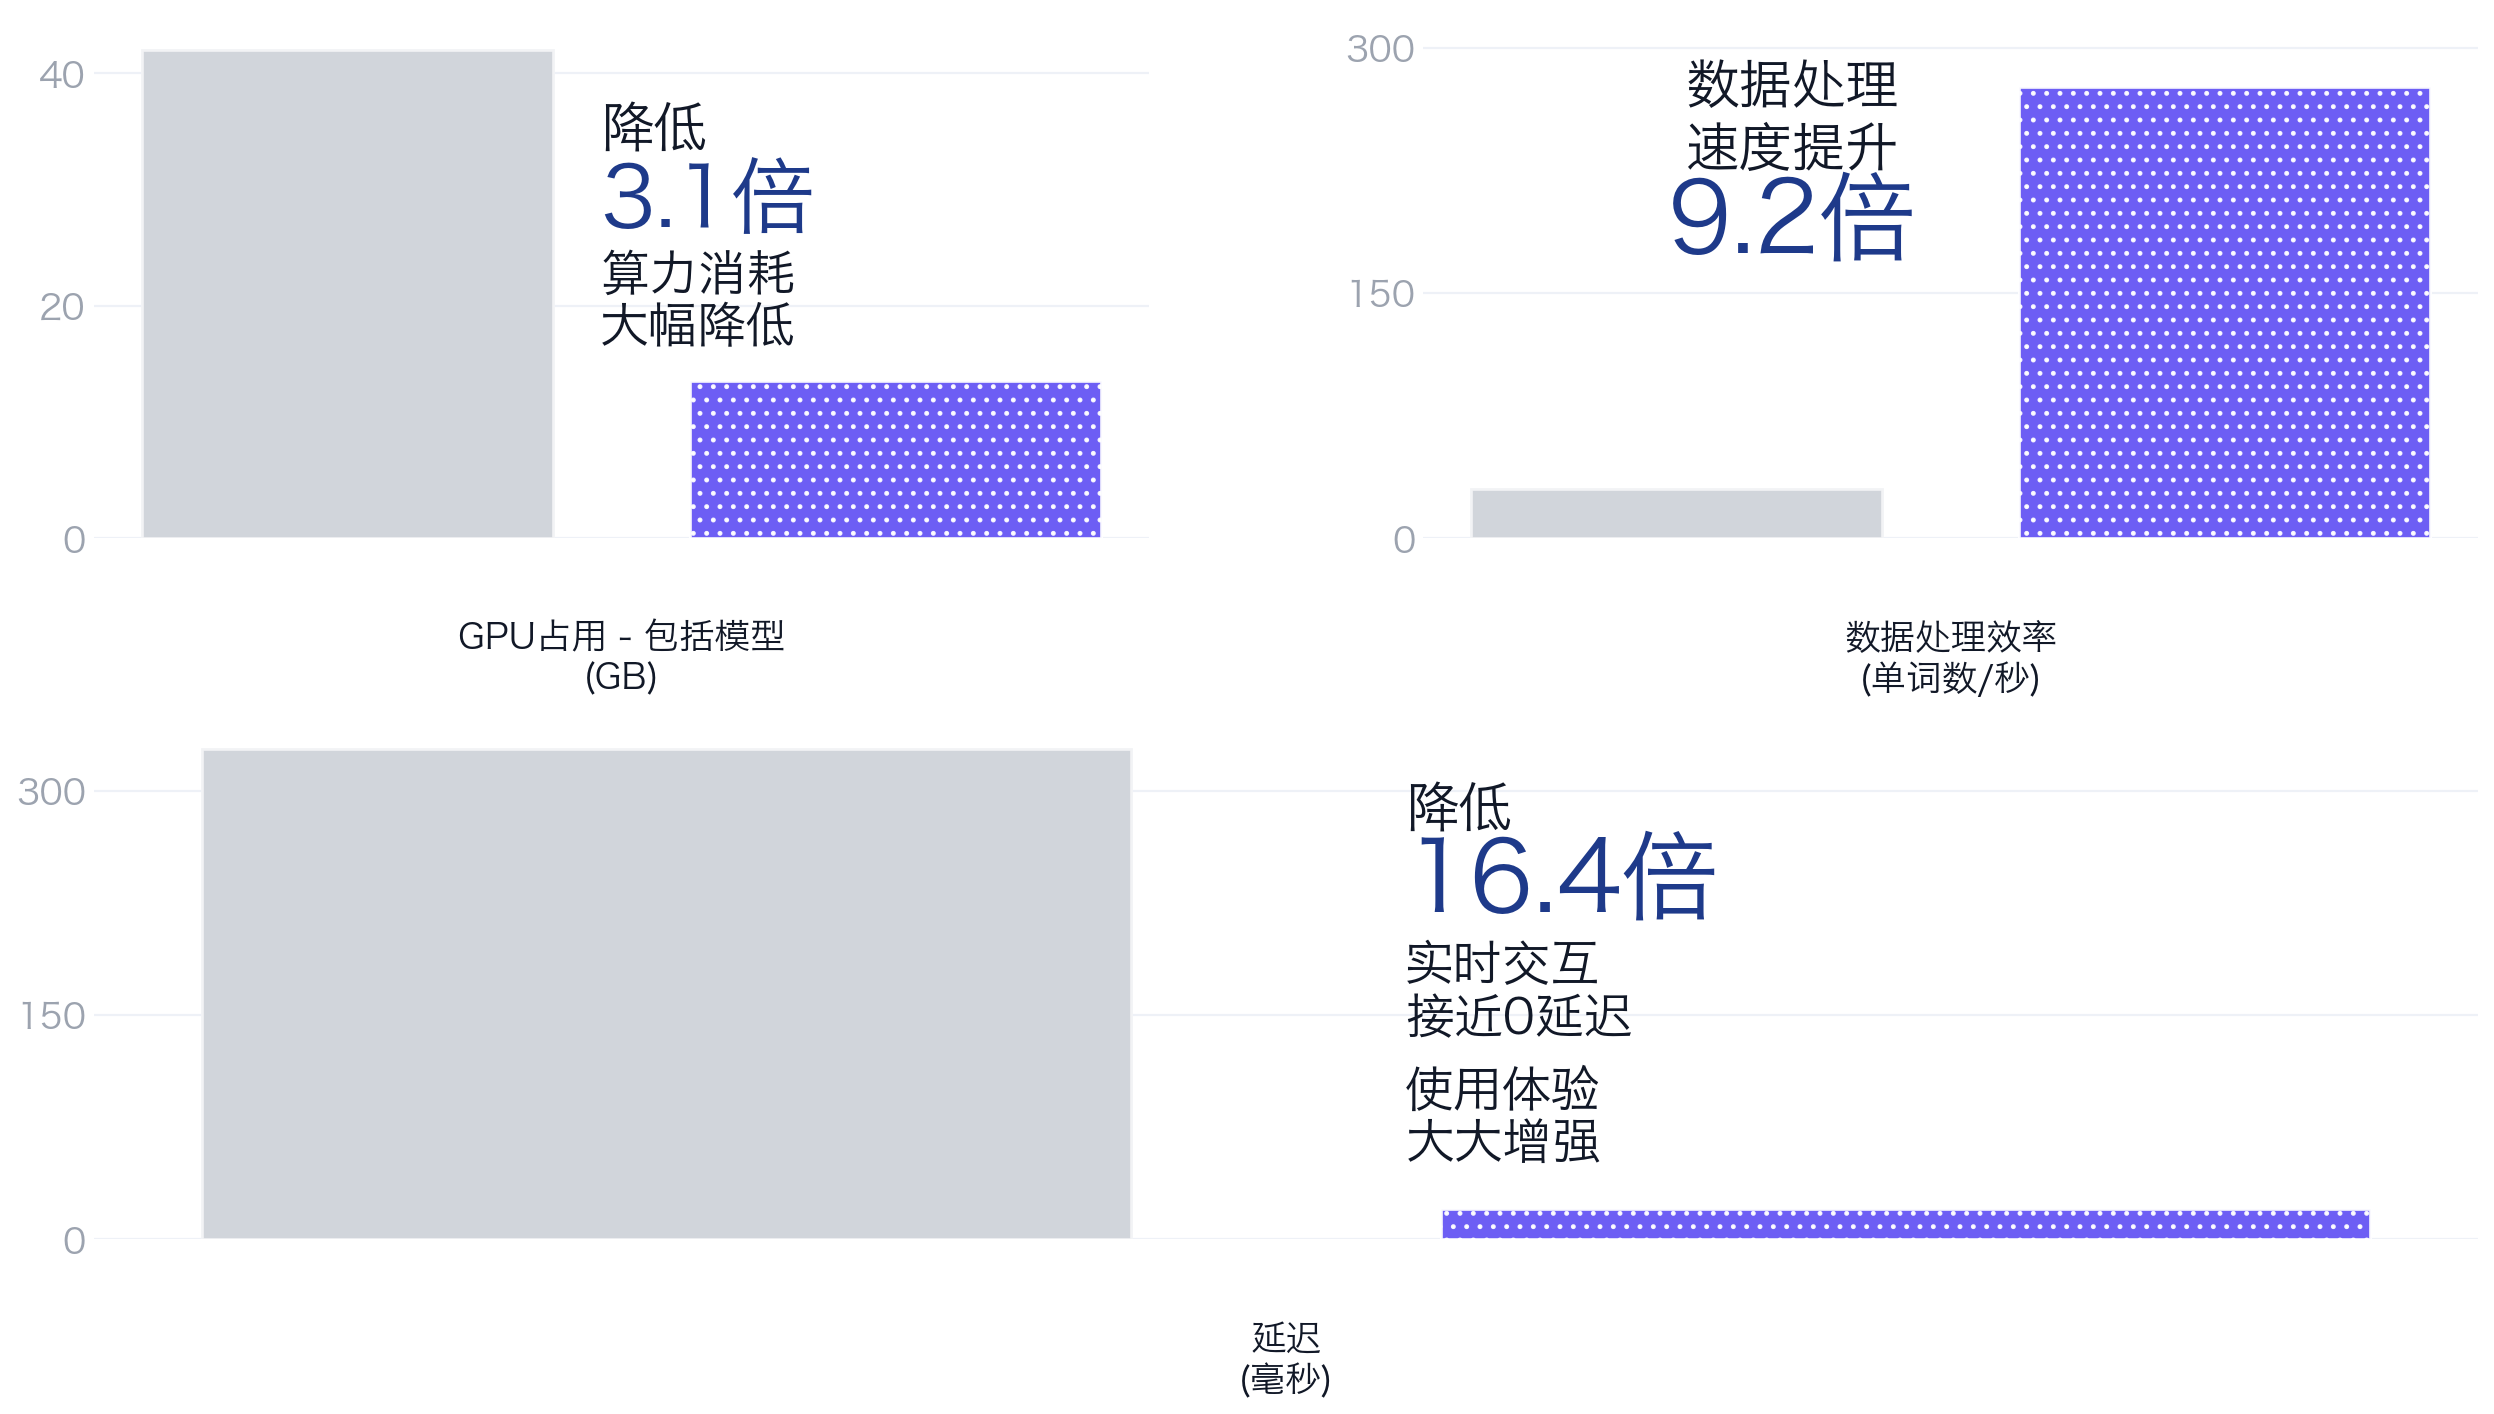

In [68]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import matplotlib.patheffects as pe

# =========================
# macOS 中文字体兜底（避免字体报错）
# =========================
def set_macos_chinese_font():
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC",
        "Arial Unicode MS", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

_ = set_macos_chinese_font()

# =========================
# 全局风格（和你之前一致）
# =========================
THEME = {
    "bg":        "#FFFFFF",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
}

# ✅ 统一配色：Luxi 紫 + baseline 灰（Qwen/对照更不明显）
COLOR = {"luxi": "#6D5EF5", "base": "#D1D5DB"}
EDGE  = {"luxi": "#FFFFFF", "base": "#F3F4F6"}
HATCH = {"luxi": ".."}  # ✅ 我们的模型打点

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
})

# =========================
# 数据（按原图倍数关系近似）
# =========================
gpu_base, gpu_new = 42.0, 42.0 / 3.1          # ≈ 13.55
spd_base, spd_new = 30.0, 30.0 * 9.2          # = 276
lat_base, lat_new = 328.0, 328.0 / 16.4       # = 20

metrics = [
    ("GPU占用 - 包括模型\n(GB)", (gpu_base, gpu_new), (0, 45), [0, 20, 40],
     ["降低", "3.1倍", "算力消耗", "大幅降低"]),
    ("数据处理效率\n(单词数/秒)", (spd_base, spd_new), (0, 320), [0, 150, 300],
     ["数据处理", "速度提升", "9.2倍"]),
    ("延迟\n(毫秒)", (lat_base, lat_new), (0, 350), [0, 150, 300],
     ["降低", "16.4倍", "实时交互", "接近0延迟", "使用体验", "大大增强"]),
]

# =========================
# 文字左右位置微调（你要再挪就改这里）
# =========================
TEXT_POS = {
    "gpu_x": 0.48,     # 左图说明块整体的 x（越大越往右）
    "mid_x": 0.35,     # 中图说明块 x（居中即可）
    "lat_x": 0.55,     # 右图说明块整体的 x（越大越往右）
    "gpu_align": "left",
    "lat_align": "left",
}
BLUE_DARK = "#1E3A8A"  # 深蓝（更稳重）

# =========================
# 绘图辅助
# =========================
def style_ax(ax, ylim, yticks):
    ax.set_facecolor("none")
    ax.set_ylim(*ylim)
    ax.set_yticks(yticks)
    ax.grid(axis="y", linestyle="-", linewidth=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", colors="#9CA3AF", labelsize=16, length=0)
    ax.set_xticks([])
    ax.tick_params(axis="x", length=0)

def add_bar_shadow(rect, alpha=0.10, dy=-2.0):
    rect.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, dy), alpha=alpha, shadow_rgbFace=(0, 0, 0)),
        pe.Normal()
    ])

# =========================
# ✅ 改成更“方”的布局：2x2（上两张并排，下方一张跨两列）
# =========================
fig = plt.figure(figsize=(16.2, 9.0))  # 更接近正方形；想更方可用 (9.0, 9.0)
fig.patch.set_facecolor(THEME["bg"])

gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1, 1],
    height_ratios=[1, 1],
    wspace=0.26,
    hspace=0.34
)

axes = [
    fig.add_subplot(gs[0, 0]),  # GPU
    fig.add_subplot(gs[0, 1]),  # Speed
    fig.add_subplot(gs[1, :]),  # Latency (span)
]

# =========================
# 绘制三个子图
# =========================
for ax, (xlabel, (v_base, v_new), ylim, yticks, anno) in zip(axes, metrics):
    style_ax(ax, ylim, yticks)

    # 两个柱（左：对照灰；右：Luxi紫打点）
    x0, x1 = 0.38, 0.62
    w = 0.18

    b0 = ax.bar([x0], [v_base], width=w, color=COLOR["base"], edgecolor=EDGE["base"],
                linewidth=1.2, zorder=2, alpha=0.95)
    b1 = ax.bar([x1], [v_new],  width=w, color=COLOR["luxi"], edgecolor=EDGE["luxi"],
                linewidth=1.2, zorder=3, alpha=0.92, hatch=HATCH["luxi"])

    add_bar_shadow(list(b0)[0], alpha=0.06, dy=-1.2)
    add_bar_shadow(list(b1)[0], alpha=0.14, dy=-1.6)

    # 底部指标名
    ax.text(0.5, -0.16, xlabel, transform=ax.transAxes,
            ha="center", va="top", fontsize=16, color=THEME["text"], fontweight="bold")

    # 文字注释（按原图布局 + 你要的左右微调）
    if "GPU占用" in xlabel:
        X = TEXT_POS["gpu_x"]
        HA = TEXT_POS["gpu_align"]
        ax.text(X, 0.78, anno[0], transform=ax.transAxes,
                ha=HA, va="center", fontsize=24, color=THEME["text"])
        ax.text(X, 0.64, anno[1], transform=ax.transAxes,
                ha=HA, va="center", fontsize=38, color=BLUE_DARK, fontweight="bold")
        ax.text(X, 0.50, anno[2], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])
        ax.text(X, 0.40, anno[3], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])

    elif "数据处理效率" in xlabel:
        X = TEXT_POS["mid_x"]
        ax.text(X, 0.86, anno[0], transform=ax.transAxes,
                ha="center", va="center", fontsize=24, color=THEME["text"])
        ax.text(X, 0.74, anno[1], transform=ax.transAxes,
                ha="center", va="center", fontsize=24, color=THEME["text"])
        ax.text(X, 0.60, anno[2], transform=ax.transAxes,
                ha="center", va="center", fontsize=44, color=BLUE_DARK, fontweight="bold")

    else:
        X = TEXT_POS["lat_x"]
        HA = TEXT_POS["lat_align"]
        ax.text(X, 0.82, anno[0], transform=ax.transAxes,
                ha=HA, va="center", fontsize=24, color=THEME["text"])
        ax.text(X, 0.68, anno[1], transform=ax.transAxes,
                ha=HA, va="center", fontsize=44, color=BLUE_DARK, fontweight="bold")
        ax.text(X, 0.52, anno[2], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])
        ax.text(X, 0.42, anno[3], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])
        ax.text(X, 0.28, anno[4], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])
        ax.text(X, 0.18, anno[5], transform=ax.transAxes,
                ha=HA, va="center", fontsize=22, color=THEME["text"])

# ✅ 版面留白（方形布局）
fig.subplots_adjust(left=0.06, right=0.98, bottom=0.10, top=0.95)

plt.savefig("复刻_性能对比_统一配色_打点_方形.png", dpi=600, bbox_inches="tight")
plt.savefig("复刻_性能对比_统一配色_打点_方形.pdf", dpi=600, bbox_inches="tight")
plt.show()

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib import font_manager as fm
import matplotlib.patheffects as pe

# ========= Font fallback =========
def set_cjk_font():
    font_files = [
        "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
        "/usr/share/fonts/truetype/wqy/wqy-microhei.ttc",
        "/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc",
        "/usr/share/fonts/truetype/droid/DroidSansFallbackFull.ttf",
    ]
    for font_file in font_files:
        if os.path.exists(font_file):
            try:
                fm.fontManager.addfont(font_file)
            except Exception:
                pass
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Source Han Sans SC", "Noto Sans CJK SC", "Arial Unicode MS",
        "WenQuanYi Micro Hei", "WenQuanYi Zen Hei", "Droid Sans Fallback",
        "Noto Sans CJK JP", "DejaVu Sans",
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

_ = set_cjk_font()

# ========= Data =========
contexts = ["1k", "2k", "4k", "8k", "16k", "32k"]
models = ["qwen3-1.7B", "lincal-1.7B", "qwen35-2B"]

metrics = [
    {
        "title": "预填充吞吐",
        "ylabel": "tokens/s",
        "data": {
            "qwen3-1.7B":  [7092.30, 6508.48, 5610.63, 4442.76, 3141.47, 1982.39],
            "lincal-1.7B": [8047.68, 7949.25, 7722.48, 7315.42, 6655.30, 5625.96],
            "qwen35-2B":   [4623.20, 4602.48, 4549.86, 4436.74, 4241.83, 3897.75],
        },
    },
    {
        "title": "解码吞吐",
        "ylabel": "tokens/s",
        "data": {
            "qwen3-1.7B":  [57.89, 54.75, 51.69, 47.63, 41.57, 33.26],
            "lincal-1.7B": [73.55, 72.86, 72.03, 70.62, 68.04, 63.51],
            "qwen35-2B":   [63.66, 62.76, 62.00, 60.99, 59.25, 56.18],
        },
    },
    {
        "title": "KV cache allocation",
        "ylabel": "MB",
        "data": {
            "qwen3-1.7B":  [56.00, 112.00, 224.00, 448.00, 896.00, 1792.00],
            "lincal-1.7B": [44.00, 52.00, 68.00, 100.00, 164.00, 292.00],
            "qwen35-2B":   [15.84, 21.84, 33.84, 57.84, 105.84, 201.84],
        },
    },
]

# ========= Style =========
THEME = {
    "bg": "#FFFFFF",
    "grid": "#EEF1F7",
    "text": "#111827",
    "muted": "#6B7280",
    "edge": "#E9ECF5",
}

COLOR = {
    "qwen3-1.7B": "#F58518",
    "lincal-1.7B": "#6D5EF5",
    "qwen35-2B": "#72B7B2",
}
HATCH = {"lincal-1.7B": ".."}

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "legend.fontsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

def fmt_value(v):
    if v >= 100:
        return f"{v:.0f}"
    if v >= 10:
        return f"{v:.1f}"
    return f"{v:.2f}"

def style_axis(ax):
    ax.grid(axis="y", linestyle=":", linewidth=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def draw_metric(ax, metric):
    x = np.arange(len(contexts))
    width = 0.24
    values = np.array([metric["data"][m] for m in models], dtype=float)
    ymax = float(values.max())

    style_axis(ax)
    for i, model in enumerate(models):
        offset = (i - (len(models) - 1) / 2) * width
        bars = ax.bar(
            x + offset,
            values[i],
            width=width,
            color=COLOR[model],
            edgecolor="white",
            linewidth=0.9,
            alpha=0.92,
            hatch=HATCH.get(model, None),
            label=model,
        )
        for rect in bars:
            rect.set_path_effects([
                pe.withSimplePatchShadow(offset=(0, -1.0), alpha=0.10, shadow_rgbFace=(0, 0, 0)),
                pe.Normal(),
            ])
        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width() / 2,
                rect.get_height() + ymax * 0.012,
                fmt_value(v),
                ha="center",
                va="bottom",
                fontsize=7.6,
                color=THEME["text"],
                rotation=0,
            )

    ax.set_title(metric["title"], color=THEME["text"], pad=12)
    ax.set_ylabel(metric["ylabel"], color=THEME["muted"])
    ax.set_xlabel("上下文长度", color=THEME["muted"], labelpad=7)
    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_ylim(0, ymax * 1.18)

# ========= Plot =========
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"wspace": 0.22})
fig.patch.set_facecolor(THEME["bg"])

for ax, metric in zip(axes, metrics):
    draw_metric(ax, metric)

legend_handles = [
    Patch(facecolor=COLOR[m], edgecolor="white", hatch=HATCH.get(m, None), label=m)
    for m in models
]
fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=len(models),
    frameon=True,
    bbox_to_anchor=(0.5, 1.03),
)

fig.suptitle("推理速度对比（后摩 力擎 LQ50 Duo）", fontsize=20, fontweight="bold", y=1.12)
fig.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig("fig_lincal_qwen_perf_kv.png", dpi=600, bbox_inches="tight")
plt.savefig("fig_lincal_qwen_perf_kv.pdf", dpi=600, bbox_inches="tight")
plt.show()
print("Saved: fig_lincal_qwen_perf_kv.png / fig_lincal_qwen_perf_kv.pdf")


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm

# =========================
# Robust font setup
# =========================
def set_macos_chinese_font():
    font_files = [
        "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
        "/usr/share/fonts/truetype/wqy/wqy-microhei.ttc",
        "/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc",
        "/usr/share/fonts/truetype/droid/DroidSansFallbackFull.ttf",
    ]
    for font_file in font_files:
        if os.path.exists(font_file):
            try:
                fm.fontManager.addfont(font_file)
            except Exception:
                pass
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC", "Arial Unicode MS",
        "WenQuanYi Micro Hei", "WenQuanYi Zen Hei", "Droid Sans Fallback",
        "Noto Sans CJK JP", "DejaVu Sans"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

_ = set_macos_chinese_font()

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

# =========================
# 1) Models + style
# =========================
models = ["lincal-1.7B", "qwen3-1.7B", "qwen35-2B"]
contexts = ["1k", "2k", "4k", "8k", "16k", "32k"]

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
    "good":      "#0F766E",
}

# Lincal purple + muted baselines, matching the pasted style
COLOR = {
    "lincal-1.7B": "#6D5EF5",
    "qwen3-1.7B":  "#D1D5DB",
    "qwen35-2B":   "#A7D0CB",
}
EDGE = {
    "lincal-1.7B": "#FFFFFF",
    "qwen3-1.7B":  "#F3F4F6",
    "qwen35-2B":   "#D8ECE9",
}
HATCH = {"lincal-1.7B": ".."}

# =========================
# 2) Data
# =========================
prefill = np.array([
    [8047.68, 7949.25, 7722.48, 7315.42, 6655.30, 5625.96],
    [7092.30, 6508.48, 5610.63, 4442.76, 3141.47, 1982.39],
    [4623.20, 4602.48, 4549.86, 4436.74, 4241.83, 3897.75],
], dtype=float)

decode = np.array([
    [73.55, 72.86, 72.03, 70.62, 68.04, 63.51],
    [57.89, 54.75, 51.69, 47.63, 41.57, 33.26],
    [63.66, 62.76, 62.00, 60.99, 59.25, 56.18],
], dtype=float)
speed = decode

kv_cache = np.array([
    [44.00, 52.00, 68.00, 100.00, 164.00, 292.00],
    [56.00, 112.00, 224.00, 448.00, 896.00, 1792.00],
    [15.84, 21.84, 33.84, 57.84, 105.84, 201.84],
], dtype=float)

# =========================
# 3) Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2 * pad_x, 1 + 2 * pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False,
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal(),
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def fmt_value(v):
    if v >= 100:
        return f"{v:.0f}"
    if v >= 10:
        return f"{v:.1f}"
    return f"{v:.2f}"

def draw_grouped(ax, values, ylabel, better="higher"):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.25
    x = np.arange(len(contexts))
    vmax = float(values.max())

    for i, m in enumerate(models):
        off = (i - (len(models) - 1) / 2) * width
        is_lincal = (m == "lincal-1.7B")
        bars = ax.bar(
            x + off,
            values[i],
            width=width,
            color=COLOR[m],
            edgecolor=EDGE[m],
            linewidth=1.2 if is_lincal else 1.0,
            alpha=0.92 if is_lincal else 0.72,
            hatch=HATCH.get(m, None),
            zorder=3.0 if is_lincal else 2.7,
        )

        for rct in bars:
            if is_lincal:
                rct.set_path_effects([
                    pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal(),
                ])
            else:
                rct.set_path_effects([
                    pe.Stroke(linewidth=2.4, foreground="white", alpha=0.68),
                    pe.withSimplePatchShadow(offset=(0, -0.8), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal(),
                ])

        txt_color = THEME["text"] if is_lincal else THEME["muted"]
        txt_alpha = 0.94 if is_lincal else 0.70
        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width() / 2,
                rect.get_height() + vmax * 0.012,
                fmt_value(v),
                ha="center",
                va="bottom",
                fontsize=7.5,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6,
            )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_xlabel("上下文长度", color=THEME["muted"], labelpad=7)
    ax.set_ylim(0, vmax * 1.18)

# =========================
# 4) Plot
# =========================
fig, axes = plt.subplots(1, 3, figsize=(19.2, 6.0), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

axes[0].set_title("解码速度（Decode）", color=THEME["text"], pad=12)
draw_grouped(axes[0], speed, "token/s", better="higher")

axes[1].set_title("预填充速度（Prefill）", color=THEME["text"], pad=12)
draw_grouped(axes[1], prefill, "token/s", better="higher")

axes[2].set_title("KV Cache 占用", color=THEME["text"], pad=12)
draw_grouped(axes[2], kv_cache, "MB", better="lower")

legend_handles = [
    Patch(facecolor=COLOR["lincal-1.7B"], edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get("lincal-1.7B"), label="lincal-1.7B"),
    Patch(facecolor=COLOR["qwen3-1.7B"], edgecolor=EDGE["qwen3-1.7B"], linewidth=1.0,
          label="qwen3-1.7B"),
    Patch(facecolor=COLOR["qwen35-2B"], edgecolor=EDGE["qwen35-2B"], linewidth=1.0,
          label="qwen35-2B"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.955),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11,
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

fig.text(0.5, 0.995, "推理速度对比（后摩 力擎 LQ50 Duo）",
         ha="center", fontsize=20, fontweight="bold", color=THEME["text"])
fig.text(
    0.14, 0.905, "速度越高越好 ↑",
    ha="center", va="center",
    fontsize=12.5, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(boxstyle="round,pad=0.33,rounding_size=0.24",
              facecolor="white", edgecolor=THEME["accent"], linewidth=1.2, alpha=0.98),
)
fig.text(
    0.86, 0.905, "KV 缓存越低越好 ↓",
    ha="center", va="center",
    fontsize=12.5, fontweight="bold",
    color=THEME["good"],
    bbox=dict(boxstyle="round,pad=0.33,rounding_size=0.24",
              facecolor="white", edgecolor=THEME["good"], linewidth=1.2, alpha=0.98),
)

fig.subplots_adjust(left=0.04, right=0.985, bottom=0.15, top=0.80, wspace=0.18)

plt.savefig("fig_lincal_qwen_perf_kv_card.png", dpi=600, bbox_inches="tight")
plt.savefig("fig_lincal_qwen_perf_kv_card.pdf", dpi=600, bbox_inches="tight")
plt.show()
print("Saved: fig_lincal_qwen_perf_kv_card.png / fig_lincal_qwen_perf_kv_card.pdf")


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm

# =========================
# Robust font setup
# =========================
def set_chinese_font():
    font_files = [
        "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
        "/usr/share/fonts/truetype/wqy/wqy-microhei.ttc",
        "/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc",
        "/usr/share/fonts/truetype/droid/DroidSansFallbackFull.ttf",
    ]
    for font_file in font_files:
        if os.path.exists(font_file):
            try:
                fm.fontManager.addfont(font_file)
            except Exception:
                pass
    preferred = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti",
        "Songti SC", "Source Han Sans SC", "Noto Sans CJK SC", "Arial Unicode MS",
        "WenQuanYi Micro Hei", "WenQuanYi Zen Hei", "Droid Sans Fallback",
        "Noto Sans CJK JP", "DejaVu Sans",
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in preferred:
        if name in available:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name] + [n for n in preferred if n != name]
            return name
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
    return "DejaVu Sans"

_ = set_chinese_font()

plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "axes.unicode_minus": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

# =========================
# 1) Models + style
# =========================
models = ["qwen3.6-35B-A3B", "qwen3-30B-A3B"]
contexts = ["1k", "2k", "4k", "8k", "16k", "32k"]

THEME = {
    "bg":        "#FFFFFF",
    "card":      "#FFFFFF",
    "card_edge": "#E9ECF5",
    "grid":      "#EEF1F7",
    "text":      "#111827",
    "muted":     "#6B7280",
    "accent":    "#2563EB",
    "good":      "#0F766E",
}

COLOR = {
    "qwen3.6-35B-A3B": "#6D5EF5",
    "qwen3-30B-A3B":   "#D1D5DB",
}
EDGE = {
    "qwen3.6-35B-A3B": "#FFFFFF",
    "qwen3-30B-A3B":   "#F3F4F6",
}
HATCH = {"qwen3.6-35B-A3B": ".."}

# =========================
# 2) Data
# =========================
prefill = np.array([
    [1296.63, 1310.47, 1334.55, 1329.82, 1285.92, 1187.49],
    [2041.12, 1906.62, 1671.78, 1354.41, 983.74, 636.32],
], dtype=float)

decode = np.array([
    [30.96, 30.66, 30.36, 29.93, 29.18, 27.85],
    [32.16, 30.56, 29.19, 27.24, 24.24, 20.00],
], dtype=float)
speed = decode

kv_cache = np.array([
    [41.88, 51.88, 71.88, 111.88, 191.88, 351.88],
    [48.00, 96.00, 192.00, 384.00, 768.00, 1536.00],
], dtype=float)

# =========================
# 3) Helpers
# =========================
def add_card(ax):
    ax.set_facecolor("none")
    pad_x, pad_y = 0.03, 0.08
    card = FancyBboxPatch(
        (-pad_x, -pad_y), 1 + 2 * pad_x, 1 + 2 * pad_y,
        boxstyle="round,pad=0.012,rounding_size=0.035",
        transform=ax.transAxes,
        facecolor=THEME["card"],
        edgecolor=THEME["card_edge"],
        linewidth=1.2,
        zorder=-2,
        clip_on=False,
    )
    card.set_path_effects([
        pe.withSimplePatchShadow(offset=(0, -2), alpha=0.16, shadow_rgbFace=(0, 0, 0)),
        pe.Normal(),
    ])
    ax.add_patch(card)

def beautify_axes(ax, ylabel):
    ax.set_ylabel(ylabel, color=THEME["muted"])
    ax.grid(axis="y", linestyle=":", linewidth=1.0, alpha=1.0, color=THEME["grid"])
    ax.set_axisbelow(True)
    for spine in ["top", "right", "left", "bottom"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(axis="x", colors=THEME["muted"], length=0)
    ax.tick_params(axis="y", colors=THEME["muted"], length=0)

def fmt_value(v):
    if v >= 100:
        return f"{v:.0f}"
    if v >= 10:
        return f"{v:.1f}"
    return f"{v:.2f}"

def draw_grouped(ax, values, ylabel, better="higher"):
    add_card(ax)
    beautify_axes(ax, ylabel)

    width = 0.32
    x = np.arange(len(contexts))
    vmax = float(values.max())

    for i, model in enumerate(models):
        off = (i - (len(models) - 1) / 2) * width
        is_primary = (model == "qwen3.6-35B-A3B")
        bars = ax.bar(
            x + off,
            values[i],
            width=width,
            color=COLOR[model],
            edgecolor=EDGE[model],
            linewidth=1.2 if is_primary else 1.0,
            alpha=0.92 if is_primary else 0.72,
            hatch=HATCH.get(model, None),
            zorder=3.0 if is_primary else 2.7,
        )

        for rect in bars:
            if is_primary:
                rect.set_path_effects([
                    pe.withSimplePatchShadow(offset=(0, -1.4), alpha=0.18, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal(),
                ])
            else:
                rect.set_path_effects([
                    pe.Stroke(linewidth=2.4, foreground="white", alpha=0.68),
                    pe.withSimplePatchShadow(offset=(0, -0.8), alpha=0.05, shadow_rgbFace=(0, 0, 0)),
                    pe.Normal(),
                ])

        txt_color = THEME["text"] if is_primary else THEME["muted"]
        txt_alpha = 0.94 if is_primary else 0.70
        for rect, v in zip(bars, values[i]):
            ax.text(
                rect.get_x() + rect.get_width() / 2,
                rect.get_height() + vmax * 0.012,
                fmt_value(v),
                ha="center",
                va="bottom",
                fontsize=7.8,
                color=txt_color,
                alpha=txt_alpha,
                zorder=6,
            )

    ax.set_xticks(x)
    ax.set_xticklabels(contexts)
    ax.set_xlabel("上下文长度", color=THEME["muted"], labelpad=7)
    ax.set_ylim(0, vmax * 1.18)

# =========================
# 4) Plot
# =========================
fig, axes = plt.subplots(1, 3, figsize=(19.2, 6.0), gridspec_kw={"wspace": 0.18})
fig.patch.set_facecolor(THEME["bg"])

axes[0].set_title("解码速度（Decode）", color=THEME["text"], pad=12)
draw_grouped(axes[0], speed, "token/s", better="higher")

axes[1].set_title("预填充速度（Prefill）", color=THEME["text"], pad=12)
draw_grouped(axes[1], prefill, "token/s", better="higher")

axes[2].set_title("KV Cache 占用", color=THEME["text"], pad=12)
draw_grouped(axes[2], kv_cache, "MB", better="lower")

legend_handles = [
    Patch(facecolor=COLOR["qwen3.6-35B-A3B"], edgecolor="#FFFFFF", linewidth=1.0,
          hatch=HATCH.get("qwen3.6-35B-A3B"), label="qwen3.6-35B-A3B"),
    Patch(facecolor=COLOR["qwen3-30B-A3B"], edgecolor=EDGE["qwen3-30B-A3B"], linewidth=1.0,
          label="qwen3-30B-A3B"),
]
leg = fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.955),
    frameon=True,
    fancybox=True,
    borderpad=0.55,
    columnspacing=1.6,
    handlelength=1.6,
    fontsize=11,
)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor(THEME["card_edge"])
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(1.0)

fig.text(0.5, 0.995, "推理速度对比（后摩 力擎 LQ50 Duo）",
         ha="center", fontsize=20, fontweight="bold", color=THEME["text"])
fig.text(
    0.14, 0.905, "速度越高越好 ↑",
    ha="center", va="center",
    fontsize=12.5, fontweight="bold",
    color=THEME["accent"],
    bbox=dict(boxstyle="round,pad=0.33,rounding_size=0.24",
              facecolor="white", edgecolor=THEME["accent"], linewidth=1.2, alpha=0.98),
)
fig.text(
    0.86, 0.905, "KV 缓存越低越好 ↓",
    ha="center", va="center",
    fontsize=12.5, fontweight="bold",
    color=THEME["good"],
    bbox=dict(boxstyle="round,pad=0.33,rounding_size=0.24",
              facecolor="white", edgecolor=THEME["good"], linewidth=1.2, alpha=0.98),
)

fig.subplots_adjust(left=0.04, right=0.985, bottom=0.15, top=0.80, wspace=0.18)

plt.savefig("fig_qwen36_35b_a3b_vs_qwen3_30b_a3b_card.png", dpi=600, bbox_inches="tight")
plt.savefig("fig_qwen36_35b_a3b_vs_qwen3_30b_a3b_card.pdf", dpi=600, bbox_inches="tight")
plt.show()
print("Saved: fig_qwen36_35b_a3b_vs_qwen3_30b_a3b_card.png / fig_qwen36_35b_a3b_vs_qwen3_30b_a3b_card.pdf")
